# D4 Bogotá — grafo listo para ruteo por energía

## Qué hace este cuaderno

Toma la red vial de Bogotá con pendiente (D2 + D3), le pone el consumo de
energía de cada carro en cada calle y compara, para una muestra de viajes, la
**ruta más corta** contra la **ruta de mínimo consumo**. Después mide cuánta
batería hace falta para llegar a una estación de carga desde cada esquina.

Corrida oficial: la última que se ejecuta completa. Su bitácora y las huellas de
cada resultado quedan escritas en
`entregables/D4/D4_version_oficial.json` (celda 23).

## Con qué datos corre

**Pendientes.** Rama oficial de D3 `sigma0536_v1_1`, que une el grafo con el
archivo `bogota_pendientes_segmentos_mdt2020_v1_1.csv` (sha256 `445009d1…`),
sobre el MDT 2020 de Bogotá. Frente a las ramas anteriores (σz 1,01 m y ancho
94,5 m) trae tres cambios, que ya estaban en la v1 (σz 0,533 m); la v1_1 solo
ajusta σz a 0,536 m:

- **Error vertical (σz) de 1,01 a 0,536 m**, medido contra 496 vértices de la
  Red de Control Vertical del IGAC con coordenada calculada (496 de 504;
  8 excluidos con evidencia en el propio vértice, criterio ASPRS).
- **Ancho de correlación de 94,5 a 53,6 m** (160,9 m / 3, rango del modelo
  exponencial).
- **2.596 tramos recuperados** que antes salían sin altura. Quedan 1.374 sin
  dato, todos en el borde del MDT.

D3 comprobó, por un segundo camino, que la v1_1 solo cambia las columnas de
incertidumbre; pendientes y alturas son idénticas a la v1. D4 no usa las
columnas de incertidumbre.

**Modelo de consumo.** Capa 1 (física del carro) más capa 2 (arrancar y
frenar), usado sin modificar su código; las huellas de sus archivos están en
`constantes_d1`. El consumo de las 214.837 calles de la red coincide calle por
calle con el que calcula este cuaderno (comprobación hecha aparte con la función `preparar()` del modelo; dentro del cuaderno, la celda 11 verifica el consumo por un segundo camino).

## Decisiones que se aplican

| Tema | Decisión |
|---|---|
| Red oficial | `sens_sin_altura_A`: no se quita ninguna calle |
| Calles sin altura | Se quedan; su altura sale del promedio de las esquinas vecinas (opción 1) |
| Calles sin sentido conocido (SD/N) | Doble sentido |
| Comparación principal | k = 0: **ruta de mínimo consumo** |
| Tramos de más de 35 % | Se quedan en la red. Con k = 50 se castigan al elegir la ruta: es el escenario **con restricción de pendiente**. Bloquearlos es sensibilidad |
| Factor pesimista × 1,40 | Fuera del escenario principal (la capa 2 ya corrige lo mismo); queda como sensibilidad |
| Muestra de viajes | Estratificada: 3 terrenos × 5 distancias × 350 = 5.250 viajes |

En el código, el escenario oficial (`sens_sin_altura_A`) es la constante
`ESCENARIO_OFICIAL_D4`.

In [1]:
# =============================================================================
# D4 — Grafo listo para ruteo.  CELDA 1: insumos y verificacion.
# Lee de disco. Escribe SOLO en entregables/D4. No modifica D2 ni D3.
# Ningun archivo se reescribe: si existe con otro contenido, se detiene.
# =============================================================================
import json, hashlib
from datetime import datetime

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely

import constantes_d1 as K
from d1_procedencia import huella_segmentos, sha256_archivo, ZONA_BOGOTA

SELLO = datetime.now(ZONA_BOGOTA).strftime("%Y%m%d_%H%M%S")

# --- Utilidades --------------------------------------------------------------
def _a_bool(s):
    """Booleanos leidos de GPKG/CSV ('True'/'False', 1/0, bool) -> bool o NaN."""
    return s.map({True: True, False: False, "True": True, "False": False,
                  "true": True, "false": False, 1: True, 0: False})

def guardar_csv_sin_sobrescribir(df, ruta):
    """Escribe el CSV solo si no existe. Si existe e igual, no lo toca.
    Si existe y es distinto, se detiene: nada se reescribe en silencio."""
    contenido = df.to_csv(index=False, float_format="%.6f",
                          lineterminator="\n").encode("utf-8")
    nuevo = hashlib.sha256(contenido).hexdigest()
    if ruta.exists():
        viejo = sha256_archivo(ruta)
        if viejo == nuevo:
            print(f"  [ya existe, identico] {ruta.name}")
            return nuevo
        raise FileExistsError(
            f"{ruta.name} ya existe con OTRO contenido.\n"
            f"  en disco: {viejo[:12]}...  nuevo: {nuevo[:12]}...\n"
            "No se reescribe. Revise que cambio antes de moverlo a mano.")
    ruta.write_bytes(contenido)
    print(f"  [escrito] {ruta.name}  sha {nuevo[:12]}...")
    return nuevo

# --- 0. La rama oficial tiene que estar decidida ------------------------------
assert K.RAMA_OFICIAL is not None, "RAMA_OFICIAL es None: D4 no corre sin rama oficial."
assert K.RAMA_OFICIAL in K.RAMAS_PENDIENTE, f"Rama desconocida: {K.RAMA_OFICIAL}"
RAMA = K.RAMA_OFICIAL
assert np.isclose(K.RAMAS_PENDIENTE[RAMA]["sigma_z_m"], K.SIGMA_Z_ADOPTADO_M), \
    "La rama oficial y SIGMA_Z_ADOPTADO_M no coinciden."

# Rutas de LECTURA: se arman sin crear carpetas.
DIR_D2 = K.RUTA_ENTREGABLES / "D2"
DIR_D3 = K.RUTA_ENTREGABLES / "D3" / f"rama_{RAMA}"
RUTA_HUE_D2  = DIR_D2 / "D2_huellas_salidas.json"
RUTA_NODOS   = DIR_D2 / "nodos_bogota.csv"
RUTA_GPKG_D3 = DIR_D3 / f"D3_grafo_con_pendiente_{RAMA}.gpkg"
RUTA_CSV_D3  = DIR_D3 / f"D3_grafo_con_pendiente_{RAMA}.csv"
RUTA_HUE_D3  = DIR_D3 / f"D3_huellas_salidas_{RAMA}.json"
for _r in (RUTA_HUE_D2, RUTA_NODOS, RUTA_GPKG_D3, RUTA_CSV_D3, RUTA_HUE_D3):
    assert _r.exists(), f"Falta insumo: {_r}"

hue_d2 = json.loads(RUTA_HUE_D2.read_text(encoding="utf-8"))
hue_d3 = json.loads(RUTA_HUE_D3.read_text(encoding="utf-8"))

pr = []   # pruebas de insumos

# --- 1. Las huellas de D3 dicen lo que D4 espera -----------------------------
pr.append({"prueba": "huellas D3: rama y sigma_z = los adoptados",
           "pasa": hue_d3["rama"] == RAMA
                   and np.isclose(hue_d3["sigma_z_m"], K.SIGMA_Z_ADOPTADO_M)})

# --- 2. Cadena D2 -> D3: D3 se hizo sobre el grafo que D2 registro ------------
_h_d2 = hue_d2["contenido"]["D2_segmentos_para_pendiente.gpkg"]
pr.append({"prueba": "cadena D2 -> D3 (huella de segmentos)",
           "pasa": hue_d3["insumos"]["huella_segmentos_d2"] == _h_d2})

# --- 3. El CSV de D3 es el que D3 registro (sha256 del archivo) ---------------
SHA_CSV_D3 = sha256_archivo(RUTA_CSV_D3)
pr.append({"prueba": "sha256 del CSV de D3",
           "pasa": SHA_CSV_D3 == hue_d3["archivos"][RUTA_CSV_D3.name]})

# --- 4. El GPKG de D3 es el que D3 registro (huella de contenido) -------------
g = gpd.read_file(RUTA_GPKG_D3, layer="grafo")
g["segmento_id"] = g["segmento_id"].astype("string")
HUELLA_D3 = huella_segmentos(g)
pr.append({"prueba": "huella de contenido del GPKG de D3",
           "pasa": HUELLA_D3 == hue_d3["contenido"][RUTA_GPKG_D3.name]})
pr.append({"prueba": "CRS = CRS_METRICO",
           "pasa": g.crs is not None and g.crs.to_string() == K.CRS_METRICO})

# --- 5. Columnas necesarias ---------------------------------------------------
NECESARIAS = ["segmento_id", "id_eje", "parte", "sentido_recorrido", "longitud_m",
              "localidad", "highway", "en_componente_fuerte", "sentido_supuesto",
              "pendiente_neta_pct", "pendiente_extrema", "fuera_cobertura_mdt",
              "z_inicio_m", "z_fin_m", "ganancia_elevacion_m", "perdida_elevacion_m"]
_faltan = [c for c in NECESARIAS if c not in g.columns]
pr.append({"prueba": "columnas necesarias presentes", "faltan": _faltan,
           "pasa": not _faltan})
assert not _faltan, f"Faltan columnas: {_faltan}\nColumnas: {list(g.columns)}"

# Banderas a booleano real (D3 las trae del CSV de pendientes como texto)
for _c in ["en_componente_fuerte", "sentido_supuesto", "fuera_cobertura_mdt"]:
    g[_c] = _a_bool(g[_c])
    assert g[_c].notna().all(), f"{_c} tiene valores no booleanos"
g["pendiente_extrema"] = _a_bool(g["pendiente_extrema"])
g["id_eje"] = g["id_eje"].astype("string")
g["parte"] = g["parte"].astype("string")

# --- 6. Segundo camino: GPKG y CSV de D3 dicen lo mismo -----------------------
# Las banderas se leen como texto: con vacios, pandas se enreda si adivina el tipo.
_csv = (pd.read_csv(RUTA_CSV_D3,
                    dtype={"segmento_id": "string", "fuera_cobertura_mdt": "string"},
                    usecols=["segmento_id", "pendiente_neta_pct",
                             "fuera_cobertura_mdt", "longitud_m"],
                    low_memory=False)
        .set_index("segmento_id").sort_index())
_gi = g.set_index("segmento_id").sort_index()
_ids_ok = _csv.index.equals(_gi.index)
_neta_ok = _ids_ok and np.allclose(_csv["pendiente_neta_pct"].fillna(-9999),
                                   _gi["pendiente_neta_pct"].fillna(-9999))
_fuera_ok = _ids_ok and (_a_bool(_csv["fuera_cobertura_mdt"])
                         == _gi["fuera_cobertura_mdt"]).all()
pr.append({"prueba": "GPKG = CSV de D3 (ids, pendiente neta, cobertura)",
           "pasa": bool(_ids_ok and _neta_ok and _fuera_ok)})

# --- 7. Segundo camino: longitud_m = largo de la geometria --------------------
assert (g.geom_type == "LineString").all(), "Hay geometrias que no son LineString"
_mal_long = int((~np.isclose(g.geometry.length, g["longitud_m"], atol=1e-3)).sum())
pr.append({"prueba": "longitud_m = largo de la geometria (EPSG:9377)",
           "n_distintas": _mal_long, "pasa": _mal_long == 0})

# --- 8. Esquinas por la convencion de constantes_d1, contra nodos_bogota.csv ---
# id_nodo(x, y) = f"{round(x/2)}_{round(y/2)}" en EPSG:9377. np.rint redondea
# igual que round() de Python (mitades al par).
def _id_nodo(pts):
    t = K.TOLERANCIA_NODO_M
    x = np.rint(shapely.get_x(pts) / t).astype("int64").astype(str)
    y = np.rint(shapely.get_y(pts) / t).astype("int64").astype(str)
    return pd.Series(np.char.add(np.char.add(x, "_"), y), index=g.index)

_geoms = np.asarray(g.geometry.values)
g["u_d4"] = _id_nodo(shapely.get_point(_geoms, 0))    # la geometria va u -> v
g["v_d4"] = _id_nodo(shapely.get_point(_geoms, -1))
N_NODOS_D4 = len(set(g["u_d4"]) | set(g["v_d4"]))
N_NODOS_D2 = len(pd.read_csv(RUTA_NODOS, usecols=[0]))
_sha_nodos = hue_d2.get("archivos", {}).get(RUTA_NODOS.name)
pr.append({"prueba": "esquinas calculadas = nodos_bogota.csv (conteo)",
           "n_d4": N_NODOS_D4, "n_d2": N_NODOS_D2,
           "sha_nodos_registrado": _sha_nodos is not None,
           "pasa": N_NODOS_D4 == N_NODOS_D2
                   and (_sha_nodos is None or sha256_archivo(RUTA_NODOS) == _sha_nodos)})

# --- 9. Segundo camino: las esquinas de D2 (u, v) = las calculadas ------------
_mal_u = int((g["u"].astype(str) != g["u_d4"]).sum())
_mal_v = int((g["v"].astype(str) != g["v_d4"]).sum())
pr.append({"prueba": "u, v de D2 = esquinas calculadas por la convencion",
           "n_u_distintas": _mal_u, "n_v_distintas": _mal_v,
           "pasa": _mal_u == 0 and _mal_v == 0})
g["u"] = g["u"].astype(str)
g["v"] = g["v"].astype(str)

# --- Resumen ------------------------------------------------------------------
PRUEBAS_INSUMOS = pd.DataFrame(pr)
PRUEBAS_INSUMOS["resultado"] = np.where(PRUEBAS_INSUMOS["pasa"], "PASA", "FALLA")
print(PRUEBAS_INSUMOS[["prueba", "resultado"]].to_string(index=False))
print(f"\nRama oficial: {RAMA}  (sigma_z = {K.SIGMA_Z_ADOPTADO_M} m)")
print(f"Aristas: {len(g):,}   Esquinas: {N_NODOS_D4:,}")
print("Nota: la bitacora de D3 registra rama_oficial_al_ejecutar = "
      f"{json.loads((DIR_D3 / f'bitacora_ejecucion_D3_{RAMA}.json').read_text(encoding='utf-8')).get('rama_oficial_al_ejecutar')} "
      "(se valida por huella, no por ese campo).")
print("\nColumnas del GPKG (para identificar las de esquinas de D2):")
print(list(g.columns))

_fallan = PRUEBAS_INSUMOS.loc[~PRUEBAS_INSUMOS["pasa"], "prueba"].tolist()
assert not _fallan, f"Insumos NO validos. Fallan: {_fallan}"

BITACORA = {"cuaderno": "D4 — grafo listo para ruteo",
            "sello_ejecucion": SELLO,
            "rama_oficial": RAMA, "sigma_z_m": K.SIGMA_Z_ADOPTADO_M,
            "insumos": {"huella_segmentos_d2": _h_d2,
                        "huella_gpkg_d3": HUELLA_D3,
                        "sha256_csv_d3": SHA_CSV_D3},
            "pruebas_insumos": pr}

                                            prueba resultado
        huellas D3: rama y sigma_z = los adoptados      PASA
             cadena D2 -> D3 (huella de segmentos)      PASA
                              sha256 del CSV de D3      PASA
                huella de contenido del GPKG de D3      PASA
                                 CRS = CRS_METRICO      PASA
                     columnas necesarias presentes      PASA
 GPKG = CSV de D3 (ids, pendiente neta, cobertura)      PASA
    longitud_m = largo de la geometria (EPSG:9377)      PASA
   esquinas calculadas = nodos_bogota.csv (conteo)      PASA
u, v de D2 = esquinas calculadas por la convencion      PASA

Rama oficial: sigma0536_v1_1  (sigma_z = 0.536 m)
Aristas: 225,704   Esquinas: 94,795
Nota: la bitacora de D3 registra rama_oficial_al_ejecutar = sigma0536_v1_1 (se valida por huella, no por ese campo).

Columnas del GPKG (para identificar las de esquinas de D2):
['segmento_id', 'id_eje', 'parte', 'sentido_recorrido', 'u', 'v'

# Diagnóstico de los tramos sin altura y de la altura de cada esquina

Estas tres celdas solo miden; no deciden nada.

- **2** cuenta los tramos que el MDT no cubre y dónde están (localidad y tipo de vía).
- **2b** revisa si cada esquina tiene una sola altura, comparando lo que dicen todas
  las calles que llegan a ella.
- **2c** compara tres tratamientos para esos tramos: dejarlos (A), quitarlos todos (B)
  o quitar solo los rurales (E), y cuánta red queda aislada con cada uno.

El resultado y la decisión están en el texto que sigue a la celda 2c.

TRAMOS SIN ALTURA
  aristas dirigidas : 1,374 de 225,704 (0.61 %)
  calles fisicas    : 694 de 130,424
  km fisicos        : 383.8 de 8,711.6 (4.41 %)

  Contra la componente fuerte de D2 (aristas dirigidas):
sin_altura             False  True 
en_componente_fuerte               
False                  10711    156
True                  213619   1218
  -> sin altura DENTRO de la componente fuerte: 1,218

  Contra sentido supuesto (aristas dirigidas):
sin_altura         False  True 
sentido_supuesto               
False             211744    852
True               12586    522

  Por localidad:
     localidad  calles  km_sin_altura  km_total  pct_km_localidad
          USME     222        168.693   662.728            25.454
CIUDAD BOLIVAR     307        143.509   858.096            16.724
       USAQUEN      20         14.369   616.247             2.332
          SUBA      11          4.979  1081.402             0.460
      FONTIBON       6          4.208   454.044             0.927
   

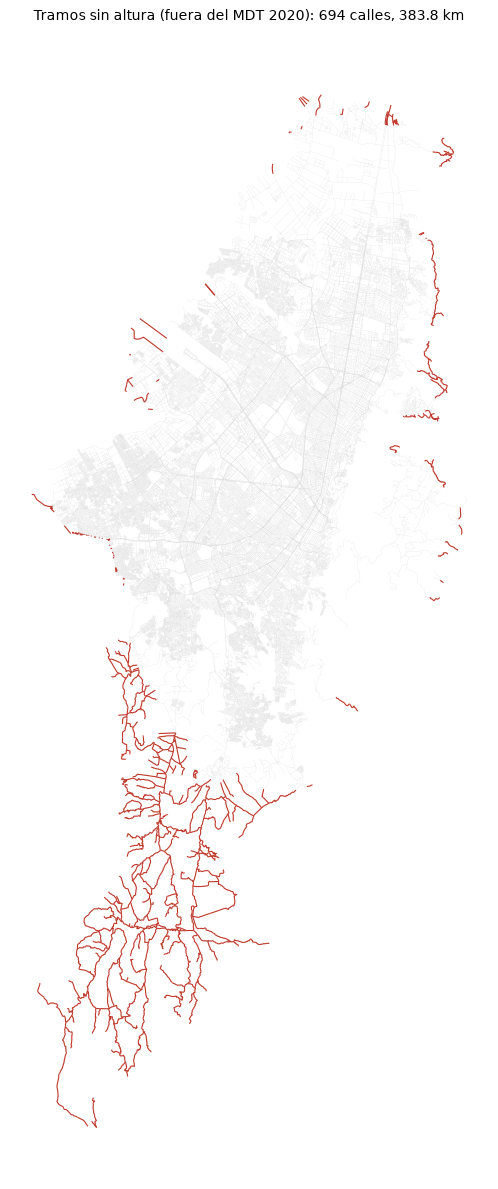

In [2]:
# =============================================================================
# CELDA 2: DIAGNOSTICO (no decide nada)
#   a) Tramos sin altura (fuera_cobertura_mdt): cuantos, donde, cuanto pesan,
#      cuantos ya caen fuera de la componente fuerte de D2.
#   b) Altura de cada esquina: que tanto difieren las alturas que le dan las
#      distintas calles que llegan a ella (clave para los pesos negativos).
#   c) Cuantos tramos sin altura tienen sus dos esquinas con altura conocida
#      (opcion "estimar con las alturas de las esquinas").
# =============================================================================
import matplotlib.pyplot as plt

DIAG = "D4/diagnosticos"
SIN = g["fuera_cobertura_mdt"]

# Segundo camino: sin cobertura <=> sin pendiente neta
assert (SIN == g["pendiente_neta_pct"].isna()).all(), \
    "fuera_cobertura_mdt y pendiente_neta_pct vacia no coinciden"

g["calle"] = g["id_eje"] + "_" + g["parte"]
fis = g.drop_duplicates("calle")                   # una fila por calle fisica
fis_sin = g[SIN].drop_duplicates("calle")

# --- a) Cuantos y cuanto pesan -----------------------------------------------
_km_tot = fis["longitud_m"].sum() / 1000
_km_sin = fis_sin["longitud_m"].sum() / 1000
print("TRAMOS SIN ALTURA")
print(f"  aristas dirigidas : {int(SIN.sum()):,} de {len(g):,} "
      f"({100*SIN.mean():.2f} %)")
print(f"  calles fisicas    : {len(fis_sin):,} de {len(fis):,}")
print(f"  km fisicos        : {_km_sin:,.1f} de {_km_tot:,.1f} "
      f"({100*_km_sin/_km_tot:.2f} %)")

# Segundo camino del km: largo de la geometria en vez de longitud_m
assert np.isclose(fis_sin.geometry.length.sum() / 1000, _km_sin)

print("\n  Contra la componente fuerte de D2 (aristas dirigidas):")
_ct = pd.crosstab(g["en_componente_fuerte"], SIN,
                  rownames=["en_componente_fuerte"], colnames=["sin_altura"])
print(_ct.to_string())
_sin_dentro = int((SIN & g["en_componente_fuerte"]).sum())
print(f"  -> sin altura DENTRO de la componente fuerte: {_sin_dentro:,}")

print("\n  Contra sentido supuesto (aristas dirigidas):")
print(pd.crosstab(g["sentido_supuesto"], SIN,
                  rownames=["sentido_supuesto"], colnames=["sin_altura"]).to_string())

# Por localidad (calles fisicas y km), con el % de la red de cada localidad
_loc = (fis.groupby("localidad")["longitud_m"].sum() / 1000).rename("km_total")
_loc_sin = fis_sin.groupby("localidad").agg(
    calles=("calle", "size"), km_sin_altura=("longitud_m", lambda s: s.sum()/1000))
POR_LOCALIDAD = _loc_sin.join(_loc, how="left")
POR_LOCALIDAD["pct_km_localidad"] = 100 * POR_LOCALIDAD["km_sin_altura"] / POR_LOCALIDAD["km_total"]
POR_LOCALIDAD = (POR_LOCALIDAD.sort_values("km_sin_altura", ascending=False)
                 .reset_index().round(3))
print("\n  Por localidad:")
print(POR_LOCALIDAD.to_string(index=False))

print("\n  Por tipo de via (calles fisicas):")
print(fis_sin["highway"].value_counts().to_string())

# --- b) Altura de cada esquina -----------------------------------------------
_con = g[~SIN]
_alt = pd.concat([
    pd.DataFrame({"nodo": _con["u_d4"], "z": _con["z_inicio_m"], "calle": _con["calle"]}),
    pd.DataFrame({"nodo": _con["v_d4"], "z": _con["z_fin_m"],    "calle": _con["calle"]}),
], ignore_index=True)
ALT_NODO = _alt.groupby("nodo").agg(n_calles=("calle", "nunique"),
                                   z_min=("z", "min"), z_max=("z", "max"),
                                   z_mediana=("z", "median"))
ALT_NODO["dispersion_m"] = ALT_NODO["z_max"] - ALT_NODO["z_min"]

_varias = ALT_NODO[ALT_NODO["n_calles"] >= 2]
_sz = K.SIGMA_Z_ADOPTADO_M
print("\nALTURA POR ESQUINA (esquinas donde llegan 2 o mas calles con dato)")
print(f"  esquinas con altura      : {len(ALT_NODO):,} de {N_NODOS_D4:,}")
print(f"  con 2 o mas calles       : {len(_varias):,}")
print("  dispersion (max - min) en metros, percentiles:")
print(_varias["dispersion_m"].quantile([.5, .9, .95, .99, 1]).round(3).to_string())
# Cortes solo DESCRIPTIVOS (no son umbrales de decision)
for _corte, _nom in [(0.0, "exactamente 0"), (0.5, "> 0,5 m"),
                     (_sz, f"> sigma_z ({_sz} m)"), (2*_sz, f"> 2 sigma_z")]:
    _n = (int((_varias["dispersion_m"] == 0).sum()) if _corte == 0
          else int((_varias["dispersion_m"] > _corte).sum()))
    print(f"    {_nom:<22}: {_n:,} ({100*_n/len(_varias):.1f} %)")

# --- c) Tramos sin altura: se podrian estimar con las esquinas? ---------------
_s = fis_sin[["calle", "segmento_id", "u_d4", "v_d4", "longitud_m",
              "localidad", "highway", "en_componente_fuerte",
              "sentido_supuesto"]].copy()
_s["z_u"] = _s["u_d4"].map(ALT_NODO["z_mediana"])
_s["z_v"] = _s["v_d4"].map(ALT_NODO["z_mediana"])
_s["esquinas_con_altura"] = _s["z_u"].notna().astype(int) + _s["z_v"].notna().astype(int)
_s["neta_estimada_pct"] = 100 * (_s["z_v"] - _s["z_u"]) / _s["longitud_m"]
print("\nTRAMOS SIN ALTURA segun esquinas con altura conocida (calles fisicas):")
print(_s["esquinas_con_altura"].value_counts().sort_index()
      .rename({0: "ninguna", 1: "una", 2: "las dos"}).to_string())
_est = _s.loc[_s["esquinas_con_altura"] == 2, "neta_estimada_pct"].abs()
if len(_est):
    print("  |pendiente estimada| en las que tienen las dos esquinas, percentiles (%):")
    print(_est.quantile([.5, .9, .99]).round(2).to_string())
    print(f"  de esas, con |estimada| > {K.UMBRAL_PENDIENTE_EXTREMA_PCT} %: "
          f"{int((_est > K.UMBRAL_PENDIENTE_EXTREMA_PCT).sum()):,}")
print("  (La estimacion es solo diagnostica: no entra al grafo.)")

# --- Salidas (sin sobrescribir) ----------------------------------------------
HASH_DIAG = {}
HASH_DIAG["D4_diag_sin_altura_por_localidad.csv"] = guardar_csv_sin_sobrescribir(
    POR_LOCALIDAD, K.ruta_entregable(DIAG, "D4_diag_sin_altura_por_localidad.csv"))
HASH_DIAG["D4_diag_sin_altura_tramos.csv"] = guardar_csv_sin_sobrescribir(
    _s.drop(columns=["u_d4", "v_d4"]).sort_values("calle").reset_index(drop=True),
    K.ruta_entregable(DIAG, "D4_diag_sin_altura_tramos.csv"))
HASH_DIAG["D4_diag_altura_por_esquina.csv"] = guardar_csv_sin_sobrescribir(
    ALT_NODO.reset_index().sort_values("nodo"),
    K.ruta_entregable(DIAG, "D4_diag_altura_por_esquina.csv"))
BITACORA["diagnosticos"] = HASH_DIAG

# --- Mapa (no se sobrescribe si ya existe) -----------------------------------
_fig = K.ruta_entregable(DIAG, "D4_diag_tramos_sin_altura.png")
fig, ax = plt.subplots(figsize=(9, 12))
fis.plot(ax=ax, color="#DDDDDD", linewidth=0.15)
fis_sin.plot(ax=ax, color="#C0392B", linewidth=0.8)
ax.set_title(f"Tramos sin altura (fuera del MDT 2020): {len(fis_sin):,} calles, "
             f"{_km_sin:,.1f} km", fontsize=10)
ax.set_axis_off(); plt.tight_layout()
if _fig.exists():
    print(f"  [figura ya existe, no se reescribe] {_fig.name}")
else:
    plt.savefig(_fig, dpi=150, bbox_inches="tight")
    print(f"  [figura escrita] {_fig.name}")
plt.show()

In [3]:
# =============================================================================
# CELDA 2b: DIAGNOSTICO (no decide nada)
#   a) Recalcular la componente fuerte en condiciones de D2 -> debe coincidir
#      exactamente con en_componente_fuerte (prueba que puede fallar).
#   b) Simular la exclusion de los tramos sin altura: cuantas aristas CON
#      altura quedarian fuera de la red de ida y vuelta (costo colateral).
#   c) Listas para revisar: arteriales sin altura y esquinas incoherentes.
# =============================================================================
import networkx as nx

def componente_mayor(df):
    """Marca las aristas cuyas dos esquinas estan en la componente fuerte mas
    grande del grafo dirigido formado por df. Devuelve (mascara, n_esquinas)."""
    G = nx.DiGraph()
    G.add_edges_from(zip(df["u"], df["v"]))
    S = max(nx.strongly_connected_components(G), key=len)
    return (df["u"].isin(S) & df["v"].isin(S)), len(S)

# --- a) Reproducir D2 ---------------------------------------------------------
_comp_d2cond, _n_nod = componente_mayor(g)
_dif = int((_comp_d2cond != g["en_componente_fuerte"]).sum())
print("COMPONENTE FUERTE recalculada en condiciones de D2 "
      "(sin bloquear nada, con SD/N):")
print(f"  aristas dentro : {int(_comp_d2cond.sum()):,} "
      f"({100*_comp_d2cond.mean():.1f} %)   esquinas: {_n_nod:,} "
      f"({100*_n_nod/N_NODOS_D4:.1f} %)")
print(f"  aristas que no coinciden con la marca de D2: {_dif}")
assert _dif == 0, "La componente recalculada NO coincide con la de D2"
BITACORA["prueba_componente_d2"] = {"aristas_dentro": int(_comp_d2cond.sum()),
                                    "esquinas_dentro": _n_nod, "diferencias": _dif}

# --- b) Simular la exclusion de los tramos sin altura -------------------------
_sub = g[~SIN]
_comp_sin, _n_nod_sin = componente_mayor(_sub)
_colateral = _sub[_sub["en_componente_fuerte"] & ~_comp_sin]
_col_fis = _colateral.drop_duplicates("calle")
print("\nSI SE EXCLUYEN los tramos sin altura (solo simulacion):")
print(f"  aristas con altura que seguirian en la red : {int(_comp_sin.sum()):,}")
print(f"  aristas CON altura que quedarian aisladas  : {len(_colateral):,} "
      f"({len(_col_fis):,} calles, "
      f"{_col_fis['longitud_m'].sum()/1000:,.1f} km)")
print(f"  esquinas en la red: {_n_nod:,} -> {_n_nod_sin:,} "
      f"(pierde {_n_nod - _n_nod_sin:,})")
if len(_col_fis):
    print("\n  Colateral por localidad (calles fisicas, km):")
    print(_col_fis.groupby("localidad")["longitud_m"]
          .agg(calles="size", km=lambda s: round(s.sum()/1000, 2))
          .sort_values("km", ascending=False).to_string())
    print("\n  Colateral por tipo de via (calles fisicas):")
    print(_col_fis["highway"].value_counts().to_string())

# Segundo camino: la componente fuerte calculada con OTRA libreria (scipy)
# tiene que marcar exactamente las mismas aristas que networkx. (Antes aqui
# habia un "balance" que era una identidad contable: no podia fallar.)
from scipy.sparse import csr_matrix as _csr
from scipy.sparse.csgraph import connected_components as _cc

def componente_mayor_scipy(df):
    """Lo mismo que componente_mayor, pero con scipy (implementacion independiente)."""
    nod = pd.Index(sorted(set(df["u"]) | set(df["v"])))
    iu, iv = nod.get_indexer(df["u"]), nod.get_indexer(df["v"])
    M = _csr((np.ones(len(df)), (iu, iv)), shape=(len(nod), len(nod)))
    _, lab = _cc(M, directed=True, connection="strong")
    S = set(nod[lab == np.bincount(lab).argmax()])
    return (df["u"].isin(S) & df["v"].isin(S)), len(S)

_comp_sp, _n_sp = componente_mayor_scipy(_sub)
assert _n_sp == _n_nod_sin and (_comp_sp == _comp_sin).all(), \
    "networkx y scipy no dan la misma componente fuerte (sin los tramos sin altura)"
_comp_sp_d2, _ = componente_mayor_scipy(g)
assert (_comp_sp_d2 == g["en_componente_fuerte"]).all(), \
    "scipy no reproduce la componente fuerte de D2"
# Y nadie entra a la red al quitar aristas (imposible por construccion)
assert not (_comp_sin & ~_sub["en_componente_fuerte"]).any(), \
    "Aparecieron aristas nuevas en la red al quitar tramos: imposible"

# --- c) Listas para revisar -----------------------------------------------------
ART_SIN = (fis_sin[fis_sin["highway"] == "arterial"]
           [["calle", "name", "civ", "localidad", "longitud_m",
             "en_componente_fuerte"]]
           .sort_values(["localidad", "calle"]).reset_index(drop=True))
print(f"\nARTERIALES SIN ALTURA: {len(ART_SIN)} calles, "
      f"{ART_SIN['longitud_m'].sum()/1000:,.2f} km")
print(ART_SIN.head(20).to_string(index=False))

ESQ_RARAS = (ALT_NODO[ALT_NODO["dispersion_m"] > 0.5]
             .sort_values("dispersion_m", ascending=False).reset_index())
_ej = g[g["u"].isin(ESQ_RARAS["nodo"]) | g["v"].isin(ESQ_RARAS["nodo"])]
print(f"\nESQUINAS con alturas que difieren > 0,5 m: {len(ESQ_RARAS)}")
print(ESQ_RARAS.to_string(index=False))
print("  Calles que llegan a esas esquinas:")
print(_ej[["segmento_id", "name", "localidad", "highway", "u", "v",
           "z_inicio_m", "z_fin_m", "longitud_m"]].to_string(index=False))

# --- Salidas (sin sobrescribir) ----------------------------------------------
HASH_DIAG["D4_diag_sin_altura_colateral.csv"] = guardar_csv_sin_sobrescribir(
    _col_fis[["calle", "name", "localidad", "highway", "longitud_m"]]
    .sort_values("calle").reset_index(drop=True),
    K.ruta_entregable(DIAG, "D4_diag_sin_altura_colateral.csv"))
HASH_DIAG["D4_diag_sin_altura_arteriales.csv"] = guardar_csv_sin_sobrescribir(
    ART_SIN, K.ruta_entregable(DIAG, "D4_diag_sin_altura_arteriales.csv"))
HASH_DIAG["D4_diag_esquinas_incoherentes.csv"] = guardar_csv_sin_sobrescribir(
    ESQ_RARAS, K.ruta_entregable(DIAG, "D4_diag_esquinas_incoherentes.csv"))
BITACORA["diagnosticos"] = HASH_DIAG

COMPONENTE FUERTE recalculada en condiciones de D2 (sin bloquear nada, con SD/N):
  aristas dentro : 214,837 (95.2 %)   esquinas: 87,752 (92.6 %)
  aristas que no coinciden con la marca de D2: 0

SI SE EXCLUYEN los tramos sin altura (solo simulacion):
  aristas con altura que seguirian en la red : 213,136
  aristas CON altura que quedarian aisladas  : 483 (244 calles, 44.3 km)
  esquinas en la red: 87,752 -> 87,041 (pierde 711)

  Colateral por localidad (calles fisicas, km):
                calles     km
localidad                    
USME               229  40.45
SANTA FE             5   2.19
CIUDAD BOLIVAR       3   1.38
BOSA                 6   0.19
FONTIBON             1   0.07

  Colateral por tipo de via (calles fisicas):
highway
rural          207
local           17
sin_definir     11
intermedia       9

ARTERIALES SIN ALTURA: 7 calles, 2.30 km
   calle     name      civ      localidad  longitud_m  en_componente_fuerte
 70186_0   KR 77G  7009075           BOSA  131.029205       

In [4]:
# =============================================================================
# CELDA 2c: DIAGNOSTICO (no decide nada)
# Compara tres tratamientos de los tramos sin altura, con la misma medida:
#   A = todos se quedan con pendiente 0 (marcados)
#   B = todos se excluyen
#   E = se excluyen los rurales (highway == "rural"); los demas, pendiente 0
# Para cada uno: que se excluye, que queda con pendiente 0, y cuantas aristas
# CON altura quedan aisladas de la red de ida y vuelta (colateral).
# =============================================================================
RURAL = g["highway"] == "rural"
TRATAMIENTOS = {
    "A_todo_pendiente_0": SIN & False,          # no se excluye nada
    "B_excluir_todo":     SIN,
    "E_excluir_rurales":  SIN & RURAL,
}

def _km(df):
    return df.drop_duplicates("calle")["longitud_m"].sum() / 1000

filas, COLATERAL_E = [], None
for nombre, excluir in TRATAMIENTOS.items():
    sub = g[~excluir]
    comp, n_esq = componente_mayor(sub)
    cero = sub[sub["fuera_cobertura_mdt"] & comp]        # sin altura que se rutean con 0
    col = sub[sub["en_componente_fuerte"] & ~comp & ~sub["fuera_cobertura_mdt"]]
    # Balance por segundo camino: lo que estaba en la red en D2 termina en
    # exactamente una de estas cuatro situaciones
    # Segundo camino: la misma componente con scipy (funcion de la celda 2b).
    # Reemplaza un "balance" que era una identidad contable y no podia fallar.
    _comp_sp, _n_sp = componente_mayor_scipy(sub)
    assert _n_sp == n_esq and (_comp_sp == comp).all(), \
        f"{nombre}: networkx y scipy no dan la misma componente fuerte"
    assert not (comp & ~sub["en_componente_fuerte"]).any(), \
        f"{nombre}: entraron aristas nuevas a la red al quitar tramos"
    filas.append({
        "tratamiento": nombre,
        "aristas_excluidas": int(excluir.sum()),
        "km_excluidos": round(_km(g[excluir]), 1),
        "aristas_con_pendiente_0": len(cero),
        "km_con_pendiente_0": round(_km(cero), 1),
        "colateral_aristas_con_altura": len(col),
        "colateral_km": round(_km(col), 1),
        "colateral_arteriales": int(col.drop_duplicates("calle")["highway"]
                                    .eq("arterial").sum()),
        "aristas_en_red": int(comp.sum()),
        "esquinas_en_red": n_esq,
    })
    if nombre == "E_excluir_rurales":
        COLATERAL_E = col

COMPARA_SIN_ALTURA = pd.DataFrame(filas)
print(COMPARA_SIN_ALTURA.set_index("tratamiento").T.to_string())

# Chequeo: A debe reproducir exactamente la red de D2
_fila_a = COMPARA_SIN_ALTURA.set_index("tratamiento").loc["A_todo_pendiente_0"]
assert _fila_a["aristas_en_red"] == int(g["en_componente_fuerte"].sum())
assert _fila_a["colateral_aristas_con_altura"] == 0

# Detalle de E: donde queda la pendiente 0 y donde el colateral
_sub_e = g[~(SIN & RURAL)]
_cero_e = _sub_e[_sub_e["fuera_cobertura_mdt"]].drop_duplicates("calle")
print("\nE — sin altura NO rurales que quedarian con pendiente 0 (calles, km):")
print(_cero_e.groupby("highway")["longitud_m"]
      .agg(calles="size", km=lambda s: round(s.sum()/1000, 2)).to_string())
print("  longitud por calle, percentiles (m):")
print(_cero_e["longitud_m"].quantile([.5, .9, .99, 1]).round(1).to_string())
print("  por localidad (km):")
print((_cero_e.groupby("localidad")["longitud_m"].sum()/1000)
      .round(2).sort_values(ascending=False).to_string())
if COLATERAL_E is not None and len(COLATERAL_E):
    print("\nE — colateral por localidad y tipo (calles fisicas):")
    _c = COLATERAL_E.drop_duplicates("calle")
    print(pd.crosstab(_c["localidad"], _c["highway"]).to_string())

# --- Salidas (sin sobrescribir) ----------------------------------------------
HASH_DIAG["D4_diag_sin_altura_comparacion.csv"] = guardar_csv_sin_sobrescribir(
    COMPARA_SIN_ALTURA,
    K.ruta_entregable(DIAG, "D4_diag_sin_altura_comparacion.csv"))
HASH_DIAG["D4_diag_sin_altura_E_pendiente0.csv"] = guardar_csv_sin_sobrescribir(
    _cero_e[["calle", "name", "civ", "localidad", "highway", "longitud_m"]]
    .sort_values("calle").reset_index(drop=True),
    K.ruta_entregable(DIAG, "D4_diag_sin_altura_E_pendiente0.csv"))
BITACORA["diagnosticos"] = HASH_DIAG

tratamiento                   A_todo_pendiente_0  B_excluir_todo  E_excluir_rurales
aristas_excluidas                            0.0          1374.0             1200.0
km_excluidos                                 0.0           383.8              369.7
aristas_con_pendiente_0                   1218.0             0.0              142.0
km_con_pendiente_0                         338.9             0.0                8.1
colateral_aristas_con_altura                 0.0           483.0              470.0
colateral_km                                 0.0            44.3               44.0
colateral_arteriales                         0.0             0.0                0.0
aristas_en_red                          214837.0        213136.0           213291.0
esquinas_en_red                          87752.0         87041.0            87104.0

E — sin altura NO rurales que quedarian con pendiente 0 (calles, km):
             calles    km
highway                  
arterial          7  2.30
intermedia 

## Hallazgo: los tramos sin altura son casi todos rurales

Con el archivo final de pendientes, el MDT 2020 no cubre **1.374 aristas** (694
calles, 383,8 km; 0,61 % de las aristas y 4,41 % de los kilómetros). En la primera
versión del archivo eran 3.970: los 2.596 recuperados eran casi todos huecos urbanos
causados por un defecto en la consulta al MDT.

**Lo que queda es casi todo rural.** 601 de las 694 calles son vías rurales,
sobre todo en Usme (25 % de sus kilómetros no tiene altura) y Ciudad
Bolívar (17 %). Solo quedan 93 calles urbanas sin altura (local,
intermedia, arterial), muchas de ellas probablemente puentes.

**Comparación de tratamientos** (celda 2c):

| Tratamiento | Km excluidos | Km con pendiente 0 | Colateral (km) | Arteriales aisladas | Aristas en la red |
|---|---|---|---|---|---|
| A: no quitar ninguna | 0 | 338,9 | 0 | 0 | 214.837 |
| B: quitar todas | 383,8 | 0 | 44,3 | 0 | 213.136 |
| E: quitar las rurales | 369,7 | 8,1 | 44,0 | 0 | 213.291 |

"Colateral" son calles que **sí** tienen altura pero quedan aisladas al
quitar las que no la tienen: 44 km en barrios altos de Usme.

**Decisión: tratamiento A.** No se quita ninguna calle. La
pendiente de las calles sin altura **no** es 0 en el ruteo por energía: sale
de la altura estimada de sus dos esquinas (celda 8, validada en la 8b y la 8c).
"Pendiente 0" solo aparece en la tabla de cada escenario como marca de que
el tramo no tenía dato.

**Coherencia de alturas por esquina.** En el 99,7 % de las esquinas donde
llegan dos o más calles, todas dan exactamente la misma altura. Solo 3
difieren más de 0,5 m (máximo 2,39 m), y no causan problemas al rutear por
energía (celda 7b).

*Archivos: `D4_diag_sin_altura_comparacion.csv`,
`D4_diag_sin_altura_colateral.csv`, `D4_diag_sin_altura_arteriales.csv`,
`D4_diag_sin_altura_E_pendiente0.csv`.*

## Estaciones de carga: insumos (celdas 3a y 3b)

Estas dos celdas preparan las estaciones; no deciden nada.

- **3a** localiza los archivos del inventario (bloques A y B), comprueba sus
  huellas contra las registradas y muestra columnas y conteos.
- **3b** une las coordenadas de OSM y OCM de cada estación, mide la distancia
  entre las dos fuentes y busca la esquina más cercana de la red con cada una.

La regla con la que se ubica y engancha cada estación está explicada después de
la celda 14.

In [5]:
# =============================================================================
# CELDA 3a: RECONOCIMIENTO de los insumos de estaciones (no decide nada,
# no escribe nada). Localiza por nombre, verifica sha256 contra lo registrado
# por B3, y muestra columnas y conteos para escribir la union en la celda 3b.
# =============================================================================
def localizar(nombre, sha_esperado=None):
    """Busca 'nombre' bajo las carpetas de los bloques A y B. Si se da el hash,
    devuelve solo una copia con ese hash (la primera en orden alfabetico)."""
    hallados = []
    for base in K.CARPETAS_BLOQUES_AB:
        assert base.exists(), (f"No existe {base}. Revise CARPETAS_BLOQUES_AB en "
                               "constantes_d1.py (se asume carpeta hermana).")
        hallados += list(base.rglob(nombre))
    hallados = sorted(hallados, key=str)
    assert hallados, f"No se encontro {nombre} bajo {K.CARPETAS_BLOQUES_AB}"
    if sha_esperado is None:
        assert len(hallados) == 1, f"{nombre}: {len(hallados)} copias y sin hash para elegir"
        return hallados[0], hallados
    buenos = [p for p in hallados if sha256_archivo(p) == sha_esperado]
    assert buenos, (f"{nombre}: {len(hallados)} copia(s) en disco y NINGUNA con el "
                    f"hash registrado {sha_esperado[:12]}...")
    return buenos[0], hallados

# --- 1. El manifiesto de B3 en disco dice lo mismo que constantes_d1 ----------
RUTA_MAN_B3, _ = localizar(K.MANIFIESTO_REFERENCIA_ESTACIONES)
_man_b3 = json.loads(RUTA_MAN_B3.read_text(encoding="utf-8"))
for _n, _h in K.INSUMOS_ESTACIONES_D4.items():
    assert _man_b3.get(_n) == _h, f"{_n}: constantes_d1 y el manifiesto de B3 no coinciden"
print(f"Manifiesto de referencia: {RUTA_MAN_B3.relative_to(K.RUTA_TESIS)}")

# --- 2. Localizar y verificar los tres insumos --------------------------------
RUTAS_EST = {}
for _n, _h in K.INSUMOS_ESTACIONES_D4.items():
    _r, _todas = localizar(_n, _h)
    RUTAS_EST[_n] = _r
    print(f"  [hash OK] {_n}\n            {_r}"
          + (f"\n            ({len(_todas)} copias en disco; se usa la de hash correcto)"
             if len(_todas) > 1 else ""))
BITACORA["insumos_estaciones"] = {n: {"sha256": h, "ruta": str(RUTAS_EST[n].relative_to(K.RUTA_TESIS))}
                                  for n, h in K.INSUMOS_ESTACIONES_D4.items()}
BITACORA["insumos_estaciones"]["manifiesto_referencia"] = str(RUTA_MAN_B3.relative_to(K.RUTA_TESIS))

# --- 3. Inventario B2.1 (BOM en la primera columna -> utf-8-sig) --------------
INV = pd.read_csv(RUTAS_EST["B2_1_clasificacion_verificada.csv"],
                  encoding="utf-8-sig",
                  dtype={"ocm_id": "string", "osm_uid": "string"})
print(f"\nINVENTARIO B2.1: {len(INV)} registros")
print("  columnas:", list(INV.columns))
print(INV["ciudad"].value_counts().to_string())
print(INV.groupby(["ciudad", "categoria"]).size().to_string())

# Segundo camino: estaciones fisicas de Bogota = lo que registro la auditoria
# de B2.1 (registros sin contar los C5, que repiten el ocm_id de su par)
RUTA_AUD_B21, _ = localizar("B2_1_auditoria_procesamiento.json")
_aud = json.loads(RUTA_AUD_B21.read_text(encoding="utf-8"))
_bog = INV[INV["ciudad"] == "Bogota"]
_fis_bog = _bog[~_bog["categoria"].str.startswith("C5")]
print(f"\n  Bogota: {len(_bog)} registros, {len(_fis_bog)} estaciones fisicas "
      f"(auditoria B2.1: {_aud['conteos']['estaciones_fisicas_por_ciudad']['Bogota']})")
assert len(_fis_bog) == _aud["conteos"]["estaciones_fisicas_por_ciudad"]["Bogota"], \
    "Conteo de estaciones fisicas de Bogota no coincide con la auditoria de B2.1"

# --- 4. Fuentes de coordenadas: solo mostrar ----------------------------------
OSM_BOG = gpd.read_file(RUTAS_EST["A2_estaciones_OSM_Bogota.geojson"])
print(f"\nA2 OSM Bogota: {len(OSM_BOG)} filas, CRS {OSM_BOG.crs}")
print("  columnas:", list(OSM_BOG.columns))
print(OSM_BOG.drop(columns="geometry").head(3).to_string())

OCM_BOG = pd.read_csv(RUTAS_EST["A3_OpenChargeMap_Bogota_estaciones.csv"],
                      encoding="utf-8-sig", dtype=str)
print(f"\nA3 OCM Bogota: {len(OCM_BOG)} filas")
print("  columnas:", list(OCM_BOG.columns))
print(OCM_BOG.head(3).to_string())

Manifiesto de referencia: Bloque B\Entregable B3\B3_manifiesto_insumos.json
  [hash OK] B2_1_clasificacion_verificada.csv
            F:\Tesis\Bloque B\Entregable B2.1\B2_1_clasificacion_verificada.csv
  [hash OK] A2_estaciones_OSM_Bogota.geojson
            F:\Tesis\Bloque A\Entregable A2\A2_estaciones_OSM_Bogota.geojson
  [hash OK] A3_OpenChargeMap_Bogota_estaciones.csv
            F:\Tesis\Bloque A\Entregable A3\A3_OpenChargeMap_Bogota_estaciones.csv
  [hash OK] B1_fusiones_internas.csv
            F:\Tesis\Bloque B\Entregable B1\B1_fusiones_internas.csv

INVENTARIO B2.1: 74 registros
  columnas: ['ciudad', 'categoria', 'origen', 'ocm_id', 'osm_uid', 'nombre_ocm', 'nombre_osm', 'distancia_m', 'similitud_nombre', 'similitud_operador', 'caso', 'categoria_previa', 'veredicto', 'verificacion_externa', 'motivo_verificacion', 'liberado_de_par']
ciudad
Bogota      55
Medellin    19
ciudad    categoria                          
Bogota    C1 Coincidencia confirmada              4
          C

In [6]:
# =============================================================================
# CELDA 3b: ESTACIONES — union, distancias y enganche, PARA REVISAR (no decide)
#   - Coordenadas de OCM (A3) y OSM (A2) por registro del inventario B2.1.
#   - Distancia OSM-OCM, comparada contra distancia_m de B1 (segundo camino).
#   - Esquina mas cercana en TODA la red y en la red BASE (opcion E, con SD/N,
#     sin bloquear >35 %), con cada coordenada. Verificado por fuerza bruta.
# =============================================================================
import folium

# --- 1. Fuentes, con identificadores como texto -------------------------------
OSM_T = OSM_BOG[["osm_uid", "nombre", "latitud", "longitud"]].copy()
OSM_T["osm_uid"] = OSM_T["osm_uid"].astype("string")
OSM_T[["latitud", "longitud"]] = OSM_T[["latitud", "longitud"]].astype(float)
OCM_T = OCM_BOG[["ocm_id", "nombre", "latitud", "longitud"]].copy()
OCM_T["ocm_id"] = OCM_T["ocm_id"].astype("string")
OCM_T[["latitud", "longitud"]] = OCM_T[["latitud", "longitud"]].astype(float)
assert OSM_T["osm_uid"].is_unique and OCM_T["ocm_id"].is_unique

# Segundo camino en OSM: latitud/longitud = geometria del GeoJSON (atrapa un
# cruce de columnas lat/lon)
_p = gpd.GeoSeries(gpd.points_from_xy(OSM_T["longitud"], OSM_T["latitud"]),
                   crs="EPSG:4326").to_crs(K.CRS_METRICO)
_d = _p.distance(OSM_BOG.geometry.to_crs(K.CRS_METRICO).reset_index(drop=True))
assert (_d < 0.01).all(), f"latitud/longitud de A2 no cuadran con su geometria (max {_d.max():.3f} m)"

# --- 2. Inventario de Bogota y cruce con las fuentes --------------------------
E = INV[INV["ciudad"] == "Bogota"].copy()
E.index.name = "fila_inv"
E = E.reset_index()
E["es_secundario_C5"] = E["categoria"].str.startswith("C5")

_falta_ocm = set(E["ocm_id"].dropna()) - set(OCM_T["ocm_id"])
_falta_osm = set(E["osm_uid"].dropna()) - set(OSM_T["osm_uid"])
assert not _falta_ocm, f"ocm_id del inventario sin coordenada en A3: {_falta_ocm}"
assert not _falta_osm, f"osm_uid del inventario sin coordenada en A2: {_falta_osm}"

E = (E.merge(OCM_T.rename(columns={"nombre": "nombre_a3", "latitud": "lat_ocm",
                                   "longitud": "lon_ocm"}),
             on="ocm_id", how="left", validate="many_to_one")
       .merge(OSM_T.rename(columns={"nombre": "nombre_a2", "latitud": "lat_osm",
                                    "longitud": "lon_osm"}),
              on="osm_uid", how="left", validate="many_to_one"))
assert len(E) == 55 or len(E) == int((INV["ciudad"] == "Bogota").sum())

# Registros de las fuentes que NO aparecen en el inventario (se esperan los
# absorbidos por la deduplicacion interna de B1)
_osm_fuera = sorted(set(OSM_T["osm_uid"]) - set(E["osm_uid"].dropna()))
_ocm_fuera = sorted(set(OCM_T["ocm_id"]) - set(E["ocm_id"].dropna()))
print(f"OSM de A2 que no estan en el inventario: {len(_osm_fuera)} {_osm_fuera}")
print(f"OCM de A3 que no estan en el inventario: {len(_ocm_fuera)} {_ocm_fuera}")

# Prueba: los que faltan son EXACTAMENTE los absorbidos por la deduplicacion
# interna de B1 en Bogota (ni mas, ni menos)
FUS = pd.read_csv(RUTAS_EST["B1_fusiones_internas.csv"], encoding="utf-8-sig",
                  dtype=str)
print("\nFusiones internas de B1:")
print(FUS.to_string(index=False))
_fus_bog = FUS[FUS["ciudad"] == "Bogota"]
_abs_osm = sorted(_fus_bog.loc[_fus_bog["fuente"].str.upper() == "OSM", "id_absorbido"])
_abs_ocm = sorted(_fus_bog.loc[_fus_bog["fuente"].str.upper() == "OCM", "id_absorbido"])
assert _osm_fuera == _abs_osm, (f"OSM fuera del inventario {_osm_fuera} != "
                                f"absorbidos por B1 {_abs_osm}")
assert _ocm_fuera == _abs_ocm, (f"OCM fuera del inventario {_ocm_fuera} != "
                                f"absorbidos por B1 {_abs_ocm}")
print("  [OK] lo que falta del inventario es exactamente lo absorbido por B1")

# Segundo camino: el nombre del inventario = el de la fuente
_mal_nom_ocm = E[E["ocm_id"].notna() & (E["nombre_ocm"].fillna("") != E["nombre_a3"].fillna(""))]
_mal_nom_osm = E[E["osm_uid"].notna() & (E["nombre_osm"].fillna("") != E["nombre_a2"].fillna(""))]
print(f"Nombres del inventario distintos a la fuente: OCM {len(_mal_nom_ocm)}, "
      f"OSM {len(_mal_nom_osm)}  (si no es 0, mirar antes de seguir)")

# --- 3. Coordenadas en EPSG:9377 y distancia entre fuentes --------------------
for f in ("ocm", "osm"):
    _m = E[f"lat_{f}"].notna()
    _pt = gpd.GeoSeries(gpd.points_from_xy(E.loc[_m, f"lon_{f}"], E.loc[_m, f"lat_{f}"]),
                        index=E.index[_m], crs="EPSG:4326").to_crs(K.CRS_METRICO)
    E.loc[_m, f"x_{f}"] = _pt.x
    E.loc[_m, f"y_{f}"] = _pt.y
_ambas = E["x_ocm"].notna() & E["x_osm"].notna()
E["dist_osm_ocm_m"] = np.hypot(E["x_ocm"] - E["x_osm"], E["y_ocm"] - E["y_osm"])

# Segundo camino: contra la distancia que calculo B1 (distancia_m)
_cmp = E.loc[_ambas & E["distancia_m"].notna(), ["dist_osm_ocm_m", "distancia_m"]]
_dif = (_cmp["dist_osm_ocm_m"] - _cmp["distancia_m"]).abs()
print(f"\nDistancia OSM-OCM recalculada vs B1 ({len(_cmp)} registros): "
      f"diferencia maxima {_dif.max():.3f} m")

# --- 4. Esquinas: todas y las de la red base (E, con SD/N) --------------------
NODOS = (pd.DataFrame({
            "nodo": np.concatenate([g["u"].to_numpy(), g["v"].to_numpy()]),
            "x": np.concatenate([shapely.get_x(shapely.get_point(_geoms, 0)),
                                 shapely.get_x(shapely.get_point(_geoms, -1))]),
            "y": np.concatenate([shapely.get_y(shapely.get_point(_geoms, 0)),
                                 shapely.get_y(shapely.get_point(_geoms, -1))])})
         .drop_duplicates("nodo").sort_values("nodo").reset_index(drop=True))
assert len(NODOS) == N_NODOS_D4

_sub_base = g[~(SIN & RURAL)]
_m_base, _ = componente_mayor(_sub_base)
NODOS_BASE = set(_sub_base.loc[_m_base, "u"]) | set(_sub_base.loc[_m_base, "v"])
_esperado = int(COMPARA_SIN_ALTURA.set_index("tratamiento")
                .loc["E_excluir_rurales", "esquinas_en_red"])
assert len(NODOS_BASE) == _esperado, "La red base no coincide con la medida en 2c"

def enganchar(x, y, nodos):
    """Esquina mas cercana por fuerza bruta (distancia euclidiana en 9377).
    Empates: la de id menor (nodos viene ordenado por id)."""
    nx_, ny_ = nodos["x"].to_numpy(), nodos["y"].to_numpy()
    ids, dists = [], []
    for xi, yi in zip(x, y):
        d = np.hypot(nx_ - xi, ny_ - yi)
        k = int(np.argmin(d))
        ids.append(nodos["nodo"].iat[k]); dists.append(float(d[k]))
    return ids, dists

_NB = NODOS[NODOS["nodo"].isin(NODOS_BASE)].reset_index(drop=True)
_gnod = gpd.GeoDataFrame(NODOS, geometry=gpd.points_from_xy(NODOS["x"], NODOS["y"]),
                         crs=K.CRS_METRICO)
for f in ("ocm", "osm"):
    _m = E[f"x_{f}"].notna()
    for nombre_red, tabla in (("red", NODOS), ("base", _NB)):
        ids, dists = enganchar(E.loc[_m, f"x_{f}"], E.loc[_m, f"y_{f}"], tabla)
        E.loc[_m, f"nodo_{f}_{nombre_red}"] = ids
        E.loc[_m, f"enganche_{f}_{nombre_red}_m"] = dists
    # Segundo camino: sjoin_nearest de geopandas sobre toda la red da la misma
    # distancia que la fuerza bruta
    _pts = gpd.GeoDataFrame(E.loc[_m, []], geometry=gpd.points_from_xy(
        E.loc[_m, f"x_{f}"], E.loc[_m, f"y_{f}"]), crs=K.CRS_METRICO)
    _sj = gpd.sjoin_nearest(_pts, _gnod[["geometry"]], distance_col="d")
    _sj = _sj[~_sj.index.duplicated()]
    assert np.allclose(_sj["d"].sort_index(),
                       E.loc[_m, f"enganche_{f}_red_m"].sort_index()), \
        f"{f}: fuerza bruta y sjoin_nearest no dan la misma distancia"

# --- 5. Resumen para revisar --------------------------------------------------
CORTE_DESCRIPTIVO_M = 100.0   # escala de manzana medida en B2 (solo marca)
E["misma_esquina_ocm_osm_base"] = np.where(
    _ambas, E["nodo_ocm_base"] == E["nodo_osm_base"], pd.NA)
for f in ("ocm", "osm"):
    E[f"lejos_{f}_base"] = E[f"enganche_{f}_base_m"] > CORTE_DESCRIPTIVO_M
    E[f"base_mas_lejos_que_red_{f}"] = (E[f"enganche_{f}_base_m"]
                                        - E[f"enganche_{f}_red_m"]) > 1.0

print("\nDISTANCIA DE ENGANCHE a la red base (m), por fuente:")
for f in ("ocm", "osm"):
    _s = E.loc[E[f"x_{f}"].notna(), f"enganche_{f}_base_m"]
    print(f"  {f.upper()}: n={len(_s)}  mediana {_s.median():.1f}  "
          f"p90 {_s.quantile(.9):.1f}  max {_s.max():.1f}  "
          f"> {CORTE_DESCRIPTIVO_M:.0f} m: {int((_s > CORTE_DESCRIPTIVO_M).sum())}  "
          f"(su esquina mas cercana estaba fuera de la red base: "
          f"{int(E[f'base_mas_lejos_que_red_{f}'].sum())})")
print(f"\nRegistros con las dos coordenadas: {int(_ambas.sum())}; "
      f"caen en la misma esquina de la red base: "
      f"{int(E.loc[_ambas, 'misma_esquina_ocm_osm_base'].sum())}")
print("\nPor categoria (mediana del enganche en la red base, m):")
print(E.groupby("categoria")[["enganche_ocm_base_m", "enganche_osm_base_m",
                              "dist_osm_ocm_m"]].median().round(1).to_string())

COLS_REV = ["fila_inv", "categoria", "es_secundario_C5", "origen", "ocm_id", "osm_uid",
            "nombre_ocm", "nombre_osm", "verificacion_externa", "liberado_de_par",
            "distancia_m", "dist_osm_ocm_m",
            "lat_ocm", "lon_ocm", "nodo_ocm_red", "enganche_ocm_red_m",
            "nodo_ocm_base", "enganche_ocm_base_m",
            "lat_osm", "lon_osm", "nodo_osm_red", "enganche_osm_red_m",
            "nodo_osm_base", "enganche_osm_base_m",
            "misma_esquina_ocm_osm_base", "lejos_ocm_base", "lejos_osm_base"]
REVISION_EST = E[COLS_REV].sort_values("fila_inv").reset_index(drop=True)
print("\nRegistros a mirar primero (enganche > corte, o esquina OCM != OSM):")
_mirar = REVISION_EST[(REVISION_EST["lejos_ocm_base"] | REVISION_EST["lejos_osm_base"]
                       | (REVISION_EST["misma_esquina_ocm_osm_base"] == False))]
print(_mirar[["fila_inv", "categoria", "nombre_ocm", "nombre_osm", "dist_osm_ocm_m",
              "enganche_ocm_base_m", "enganche_osm_base_m"]].round(1).to_string(index=False))

# --- 6. Salidas (sin sobrescribir) --------------------------------------------
HASH_DIAG["D4_diag_estaciones_revision.csv"] = guardar_csv_sin_sobrescribir(
    REVISION_EST, K.ruta_entregable(DIAG, "D4_diag_estaciones_revision.csv"))
BITACORA["diagnosticos"] = HASH_DIAG

# Mapa para revision punto por punto. Es solo para mirar (no tiene hash ni lo
# lee otro cuaderno), asi que se reescribe en cada corrida.
# Fondos: satelite y CartoDB (OSM bloquea sus teselas desde archivos locales).
_html = K.ruta_entregable(DIAG, "D4_diag_estaciones_mapa.html")
mapa = folium.Map(location=[4.65, -74.09], zoom_start=12, tiles=None)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri", name="Satelite", max_zoom=20).add_to(mapa)
folium.TileLayer("cartodbpositron", name="Calles (claro)").add_to(mapa)

_NB_ll = gpd.GeoSeries(gpd.points_from_xy(_NB["x"], _NB["y"]),
                       crs=K.CRS_METRICO).to_crs("EPSG:4326")
_pos_nodo = dict(zip(_NB["nodo"], zip(_NB_ll.y, _NB_ll.x)))
estilo = {"ocm": {"color": "#FF00FF", "nombre": "OCM (magenta)"},
          "osm": {"color": "#FFFF00", "nombre": "OSM (amarillo)"}}
capas = {f: folium.FeatureGroup(name=estilo[f]["nombre"]).add_to(mapa)
         for f in ("ocm", "osm")}
capa_esq = folium.FeatureGroup(name="Esquina enganchada (blanco)").add_to(mapa)

for _, r in E.iterrows():
    for f in ("ocm", "osm"):
        if pd.isna(r[f"lat_{f}"]):
            continue
        col = estilo[f]["color"]
        punto = [r[f"lat_{f}"], r[f"lon_{f}"]]
        esquina = list(_pos_nodo[r[f"nodo_{f}_base"]])
        txt = (f"<b>fila {r['fila_inv']}</b> | {r['categoria']}<br>"
               f"OCM: {r['nombre_ocm']}<br>OSM: {r['nombre_osm']}<br>"
               f"enganche {f.upper()}: {r[f'enganche_{f}_base_m']:.1f} m")
        folium.PolyLine([punto, esquina], color=col, weight=5,
                        opacity=1.0, dash_array="8").add_to(capas[f])
        folium.CircleMarker(punto, radius=10, color="black", weight=2,
                            fill=True, fill_color=col, fill_opacity=1.0,
                            popup=folium.Popup(txt, max_width=300),
                            tooltip=folium.Tooltip(
                                f"{r['fila_inv']}", permanent=True,
                                direction="right",
                                style="font-size:14px;font-weight:bold;")
                            ).add_to(capas[f])
        folium.CircleMarker(esquina, radius=5, color="black", weight=1,
                            fill=True, fill_color="white",
                            fill_opacity=1.0).add_to(capa_esq)
folium.LayerControl(collapsed=False).add_to(mapa)
mapa.save(str(_html))
print(f"  [mapa reescrito] {_html.name}")

OSM de A2 que no estan en el inventario: 1 ['way/24587409']
OCM de A3 que no estan en el inventario: 0 []

Fusiones internas de B1:
fuente   ciudad    id_conservado id_absorbido                   nombre_conservado                 nombre_absorbido miembros_del_grupo distancia_m
   OCM Medellin           485434       485435        Centro Comercial Los Molinos Centro Comercial Los Molinos EPM                  2        21.7
   OSM   Bogota node/13015491671 way/24587409 Punto de carga Compensar Avenida 68                        Compensar                  2         6.9
  [OK] lo que falta del inventario es exactamente lo absorbido por B1
Nombres del inventario distintos a la fuente: OCM 0, OSM 0  (si no es 0, mirar antes de seguir)

Distancia OSM-OCM recalculada vs B1 (16 registros): diferencia maxima 0.050 m

DISTANCIA DE ENGANCHE a la red base (m), por fuente:
  OCM: n=30  mediana 65.9  p90 95.3  max 165.8  > 100 m: 3  (su esquina mas cercana estaba fuera de la red base: 2)
  OSM: n=41  me

c:\Users\junio\miniconda3\envs\Tesis\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


  [mapa reescrito] D4_diag_estaciones_mapa.html


## Escenarios de red (celda 4)

Se arman cinco versiones de la red. Todas parten del grafo de D2 con las
pendientes de D3; cambian en qué calles se quitan antes de rutear.

| Escenario | Qué cambia | Papel |
|---|---|---|
| `sens_sin_altura_A` | No se quita ninguna calle (tratamiento A) | **Red oficial** |
| `base` | Se quitan las calles rurales sin altura (tratamiento E) | Referencia |
| `sens_bloquear_extremas` | Además se quitan los tramos de más de 35 % | Sensibilidad |
| `sens_sin_SDN` | Se quitan las calles de sentido supuesto (SD/N) | Sensibilidad |
| `sens_bloquear_y_sin_SDN` | Las dos cosas anteriores | Sensibilidad |

En cada escenario se vuelve a calcular la parte de la red en la que se puede ir
y volver entre cualquier par de esquinas (componente fuerte); lo que queda
fuera no se usa. La celda no usa estaciones ni el modelo de consumo.

In [7]:
# =============================================================================
# CELDA 4: CONSTRUCCION DE LOS ESCENARIOS DE RED
# Para cada escenario de constantes_d1.ESCENARIOS_D4:
#   1) excluir (extremas / sin altura rural / SD/N segun el escenario)
#   2) recalcular la componente fuerte sobre lo que queda
#   3) armar pendiente y subida/bajada para rutear
#   4) pruebas (pueden fallar) y salida en entregables/D4/esc_<nombre>/
# No usa estaciones ni formula de consumo.
# =============================================================================
def guardar_texto_sin_sobrescribir(texto, ruta):
    """Igual que guardar_csv_sin_sobrescribir, para JSON u otro texto."""
    contenido = texto.encode("utf-8")
    nuevo = hashlib.sha256(contenido).hexdigest()
    if ruta.exists():
        viejo = sha256_archivo(ruta)
        if viejo == nuevo:
            print(f"  [ya existe, identico] {ruta.name}")
            return nuevo
        raise FileExistsError(f"{ruta.name} ya existe con OTRO contenido. No se reescribe.")
    ruta.write_bytes(contenido)
    print(f"  [escrito] {ruta.name}  sha {nuevo[:12]}...")
    return nuevo

# Fuente INDEPENDIENTE para las pruebas: el CSV de D3 (no la tabla en memoria).
# Las banderas se leen como texto: con vacios, pandas se enreda si adivina el tipo.
_D3 = pd.read_csv(RUTA_CSV_D3,
                  dtype={"segmento_id": "string", "pendiente_extrema": "string",
                         "fuera_cobertura_mdt": "string", "sentido_supuesto": "string",
                         "highway": "string"},
                  usecols=["segmento_id", "pendiente_extrema", "fuera_cobertura_mdt",
                           "sentido_supuesto", "highway"],
                  low_memory=False).set_index("segmento_id")
for _c in ["pendiente_extrema", "fuera_cobertura_mdt", "sentido_supuesto"]:
    _D3[_c] = _a_bool(_D3[_c])

_col, _val = K.CRITERIO_RURAL_SIN_ALTURA
EXTREMA = g["pendiente_extrema"].fillna(False).astype(bool)   # sin dato no es extrema
SDN = g["sentido_supuesto"]
RURAL_SIN = SIN & (g[_col] == _val)
_dz = g["z_fin_m"] - g["z_inicio_m"]
_ninguna = pd.Series(False, index=g.index)

RESUMEN_ESC = []
for nombre, cfg in K.ESCENARIOS_D4.items():
    print(f"\n=== {nombre}: {cfg['descripcion']} ===")
    m_ext = EXTREMA if cfg["bloquear_extremas"] else _ninguna
    m_sin = RURAL_SIN if cfg["tratamiento_sin_altura"] == "E" else _ninguna
    assert cfg["tratamiento_sin_altura"] in ("E", "A")
    m_sdn = _ninguna if cfg["incluir_sentido_supuesto"] else SDN
    excl = m_ext | m_sin | m_sdn

    # 2) componente fuerte sobre lo que queda
    sub = g[~excl]
    comp, n_esq = componente_mayor(sub)
    en_red = _ninguna.copy()
    en_red.loc[comp.index] = comp

    # 3) pendiente y subida/bajada para rutear
    asumida0 = SIN & ~excl
    pend = g["pendiente_neta_pct"].where(~asumida0, 0.0)
    dz = _dz.where(~asumida0, 0.0)
    T = pd.DataFrame({
        "segmento_id": g["segmento_id"], "id_eje": g["id_eje"], "parte": g["parte"],
        "sentido_recorrido": g["sentido_recorrido"], "u": g["u"], "v": g["v"],
        "longitud_m": g["longitud_m"],
        "excluida": excl,
        "motivo_exclusion": (np.where(m_ext, "extrema", "")
                             + np.where(m_sin, "|sin_altura_rural", "")
                             + np.where(m_sdn, "|sentido_supuesto", "")),
        "en_red": en_red,
        "pendiente_ruteo_pct": pend,
        "pendiente_asumida_cero": asumida0,
        "subida_extremos_m": dz.clip(lower=0), "bajada_extremos_m": (-dz).clip(lower=0),
        "ganancia_acumulada_m": g["ganancia_elevacion_m"].where(~asumida0, 0.0),
        "perdida_acumulada_m": g["perdida_elevacion_m"].where(~asumida0, 0.0),
    })
    T["motivo_exclusion"] = T["motivo_exclusion"].str.lstrip("|")
    T = T.sort_values("segmento_id").reset_index(drop=True)
    R = T[T["en_red"]]

    # 4) PRUEBAS -------------------------------------------------------------
    pr_e = []
    # a) nada excluido esta en la red, y el conteo cuadra
    # Segundo camino: toda arista NO excluida cuyas dos esquinas estan en la
    # red tiene que estar marcada en_red (atrapa un desalineo de indices).
    _nod_red = set(T.loc[T["en_red"], "u"]) | set(T.loc[T["en_red"], "v"])
    _deberia = ~T["excluida"] & T["u"].isin(_nod_red) & T["v"].isin(_nod_red)
    pr_e.append({"prueba": "excluidas fuera de la red; en_red = esquinas de la red",
                 "pasa": not (T["excluida"] & T["en_red"]).any()
                         and bool((_deberia == T["en_red"]).all())})
    # b) la red es fuertemente conexa (se reconstruye desde la tabla escrita)
    Gr = nx.DiGraph(); Gr.add_edges_from(zip(R["u"], R["v"]))
    pr_e.append({"prueba": "red fuertemente conexa",
                 "pasa": nx.is_strongly_connected(Gr)
                         and Gr.number_of_nodes() == n_esq})
    # c) quitar aristas nunca agrega red: todo lo que esta, estaba en D2
    _ids_red = set(R["segmento_id"])
    _ids_d2 = set(g.loc[g["en_componente_fuerte"], "segmento_id"])
    pr_e.append({"prueba": "red del escenario contenida en la de D2",
                 "pasa": _ids_red <= _ids_d2})
    # d) contra el CSV de D3 (fuente independiente): lo que el escenario
    #    prohibe no aparece en la red
    _Dr = _D3.loc[list(_ids_red)]
    _viola = 0
    if cfg["bloquear_extremas"]:
        _viola += int((_Dr["pendiente_extrema"] == True).sum())
    if cfg["tratamiento_sin_altura"] == "E":
        _viola += int(((_Dr["fuera_cobertura_mdt"] == True)
                       & (_Dr[_col] == _val)).sum())
    if not cfg["incluir_sentido_supuesto"]:
        _viola += int((_Dr["sentido_supuesto"] == True).sum())
    pr_e.append({"prueba": "ninguna arista prohibida en la red (segun CSV de D3)",
                 "violaciones": _viola, "pasa": _viola == 0})
    # e) toda arista de la red tiene pendiente y subida/bajada
    pr_e.append({"prueba": "sin vacios en la red",
                 "pasa": not R[["pendiente_ruteo_pct", "subida_extremos_m",
                                "bajada_extremos_m", "ganancia_acumulada_m",
                                "perdida_acumulada_m"]].isna().any().any()})
    # f) pendiente = 100 * (subida - bajada) / longitud (segundo camino)
    _rec = 100 * (R["subida_extremos_m"] - R["bajada_extremos_m"]) / R["longitud_m"]
    pr_e.append({"prueba": "pendiente = (subida - bajada) / longitud",
                 "pasa": bool(np.allclose(_rec, R["pendiente_ruteo_pct"],
                                          rtol=1e-6, atol=1e-6))})
    # g) simetria FT/TF dentro de la red
    _ft = R[R["sentido_recorrido"] == "FT"].set_index(["id_eje", "parte"])
    _tf = R[R["sentido_recorrido"] == "TF"].set_index(["id_eje", "parte"])
    _pp = _ft.join(_tf, lsuffix="_ft", rsuffix="_tf", how="inner")
    pr_e.append({"prueba": "simetria FT/TF (pendiente, subida<->bajada)",
                 "n_pares": len(_pp),
                 "pasa": bool(np.allclose(_pp["pendiente_ruteo_pct_ft"],
                                          -_pp["pendiente_ruteo_pct_tf"], atol=1e-6)
                              and np.allclose(_pp["subida_extremos_m_ft"],
                                              _pp["bajada_extremos_m_tf"], atol=1e-6)
                              and np.allclose(_pp["ganancia_acumulada_m_ft"],
                                              _pp["perdida_acumulada_m_tf"], atol=1e-3))})
    # h) contra lo medido en los diagnosticos (segundo camino)
    _cond_d2 = (not cfg["bloquear_extremas"] and cfg["tratamiento_sin_altura"] == "A"
                and cfg["incluir_sentido_supuesto"])
    if _cond_d2:
        pr_e.append({"prueba": "condiciones de D2 -> red identica a la de D2",
                     "pasa": _ids_red == _ids_d2})
    if nombre == "base":
        _esp = COMPARA_SIN_ALTURA.set_index("tratamiento").loc["E_excluir_rurales"]
        pr_e.append({"prueba": "base = lo medido para E en la celda 2c",
                     "pasa": len(R) == int(_esp["aristas_en_red"])
                             and n_esq == int(_esp["esquinas_en_red"])})

    _df = pd.DataFrame(pr_e)
    _df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
    print(_df[["prueba", "resultado"]].to_string(index=False))
    assert _df["pasa"].all(), f"{nombre}: fallan {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

    # Salidas ---------------------------------------------------------------
    carpeta = f"D4/esc_{nombre}"
    _sha_tab = guardar_csv_sin_sobrescribir(
        T, K.ruta_entregable(carpeta, f"D4_aristas_{nombre}.csv"))
    _fis = T.drop_duplicates(["id_eje", "parte"])
    _fis_red = R.drop_duplicates(["id_eje", "parte"])
    resumen = {
        "escenario": nombre, "rol": cfg["rol"],
        "aristas_excluidas": int(T["excluida"].sum()),
        "aristas_en_red": len(R),
        "aristas_no_evaluables": int((~T["excluida"] & ~T["en_red"]).sum()),
        "esquinas_en_red": n_esq,
        "km_fisicos_en_red": round(_fis_red["longitud_m"].sum() / 1000, 1),
        "pct_km_en_red": round(100 * _fis_red["longitud_m"].sum()
                               / _fis["longitud_m"].sum(), 2),
        "aristas_pendiente_asumida_0_en_red": int(R["pendiente_asumida_cero"].sum()),
        "aristas_extremas_en_red": int(EXTREMA.loc[g["segmento_id"].isin(_ids_red)].sum()),
    }
    huellas = {"escenario": nombre, "configuracion": cfg,
               "archivos": {f"D4_aristas_{nombre}.csv": _sha_tab},
               "insumos": {"huella_gpkg_d3": HUELLA_D3, "sha256_csv_d3": SHA_CSV_D3,
                           "rama": RAMA},
               "resumen": resumen}
    guardar_texto_sin_sobrescribir(
        json.dumps(huellas, indent=2, ensure_ascii=False, sort_keys=True),
        K.ruta_entregable(carpeta, f"D4_huellas_{nombre}.json"))
    RESUMEN_ESC.append(resumen)
    BITACORA.setdefault("escenarios", {})[nombre] = {"pruebas": pr_e, "resumen": resumen,
                                                    "sha256_tabla": _sha_tab}
RESUMEN_ESC = pd.DataFrame(RESUMEN_ESC)
print("\nRESUMEN DE ESCENARIOS")
print(RESUMEN_ESC.set_index("escenario").T.to_string())
guardar_csv_sin_sobrescribir(RESUMEN_ESC,
                             K.ruta_entregable("D4", "D4_resumen_escenarios.csv"))


=== base: sin bloquear >35 %, sin altura E, con SD/N ===
                                                prueba resultado
excluidas fuera de la red; en_red = esquinas de la red      PASA
                                red fuertemente conexa      PASA
               red del escenario contenida en la de D2      PASA
  ninguna arista prohibida en la red (segun CSV de D3)      PASA
                                  sin vacios en la red      PASA
              pendiente = (subida - bajada) / longitud      PASA
           simetria FT/TF (pendiente, subida<->bajada)      PASA
                base = lo medido para E en la celda 2c      PASA
  [escrito] D4_aristas_base.csv  sha 3f405406699a...
  [escrito] D4_huellas_base.json  sha 149e293ad64a...

=== sens_bloquear_extremas: bloquea >35 % ===
                                                prueba resultado
excluidas fuera de la red; en_red = esquinas de la red      PASA
                                red fuertemente conexa      PASA
        

'82eb74edacd681c5ee95fac520db9d206f80c74053594777a28f2118fced58ce'

In [8]:
# =============================================================================
# CELDA 5: RUTEO POR DISTANCIA EN UNA MUESTRA FIJA DE PARES (todos los escenarios)
# Lee los escenarios desde disco (verificados contra sus huellas), sortea pares
# comunes a todos y calcula la ruta mas corta con Dijkstra (scipy).
# =============================================================================
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra

# --- 1. Escenarios desde disco, verificados -----------------------------------
ESC = {}
for nombre in K.ESCENARIOS_D4:
    _car = K.RUTA_ENTREGABLES / "D4" / f"esc_{nombre}"
    _hue = json.loads((_car / f"D4_huellas_{nombre}.json").read_text(encoding="utf-8"))
    _ruta = _car / f"D4_aristas_{nombre}.csv"
    assert sha256_archivo(_ruta) == _hue["archivos"][_ruta.name], f"{nombre}: tabla alterada"
    assert _hue["insumos"]["huella_gpkg_d3"] == HUELLA_D3, f"{nombre}: otro insumo D3"
    _t = pd.read_csv(_ruta, dtype={"segmento_id": "string", "u": "string", "v": "string",
                                   "id_eje": "string", "parte": "string",
                                   "motivo_exclusion": "string"})
    for _c in ["en_red", "excluida", "pendiente_asumida_cero"]:
        _t[_c] = _a_bool(_t[_c])
    ESC[nombre] = _t
print(f"Escenarios leidos y verificados: {list(ESC)}")

# --- 2. Pares origen-destino: MUESTRA ESTRATIFICADA -----
# Metodo, en palabras:
#   a) Se sortean pares al azar entre las esquinas que estan en la red de TODOS
#      los escenarios y tienen altura MEDIDA (no estimada), igual que antes.
#   b) Cada par cae en una casilla: terreno (plano / cruzado / ladera) x banda de
#      distancia en linea recta (<2, 2-5, 5-10, 10-20, >20 km).
#      Esquina en ladera = altura medida > mediana de las esquinas + MARGEN.
#      plano = ninguna de las dos en ladera; ladera = las dos; cruzado = una.
#   c) Cada casilla recibe los primeros N_PARES_POR_CASILLA pares que le caen, en
#      el orden del sorteo. Se sigue sorteando hasta llenar todas y hasta haber
#      sorteado al menos N_SORTEOS_MIN_PESOS pares.
#   d) Peso de cada par = (fraccion de TODOS los sorteos que cayo en su casilla) /
#      (pares de la muestra en su casilla). Suma 1. Sirve para dar cifras de toda
#      la ciudad: las casillas de ladera estan sobrerrepresentadas a proposito.
_TERRENOS = ("plano", "cruzado", "ladera")

def sortear_pares_estratificados(nodos, x, y, z, semilla, cupo, cortes_m,
                                 nombres_bandas, margen_m, n_min, ronda):
    """nodos/x/y/z: arrays alineados (esquinas elegibles). Devuelve (OD, CASILLAS, z_corte)."""
    N = len(nodos)
    z_corte = float(np.median(z)) + margen_m
    lad = z > z_corte
    rng = np.random.default_rng(semilla)
    nb = len(cortes_m) + 1
    n_cas = len(_TERRENOS) * nb
    conteo_sorteos = np.zeros(n_cas, dtype=np.int64)
    llenos = np.zeros(n_cas, dtype=np.int64)
    acept, vistos, total = [], set(), 0
    while (llenos < cupo).any() or total < n_min:
        io = rng.integers(0, N, ronda)
        idd = (io + rng.integers(1, N, ronda)) % N            # nunca origen = destino
        d = np.hypot(x[io] - x[idd], y[io] - y[idd])
        cas = (lad[io].astype(int) + lad[idd].astype(int)) * nb + np.digitize(d, cortes_m)
        conteo_sorteos += np.bincount(cas, minlength=n_cas)
        for k in np.flatnonzero(llenos[cas] < cupo):          # solo si su casilla tiene cupo
            c = cas[k]
            if llenos[c] >= cupo or (io[k], idd[k]) in vistos:
                continue
            vistos.add((io[k], idd[k])); llenos[c] += 1
            acept.append((total + k, io[k], idd[k], c, d[k]))
        total += ronda
    A = np.array(acept, dtype=float)
    o, de, c = A[:, 1].astype(int), A[:, 2].astype(int), A[:, 3].astype(int)
    OD = pd.DataFrame({"sorteo": A[:, 0].astype(np.int64),
                       "origen": nodos[o], "destino": nodos[de],
                       "recta_m": A[:, 4],
                       "terreno": [_TERRENOS[i // nb] for i in c],
                       "banda": [nombres_bandas[i % nb] for i in c],
                       "z_origen_m": z[o], "z_destino_m": z[de], "_c": c})
    frac = conteo_sorteos / total
    OD["peso"] = frac[OD["_c"]] / cupo
    OD = (OD.sort_values(["_c", "sorteo"]).drop(columns="_c").reset_index(drop=True))
    OD.insert(0, "par", np.arange(len(OD)))
    CAS = pd.DataFrame({"terreno": [_TERRENOS[i // nb] for i in range(n_cas)],
                        "banda": [nombres_bandas[i % nb] for i in range(n_cas)],
                        "sorteos_en_casilla": conteo_sorteos,
                        "fraccion_de_la_ciudad": frac,
                        "pares_en_muestra": np.bincount(c, minlength=n_cas)})
    CAS["peso_por_par"] = CAS["fraccion_de_la_ciudad"] / CAS["pares_en_muestra"]
    CAS.attrs.update(total_sorteos=int(total), z_corte_ladera_m=z_corte)
    return OD, CAS, z_corte

_sets = [set(t.loc[t["en_red"], "u"]) | set(t.loc[t["en_red"], "v"]) for t in ESC.values()]
COMUNES = sorted(set.intersection(*_sets))
print(f"Esquinas en la red de TODOS los escenarios: {len(COMUNES):,}")
_zmed = ALT_NODO["z_mediana"]
ELEGIBLES = np.array([n for n in COMUNES if n in _zmed.index], dtype=object)
print(f"  de ellas con altura MEDIDA (elegibles como origen/destino): {len(ELEGIBLES):,}")
_xy = NODOS.drop_duplicates("nodo").set_index("nodo")
_X = _xy.loc[ELEGIBLES, "x"].to_numpy(float); _Y = _xy.loc[ELEGIBLES, "y"].to_numpy(float)
_Z = _zmed.loc[ELEGIBLES].to_numpy(float)
_args = dict(semilla=K.SEMILLA_OD_ESTRAT_D4, cupo=K.N_PARES_POR_CASILLA_D4,
             cortes_m=K.CORTES_BANDA_OD_M, nombres_bandas=K.NOMBRES_BANDA_OD,
             margen_m=K.MARGEN_LADERA_M, n_min=K.N_SORTEOS_MIN_PESOS_OD,
             ronda=K.SORTEOS_POR_RONDA_OD)
OD, CASILLAS, Z_CORTE_LADERA = sortear_pares_estratificados(ELEGIBLES, _X, _Y, _Z, **_args)
print(f"Corte de ladera: {Z_CORTE_LADERA:,.1f} m (mediana {Z_CORTE_LADERA - K.MARGEN_LADERA_M:,.1f} "
      f"+ {K.MARGEN_LADERA_M:g} m); sorteos: {CASILLAS.attrs['total_sorteos']:,}")

# Pruebas de la muestra (todas pueden fallar)
_OD2, _, _ = sortear_pares_estratificados(ELEGIBLES, _X, _Y, _Z, **_args)
_lad = lambda s: _zmed.loc[s].to_numpy() > Z_CORTE_LADERA
_n_lad = _lad(OD["origen"]).astype(int) + _lad(OD["destino"]).astype(int)
_rec = np.hypot(_xy.loc[OD["origen"], "x"].to_numpy() - _xy.loc[OD["destino"], "x"].to_numpy(),
                _xy.loc[OD["origen"], "y"].to_numpy() - _xy.loc[OD["destino"], "y"].to_numpy())
_banda_ind = np.array(K.NOMBRES_BANDA_OD)[np.searchsorted(K.CORTES_BANDA_OD_M, _rec, side="right")]
pr_od = [
    ("misma semilla -> misma muestra (reproducible)", OD.equals(_OD2)),
    ("cada casilla tiene exactamente el cupo",
     bool((CASILLAS["pares_en_muestra"] == K.N_PARES_POR_CASILLA_D4).all())),
    ("origen distinto de destino", bool((OD["origen"] != OD["destino"]).all())),
    ("ningun par repetido", not OD.duplicated(["origen", "destino"]).any()),
    ("origen y destino en la red de todos los escenarios y con altura medida",
     bool(OD["origen"].isin(set(ELEGIBLES)).all() and OD["destino"].isin(set(ELEGIBLES)).all())),
    ("terreno recalculado por otro camino = el asignado",
     bool((np.array(_TERRENOS)[_n_lad] == OD["terreno"].to_numpy()).all())),
    ("banda recalculada por otro camino = la asignada",
     bool((_banda_ind == OD["banda"].to_numpy()).all() and np.allclose(_rec, OD["recta_m"]))),
    ("los pesos suman 1", bool(np.isclose(OD["peso"].sum(), 1.0))),
    ("casilla mas escasa con >= 1.000 sorteos (peso estable)",
     bool(CASILLAS["sorteos_en_casilla"].min() >= 1000)),
]
for _p, _ok in pr_od:
    print(f"  [{'PASA' if _ok else 'FALLA'}] {_p}")
assert all(ok for _, ok in pr_od), "Falla la muestra de pares"
print("\nCASILLAS (fraccion de la ciudad = parte de los pares al azar que cae en cada una)")
print(CASILLAS.pivot(index="terreno", columns="banda", values="fraccion_de_la_ciudad")
      .loc[list(_TERRENOS), list(K.NOMBRES_BANDA_OD)].mul(100).round(2).to_string())

guardar_csv_sin_sobrescribir(OD, K.ruta_entregable("D4/rutas_distancia", "D4_muestra_pares_od.csv"))
guardar_csv_sin_sobrescribir(CASILLAS, K.ruta_entregable("D4/rutas_distancia", "D4_muestra_casillas.csv"))
BITACORA["muestra_od"] = {
    "metodo": "estratificado: 3 terrenos x 5 bandas de distancia en linea recta, cupo fijo por "
              "casilla, sorteo uniforme de pares entre esquinas comunes con altura medida",
    "semilla": K.SEMILLA_OD_ESTRAT_D4, "cupo_por_casilla": K.N_PARES_POR_CASILLA_D4,
    "n_pares": len(OD), "cortes_banda_m": list(K.CORTES_BANDA_OD_M),
    "margen_ladera_m": K.MARGEN_LADERA_M, "z_corte_ladera_m": Z_CORTE_LADERA,
    "esquinas_comunes": len(COMUNES), "esquinas_elegibles": len(ELEGIBLES),
    "total_sorteos": CASILLAS.attrs["total_sorteos"],
    "casillas": CASILLAS.to_dict(orient="records"),
    "pruebas": {p: bool(ok) for p, ok in pr_od}}

# --- 3. Ruteo -------------------------------------------------------------------
def rutear_distancia(t, od, lote=200):
    r = t[t["en_red"]]
    # Un tramo por par de esquinas: el mas corto (empate: segmento_id menor).
    # csr_matrix SUMARIA los paralelos, por eso se deduplica antes.
    rr = (r.sort_values(["u", "v", "longitud_m", "segmento_id"])
            .drop_duplicates(["u", "v"]))
    assert (rr["longitud_m"] > 0).all(), "Hay tramos de longitud 0"
    nodos = pd.Index(sorted(set(rr["u"]) | set(rr["v"])))
    iu, iv = nodos.get_indexer(rr["u"]), nodos.get_indexer(rr["v"])
    M = csr_matrix((rr["longitud_m"].to_numpy(), (iu, iv)), shape=(len(nodos), len(nodos)))
    tramo = {(int(a), int(b)): s for a, b, s in zip(iu, iv, rr["segmento_id"])}
    io, idd = nodos.get_indexer(od["origen"]), nodos.get_indexer(od["destino"])
    assert (io >= 0).all() and (idd >= 0).all()
    dist = np.full(len(od), np.inf)
    rutas = [None] * len(od)
    for a in range(0, len(od), lote):
        src = io[a:a + lote]
        D, P = dijkstra(M, directed=True, indices=src, return_predecessors=True)
        for k in range(len(src)):
            j = int(idd[a + k]); dist[a + k] = D[k, j]
            if np.isfinite(D[k, j]):
                camino, x = [], j
                while x != int(src[k]):
                    p = int(P[k, x]); camino.append(tramo[(p, x)]); x = p
                rutas[a + k] = camino[::-1]
    return dist, rutas, len(r) - len(rr)

RUTAS = {}
_resumen = []
for nombre, t in ESC.items():
    cfg = K.ESCENARIOS_D4[nombre]
    dist, rutas, n_par = rutear_distancia(t, OD)
    ti = t.set_index("segmento_id")
    pr_r = []

    # a) todos los pares tienen ruta
    pr_r.append({"prueba": "todos los pares tienen ruta",
                 "sin_ruta": int((~np.isfinite(dist)).sum()),
                 "pasa": bool(np.isfinite(dist).all())})
    # b) continuidad de cada ruta
    _cont = all(len(rt) > 0 and ti.at[rt[0], "u"] == o and ti.at[rt[-1], "v"] == d
                and all(ti.at[rt[i], "v"] == ti.at[rt[i + 1], "u"] for i in range(len(rt) - 1))
                for rt, o, d in zip(rutas, OD["origen"], OD["destino"]))
    pr_r.append({"prueba": "rutas continuas de origen a destino", "pasa": bool(_cont)})
    # c) longitud recalculada desde la tabla en disco
    _suma = np.array([ti.loc[rt, "longitud_m"].sum() for rt in rutas])
    pr_r.append({"prueba": "suma de longitud_m = distancia de Dijkstra",
                 "pasa": bool(np.allclose(_suma, dist, rtol=1e-9, atol=1e-6))})
    # d) nunca mas corta que la linea recta (tolerancia: rejilla de 2 m por union)
    _n = np.array([len(rt) for rt in rutas])
    _tol = 2 * np.sqrt(2) * K.TOLERANCIA_NODO_M / 2 * (_n + 1)
    pr_r.append({"prueba": "ruta >= linea recta",
                 "violaciones": int((dist + _tol < OD["recta_m"]).sum()),
                 "pasa": bool((dist + _tol >= OD["recta_m"]).all())})
    # e) ningun tramo prohibido (tabla del escenario y CSV de D3)
    _usados = pd.Index(sorted({s for rt in rutas for s in rt}))
    _ok_red = bool(ti.loc[_usados, "en_red"].all() and not ti.loc[_usados, "excluida"].any())
    _D3u = _D3.loc[_usados]
    _viola = 0
    if cfg["bloquear_extremas"]:
        _viola += int((_D3u["pendiente_extrema"] == True).sum())
    if cfg["tratamiento_sin_altura"] == "E":
        _viola += int(((_D3u["fuera_cobertura_mdt"] == True) & (_D3u[_col] == _val)).sum())
    if not cfg["incluir_sentido_supuesto"]:
        _viola += int((_D3u["sentido_supuesto"] == True).sum())
    pr_r.append({"prueba": "ninguna ruta usa tramos prohibidos",
                 "violaciones": _viola, "pasa": _ok_red and _viola == 0})

    _df = pd.DataFrame(pr_r)
    _df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
    print(f"\n=== {nombre} ===  (tramos paralelos descartados: {n_par:,})")
    print(_df[["prueba", "resultado"]].to_string(index=False))
    assert _df["pasa"].all(), f"{nombre}: fallan {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

    RUTAS[nombre] = dist
    _sal = OD[["par", "origen", "destino", "recta_m"]].copy()
    _sal["distancia_m"] = dist
    _sal["n_tramos"] = _n
    _sal["sinuosidad"] = dist / OD["recta_m"]
    _sal["tramos"] = [";".join(rt) for rt in rutas]
    guardar_csv_sin_sobrescribir(
        _sal, K.ruta_entregable(f"D4/esc_{nombre}", f"D4_rutas_distancia_{nombre}.csv"))
    _lejos = OD["recta_m"] > 500           # la sinuosidad solo tiene sentido lejos
    _resumen.append({"escenario": nombre,
                     "distancia_mediana_km": round(np.median(dist) / 1000, 3),
                     "sinuosidad_mediana": round(float(np.median(_sal.loc[_lejos, "sinuosidad"])), 3),
                     "sinuosidad_p99": round(float(_sal.loc[_lejos, "sinuosidad"].quantile(.99)), 3),
                     "pares_sinuosidad_>3": int((_sal.loc[_lejos, "sinuosidad"] > 3).sum()),
                     "tramos_paralelos_descartados": n_par})
    BITACORA.setdefault("ruteo_distancia", {})[nombre] = pr_r

# --- 4. Quitar calles nunca acorta una ruta (par a par) -----------------------
_eps = 1e-6
_orden = [("sens_sin_altura_A", "base"), ("base", "sens_bloquear_extremas"),
          ("base", "sens_sin_SDN"), ("sens_bloquear_extremas", "sens_bloquear_y_sin_SDN"),
          ("sens_sin_SDN", "sens_bloquear_y_sin_SDN")]
print("\nQUITAR CALLES NUNCA ACORTA (red mas grande <= red mas chica, par a par):")
for a, b in _orden:
    _mal = int((RUTAS[a] > RUTAS[b] + _eps).sum())
    print(f"  {a:<24} <= {b:<26}: violaciones {_mal}")
    assert _mal == 0, f"{a} deberia ser <= {b} en todos los pares"

# --- 5. Resumen ------------------------------------------------------------------
RES_RUTEO = pd.DataFrame(_resumen).set_index("escenario")
_b = RUTAS["base"]
RES_RUTEO["pares_mas_largos_que_base"] = [int((RUTAS[n] > _b + _eps).sum()) for n in RES_RUTEO.index]
RES_RUTEO["alargamiento_medio_vs_base_pct"] = [
    round(100 * float(np.mean(RUTAS[n] / _b - 1)), 3) for n in RES_RUTEO.index]
print("\nRESUMEN DEL RUTEO POR DISTANCIA")
print(RES_RUTEO.T.to_string())
guardar_csv_sin_sobrescribir(RES_RUTEO.reset_index(),
                             K.ruta_entregable("D4/rutas_distancia", "D4_resumen_ruteo_distancia.csv"))

Escenarios leidos y verificados: ['base', 'sens_bloquear_extremas', 'sens_sin_altura_A', 'sens_sin_SDN', 'sens_bloquear_y_sin_SDN']
Esquinas en la red de TODOS los escenarios: 82,646
  de ellas con altura MEDIDA (elegibles como origen/destino): 82,591
Corte de ladera: 2,605.2 m (mediana 2,555.2 + 50 m); sorteos: 2,000,000
  [PASA] misma semilla -> misma muestra (reproducible)
  [PASA] cada casilla tiene exactamente el cupo
  [PASA] origen distinto de destino
  [PASA] ningun par repetido
  [PASA] origen y destino en la red de todos los escenarios y con altura medida
  [PASA] terreno recalculado por otro camino = el asignado
  [PASA] banda recalculada por otro camino = la asignada
  [PASA] los pesos suman 1
  [PASA] casilla mas escasa con >= 1.000 sorteos (peso estable)

CASILLAS (fraccion de la ciudad = parte de los pares al azar que cae en cada una)
banda    <2 km  2-5 km  5-10 km  10-20 km  >20 km
terreno                                          
plano     2.55    9.79    20.88     25

'b28b6545bf1eec2297618457f4a9d93094d1216352fb310fe6c02f619e70557a'

## Muestra de viajes (pares origen-destino)

**Qué se compara.** Para cada viaje se calcula la ruta más corta y la ruta de mínimo
consumo entre una esquina de origen y una de destino.

**Cómo se eligen los viajes.** Se sortean al azar esquinas de origen y destino entre
las que están en la red de los cinco escenarios y tienen altura medida (no estimada).
Cada viaje se clasifica en una de 15 casillas:

- **Terreno** (3): una esquina está en *ladera* si su altura es más de 50 m mayor que
  la mediana de todas las esquinas de la ciudad (en Bogotá: 2.605,2 m). Un viaje es
  *plano* si ninguna punta está en ladera, *ladera* si las dos lo están, y *cruzado* si
  solo una.
- **Distancia** (5 bandas, en línea recta): menos de 2 km, 2–5, 5–10, 10–20 y más de 20 km.

Se sortea hasta tener **350 viajes en cada casilla** (5.250 en total), con semilla fija
`SEMILLA_OD_ESTRAT_D4 = 20261026`. Con la misma semilla cualquiera obtiene la misma
muestra (la celda lo comprueba sorteando dos veces).

**Por qué estratificar.** Solo una de cada cuatro esquinas de Bogotá está en ladera.
Un sorteo uniforme dejaba apenas 249 viajes con las dos puntas en ladera, y algunas
casillas con menos de 20, que es justo donde la pendiente pesa. Con 350 por casilla,
todas se miden con la misma precisión: un porcentaje cercano a 50 % queda con un
margen de ±5 puntos al 95 %.

**Cifras de toda la ciudad.** Como la ladera está sobrerrepresentada a propósito, cada
viaje lleva un peso: la fracción de la ciudad que representa su casilla, medida
contando dónde caen 2 millones de pares sorteados al azar, dividida entre 350. Las
cifras de Bogotá completa se calculan con esos pesos; las de cada casilla, sin ellos.

**Denominador.** Todos los porcentajes se calculan sobre todos los viajes válidos de la
casilla o de la ciudad (si la ruta no cambia, el ahorro es 0). Se excluyen, y se
cuentan, los viajes cuya ruta corta tiene energía menor o igual a cero (bajada neta),
porque ahí el porcentaje no tiene sentido. Por eso el ahorro es **condicional** a los
viajes en que la ruta corta consume energía: de 350 sorteados por casilla quedan entre 284 y 350 válidos (177 excluidos en total; tabla en la celda 15f).

**Limitación declarada.** La banda se mide en línea recta, porque la distancia por la
calle solo se conoce después de rutear.

## Cómo se rutea por energía cuando bajar recupera batería (celdas 6 a 7e)

Al bajar, el carro recupera energía, así que algunos tramos tienen costo
negativo. El algoritmo de ruta más corta (Dijkstra) da resultados equivocados
con costos negativos y no avisa. La solución es la técnica de Johnson: se le da
a cada esquina una "altura de energía" que deja todos los costos en cero o más,
se usa Dijkstra y al final se deshace el cambio.

- **6** prueba el método con un consumo inventado (solo para la prueba) y lo
  compara con revisar todos los caminos y con Bellman-Ford puro.
- **7b a 7e** son diagnósticos: encuentran los recorridos cerrados que generan
  energía, los ubican en el mapa y descartan que vengan de un error del
  programa.

El hallazgo y su solución están en el texto que sigue a la celda 7e.

In [9]:
# =============================================================================
# CELDA 6: METODO PARA PESOS DE ENERGIA CON REGENERACION (valores de PRUEBA)
# - consumo(): espacio para la formula del modelo de consumo; falla a proposito.
# - consumo_de_prueba(): SOLO para probar el metodo. Numeros inventados.
# - Johnson: una pasada de Bellman-Ford da "alturas" por esquina que dejan
#   todos los pesos >= 0; luego Dijkstra; se deshace el cambio al final.
# - Verificado contra fuerza bruta y Bellman-Ford puro. NO escribe archivos.
# =============================================================================
import time
from scipy.sparse.csgraph import bellman_ford, NegativeCycleError

def consumo(longitud_m, subida_m, bajada_m):
    raise NotImplementedError(
        "consumo(): la formula de consumo la entrega el modulo de consumo y "
        "todavia no existe. Firma acordada: consumo(longitud_m, subida_m, "
        "bajada_m) -> energia por tramo, puede ser negativa en bajada. "
        "Para probar el metodo use consumo_de_prueba (NO para resultados).")

def consumo_de_prueba(longitud_m, subida_m, bajada_m):
    """SOLO PARA PROBAR EL METODO. Numeros inventados, NO usar en resultados.
    Wh = 0,12 Wh/m (plano) + 3,27 Wh por m subido (1.200 kg * g / 3.600)
         - 60 % de eso recuperado por m bajado."""
    return 0.12 * longitud_m + 3.27 * subida_m - 0.6 * 3.27 * bajada_m

# --- Funciones del metodo (se reusan con la formula real) ---------------------
def preparar_grafo(tabla, pesos):
    """Un tramo por par (u, v): el de MENOR peso (empate: segmento_id)."""
    r = (tabla[["u", "v", "segmento_id"]].assign(w=np.asarray(pesos, float))
         .sort_values(["u", "v", "w", "segmento_id"]).drop_duplicates(["u", "v"]))
    nodos = pd.Index(sorted(set(r["u"]) | set(r["v"])))
    return (nodos, nodos.get_indexer(r["u"]), nodos.get_indexer(r["v"]),
            r["w"].to_numpy(float), r["segmento_id"].to_numpy())

def matriz(n, iu, iv, w):
    return csr_matrix((w, (iu, iv)), shape=(n, n))

class CicloEnergiaError(Exception):
    """Ciclo que genera energia. Es el UNICO error que significa 'hay ciclo';
    cualquier otro error debe verse como error, no como ciclo."""

def potenciales_johnson(n, iu, iv, w, M=1.0):
    """Alturas de energia por esquina (una pasada de Bellman-Ford desde un nodo
    imaginario unido a todas con peso M; M se cancela). Si hay un ciclo que
    genera energia, se detiene con un mensaje claro."""
    assert isinstance(n, (int, np.integer)), \
        f"n debe ser el NUMERO de esquinas, llego {type(n).__name__}"
    iu2 = np.concatenate([iu, np.full(n, n)])
    iv2 = np.concatenate([iv, np.arange(n)])
    w2 = np.concatenate([w, np.full(n, M)])
    try:
        h = bellman_ford(matriz(n + 1, iu2, iv2, w2), directed=True, indices=n)
    except NegativeCycleError as e:
        raise CicloEnergiaError("Hay un CICLO QUE GENERA ENERGIA: con estos pesos, dar "
                         "una vuelta cerrada devuelve bateria. Es un error de "
                         "datos o de la formula; no se puede rutear.") from e
    h = h[:n]
    assert np.isfinite(h).all(), "Potenciales infinitos: el nodo imaginario no conecto"
    return h

def rutear_johnson(n, iu, iv, w, seg, orig, dest, h, lote=200):
    """Energia minima y tramos de cada par (orig[k] -> dest[k])."""
    wr = w + h[iu] - h[iv]
    assert wr.min() > -1e-7, f"Peso enderezado negativo: {wr.min()}"
    wr = np.maximum(wr, 0.0)
    Mr = matriz(n, iu, iv, wr)
    tramo = {(int(a), int(b)): s for a, b, s in zip(iu, iv, seg)}
    peso = {(int(a), int(b)): x for a, b, x in zip(iu, iv, w)}
    ener = np.full(len(orig), np.inf); rutas = [None] * len(orig); suma = np.full(len(orig), np.nan)
    for a in range(0, len(orig), lote):
        src = orig[a:a + lote]
        D, P = dijkstra(Mr, directed=True, indices=src, return_predecessors=True)
        for k in range(len(src)):
            s, j = int(src[k]), int(dest[a + k])
            if not np.isfinite(D[k, j]):
                continue
            ener[a + k] = D[k, j] - h[s] + h[j]          # se deshace el cambio
            camino, x = [], j
            while x != s:
                p = int(P[k, x]); camino.append((p, x)); x = p
            camino = camino[::-1]
            rutas[a + k] = [tramo[c] for c in camino]
            suma[a + k] = sum(peso[c] for c in camino)    # segundo camino
    return ener, rutas, suma

pr_m = []

# =============================================================================
# 1) GRAFO DE JUGUETE
# =============================================================================
_z = {"A": 2600, "B": 2640, "C": 2600, "D": 2605, "E": 2580, "F": 2620, "G": 2590}
_ar = [("A", "B", 300), ("B", "C", 300), ("A", "D", 500), ("D", "C", 500),
       ("C", "E", 400), ("E", "G", 350), ("B", "F", 200), ("F", "C", 250),
       ("D", "E", 700), ("G", "A", 900)]
def _juguete(aristas, z):
    filas = []
    for a, b, L in aristas:
        for u, v in ((a, b), (b, a)):
            dz = z[v] - z[u]
            filas.append({"u": u, "v": v, "segmento_id": f"{u}{v}", "longitud_m": L,
                          "subida": max(dz, 0), "bajada": max(-dz, 0)})
    return pd.DataFrame(filas)
TJ = _juguete(_ar, _z)
wJ = consumo_de_prueba(TJ["longitud_m"], TJ["subida"], TJ["bajada"])
nJ, iuJ, ivJ, wJ2, sJ = preparar_grafo(TJ, wJ)
hJ = potenciales_johnson(len(nJ), iuJ, ivJ, wJ2)
_pares = [(i, j) for i in range(len(nJ)) for j in range(len(nJ)) if i != j]
_oJ = np.array([p[0] for p in _pares]); _dJ = np.array([p[1] for p in _pares])
eJ, rJ, sumJ = rutear_johnson(len(nJ), iuJ, ivJ, wJ2, sJ, _oJ, _dJ, hJ)

# Fuerza bruta: todos los caminos simples (valido si no hay ciclos que generen)
_GJ = nx.DiGraph()
for a, b, x in zip(iuJ, ivJ, wJ2):
    _GJ.add_edge(int(a), int(b), w=float(x))
_fb = np.array([min(nx.path_weight(_GJ, p, "w") for p in nx.all_simple_paths(_GJ, i, j))
                for i, j in _pares])
_bf = bellman_ford(matriz(len(nJ), iuJ, ivJ, wJ2), directed=True, indices=list(range(len(nJ))))
_bfJ = np.array([_bf[i, j] for i, j in _pares])
_wrJ = wJ2 + hJ[iuJ] - hJ[ivJ]
pr_m.append({"prueba": "juguete: hay pesos negativos (la prueba tiene sentido)",
             "pasa": bool((wJ2 < 0).any())})
pr_m.append({"prueba": "juguete: hay pesos enderezados = 0 (caso de ceros cubierto)",
             "pasa": bool((np.abs(_wrJ) < 1e-9).any())})
pr_m.append({"prueba": "juguete: Johnson = fuerza bruta (42 pares)",
             "pasa": bool(np.allclose(eJ, _fb))})
pr_m.append({"prueba": "juguete: Johnson = Bellman-Ford puro (42 pares)",
             "pasa": bool(np.allclose(eJ, _bfJ))})
pr_m.append({"prueba": "juguete: energia = suma de pesos de la ruta",
             "pasa": bool(np.allclose(eJ, sumJ))})

# Ciclo que genera energia a proposito: un tramo corto con alturas incoherentes
_mal = pd.concat([TJ, pd.DataFrame([
    {"u": "P", "v": "Q", "segmento_id": "PQ", "longitud_m": 10, "subida": 0, "bajada": 20},
    {"u": "Q", "v": "P", "segmento_id": "QP", "longitud_m": 10, "subida": 2, "bajada": 0},
    {"u": "A", "v": "P", "segmento_id": "AP", "longitud_m": 50, "subida": 0, "bajada": 0},
    {"u": "P", "v": "A", "segmento_id": "PA", "longitud_m": 50, "subida": 0, "bajada": 0}])],
    ignore_index=True)
_nm, _ium, _ivm, _wm, _ = preparar_grafo(
    _mal, consumo_de_prueba(_mal["longitud_m"], _mal["subida"], _mal["bajada"]))
try:
    potenciales_johnson(len(_nm), _ium, _ivm, _wm)
    _detecta = False
except CicloEnergiaError:
    _detecta = True
pr_m.append({"prueba": "juguete: detecta el ciclo que genera energia", "pasa": _detecta})

# consumo() sin formula falla con mensaje claro
try:
    consumo(100, 1, 0); _falla = False
except NotImplementedError:
    _falla = True
pr_m.append({"prueba": "consumo() falla mientras no exista la formula", "pasa": _falla})

# =============================================================================
# 2) RED BASE REAL, CON VALORES DE PRUEBA (solo en memoria)
# =============================================================================
TB = ESC["base"][ESC["base"]["en_red"]]
wB = consumo_de_prueba(TB["longitud_m"], TB["subida_extremos_m"], TB["bajada_extremos_m"])

# Propiedad a exigirle a la formula: ir y volver por la misma calle cuesta > 0
_tmp = TB.assign(w=wB)
_ft = _tmp[_tmp["sentido_recorrido"] == "FT"].set_index(["id_eje", "parte"])["w"]
_tf = _tmp[_tmp["sentido_recorrido"] == "TF"].set_index(["id_eje", "parte"])["w"]
_iv = (_ft + _tf).dropna()
pr_m.append({"prueba": "base: ir y volver por la misma calle cuesta > 0",
             "pares": len(_iv), "violaciones": int((_iv <= 0).sum()),
             "pasa": bool((_iv > 0).all())})

nB, iuB, ivB, wB2, sB = preparar_grafo(TB, wB)
print(f"Red base: {len(nB):,} esquinas, {len(wB2):,} tramos "
      f"({int((wB2 < 0).sum()):,} con peso negativo)")
_t0 = time.time()
try:
    hB = potenciales_johnson(len(nB), iuB, ivB, wB2)
    CICLO_EN_BASE_PRUEBA = False
except CicloEnergiaError:
    CICLO_EN_BASE_PRUEBA = True
print(f"  Bellman-Ford sobre la red base (pendiente 0 sin corregir): "
      f"{time.time() - _t0:,.0f} s -> ciclo que genera energia: "
      f"{'SI' if CICLO_EN_BASE_PRUEBA else 'no'}")
if CICLO_EN_BASE_PRUEBA:
    print("  Es el HALLAZGO de los 'ascensores gratis' (celdas 7b-7f). Se corrige "
          "con la opcion 1 (celda 8); la verificacion contra Bellman-Ford se hace "
          "en la celda 9, ya con alturas coherentes.")
BITACORA["hallazgo_ciclo_base_pendiente0"] = CICLO_EN_BASE_PRUEBA

# --- Resumen -------------------------------------------------------------------
_df = pd.DataFrame(pr_m)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("\nMETODO DE PESOS DE ENERGIA (valores de PRUEBA, no son resultados)")
print(_df[["prueba", "resultado"]].to_string(index=False))
BITACORA["metodo_energia"] = {"pruebas": pr_m,
                              "nota": "consumo_de_prueba con valores inventados; "
                                      "no se escriben salidas de energia"}
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

Red base: 87,104 esquinas, 213,140 tramos (21,823 con peso negativo)
  Bellman-Ford sobre la red base (pendiente 0 sin corregir): 310 s -> ciclo que genera energia: SI
  Es el HALLAZGO de los 'ascensores gratis' (celdas 7b-7f). Se corrige con la opcion 1 (celda 8); la verificacion contra Bellman-Ford se hace en la celda 9, ya con alturas coherentes.

METODO DE PESOS DE ENERGIA (valores de PRUEBA, no son resultados)
                                                     prueba resultado
     juguete: hay pesos negativos (la prueba tiene sentido)      PASA
juguete: hay pesos enderezados = 0 (caso de ceros cubierto)      PASA
                 juguete: Johnson = fuerza bruta (42 pares)      PASA
            juguete: Johnson = Bellman-Ford puro (42 pares)      PASA
                juguete: energia = suma de pesos de la ruta      PASA
               juguete: detecta el ciclo que genera energia      PASA
              consumo() falla mientras no exista la formula      PASA
            base: ir 

In [10]:
# =============================================================================
# CELDA 7b: DIAGNOSTICO del ciclo que genera energia (NO decide nada)
# Hipotesis: los tramos con pendiente asumida 0 son "ascensores gratis" entre
# esquinas que en realidad estan a distinta altura.
# =============================================================================
def _hay_ciclo(tabla):
    w = consumo_de_prueba(tabla["longitud_m"], tabla["subida_extremos_m"],
                          tabla["bajada_extremos_m"])
    nodos, iu, iv, ww, _ = preparar_grafo(tabla, w)
    t0 = time.time()
    try:
        potenciales_johnson(len(nodos), iu, iv, ww)
        hay = False
    except CicloEnergiaError:
        hay = True
    return hay, round(time.time() - t0)

# --- 1. El grafo de juguete, por separado ---------------------------------------
try:
    potenciales_johnson(len(nJ), iuJ, ivJ, wJ2)
    print("Juguete: sin ciclos (bien). El ciclo esta en la red real.")
except CicloEnergiaError:
    print("Juguete: TIENE ciclo -> el error es del metodo, no de los datos. PARAR.")

# --- 2. Desnivel escondido en los tramos con pendiente 0 -------------------------
_A0 = TB[TB["pendiente_asumida_cero"]].copy()
_A0["z_u"] = _A0["u"].map(ALT_NODO["z_mediana"])
_A0["z_v"] = _A0["v"].map(ALT_NODO["z_mediana"])
_A0["desnivel_esquinas_m"] = _A0["z_v"] - _A0["z_u"]
_A0["pendiente_esquinas_pct"] = 100 * _A0["desnivel_esquinas_m"] / _A0["longitud_m"]
_con2 = _A0["desnivel_esquinas_m"].notna()
print(f"\nTramos con pendiente 0 en la red base: {len(_A0):,}")
print(f"  con altura conocida en sus DOS esquinas: {int(_con2.sum()):,}")
print("  |desnivel escondido| (m), percentiles:")
print(_A0.loc[_con2, "desnivel_esquinas_m"].abs().quantile([.5, .9, .99, 1]).round(2).to_string())
print("  |pendiente escondida| (%), percentiles:")
print(_A0.loc[_con2, "pendiente_esquinas_pct"].abs().quantile([.5, .9, .99, 1]).round(2).to_string())
_top = (_A0[_con2].assign(abs_pct=lambda d: d["pendiente_esquinas_pct"].abs())
        .sort_values("abs_pct", ascending=False)
        .drop_duplicates(["id_eje", "parte"]).head(15))
_info = g.set_index("segmento_id")[["name", "localidad", "highway"]]
print("\n  Los 15 con mas pendiente escondida (una fila por calle):")
print(_top.join(_info, on="segmento_id")[
    ["segmento_id", "name", "localidad", "highway", "longitud_m",
     "desnivel_esquinas_m", "pendiente_esquinas_pct"]].round(2).to_string(index=False))

HASH_DIAG["D4_diag_pendiente0_desnivel_esquinas.csv"] = guardar_csv_sin_sobrescribir(
    _A0.join(_info, on="segmento_id")[
        ["segmento_id", "name", "localidad", "highway", "u", "v", "longitud_m",
         "z_u", "z_v", "desnivel_esquinas_m", "pendiente_esquinas_pct"]]
    .sort_values("segmento_id").reset_index(drop=True),
    K.ruta_entregable(DIAG, "D4_diag_pendiente0_desnivel_esquinas.csv"))

# --- 3. Hipotesis: que hay que quitar para que desaparezca el ciclo ---------------
_raras = set(ESQ_RARAS["nodo"])
_toca_raras = TB["u"].isin(_raras) | TB["v"].isin(_raras)
_hip = {
    "H0 red base completa": TB,
    "H1 sin tramos de pendiente 0": TB[~TB["pendiente_asumida_cero"]],
    "H2 sin tramos de las 3 esquinas raras": TB[~_toca_raras],
    "H3 sin ambos": TB[~TB["pendiente_asumida_cero"] & ~_toca_raras],
}
print("\nHIPOTESIS (solo diagnostico; no cambia ningun escenario):")
_res_hip = []
for nom, tab in _hip.items():
    hay, seg = _hay_ciclo(tab)
    _res_hip.append({"hipotesis": nom, "tramos": len(tab),
                     "ciclo_que_genera_energia": hay, "segundos": seg})
    print(f"  {nom:<40} ciclo: {'SI' if hay else 'no'}   ({seg} s)")
BITACORA["diagnostico_ciclo_energia"] = _res_hip

Juguete: sin ciclos (bien). El ciclo esta en la red real.

Tramos con pendiente 0 en la red base: 142
  con altura conocida en sus DOS esquinas: 0
  |desnivel escondido| (m), percentiles:
0.50   NaN
0.90   NaN
0.99   NaN
1.00   NaN
  |pendiente escondida| (%), percentiles:
0.50   NaN
0.90   NaN
0.99   NaN
1.00   NaN

  Los 15 con mas pendiente escondida (una fila por calle):
Empty DataFrame
Columns: [segmento_id, name, localidad, highway, longitud_m, desnivel_esquinas_m, pendiente_esquinas_pct]
Index: []
  [escrito] D4_diag_pendiente0_desnivel_esquinas.csv  sha d64072d0f622...

HIPOTESIS (solo diagnostico; no cambia ningun escenario):
  H0 red base completa                     ciclo: SI   (324 s)
  H1 sin tramos de pendiente 0             ciclo: no   (236 s)
  H2 sin tramos de las 3 esquinas raras    ciclo: SI   (388 s)
  H3 sin ambos                             ciclo: no   (257 s)


In [11]:
# =============================================================================
# CELDA 7c: LOCALIZAR el ciclo que genera energia (NO decide nada)
#   a) lazos (tramo que sale y llega a la misma esquina) con peso negativo
#   b) ida y vuelta entre dos esquinas (por tramos distintos) con suma negativa
#   c) si no es ninguno: networkx encuentra el ciclo exacto
# =============================================================================
_det = g.set_index("segmento_id")[["name", "localidad", "highway",
                                   "z_inicio_m", "z_fin_m"]]
TBw = TB.assign(w=np.asarray(wB, float)).join(_det, on="segmento_id")
_cols = ["segmento_id", "name", "localidad", "highway", "u", "v", "longitud_m",
         "z_inicio_m", "z_fin_m", "subida_extremos_m", "bajada_extremos_m",
         "pendiente_asumida_cero", "w"]

# --- a) Lazos -----------------------------------------------------------------
LAZOS = TBw[TBw["u"] == TBw["v"]]
_lazos_neg = LAZOS[LAZOS["w"] < 0]
print(f"LAZOS en la red base: {len(LAZOS):,}   con peso negativo: {len(_lazos_neg):,}")
if len(LAZOS):
    print("  longitud de los lazos (m), percentiles:")
    print(LAZOS["longitud_m"].quantile([.5, .9, 1]).round(1).to_string())
    print("  |z_fin - z_inicio| en los lazos (m), percentiles:")
    print((LAZOS["z_fin_m"] - LAZOS["z_inicio_m"]).abs()
          .quantile([.5, .9, .99, 1]).round(3).to_string())
if len(_lazos_neg):
    print("\n  Lazos con peso negativo (hasta 15):")
    print(_lazos_neg[_cols].round(3).head(15).to_string(index=False))

# --- b) Ida y vuelta entre dos esquinas distintas -----------------------------
_m = (TBw[TBw["u"] != TBw["v"]].sort_values(["u", "v", "w", "segmento_id"])
      .drop_duplicates(["u", "v"])[["u", "v", "segmento_id", "w"]])
_mm = _m.merge(_m, left_on=["u", "v"], right_on=["v", "u"], suffixes=("_ida", "_vuelta"))
_mm = _mm[_mm["u_ida"] < _mm["v_ida"]]                 # cada par una vez
_neg2 = _mm[_mm["w_ida"] + _mm["w_vuelta"] < 0]
print(f"\nIDA Y VUELTA entre dos esquinas: {len(_mm):,} pares   con suma negativa: {len(_neg2):,}")
if len(_neg2):
    print(_neg2.round(3).head(15).to_string(index=False))

# --- c) Si no es ninguno de los dos: encontrar el ciclo exacto ----------------
CICLO = None
if len(_lazos_neg) == 0 and len(_neg2) == 0:
    print("\nNo son lazos ni idas y vueltas. Buscando el ciclo con networkx...")
    _G = nx.DiGraph()
    for u_, v_, w_ in zip(_m["u"], _m["v"], _m["w"]):
        _G.add_edge(u_, v_, w=float(w_))
    _G.add_edges_from((("__inicio__", n_) for n_ in list(_G.nodes)), w=0.0)
    _t0 = time.time()
    CICLO = nx.find_negative_cycle(_G, "__inicio__", weight="w")
    print(f"  encontrado en {time.time() - _t0:,.0f} s: {len(CICLO) - 1} tramos")
    _par = _m.set_index(["u", "v"])
    _filas = [TBw.set_index("segmento_id").loc[_par.loc[(a, b), "segmento_id"]]
              .rename(_par.loc[(a, b), "segmento_id"])
              for a, b in zip(CICLO[:-1], CICLO[1:])]
    _c = pd.DataFrame(_filas).reset_index().rename(columns={"index": "segmento_id"})
    print(_c[_cols].round(3).to_string(index=False))
    print(f"  energia total del ciclo: {_c['w'].sum():.3f} Wh "
          f"(longitud {_c['longitud_m'].sum():.1f} m)")

BITACORA["diagnostico_ciclo_energia_localizacion"] = {
    "lazos": len(LAZOS), "lazos_negativos": len(_lazos_neg),
    "ida_vuelta_negativos": len(_neg2),
    "ciclo_networkx": None if CICLO is None else list(map(str, CICLO))}

LAZOS en la red base: 2   con peso negativo: 0
  longitud de los lazos (m), percentiles:
0.5    55.7
0.9    55.7
1.0    55.7
  |z_fin - z_inicio| en los lazos (m), percentiles:
0.50    0.0
0.90    0.0
0.99    0.0
1.00    0.0

IDA Y VUELTA entre dos esquinas: 90,962 pares   con suma negativa: 0

No son lazos ni idas y vueltas. Buscando el ciclo con networkx...
  encontrado en 1 s: 5 tramos
segmento_id        name      localidad highway               u               v  longitud_m  z_inicio_m  z_fin_m  subida_extremos_m  bajada_extremos_m  pendiente_asumida_cero       w
 56390_0_TF    CL 75H S CIUDAD BOLIVAR   local 2434817_1031859 2434828_1031858      23.289    2797.053 2793.702                0.0              3.351                   False  -3.779
 65943_0_TF    CL 75H S CIUDAD BOLIVAR   local 2434828_1031858 2434842_1031853      29.808    2793.702 2789.461                0.0              4.241                   False  -4.745
 50480_0_FT      KR 75C CIUDAD BOLIVAR   local 2434842_1031853

In [12]:
# =============================================================================
# CELDA 7d: CATALOGO de ciclos que generan energia en la red base (NO decide)
# Busca un ciclo, lo anota, quita (en una COPIA en memoria) un tramo para
# romperlo y repite. Para romperlo se quita el tramo de pendiente 0 si lo hay;
# si no, el tramo mas corto del ciclo.
# =============================================================================
_GC = nx.DiGraph()
for u_, v_, w_, s_ in zip(_m["u"], _m["v"], _m["w"], _m["segmento_id"]):
    _GC.add_edge(u_, v_, w=float(w_), seg=s_)
_GC.add_edges_from((("__inicio__", n_) for n_ in list(_GC.nodes)), w=0.0, seg=None)
_TBi = TBw.set_index("segmento_id")

catalogo = []
_t0 = time.time()
for k in range(500):
    try:
        cic = nx.find_negative_cycle(_GC, "__inicio__", weight="w")
    except nx.NetworkXError:
        break
    segs = [_GC[a][b]["seg"] for a, b in zip(cic[:-1], cic[1:])]
    d = _TBi.loc[segs]
    tiene_cero = bool(d["pendiente_asumida_cero"].any())
    catalogo.append({
        "ciclo": k,
        "tipo": "ascensor_pendiente_0" if tiene_cero else "incoherencia_alturas",
        "n_tramos": len(segs),
        "longitud_m": round(float(d["longitud_m"].sum()), 2),
        "tramo_mas_corto_m": round(float(d["longitud_m"].min()), 2),
        "desnivel_fantasma_m": round(float(d["bajada_extremos_m"].sum()
                                           - d["subida_extremos_m"].sum()), 3),
        "energia_Wh": round(float(d["w"].sum()), 3),
        "localidad": d["localidad"].mode().iat[0],
        "tramos": ";".join(segs)})
    # romper el ciclo en la COPIA: tramo de pendiente 0, si no el mas corto
    quitar = (d[d["pendiente_asumida_cero"]].index[0] if tiene_cero
              else d["longitud_m"].idxmin())
    i = segs.index(quitar)
    _GC.remove_edge(cic[i], cic[i + 1])

CAT = pd.DataFrame(catalogo)
print(f"Ciclos encontrados: {len(CAT)}  ({time.time() - _t0:,.0f} s)"
      + ("   <-- TOPE ALCANZADO, hay mas" if len(CAT) == 500 else ""))
if len(CAT):
    print("\nPor tipo:")
    print(CAT.groupby("tipo").agg(ciclos=("ciclo", "size"),
                                  longitud_mediana_m=("longitud_m", "median"),
                                  tramo_corto_mediano_m=("tramo_mas_corto_m", "median"),
                                  desnivel_fantasma_mediano_m=("desnivel_fantasma_m", "median"),
                                  desnivel_fantasma_max_m=("desnivel_fantasma_m", "max"))
          .round(2).to_string())
    print("\nPor localidad:")
    print(pd.crosstab(CAT["localidad"], CAT["tipo"]).to_string())
    for t in CAT["tipo"].unique():
        print(f"\nEjemplos de '{t}' (hasta 5):")
        _e = CAT[CAT["tipo"] == t].head(5)
        for _, r in _e.iterrows():
            print(f"  ciclo {r['ciclo']}: {r['n_tramos']} tramos, {r['longitud_m']} m, "
                  f"fantasma {r['desnivel_fantasma_m']} m, {r['localidad']}")
            print(_TBi.loc[r["tramos"].split(";"),
                           ["name", "highway", "u", "v", "longitud_m", "z_inicio_m",
                            "z_fin_m", "pendiente_asumida_cero"]].round(3).to_string())
    HASH_DIAG["D4_diag_ciclos_energia_prueba.csv"] = guardar_csv_sin_sobrescribir(
        CAT, K.ruta_entregable(DIAG, "D4_diag_ciclos_energia_prueba.csv"))
BITACORA["diagnostico_ciclos_catalogo"] = {"n_ciclos": len(CAT),
    "por_tipo": CAT["tipo"].value_counts().to_dict() if len(CAT) else {}}

Ciclos encontrados: 2  (6 s)

Por tipo:
                      ciclos  longitud_mediana_m  tramo_corto_mediano_m  desnivel_fantasma_mediano_m  desnivel_fantasma_max_m
tipo                                                                                                                         
ascensor_pendiente_0       2              199.23                   23.8                        27.57                    36.94

Por localidad:
tipo            ascensor_pendiente_0
localidad                           
CIUDAD BOLIVAR                     2

Ejemplos de 'ascensor_pendiente_0' (hasta 5):
  ciclo 0: 5 tramos, 202.57 m, fantasma 36.941 m, CIUDAD BOLIVAR
                    name highway                u                v  longitud_m  z_inicio_m   z_fin_m  pendiente_asumida_cero
segmento_id                                                                                                                 
56390_0_TF      CL 75H S   local  2434817_1031859  2434828_1031858      23.289    2797.053  2

In [13]:
# =============================================================================
# CELDA 7e: RESOLVER la contradiccion scipy vs networkx (NO decide nada)
# =============================================================================
def _scipy_ciclo(tabla):
    w = consumo_de_prueba(tabla["longitud_m"], tabla["subida_extremos_m"],
                          tabla["bajada_extremos_m"])
    nodos, iu, iv, ww, _ = preparar_grafo(tabla, w)
    try:
        potenciales_johnson(len(nodos), iu, iv, ww); return "no"
    except CicloEnergiaError:
        return "SI"
def _nx_ciclo(tabla):
    w = consumo_de_prueba(tabla["longitud_m"], tabla["subida_extremos_m"],
                          tabla["bajada_extremos_m"])
    r = (tabla[["u", "v", "segmento_id"]].assign(w=np.asarray(w, float))
         .sort_values(["u", "v", "w", "segmento_id"]).drop_duplicates(["u", "v"]))
    G = nx.DiGraph()
    for u_, v_, w_ in zip(r["u"], r["v"], r["w"]):
        G.add_edge(u_, v_, w=float(w_))
    G.add_edges_from((("__inicio__", n_) for n_ in list(G.nodes)), w=0.0)
    try:
        c = nx.find_negative_cycle(G, "__inicio__", weight="w")
        return f"SI ({len(c) - 1} tramos: {c[:4]}...)"
    except nx.NetworkXError:
        return "no"

_H1 = TB[~TB["pendiente_asumida_cero"]]
_rotos = set()
for _, r in CAT.iterrows():            # el tramo que la 7d quito en cada ciclo
    d = _TBi.loc[r["tramos"].split(";")]
    _rotos.add(d[d["pendiente_asumida_cero"]].index[0]
               if d["pendiente_asumida_cero"].any() else d["longitud_m"].idxmin())
_sin5 = TB[~TB["segmento_id"].isin(_rotos)]

# Red chica con un lazo POSITIVO: no debe haber ciclo
_chico = pd.DataFrame([
    {"u": "a", "v": "b", "segmento_id": "ab", "longitud_m": 50, "subida_extremos_m": 0, "bajada_extremos_m": 0},
    {"u": "b", "v": "a", "segmento_id": "ba", "longitud_m": 50, "subida_extremos_m": 0, "bajada_extremos_m": 0},
    {"u": "a", "v": "a", "segmento_id": "aa", "longitud_m": 55, "subida_extremos_m": 0, "bajada_extremos_m": 0}])

pruebas_7e = [
    ("red chica con lazo positivo (esperado: no)",       _chico),
    ("H1 sin pendiente 0, CON lazos",                    _H1),
    ("H1 sin pendiente 0, SIN lazos",                    _H1[_H1["u"] != _H1["v"]]),
    (f"base sin los {len(_rotos)} tramos que rompen ciclos", _sin5),
    (f"base sin los {len(_rotos)} tramos y SIN lazos",       _sin5[_sin5["u"] != _sin5["v"]]),
]
print(f"Tramos quitados por la 7d: {sorted(_rotos)}\n")
_r7e = []
for nom, tab in pruebas_7e:
    s = _scipy_ciclo(tab)
    x = _nx_ciclo(tab) if len(tab) < 1000 or "H1" in nom or "base sin" in nom else "-"
    _r7e.append({"prueba": nom, "scipy": s, "networkx": x})
    print(f"{nom:<48} scipy: {s:<4} networkx: {x}")
BITACORA["diagnostico_scipy_vs_networkx"] = _r7e

Tramos quitados por la 7d: ['54555_0_FT', '68395_0_TF']

red chica con lazo positivo (esperado: no)       scipy: no   networkx: no
H1 sin pendiente 0, CON lazos                    scipy: no   networkx: no
H1 sin pendiente 0, SIN lazos                    scipy: no   networkx: no
base sin los 2 tramos que rompen ciclos          scipy: no   networkx: no
base sin los 2 tramos y SIN lazos                scipy: no   networkx: no


## Hallazgo: la pendiente 0 crea "energía gratis" cuando hay regeneración

### El problema

Con frenado regenerativo, bajar devuelve batería y algunos tramos tienen
peso negativo. Con pesos negativos, Dijkstra da rutas equivocadas **sin
avisar**. Por eso se usa la técnica de Johnson: una "altura de energía" por
esquina deja todos los pesos en cero o más, y después se usa Dijkstra. El
método se verificó en un grafo de prueba (42 pares, igual a revisar todos
los caminos y a Bellman-Ford puro).

Con los tramos sin altura en pendiente 0, el método encontró **recorridos
cerrados que generan energía**: dar la vuelta deja más batería que al
salir. Con el archivo final de pendientes son **2** (en la primera versión del archivo eran 5:
los tramos recuperados taparon 3).

| Ciclo | Localidad | Longitud | Desnivel escondido |
|---|---|---|---|
| 0 | Ciudad Bolívar (KR 75F, CL 75H Bis S) | 203 m | 36,9 m |
| 1 | Ciudad Bolívar (KR 77D, CL 62C S) | 196 m | 18,2 m |

**Es un "ascensor gratis".** Una esquina sin altura queda unida por tramos
"planos" a esquinas que están a distinta altura. El carro sube por esos
tramos sin pagar, baja por calles con dato real y recupera energía.

**Descarte de otras causas** (solo diagnóstico):

| Qué se quitó de la red base | ¿Queda algún ciclo? |
|---|---|
| Nada | Sí |
| Los tramos con pendiente 0 | **No** |
| Las 3 esquinas con alturas incoherentes | Sí |
| Ambos | **No** |

Dos implementaciones independientes (`scipy` y `networkx`) coinciden en
todas las pruebas.

### La solución adoptada

**Una esquina tiene una sola altura.** Cada esquina sin altura recibe el
promedio de las alturas de sus vecinas por calle, pesado por la cercanía
(1 / longitud). Si todas las esquinas tienen una altura única, cualquier
vuelta cerrada sube exactamente lo mismo que baja, y con una regeneración
menor al 100 % ningún recorrido cerrado puede generar energía.

- 615 esquinas sin altura, en 105 grupos.
- 34 esquinas (15 grupos) no tienen ninguna vecina con altura. No están en
  la red de ningún escenario, así que no afectan.
- Después de estimar: **ningún ciclo que genere energía** (comprobado con
  Bellman-Ford en la celda 8).
- La precisión del método se midió en la celda 8b (interior) y en la 8c (borde).

*Archivos: `D4_diag_ciclos_energia_prueba.csv`,
`D4_diag_pendiente0_desnivel_esquinas.csv`,
`alturas_esquinas/D4_alturas_esquinas.csv` (las alturas oficiales).*

In [14]:
# =============================================================================
# CELDA 7f: ESQUINAS SIN ALTURA — de donde se podrian estimar (NO decide nada)
# Vecindad sobre la red COMPLETA de D2 sin sentido (la altura es un hecho
# fisico, no depende del escenario). Grupo = esquinas sin altura conectadas
# entre si; anclas = vecinas del grupo que SI tienen altura.
# =============================================================================
CON_ALTURA = set(ALT_NODO.index)
SIN_ALT_NODOS = set(NODOS["nodo"]) - CON_ALTURA
print(f"Esquinas sin altura: {len(SIN_ALT_NODOS):,} de {len(NODOS):,}")
assert len(SIN_ALT_NODOS) == N_NODOS_D4 - len(ALT_NODO)

_ud = g.loc[g["u"] != g["v"]]
HU = nx.Graph()
HU.add_edges_from(zip(_ud["u"], _ud["v"]))

_fis = g.drop_duplicates(["id_eje", "parte"])
_grupos = sorted(nx.connected_components(HU.subgraph(SIN_ALT_NODOS)), key=min)
filas = []
for k, c in enumerate(_grupos):
    anclas = sorted({nb for n_ in c for nb in HU.neighbors(n_) if nb in CON_ALTURA})
    z = ALT_NODO.loc[anclas, "z_mediana"] if anclas else pd.Series(dtype=float)
    _t = _fis[_fis["u"].isin(c) | _fis["v"].isin(c)]
    filas.append({
        "grupo": k,
        "tipo": ("sin_anclas" if len(anclas) == 0 else
                 "una_ancla" if len(anclas) == 1 else "varias_anclas"),
        "n_esquinas": len(c), "n_anclas": len(anclas),
        "desnivel_entre_anclas_m": round(float(z.max() - z.min()), 3) if len(anclas) >= 2 else 0.0,
        "calles_que_tocan": len(_t),
        "km_que_tocan": round(_t["longitud_m"].sum() / 1000, 3),
        "localidad": (_t["localidad"].mode().iat[0]
                      if _t["localidad"].notna().any() else "(sin localidad)"),
        "esquinas": ";".join(sorted(c)), "anclas": ";".join(anclas)})
GRUPOS = pd.DataFrame(filas)

# Segundo camino: los grupos reparten exactamente todas las esquinas sin altura
assert GRUPOS["n_esquinas"].sum() == len(SIN_ALT_NODOS)
_rep = [n_ for s in GRUPOS["esquinas"] for n_ in s.split(";")]
assert len(_rep) == len(set(_rep)) == len(SIN_ALT_NODOS)

print(f"\nGrupos de esquinas sin altura: {len(GRUPOS):,}")
print(GRUPOS.groupby("tipo").agg(grupos=("grupo", "size"),
                                 esquinas=("n_esquinas", "sum"),
                                 km_que_tocan=("km_que_tocan", "sum"),
                                 esquinas_por_grupo_max=("n_esquinas", "max"))
      .round(1).to_string())

_va = GRUPOS[GRUPOS["tipo"] == "varias_anclas"]
if len(_va):
    print("\nGrupos con VARIAS anclas: desnivel entre anclas (m), percentiles:")
    print(_va["desnivel_entre_anclas_m"].quantile([.5, .75, .9, .99, 1]).round(2).to_string())
    print("  por localidad (grupos):")
    print(_va["localidad"].value_counts().to_string())

# --- Por escenario: cuantas esquinas de cada tipo quedan dentro de la red -------
_tipo_de = {n_: t for s, t in zip(GRUPOS["esquinas"], GRUPOS["tipo"]) for n_ in s.split(";")}
print("\nESQUINAS SIN ALTURA DENTRO DE LA RED DE CADA ESCENARIO:")
_por_esc = {}
for nombre, t in ESC.items():
    _en = set(t.loc[t["en_red"], "u"]) | set(t.loc[t["en_red"], "v"])
    _c = pd.Series([_tipo_de[n_] for n_ in _en if n_ in _tipo_de], dtype="string").value_counts()
    _por_esc[nombre] = _c
POR_ESC_SIN_ALT = pd.DataFrame(_por_esc).fillna(0).astype(int)
print(POR_ESC_SIN_ALT.to_string())

# Chequeo: los ascensores de la 7d pasan por grupos con varias anclas
_esq_ciclos = {n_ for s in CAT["tramos"] for seg in s.split(";")
               for n_ in (_TBi.at[seg, "u"], _TBi.at[seg, "v"]) if n_ in SIN_ALT_NODOS}
_tipos_ciclos = {_tipo_de[n_] for n_ in _esq_ciclos}
print(f"\nEsquinas sin altura en los {len(CAT)} ciclos: {len(_esq_ciclos)}, tipos: {_tipos_ciclos}")
assert _tipos_ciclos == {"varias_anclas"}, "Un ascensor paso por un grupo sin varias anclas"

# --- Salidas (sin sobrescribir) ------------------------------------------------
HASH_DIAG["D4_diag_grupos_esquinas_sin_altura.csv"] = guardar_csv_sin_sobrescribir(
    GRUPOS, K.ruta_entregable(DIAG, "D4_diag_grupos_esquinas_sin_altura.csv"))
HASH_DIAG["D4_diag_sin_altura_por_escenario.csv"] = guardar_csv_sin_sobrescribir(
    POR_ESC_SIN_ALT.reset_index().rename(columns={"index": "tipo"}),
    K.ruta_entregable(DIAG, "D4_diag_sin_altura_por_escenario.csv"))
BITACORA["diagnostico_grupos_sin_altura"] = {
    "esquinas_sin_altura": len(SIN_ALT_NODOS), "grupos": len(GRUPOS),
    "por_tipo": GRUPOS["tipo"].value_counts().to_dict()}

Esquinas sin altura: 615 de 94,795

Grupos de esquinas sin altura: 105
               grupos  esquinas  km_que_tocan  esquinas_por_grupo_max
tipo                                                                 
sin_anclas         15        34          13.4                       4
una_ancla          76       110          41.9                      14
varias_anclas      14       471         326.4                     437

Grupos con VARIAS anclas: desnivel entre anclas (m), percentiles:
0.50     14.66
0.75     66.25
0.90    177.26
0.99    316.54
1.00    330.92
  por localidad (grupos):
localidad
CIUDAD BOLIVAR     5
BOSA               3
USAQUEN            2
FONTIBON           1
SUBA               1
CHAPINERO          1
(sin localidad)    1

ESQUINAS SIN ALTURA DENTRO DE LA RED DE CADA ESCENARIO:
               base  sens_bloquear_extremas  sens_sin_altura_A  sens_sin_SDN  sens_bloquear_y_sin_SDN
una_ancla        40                      40                 62            40                   

In [15]:
# =============================================================================
# CELDA 8: OPCION 1
# Altura unica por esquina: medida (mediana de las calles con dato) o
# estimada como promedio ponderado de sus vecinas (peso = 1 / longitud).
# =============================================================================
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import spsolve

PROP = "D4/alturas_esquinas"
Z_MED = ALT_NODO["z_mediana"].to_dict()                 # esquinas medidas
_tipo_de = {n_: t for s, t in zip(GRUPOS["esquinas"], GRUPOS["tipo"])
            for n_ in s.split(";")}
_grupo_de = {n_: k for s, k in zip(GRUPOS["esquinas"], GRUPOS["grupo"])
             for n_ in s.split(";")}
INCOG = sorted(n_ for n_ in SIN_ALT_NODOS if _tipo_de[n_] != "sin_anclas")
_idx = {n_: i for i, n_ in enumerate(INCOG)}

# Vecindad: calles FISICAS (una por id_eje/parte), sin sentido, sin lazos;
# calles paralelas entre las mismas esquinas suman su peso.
_c = g.drop_duplicates(["id_eje", "parte"])
_c = _c[_c["u"] != _c["v"]]
_a = np.where(_c["u"] < _c["v"], _c["u"], _c["v"])
_b = np.where(_c["u"] < _c["v"], _c["v"], _c["u"])
PARES = (pd.DataFrame({"a": _a, "b": _b, "w": 1.0 / _c["longitud_m"].to_numpy()})
         .groupby(["a", "b"], as_index=False)["w"].sum())

# Sistema: para cada esquina estimada, sum w*(z_i - z_j) = 0
filas, cols, vals = [], [], []
rhs = np.zeros(len(INCOG))
for a_, b_, w_ in zip(PARES["a"], PARES["b"], PARES["w"]):
    ia, ib = _idx.get(a_), _idx.get(b_)
    if ia is not None:
        filas.append(ia); cols.append(ia); vals.append(w_)
        if ib is not None:
            filas.append(ia); cols.append(ib); vals.append(-w_)
        elif b_ in Z_MED:
            rhs[ia] += w_ * Z_MED[b_]
    if ib is not None:
        filas.append(ib); cols.append(ib); vals.append(w_)
        if ia is not None:
            filas.append(ib); cols.append(ia); vals.append(-w_)
        elif a_ in Z_MED:
            rhs[ib] += w_ * Z_MED[a_]
A = coo_matrix((vals, (filas, cols)), shape=(len(INCOG), len(INCOG))).tocsr()
z_est = spsolve(A, rhs)

# --- Tabla de alturas por esquina -------------------------------------------------
ALTURAS = NODOS[["nodo", "x", "y"]].copy()
ALTURAS["z_m"] = ALTURAS["nodo"].map(Z_MED)
_est = dict(zip(INCOG, z_est))
_m_est = ALTURAS["nodo"].isin(_est)
ALTURAS.loc[_m_est, "z_m"] = ALTURAS.loc[_m_est, "nodo"].map(_est)
ALTURAS["origen"] = np.select(
    [ALTURAS["nodo"].isin(Z_MED), _m_est], ["medida", "estimada"], "sin_anclas")
ALTURAS["grupo_sin_altura"] = ALTURAS["nodo"].map(_grupo_de)
ALTURAS["tipo_grupo"] = ALTURAS["nodo"].map(_tipo_de)
ALTURAS = ALTURAS.merge(ALT_NODO[["n_calles", "dispersion_m"]], left_on="nodo",
                        right_index=True, how="left")

pr_8 = []
# a) toda esquina estimable quedo con altura finita; las sin anclas, vacias
pr_8.append({"prueba": "estimadas finitas; solo las sin anclas quedan vacias",
             "pasa": bool(np.isfinite(ALTURAS.loc[_m_est, "z_m"]).all()
                          and ALTURAS.loc[ALTURAS["origen"] == "sin_anclas", "z_m"].isna().all()
                          and (ALTURAS["origen"] == "sin_anclas").sum()
                              == int(GRUPOS.loc[GRUPOS["tipo"] == "sin_anclas", "n_esquinas"].sum()))})
# b) segundo camino: cada estimada = promedio ponderado de sus vecinas
_zmap = dict(zip(ALTURAS["nodo"], ALTURAS["z_m"]))
_num, _den = {}, {}
for a_, b_, w_ in zip(PARES["a"], PARES["b"], PARES["w"]):
    for p, q in ((a_, b_), (b_, a_)):
        if p in _est:
            _num[p] = _num.get(p, 0.0) + w_ * _zmap[q]
            _den[p] = _den.get(p, 0.0) + w_
_resid = max(abs(_num[n_] / _den[n_] - _est[n_]) for n_ in _est)
pr_8.append({"prueba": "cada estimada = promedio ponderado de sus vecinas",
             "residuo_max_m": _resid, "pasa": _resid < 1e-6})
# c) ninguna estimada fuera del rango de las anclas de su grupo
_fuera = 0
for s, anc in zip(GRUPOS["esquinas"], GRUPOS["anclas"]):
    if not anc:
        continue
    za = [Z_MED[x] for x in anc.split(";")]
    zs = [_est[x] for x in s.split(";")]
    _fuera += sum(z < min(za) - 1e-6 or z > max(za) + 1e-6 for z in zs)
pr_8.append({"prueba": "estimadas dentro del rango de sus anclas",
             "fuera": _fuera, "pasa": _fuera == 0})
# d) grupos de una sola ancla: exactamente la altura de esa ancla
_una = GRUPOS[GRUPOS["tipo"] == "una_ancla"]
_mal_una = sum(abs(_est[x] - Z_MED[anc]) > 1e-6
               for s, anc in zip(_una["esquinas"], _una["anclas"]) for x in s.split(";"))
pr_8.append({"prueba": "grupos de una ancla = altura del ancla",
             "mal": _mal_una, "pasa": _mal_una == 0})
# e) ninguna esquina de la red de ningun escenario queda sin altura
_sin = set(ALTURAS.loc[ALTURAS["origen"] == "sin_anclas", "nodo"])
_en_redes = set().union(*[set(t.loc[t["en_red"], "u"]) | set(t.loc[t["en_red"], "v"])
                          for t in ESC.values()])
pr_8.append({"prueba": "ninguna esquina de ninguna red queda sin altura",
             "pasa": not (_sin & _en_redes)})

# --- Como quedan los tramos con pendiente asumida 0 en la red base -------------
_zB = dict(zip(ALTURAS["nodo"], ALTURAS["z_m"]))
TB2 = TB.copy()
TB2["dz_esquinas"] = TB2["v"].map(_zB) - TB2["u"].map(_zB)
TB2["pend_esquinas_pct"] = 100 * TB2["dz_esquinas"] / TB2["longitud_m"]
_a0 = TB2[TB2["pendiente_asumida_cero"]].drop_duplicates(["id_eje", "parte"])
print("Tramos con pendiente asumida 0 en la red base -> pendiente estimada (|%|):")
print(_a0["pend_esquinas_pct"].abs().quantile([.5, .9, .99, 1]).round(2).to_string())
print(f"  de esos, con |pendiente estimada| > {K.UMBRAL_PENDIENTE_EXTREMA_PCT} %: "
      f"{int((_a0['pend_esquinas_pct'].abs() > K.UMBRAL_PENDIENTE_EXTREMA_PCT).sum())}")
print(f"\n  Los {len(_rotos)} tramos que rompian los {len(CAT)} ciclos, ahora:")
print(TB2.set_index("segmento_id").loc[sorted(_rotos),
      ["longitud_m", "dz_esquinas", "pend_esquinas_pct"]].round(2).to_string())

# --- Tramos SIN dato del MDT que, con la altura estimada, pasan de 35 % -------
# La marca de extrema viene del archivo de pendientes y no existe donde no hay MDT.
# Se cuentan aqui (ya hay alturas) para declararlos: en los escenarios que
# bloquean extremas estos tramos NO se bloquean. Limitacion medida, no escondida.
EXT_ESTIMADAS = {}
print(f"\nTramos sin dato del MDT con |pendiente estimada| > {K.UMBRAL_PENDIENTE_EXTREMA_PCT:g} %, en la red:")
for _n, _t in ESC.items():
    _r = _t[_t["en_red"] & _t["pendiente_asumida_cero"]]
    _pe = 100 * (_r["v"].map(_zB) - _r["u"].map(_zB)) / _r["longitud_m"]
    EXT_ESTIMADAS[_n] = sorted(_r.loc[_pe.abs() > K.UMBRAL_PENDIENTE_EXTREMA_PCT, "segmento_id"])
    print(f"  {_n:<26} {len(EXT_ESTIMADAS[_n]):>3}  {EXT_ESTIMADAS[_n][:6]}")
BITACORA["extremas_por_altura_estimada"] = EXT_ESTIMADAS

# Segundo camino: en tramos CON dato, el desnivel por esquinas = el del tramo
_con = TB2[~TB2["pendiente_asumida_cero"]]
_dif = (_con["dz_esquinas"] - (_con["subida_extremos_m"] - _con["bajada_extremos_m"])).abs()
print(f"\nTramos con dato: |desnivel por esquinas - desnivel del tramo| "
      f"= 0 en {100 * (_dif < 1e-6).mean():.2f} %, max {_dif.max():.3f} m")

# --- Prueba decisiva: con alturas unicas, NO hay ciclos que generen energia ------
_wP = consumo_de_prueba(TB2["longitud_m"], TB2["dz_esquinas"].clip(lower=0),
                        (-TB2["dz_esquinas"]).clip(lower=0))
_nP, _iuP, _ivP, _wP2, _ = preparar_grafo(TB2, _wP)
_t0 = time.time()
try:
    _hP = potenciales_johnson(len(_nP), _iuP, _ivP, _wP2)
    _ok_ciclo = True
except CicloEnergiaError:
    _ok_ciclo = False
print(f"\nBellman-Ford con alturas unicas (valores de prueba): {time.time() - _t0:,.0f} s")
pr_8.append({"prueba": "red base con alturas unicas: sin ciclos que generen energia",
             "pasa": _ok_ciclo})

_df = pd.DataFrame(pr_8)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("\nOPCION 1 (alturas oficiales)")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

# --- Salidas (sin sobrescribir) ---------------------------------------------------
_sha_alt = guardar_csv_sin_sobrescribir(
    ALTURAS.sort_values("nodo").reset_index(drop=True),
    K.ruta_entregable(PROP, "D4_alturas_esquinas.csv"))
guardar_texto_sin_sobrescribir(json.dumps({
    "estado": "opcion 1: altura estimada de las esquinas sin dato",
    "metodo": "altura medida = mediana de las calles con dato; altura estimada = "
              "promedio ponderado de vecinas (peso 1/longitud, calles fisicas, "
              "sin sentido); grupos sin anclas quedan vacios",
    "archivos": {"D4_alturas_esquinas.csv": _sha_alt},
    "insumos": {"huella_gpkg_d3": HUELLA_D3, "sha256_csv_d3": SHA_CSV_D3, "rama": RAMA},
    "conteos": ALTURAS["origen"].value_counts().to_dict()},
    indent=2, ensure_ascii=False, sort_keys=True),
    K.ruta_entregable(PROP, "D4_huellas_alturas_esquinas.json"))
BITACORA["alturas_esquinas"] = {"pruebas": pr_8, "sha256": _sha_alt}

Tramos con pendiente asumida 0 en la red base -> pendiente estimada (|%|):
0.50     0.00
0.90    15.95
0.99    36.63
1.00    53.38
  de esos, con |pendiente estimada| > 35.0 %: 1

  Los 2 tramos que rompian los 2 ciclos, ahora:
             longitud_m  dz_esquinas  pend_esquinas_pct
segmento_id                                            
54555_0_FT        65.47        13.27              20.27
68395_0_TF        38.21        20.40              53.38

Tramos sin dato del MDT con |pendiente estimada| > 35 %, en la red:
  base                         2  ['68395_0_FT', '68395_0_TF']
  sens_bloquear_extremas       2  ['68395_0_FT', '68395_0_TF']
  sens_sin_altura_A            2  ['68395_0_FT', '68395_0_TF']
  sens_sin_SDN                 2  ['68395_0_FT', '68395_0_TF']
  sens_bloquear_y_sin_SDN      2  ['68395_0_FT', '68395_0_TF']

Tramos con dato: |desnivel por esquinas - desnivel del tramo| = 0 en 99.74 %, max 2.394 m

Bellman-Ford con alturas unicas (valores de prueba): 215 s

OPCION 1 (al

In [16]:
# =============================================================================
# CELDA 8b: VALIDACION DE LA ALTURA ESTIMADA — "esconder y adivinar" (NO decide)
# Decision: no quitar las calles sin altura; estimarla.
# Se esconden esquinas que SI tienen altura, en bloques con los tamanos de los
# huecos reales, y se adivinan con cada metodo. Se mide el error en altura (m)
# y en PENDIENTE (puntos de %), que es lo que usa el consumo.
# Escribe SOLO en entregables/D4/alturas_esquinas/validacion/.
# =============================================================================
from scipy.spatial import cKDTree
from collections import deque

VAL = "D4/alturas_esquinas/validacion"
rng8b = np.random.default_rng(K.SEMILLA_OD_D4)
pr_8b = []

# --- 1. Bloques escondidos (conexos, que no se tocan, cada uno con ancla) ----------
_tam_real = GRUPOS.loc[GRUPOS["tipo"] != "sin_anclas", "n_esquinas"].to_numpy()
_conocidas = np.array(sorted(n_ for n_ in Z_MED if n_ in HU))
_usadas, BLOQUES, _intentos = set(), [], 0
while (len(BLOQUES) < K.N_BLOQUES_VALIDACION_ALTURAS
       and _intentos < 50 * K.N_BLOQUES_VALIDACION_ALTURAS):
    _intentos += 1
    n_obj = int(rng8b.choice(_tam_real))
    sem = _conocidas[rng8b.integers(len(_conocidas))]
    if sem in _usadas:
        continue
    blq, cola, vis = [sem], deque([sem]), {sem}
    while cola and len(blq) < n_obj:
        x = cola.popleft()
        for y in sorted(HU.neighbors(x)):
            if y in vis:
                continue
            vis.add(y)
            if y in Z_MED and y not in _usadas and len(blq) < n_obj:
                blq.append(y); cola.append(y)
    bs = set(blq)
    anc = {y for x in blq for y in HU.neighbors(x) if y in Z_MED and y not in bs}
    if len(blq) < n_obj or not anc:
        continue
    BLOQUES.append((blq, len(anc)))
    _usadas |= bs | anc

BLOQUE_DE = {x: k for k, (b, _) in enumerate(BLOQUES) for x in b}
H = sorted(BLOQUE_DE)
Z_VIS = {n_: z for n_, z in Z_MED.items() if n_ not in BLOQUE_DE}
print(f"Bloques escondidos: {len(BLOQUES):,}  esquinas escondidas: {len(H):,} "
      f"de {len(Z_MED):,} con altura ({_intentos:,} intentos)")
_tb = pd.Series([len(b) for b, _ in BLOQUES])
print("Tamano de bloque (escondidos) vs huecos reales, percentiles:")
print(pd.DataFrame({"escondidos": _tb.quantile([.5, .9, .99, 1]),
                    "reales": pd.Series(_tam_real).quantile([.5, .9, .99, 1])}).to_string())

# Pruebas de los bloques
_toca = any(y in BLOQUE_DE and BLOQUE_DE[y] != BLOQUE_DE[x]
            for x in H for y in HU.neighbors(x))
pr_8b.append({"prueba": "bloques que no se tocan entre si", "pasa": not _toca})
# Segundo camino: cada bloque tiene al menos una vecina VISIBLE (su ancla) y
# el numero de anclas registrado al armarlo = el que se ve desde Z_VIS.
# (Reemplaza "ninguna escondida queda como visible", que no podia fallar.)
def _anclas_visibles(b):
    bs = set(b)
    return {y for x in b for y in HU.neighbors(x) if y in Z_VIS and y not in bs}
pr_8b.append({"prueba": "cada bloque tiene anclas visibles (= las registradas)",
              "pasa": all(na >= 1 and na == len(_anclas_visibles(b)) for b, na in BLOQUES)})

# --- 2. Metodo GRAFO (el de la celda 8): promedio de vecinas, peso 1/longitud ------
def armonico(incog, zconoc):
    idx = {n_: i for i, n_ in enumerate(incog)}
    f, c, v = [], [], []
    rhs = np.zeros(len(incog))
    for a_, b_, w_ in zip(PARES["a"], PARES["b"], PARES["w"]):
        for p, q in ((a_, b_), (b_, a_)):
            ip = idx.get(p)
            if ip is None:
                continue
            iq = idx.get(q)
            if iq is not None:
                f += [ip, ip]; c += [ip, iq]; v += [w_, -w_]
            elif q in zconoc:
                f.append(ip); c.append(ip); v.append(w_); rhs[ip] += w_ * zconoc[q]
    A_ = coo_matrix((v, (f, c)), shape=(len(incog), len(incog))).tocsr()
    return dict(zip(incog, spsolve(A_, rhs)))

# Segundo camino: esta funcion reproduce exactamente las alturas de la celda 8
_rep8 = armonico(INCOG, Z_MED)
_d8 = max(abs(_rep8[n_] - _est[n_]) for n_ in INCOG)
pr_8b.append({"prueba": "la funcion reproduce las alturas de la celda 8",
              "dif_max_m": _d8, "pasa": _d8 < 1e-6})

EST = {"grafo": armonico(H, Z_VIS)}

# --- 3. Metodo KNN: k esquinas mas cercanas en el mapa, peso 1/distancia^2 ---------
_xy = NODOS.set_index("nodo")[["x", "y"]]
_vis = np.array(sorted(Z_VIS))
_zvis = np.array([Z_VIS[n_] for n_ in _vis])
_arbol = cKDTree(_xy.loc[_vis].to_numpy())
_P = _xy.loc[H].to_numpy()

def knn_idw(k):
    d, i = _arbol.query(_P, k=k)
    if k == 1:
        d, i = d[:, None], i[:, None]
    w = 1.0 / np.maximum(d, 1e-6) ** K.POTENCIA_IDW
    return dict(zip(H, (w * _zvis[i]).sum(1) / w.sum(1)))

for k in K.K_VECINOS_VALIDACION:
    EST[f"knn_{k}"] = knn_idw(k)

# Segundo camino del KNN: fuerza bruta en 50 esquinas al azar
_Pvis = _xy.loc[_vis].to_numpy()
_ok_knn = True
for j in rng8b.choice(len(H), size=50, replace=False):
    dd = np.hypot(*(_Pvis - _P[j]).T)
    for k in K.K_VECINOS_VALIDACION:
        o = np.argsort(dd, kind="stable")[:k]
        w = 1.0 / np.maximum(dd[o], 1e-6) ** K.POTENCIA_IDW
        _ok_knn &= bool(np.isclose((w * _zvis[o]).sum() / w.sum(), EST[f"knn_{k}"][H[j]],
                                   rtol=1e-9, atol=1e-6))
pr_8b.append({"prueba": "KNN = calculo por fuerza bruta (50 esquinas)", "pasa": _ok_knn})

# --- 4. Metodo MIXTO: grafo, salvo bloques de UNA ancla (alli KNN 8) ---------------
_una_ancla = {x for b, na in BLOQUES if na == 1 for x in b}
EST["mixto_grafo_knn8"] = {n_: (EST["knn_8"][n_] if n_ in _una_ancla else EST["grafo"][n_])
                           for n_ in H}

# --- 5. Errores ---------------------------------------------------------------------
CALLES = g.drop_duplicates(["id_eje", "parte"])
CALLES = CALLES[(CALLES["u"] != CALLES["v"])
                & (CALLES["u"].isin(BLOQUE_DE) | CALLES["v"].isin(BLOQUE_DE))
                & CALLES["u"].isin(Z_MED) & CALLES["v"].isin(Z_MED)]
_Lc8b = CALLES["longitud_m"].to_numpy(float)
_p_real = 100 * (CALLES["v"].map(Z_MED) - CALLES["u"].map(Z_MED)).to_numpy() / _Lc8b
_z_real = np.array([Z_MED[n_] for n_ in H])
_tam_de = {x: len(b) for b, _ in BLOQUES for x in b}
_clase = pd.cut(pd.Series([_tam_de[n_] for n_ in H]), [0, 1, 5, 20, 10**6],
                labels=["1", "2-5", "6-20", ">20"])
UMB = K.UMBRAL_PENDIENTE_EXTREMA_PCT

filas, filas_cl = [], []
for met, est in EST.items():
    assert set(est) == set(H) and np.isfinite(list(est.values())).all(), met
    ez = np.array([est[n_] for n_ in H]) - _z_real
    zz = {**Z_MED, **est}
    p_est = 100 * (CALLES["v"].map(zz) - CALLES["u"].map(zz)).to_numpy() / _Lc8b
    ep = np.abs(p_est - _p_real)
    filas.append({
        "metodo": met,
        "altura_error_mediana_m": np.median(np.abs(ez)),
        "altura_error_p90_m": np.percentile(np.abs(ez), 90),
        "altura_error_max_m": np.abs(ez).max(),
        "altura_sesgo_m": ez.mean(),
        "pendiente_error_mediana_pp": np.median(ep),
        "pendiente_error_p90_pp": np.percentile(ep, 90),
        "pendiente_error_p99_pp": np.percentile(ep, 99),
        "calles_error_mayor_5pp_pct": 100 * (ep > 5).mean(),
        "falsas_extremas": int(((np.abs(p_est) > UMB) & (np.abs(_p_real) <= UMB)).sum()),
        "extremas_perdidas": int(((np.abs(p_est) <= UMB) & (np.abs(_p_real) > UMB)).sum()),
        "calles_evaluadas": len(ep)})
    for cl, grp in pd.Series(np.abs(ez)).groupby(_clase, observed=True):
        filas_cl.append({"metodo": met, "tamano_bloque": cl, "esquinas": len(grp),
                         "altura_error_mediana_m": grp.median(),
                         "altura_error_p90_m": grp.quantile(.9)})
RES_8b = pd.DataFrame(filas).round(3)
RES_8b_CL = pd.DataFrame(filas_cl).round(3)

# Prueba de coherencia: en bloques de una ancla, GRAFO = altura de esa ancla
_mal = 0
for b, na in BLOQUES:
    if na == 1:
        bs = set(b)
        a1 = next(y for x in b for y in HU.neighbors(x) if y in Z_MED and y not in bs)
        _mal += sum(abs(EST["grafo"][x] - Z_MED[a1]) > 1e-6 for x in b)
pr_8b.append({"prueba": "grafo: bloques de una ancla = altura del ancla",
              "mal": _mal, "pasa": _mal == 0})

_df = pd.DataFrame(pr_8b)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("\nVALIDACION DE ALTURAS — pruebas")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

print("\nERROR DE CADA METODO (esquinas escondidas; pendiente de las calles que las tocan)")
print(RES_8b.set_index("metodo").T.to_string())
print("\nError de altura por tamano del bloque (m):")
print(RES_8b_CL.pivot(index="tamano_bloque", columns="metodo",
                      values="altura_error_mediana_m").to_string())
_n_sa = int(GRUPOS.loc[GRUPOS["tipo"] == "sin_anclas", "n_esquinas"].sum())
print(f"\n(Recordatorio: las {_n_sa} esquinas sin anclas no estan en ninguna red "
      "— prueba (e) de la celda 8.)")

# --- 6. Salidas (sin sobrescribir) ----------------------------------------------------
_sha_r = guardar_csv_sin_sobrescribir(RES_8b, K.ruta_entregable(VAL, "D4_validacion_alturas_resumen.csv"))
_sha_cl = guardar_csv_sin_sobrescribir(RES_8b_CL, K.ruta_entregable(VAL, "D4_validacion_alturas_por_tamano.csv"))
_sha_b = guardar_csv_sin_sobrescribir(pd.DataFrame(
    [{"bloque": k, "n_esquinas": len(b), "n_anclas": na, "esquinas": ";".join(b)}
     for k, (b, na) in enumerate(BLOQUES)]),
    K.ruta_entregable(VAL, "D4_validacion_alturas_bloques.csv"))
guardar_texto_sin_sobrescribir(json.dumps({
    "estado": "DIAGNOSTICO (no decide)",
    "metodos": list(EST), "semilla": K.SEMILLA_OD_D4,
    "n_bloques": len(BLOQUES), "n_escondidas": len(H),
    "potencia_idw": K.POTENCIA_IDW, "k_vecinos": list(K.K_VECINOS_VALIDACION),
    "archivos": {"D4_validacion_alturas_resumen.csv": _sha_r,
                 "D4_validacion_alturas_por_tamano.csv": _sha_cl,
                 "D4_validacion_alturas_bloques.csv": _sha_b},
    "insumos": {"alturas_esquinas_sha256": _sha_alt, "huella_gpkg_d3": HUELLA_D3},
    "pruebas": pr_8b}, indent=2, ensure_ascii=False, sort_keys=True, default=str),
    K.ruta_entregable(VAL, "D4_huellas_validacion_alturas.json"))
BITACORA["validacion_alturas"] = {"pruebas": pr_8b, "resumen": RES_8b.to_dict(orient="records")}

Bloques escondidos: 1,000  esquinas escondidas: 5,901 de 94,180 con altura (1,063 intentos)
Tamano de bloque (escondidos) vs huecos reales, percentiles:
      escondidos  reales
0.50        1.00    1.00
0.90        2.00    3.00
0.99       18.23   60.53
1.00      437.00  437.00

VALIDACION DE ALTURAS — pruebas
                                               prueba resultado
                     bloques que no se tocan entre si      PASA
cada bloque tiene anclas visibles (= las registradas)      PASA
       la funcion reproduce las alturas de la celda 8      PASA
         KNN = calculo por fuerza bruta (50 esquinas)      PASA
       grafo: bloques de una ancla = altura del ancla      PASA

ERROR DE CADA METODO (esquinas escondidas; pendiente de las calles que las tocan)
metodo                          grafo      knn_1      knn_4      knn_8     knn_16  mixto_grafo_knn8
altura_error_mediana_m          0.567      0.632      0.572      0.588      0.592             0.563
altura_error_p90_m    

## Validación de la altura estimada: "esconder y adivinar" (celda 8b)

**Pregunta:** ¿qué tan bien adivina el método la altura de una esquina que
no tiene dato?

**Cómo se midió.** Se tomaron esquinas cuya altura **sí** se conoce, se
"escondieron" en 1.000 grupos con los mismos tamaños que los huecos reales
(5.901 esquinas) y se adivinaron con cada método. Después se comparó lo
adivinado con lo real, en la altura y sobre todo en la **pendiente** de las
calles que las tocan, que es lo que usa el consumo (10.495 calles).

| Método | Error típico de pendiente | 1 de cada 10 calles se equivoca más de | Extremas falsas inventadas |
|---|---|---|---|
| **Grafo: promedio de vecinas por calle (el usado)** | **0,51 puntos** | **10,9 puntos** | **12** |
| Más cercana en el mapa (1 vecina) | 0,76 | 15,8 | 304 |
| Más cercanas en el mapa (4 vecinas) | 0,63 | 14,0 | 181 |
| Más cercanas en el mapa (8 vecinas) | 0,62 | 13,1 | 120 |
| Más cercanas en el mapa (16 vecinas) | 0,63 | 13,1 | 97 |
| Mixto (grafo; 8 vecinas donde hay una sola vecina conocida) | 0,51 | 10,8 | 14 |

**Resultado: en el interior, el método usado es el más preciso.** Las
vecinas más cercanas en el mapa fallan más porque a veces toman una esquina
de otra ladera o de otra calle que no está conectada. El mixto empata y no
aporta nada. **Ojo:** esta prueba escondió esquinas rodeadas de vecinas con
dato. En el borde de la cobertura, que es donde están los huecos reales, el
error es unas tres veces mayor y los dos métodos quedan parecidos (celda 8c).

**Limitación que se declara.** El error crece con el tamaño del hueco: en
huecos de una esquina el error típico de altura es 0,16 m; en huecos de más
de 20 esquinas seguidas, 0,85 m, con casos de decenas de metros. El hueco
más grande (437 esquinas) es la zona rural de Usme sin MDT.

*Archivos: `alturas_esquinas/validacion/` (resumen, error por tamaño de
bloque, bloques escondidos y huellas).*

In [17]:
# =============================================================================
# CELDA 8c: VALIDACION DE LA ALTURA ESTIMADA EN EL BORDE
# Las esquinas sin dato estan en el borde de la cobertura del MDT: solo tienen
# vecinas medidas de UN lado. La 8b escondio bloques del interior (con vecinas
# alrededor), asi que su error puede quedarse corto para el borde.
# Aqui se esconde la FRANJA de esquinas medidas pegada a los huecos reales (a 1,
# 2, 3 y 5 calles de distancia) y se adivina junto con el hueco real, usando solo
# las esquinas medidas del lado de adentro: exactamente la situacion real.
# Mismos dos metodos que la 8b (grafo y KNN 8). NO decide nada.
# Escribe SOLO en entregables/D4/alturas_esquinas/validacion/.
# =============================================================================
pr_8c = []
_hueco = set(INCOG)                          # esquinas sin dato que la celda 8 estima
_med = set(Z_MED)

def _franja(h):
    """Esquinas MEDIDAS a 1..h calles del hueco real (por la red de calles)."""
    banda = set()
    frente = {y for x in _hueco for y in HU.neighbors(x) if y in _med}
    for _ in range(h):
        banda |= frente
        frente = {y for x in frente for y in HU.neighbors(x) if y in _med and y not in banda}
    return banda

_CALLES_8c = g.drop_duplicates(["id_eje", "parte"])
_CALLES_8c = _CALLES_8c[_CALLES_8c["u"] != _CALLES_8c["v"]]
_xy8 = NODOS.set_index("nodo")[["x", "y"]]

def _error_pendiente(banda, est):
    """Error de pendiente (puntos de %) en las calles que tocan la franja y tienen
    las dos puntas medidas (asi se conoce la pendiente real)."""
    c = _CALLES_8c[(_CALLES_8c["u"].isin(banda) | _CALLES_8c["v"].isin(banda))
                   & _CALLES_8c["u"].isin(_med) & _CALLES_8c["v"].isin(_med)]
    zz = {**Z_MED, **est}
    L = c["longitud_m"].to_numpy(float)
    p_real = 100 * (c["v"].map(Z_MED) - c["u"].map(Z_MED)).to_numpy() / L
    p_est = 100 * (c["v"].map(zz) - c["u"].map(zz)).to_numpy() / L
    return np.abs(p_est - p_real)

filas_8c = []
for h in (1, 2, 3, 5):
    banda = _franja(h)
    zvis = {n_: z for n_, z in Z_MED.items() if n_ not in banda}
    # Grafo: se estiman juntos el hueco real y la franja escondida; solo cuentan
    # los grupos que conservan al menos una vecina visible (como en la celda 8)
    incog = sorted(_hueco | banda)
    sub = HU.subgraph(incog)
    estimables = set()
    for comp in nx.connected_components(sub):
        if any(y in zvis for x in comp for y in HU.neighbors(x)):
            estimables |= comp
    est_g = armonico(sorted(estimables), zvis)
    bb = sorted(n_ for n_ in banda if n_ in est_g)
    # KNN 8 con las esquinas visibles
    vis = np.array(sorted(zvis))
    zv = np.array([zvis[n_] for n_ in vis])
    d, i = cKDTree(_xy8.loc[vis].to_numpy()).query(_xy8.loc[bb].to_numpy(), k=8)
    wq = 1.0 / np.maximum(d, 1e-6) ** K.POTENCIA_IDW
    est_k = dict(zip(bb, (wq * zv[i]).sum(1) / wq.sum(1)))
    for met, est in (("grafo", {n_: est_g[n_] for n_ in bb}), ("knn_8", est_k)):
        ez = np.abs(np.array([est[n_] - Z_MED[n_] for n_ in bb]))
        ep = _error_pendiente(banda, est)
        filas_8c.append({"franja_calles": h, "metodo": met, "esquinas_escondidas": len(bb),
                         "esquinas_no_estimables": len(banda) - len(bb),
                         "calles_evaluadas": len(ep),
                         "altura_error_mediana_m": np.median(ez),
                         "altura_error_p90_m": np.percentile(ez, 90),
                         "pendiente_error_mediana_pp": np.median(ep),
                         "pendiente_error_p90_pp": np.percentile(ep, 90),
                         "calles_error_mayor_5pp_pct": 100 * (ep > 5).mean()})
    # Segundo camino: cada estimada de la franja = promedio ponderado de sus vecinas
    _num, _den = {}, {}
    zz = {**zvis, **est_g}
    for a_, b_, w_ in zip(PARES["a"], PARES["b"], PARES["w"]):
        for p_, q_ in ((a_, b_), (b_, a_)):
            if p_ in est_g:
                _num[p_] = _num.get(p_, 0.0) + w_ * zz.get(q_, np.nan)
                _den[p_] = _den.get(p_, 0.0) + w_
    _res = max(abs(_num[n_] / _den[n_] - est_g[n_]) for n_ in bb
               if np.isfinite(_num[n_]))
    pr_8c.append({"prueba": f"franja {h}: cada estimada = promedio ponderado de sus vecinas",
                  "residuo_max_m": _res, "pasa": _res < 1e-6})
    pr_8c.append({"prueba": f"franja {h}: ninguna esquina escondida queda como visible",
                  "pasa": not (set(bb) & set(zvis)) and len(bb) > 0})

RES_8c = pd.DataFrame(filas_8c).round(3)
_df = pd.DataFrame(pr_8c)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("VALIDACION EN EL BORDE — pruebas")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"
print("\nERROR EN EL BORDE (franja de esquinas medidas pegada a los huecos reales)")
print(RES_8c.to_string(index=False))
_int = RES_8b.set_index("metodo").loc["grafo", "pendiente_error_mediana_pp"]
print(f"\nComparacion: en el interior (celda 8b) el error tipico de pendiente fue {_int:.2f} pp; "
      "el error de la pendiente MEDIDA (archivo de pendientes) tiene mediana 1,21 pp.")

_sha_8c = guardar_csv_sin_sobrescribir(
    RES_8c, K.ruta_entregable(VAL, "D4_validacion_alturas_borde.csv"))
guardar_texto_sin_sobrescribir(json.dumps({
    "estado": "DIAGNOSTICO (no decide)",
    "metodo": "se esconde la franja de esquinas medidas a 1, 2, 3 y 5 calles del hueco "
              "real y se estima junto con el hueco, solo con las esquinas del lado de adentro",
    "archivos": {"D4_validacion_alturas_borde.csv": _sha_8c},
    "insumos": {"alturas_esquinas_sha256": _sha_alt, "huella_gpkg_d3": HUELLA_D3},
    "pruebas": pr_8c}, indent=2, ensure_ascii=False, sort_keys=True, default=str),
    K.ruta_entregable(VAL, "D4_huellas_validacion_alturas_borde.json"))
BITACORA["validacion_alturas_borde"] = {"pruebas": pr_8c,
                                         "resumen": RES_8c.to_dict(orient="records")}

VALIDACION EN EL BORDE — pruebas
                                                     prueba resultado
franja 1: cada estimada = promedio ponderado de sus vecinas      PASA
     franja 1: ninguna esquina escondida queda como visible      PASA
franja 2: cada estimada = promedio ponderado de sus vecinas      PASA
     franja 2: ninguna esquina escondida queda como visible      PASA
franja 3: cada estimada = promedio ponderado de sus vecinas      PASA
     franja 3: ninguna esquina escondida queda como visible      PASA
franja 5: cada estimada = promedio ponderado de sus vecinas      PASA
     franja 5: ninguna esquina escondida queda como visible      PASA

ERROR EN EL BORDE (franja de esquinas medidas pegada a los huecos reales)
 franja_calles metodo  esquinas_escondidas  esquinas_no_estimables  calles_evaluadas  altura_error_mediana_m  altura_error_p90_m  pendiente_error_mediana_pp  pendiente_error_p90_pp  calles_error_mayor_5pp_pct
             1  grafo                  119           

## Validación en el borde (celda 8c)

**Por qué.** Las esquinas sin altura están en el borde de la zona que cubre el MDT:
solo tienen vecinas medidas de un lado. La prueba de la 8b escondió esquinas del
interior, rodeadas de vecinas, así que podía quedarse corta.

**Cómo se midió.** Se escondió la franja de esquinas medidas pegada a los huecos
reales (a 1, 2, 3 y 5 calles) y se adivinó junto con el hueco, usando solo las
esquinas del lado de adentro. Es la misma situación que tienen las esquinas reales
sin dato.

**Resultado.**

| Franja | Esquinas escondidas | Error típico de pendiente: grafo / 8 vecinas | 1 de cada 10 calles se equivoca más de: grafo / 8 vecinas | Calles con error > 5 puntos: grafo / 8 vecinas |
|---|---|---|---|---|
| 1 calle | 119 | 1,69 / **1,34** | 12,8 / 14,0 | 27 % / 32 % |
| 2 calles | 258 | **1,25** / 1,58 | 11,7 / 14,8 | 28 % / 32 % |
| 3 calles | 436 | **1,46** / 1,54 | 12,2 / 13,4 | 30 % / 33 % |
| 5 calles | 874 | **1,67** / 1,80 | 13,4 / 14,0 | 33 % / 34 % |

- En el borde el error típico de pendiente es de 1,2 a 1,7 puntos de %, unas tres
  veces el del interior (0,5) y parecido al error de la propia pendiente medida
  (mediana 1,21 puntos).
- Tiene una cola grande: 1 de cada 10 calles se equivoca más de 12 a 15 puntos, y
  entre 27 % y 34 % de las calles pasa de 5 puntos de error.
- Ningún método gana claro: en la franja pegada al hueco (1 calle) las 8 vecinas en el
  mapa salen mejor; en las franjas de 2, 3 y 5 calles sale mejor el grafo.

**A cuánto afecta.** Solo a los tramos sin dato del MDT: 1.374 de 225.704 (0,6 %). Pero
pesan más de lo que su número sugiere en la alcanzabilidad: las esquinas con altura
estimada son el 26 % del 1 % de esquinas más caras para llegar a cargar (Usme rural).
Por eso allí se reporta también el resultado con el otro método (celda 15c).

**Limitación que se declara.** La pendiente estimada en los huecos es, en el mejor
caso, tan precisa como la medida, y tiene una cola de errores grandes. Los tramos
estimados que pasan de 35 % se marcan en una columna aparte (`extrema_estimada`).

*Archivos: `alturas_esquinas/validacion/D4_validacion_alturas_borde.csv` y su huella.*

## Rutear con las alturas de las esquinas (celdas 9 y 10)

Con una sola altura por esquina (celda 8), la "altura de energía" de Johnson se
puede sacar directamente de la altura de cada esquina, sin correr Bellman-Ford.

- **9** comprueba que esa versión da exactamente las mismas energías mínimas
  que Bellman-Ford en todos los pares de la muestra.
- **10** compara, con un consumo de prueba, la ruta más corta contra la de
  mínima energía. Sirve para verificar el método; no escribe resultados.

In [18]:
# =============================================================================
# CELDA 9: ALTURAS DE ENERGIA DESDE LA ALTURA DE CADA ESQUINA (sin Bellman-Ford)
# Requiere alturas coherentes (opcion 1). Valores de PRUEBA.
# Verificado contra el Bellman-Ford de la celda 8 (en memoria). NO escribe.
# =============================================================================
def potenciales_por_altura(nodos, iu, iv, w, z_por_nodo, tol=1e-9):
    """h = C * z, con C = maxima recuperacion por metro de bajada observada en
    los propios pesos. Devuelve (h, C) si deja todos los pesos >= 0;
    si no, (None, C): la formula no cumple la garantia -> usar Bellman-Ford."""
    z = np.asarray(nodos.map(z_por_nodo), float)
    assert np.isfinite(z).all(), "Hay esquinas sin altura en la red"
    baja = np.clip(z[iu] - z[iv], 0, None)
    neg = (w < 0) & (baja > 0)
    C = float(np.max(-w[neg] / baja[neg])) if neg.any() else 0.0
    h = C * z
    wr = w + h[iu] - h[iv]
    return (h, C) if wr.min() >= -tol * max(1.0, np.abs(w).max()) else (None, C)

def potenciales(nodos, iu, iv, w, z_por_nodo):
    """Rapido si se puede; si no, Bellman-Ford (que ademas detecta ciclos)."""
    h, C = potenciales_por_altura(nodos, iu, iv, w, z_por_nodo)
    if h is not None:
        return h, "por_altura", C
    return potenciales_johnson(len(nodos), iu, iv, w), "bellman_ford", C

pr_9 = []
# Mismo grafo y mismos pesos que la celda 8 (red base, alturas de la opcion 1)
nE, iuE, ivE, wE, sE = preparar_grafo(TB2, _wP)
assert np.array_equal(wE, _wP2) and len(nE) == len(_nP), "No es el mismo grafo de la celda 8"

_t0 = time.time()
hA, _metodo, C_obs = potenciales(nE, iuE, ivE, wE, _zB)
print(f"Metodo: {_metodo}   C = {C_obs:.4f} Wh por m de bajada   ({time.time() - _t0:.1f} s)")
pr_9.append({"prueba": "funciona sin Bellman-Ford (todos los pesos enderezados >= 0)",
             "pasa": _metodo == "por_altura"})
# Con la formula de prueba, C tiene que ser 0,6 * 3,27 (lo que recupera por metro)
# C nunca supera lo que la formula recupera por metro (0,6 * 3,27), y es
# exactamente la recuperacion NETA del tramo de bajada mas empinado:
# 1,962 - 0,12 / pendiente_max (segundo camino, desde las alturas)
_zE = np.asarray(nE.map(_zB), float)
_baja = np.clip(_zE[iuE] - _zE[ivE], 0, None)
_Lg = pd.Series(TB2["longitud_m"].to_numpy(),
                index=pd.MultiIndex.from_arrays([TB2["u"], TB2["v"]]))
_Lded = _Lg.groupby(level=[0, 1]).min().reindex(
    pd.MultiIndex.from_arrays([nE[iuE], nE[ivE]])).to_numpy()
_pmax = float(np.max(_baja / _Lded))
_C_esperado = 0.6 * 3.27 - 0.12 / _pmax
pr_9.append({"prueba": "C <= 0,6 * 3,27 y C = 1,962 - 0,12 / pendiente de bajada max",
             "C": C_obs, "C_esperado": _C_esperado, "pendiente_max": _pmax,
             "pasa": bool(C_obs <= 0.6 * 3.27 + 1e-12
                          and np.isclose(C_obs, _C_esperado, rtol=1e-9))})
print(f"Pendiente de bajada maxima: {100 * _pmax:.1f} %   C esperado: {_C_esperado:.4f}")

# Mismas energias minimas con las dos alturas de energia (todos los pares de la muestra)
_oE = nE.get_indexer(OD["origen"]); _dE = nE.get_indexer(OD["destino"])
assert (_oE >= 0).all() and (_dE >= 0).all()
_t0 = time.time()
eA, rA, sumA = rutear_johnson(len(nE), iuE, ivE, wE, sE, _oE, _dE, hA)
print(f"Rutas de minima energia (alturas por esquina): {time.time() - _t0:,.0f} s")
_t0 = time.time()
eB, _, _ = rutear_johnson(len(nE), iuE, ivE, wE, sE, _oE, _dE, _hP)
print(f"Rutas de minima energia (alturas de Bellman-Ford): {time.time() - _t0:,.0f} s")
pr_9.append({"prueba": f"misma energia minima con ambas alturas ({len(OD):,} pares)".replace(",", "."),
             "dif_max_Wh": float(np.max(np.abs(eA - eB))),
             "pasa": bool(np.allclose(eA, eB, rtol=1e-9, atol=1e-6))})
pr_9.append({"prueba": "energia = suma de pesos de la ruta",
             "pasa": bool(np.allclose(eA, sumA, rtol=1e-9, atol=1e-6))})

_df = pd.DataFrame(pr_9)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("\nALTURAS DE ENERGIA SIN BELLMAN-FORD (valores de PRUEBA)")
print(_df[["prueba", "resultado"]].to_string(index=False))
BITACORA["metodo_potencial_por_altura"] = {"pruebas": pr_9, "C": C_obs}
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

Metodo: por_altura   C = 1.8481 Wh por m de bajada   (0.1 s)
Pendiente de bajada maxima: 105.3 %   C esperado: 1.8481
Rutas de minima energia (alturas por esquina): 101 s
Rutas de minima energia (alturas de Bellman-Ford): 98 s

ALTURAS DE ENERGIA SIN BELLMAN-FORD (valores de PRUEBA)
                                                      prueba resultado
funciona sin Bellman-Ford (todos los pesos enderezados >= 0)      PASA
C <= 0,6 * 3,27 y C = 1,962 - 0,12 / pendiente de bajada max      PASA
        misma energia minima con ambas alturas (5.250 pares)      PASA
                          energia = suma de pesos de la ruta      PASA


In [19]:
# =============================================================================
# CELDA 10: RUTA MAS CORTA vs RUTA DE MINIMA ENERGIA (red base, valores de PRUEBA)
# Rutas cortas: leidas de disco (celda 5). Rutas eficientes: celda 9.
# NO escribe archivos: la formula es de prueba.
# =============================================================================
pr_10 = []
_rd = pd.read_csv(K.RUTA_ENTREGABLES / "D4" / "esc_base" / "D4_rutas_distancia_base.csv",
                  dtype={"origen": "string", "destino": "string", "tramos": "string"})
assert _rd["par"].tolist() == OD["par"].tolist()
assert (_rd["origen"].to_numpy() == OD["origen"].to_numpy()).all()
assert (_rd["destino"].to_numpy() == OD["destino"].to_numpy()).all()

_L = pd.Series(TB2["longitud_m"].to_numpy(), index=TB2["segmento_id"])
_W = pd.Series(np.asarray(_wP, float), index=TB2["segmento_id"])
_tr_corta = [s.split(";") for s in _rd["tramos"]]

# Segundo camino: la distancia guardada = suma de los tramos guardados
_Lc = np.array([_L.loc[t].sum() for t in _tr_corta])
pr_10.append({"prueba": "distancia en disco = suma de sus tramos",
              "pasa": bool(np.allclose(_Lc, _rd["distancia_m"], rtol=1e-9, atol=1e-6))})

E_corta = np.array([_W.loc[t].sum() for t in _tr_corta])
E_efic = eA
L_efic = np.array([_L.loc[r].sum() for r in rA])
L_corta = _rd["distancia_m"].to_numpy()

pr_10.append({"prueba": "la eficiente nunca gasta mas energia que la corta",
              "violaciones": int((E_efic > E_corta + 1e-6).sum()),
              "pasa": bool((E_efic <= E_corta + 1e-6).all())})
pr_10.append({"prueba": "la eficiente nunca es mas corta en distancia",
              "violaciones": int((L_efic < L_corta - 1e-6).sum()),
              "pasa": bool((L_efic >= L_corta - 1e-6).all())})
_ti = TB2.set_index("segmento_id")
_cont = all(len(r) > 0 and _ti.at[r[0], "u"] == o and _ti.at[r[-1], "v"] == d
            and all(_ti.at[r[i], "v"] == _ti.at[r[i + 1], "u"] for i in range(len(r) - 1))
            for r, o, d in zip(rA, OD["origen"], OD["destino"]))
pr_10.append({"prueba": "rutas eficientes continuas de origen a destino", "pasa": bool(_cont)})
_usados = {s for r in rA for s in r}
pr_10.append({"prueba": "rutas eficientes solo por tramos de la red base",
              "pasa": _usados <= set(TB2["segmento_id"])})

_df = pd.DataFrame(pr_10)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("RUTA CORTA vs RUTA EFICIENTE (valores de PRUEBA)")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

# --- Resumen (solo para ver que la maquinaria da cosas con sentido) ------------
_misma = np.array([r == t for r, t in zip(rA, _tr_corta)])
_ahorro = 100 * (E_corta - E_efic) / np.abs(E_corta)
_extra = 100 * (L_efic / L_corta - 1)
print(f"\nPares donde la ruta eficiente es la misma que la corta: "
      f"{int(_misma.sum()):,} de {len(_misma):,} ({100 * _misma.mean():.1f} %)")
_dist = ~_misma
if _dist.any():
    print("Cuando son distintas:")
    print(f"  ahorro de energia (%):  mediana {np.median(_ahorro[_dist]):.2f}  "
          f"p90 {np.percentile(_ahorro[_dist], 90):.2f}  max {_ahorro[_dist].max():.2f}")
    print(f"  distancia extra (%):    mediana {np.median(_extra[_dist]):.2f}  "
          f"p90 {np.percentile(_extra[_dist], 90):.2f}  max {_extra[_dist].max():.2f}")
print("\n(Con la formula de PRUEBA: estos numeros NO son resultados de la tesis.)")
BITACORA["comparacion_corta_eficiente_prueba"] = {"pruebas": pr_10,
    "pares_misma_ruta": int(_misma.sum())}

RUTA CORTA vs RUTA EFICIENTE (valores de PRUEBA)
                                           prueba resultado
          distancia en disco = suma de sus tramos      PASA
la eficiente nunca gasta mas energia que la corta      PASA
     la eficiente nunca es mas corta en distancia      PASA
   rutas eficientes continuas de origen a destino      PASA
  rutas eficientes solo por tramos de la red base      PASA

Pares donde la ruta eficiente es la misma que la corta: 1,222 de 5,250 (23.3 %)
Cuando son distintas:
  ahorro de energia (%):  mediana 0.67  p90 6.56  max 452.98
  distancia extra (%):    mediana 0.42  p90 3.78  max 32.01

(Con la formula de PRUEBA: estos numeros NO son resultados de la tesis.)


## Energía con el modelo de consumo (celdas 11, 12 y 13)

- **11** conecta el modelo de consumo con el grafo: comprueba las huellas de sus
  archivos, asigna a cada calle la velocidad de su localidad y franja, y verifica
  el consumo calle por calle por un segundo camino.
- **12** hace las 38 corridas de energía (12 carros, 5 franjas, 5 escenarios y
  las sensibilidades), elige k con datos y escribe una carpeta por corrida.
- **13** registra la revisión visual de los tramos de más de 35 % y comprueba que
  su archivo no haya cambiado.

In [20]:
# =============================================================================
# CELDA 11: INTEGRACION DEL MODELO DE CONSUMO (red base)
# Configuracion base de constantes_d1 (vehiculo, hora, pendiente,
# longitud). Pendiente de extremo a extremo desde las alturas de la OPCION 1.
# =============================================================================
import sys, warnings
from pathlib import Path

_car = Path(K.CARPETA_MODELO_CONSUMO)
assert _car.exists(), f"No existe {_car}"

# --- 1. Hashes de los archivos del modelo de consumo -------------------------
_hs = {n: sha256_archivo(_car / n) for n in K.ARCHIVOS_MODELO_CONSUMO}
if any(h is None for h in K.ARCHIVOS_MODELO_CONSUMO.values()):
    print("REGISTRAR en constantes_d1 los hashes del modelo de consumo (reemplazar los None):")
    for n, h in _hs.items():
        print(f'    "{n}": "{h}",')
    raise RuntimeError("Copie las lineas de arriba en constantes_d1.py, reinicie "
                       "el kernel y vuelva a correr. (Se detiene a proposito.)")
_mal = [n for n, h in K.ARCHIVOS_MODELO_CONSUMO.items() if _hs[n] != h]
if _mal:
    print("NO COINCIDEN (registrado en constantes_d1 vs calculado ahora):")
    for n in _mal:
        print(f"  {n}\n    registrado: {K.ARCHIVOS_MODELO_CONSUMO[n]!r}\n"
              f"    calculado : {_hs[n]!r}")
assert not _mal, f"Archivos del modelo de consumo MODIFICADOS desde el registro: {_mal}"

# --- 2. Importar desde SU carpeta ----------------------------------------------
if str(_car) not in sys.path:
    sys.path.insert(0, str(_car))
import interfaz_grafo as IG, franjas_horarias as FH, vehiculos_flota as VF
import modelo as MOD, parametros as PAR
_car2 = _car / "capa2_paradas"                      # capa 2 (arrancar y frenar)
if str(_car2) not in sys.path:
    sys.path.insert(0, str(_car2))
import capa_paradas as CP
pr_11 = []
_origen = {m.__name__: Path(m.__file__).resolve().parent for m in (IG, FH, VF, MOD, PAR)}
pr_11.append({"prueba": "los 5 modulos vienen de la carpeta del modelo de consumo",
              "pasa": all(p == _car.resolve() for p in _origen.values())})
pr_11.append({"prueba": "la capa 2 (capa_paradas) viene de su carpeta capa2_paradas",
              "pasa": Path(CP.__file__).resolve().parent == _car2.resolve()})

# --- 3. Localidad -> nombre de su tabla (sin respaldos silenciosos) -------------
def _loc_tabla(s):
    return None if pd.isna(s) else str(s).strip().lower().replace(" ", "_")
_tabla_v = FH.VELOCIDAD_POR_ZONA_Y_FRANJA
_locs = sorted(set(g["localidad"].dropna()))
_sin_match = [l for l in _locs if _loc_tabla(l) not in _tabla_v
              and _loc_tabla(l) not in K.LOCALIDADES_SIN_TABLA_VELOCIDAD]
pr_11.append({"prueba": "toda localidad del grafo existe en su tabla (o esta declarada)",
              "sin_match": _sin_match, "pasa": not _sin_match})
assert not _sin_match, f"Localidades sin nombre en la tabla de velocidades: {_sin_match}"

_loc_seg = g.set_index("segmento_id")["localidad"]

def velocidades(T, hora):
    """v_kmh por tramo desde la tabla de velocidades; sin localidad -> respaldo ciudad."""
    loc = T["segmento_id"].map(_loc_seg)
    vmap = {l: FH.velocidad_kmh(_loc_tabla(l), hora) for l in loc.dropna().unique()}
    v = loc.map(vmap).fillna(FH.VELOCIDAD_CIUDAD_POR_FRANJA[FH.franja_de(hora)])
    franja = FH.franja_de(hora)
    con_respaldo = sorted(l for l in loc.dropna().unique()
                          if franja not in _tabla_v.get(_loc_tabla(l), {}))
    return v.to_numpy(float), int(loc.isna().sum()), con_respaldo

# --- 4. Pesos con la formula del modelo de consumo ---------------------------------
def pesos_consumo(T, dz, v, vehiculo_id, forma_longitud):
    L = T["longitud_m"].to_numpy(float)
    dzv = np.asarray(dz, float)
    pend = 100.0 * dzv / L
    Lc = L * np.sqrt(1.0 + (pend / 100.0) ** 2) if forma_longitud == "inclinada" else L
    w = np.empty(len(L))
    with warnings.catch_warnings(record=True) as W:
        warnings.simplefilter("always")
        for i, (a, b, c) in enumerate(zip(Lc, pend, v)):
            w[i] = IG.consumo_arco_kwh(vehiculo_id, a, b, c, K.CIUDAD_CONSUMO_D4)
    n_warn = sum("arco largo y empinado" in str(x.message) for x in W)
    return w, pend, Lc, n_warn

def consumo_vectorizado(Lc, pend, v_kmh, p, rho):
    """Segundo camino: la misma fisica de modelo.consumo_por_arco, vectorizada."""
    v = v_kmh / 3.6
    th = np.arctan(pend / 100.0)
    m = p.m_ensayo
    f = p.crr(v) * m * PAR.G * np.cos(th) + 0.5 * rho * p.cd * p.area_frontal * v ** 2 \
        + m * PAR.G * np.sin(th)
    pr = f * v
    pb = np.where(pr >= 0, pr / p.eta_traccion,
                  np.where(v >= p.v_min_regen,
                           -np.minimum(-pr * p.frac_regen, p.p_regen_max) * p.eta_regen, 0.0))
    return (pb + p.p_aux) * np.where(v > 0, Lc / v, 0.0) / 3.6e6

VEH, HORA = K.VEHICULO_BASE_D4, K.HORA_BASE_D4
# Esta celda prueba la integracion con la pendiente de EXTREMO A EXTREMO,
# sea cual sea la forma principal. La acumulada se corre en la celda 12 con
# las mismas pruebas (funcion pesos_red).
_v, _n_sinloc, _con_resp = velocidades(TB2, HORA)
_t0 = time.time()
wK, pendK, LcK, n_warn = pesos_consumo(TB2, TB2["dz_esquinas"], _v, VEH, K.LONGITUD_CONSUMO_D4)
print(f"Pesos de {len(wK):,} tramos ({VEH}, {HORA:g} h = {FH.franja_de(HORA)}): "
      f"{time.time() - _t0:,.0f} s")
print(f"  tramos sin localidad (respaldo ciudad): {_n_sinloc:,}")
print(f"  localidades con respaldo de ciudad en esta franja: {_con_resp}")

_p = VF.vehiculo(VEH)
_rho = PAR.densidad_ciudad(K.CIUDAD_CONSUMO_D4)
pr_11.append({"prueba": "todos los pesos son numeros finitos",
              "pasa": bool(np.isfinite(wK).all())})
_wv = consumo_vectorizado(LcK, pendK, _v, _p, _rho)
pr_11.append({"prueba": "funcion del modelo = calculo independiente (todos los tramos)",
              "dif_max_kWh": float(np.max(np.abs(wK - _wv))),
              "pasa": bool(np.allclose(wK, _wv, rtol=1e-12, atol=1e-15))})
_warn_calc = int(((LcK > 1000) & (np.abs(pendK) > 4)).sum())
pr_11.append({"prueba": "avisos de tramo largo y empinado = conteo propio",
              "avisos": n_warn, "conteo": _warn_calc, "pasa": n_warn == _warn_calc})

# Ida y vuelta por la misma calle > 0
_tw = TB2.assign(w=wK)
_ft = _tw[_tw["sentido_recorrido"] == "FT"].set_index(["id_eje", "parte"])["w"]
_tf = _tw[_tw["sentido_recorrido"] == "TF"].set_index(["id_eje", "parte"])["w"]
_iv = (_ft + _tf).dropna()
pr_11.append({"prueba": "ida y vuelta por la misma calle cuesta > 0",
              "pares": len(_iv), "violaciones": int((_iv <= 0).sum()),
              "pasa": bool((_iv > 0).all())})
# Nunca recupera mas que frac_regen * eta_regen de la energia potencial
_tope = _p.frac_regen * _p.eta_regen * _p.m_ensayo * PAR.G * np.clip(-TB2["dz_esquinas"].to_numpy(), 0, None) / 3.6e6
pr_11.append({"prueba": f"nunca recupera mas del {100*_p.frac_regen*_p.eta_regen:.1f} % de la potencial",
              "pasa": bool((wK >= -_tope - 1e-12).all())})

# Sin ciclos que generen energia (existe un potencial valido -> imposible)
nK, iuK, ivK, wK2, sK = preparar_grafo(TB2, wK)
hK, metodoK, CK = potenciales(nK, iuK, ivK, wK2, _zB)
pr_11.append({"prueba": "sin ciclos que generen energia (potencial por altura valido)",
              "metodo": metodoK, "pasa": metodoK == "por_altura"})

# --- 5. Rutas: corta vs minima energia -----------------------------------------------
_oK = nK.get_indexer(OD["origen"]); _dK = nK.get_indexer(OD["destino"])
_t0 = time.time()
eK, rK, sumK = rutear_johnson(len(nK), iuK, ivK, wK2, sK, _oK, _dK, hK)
print(f"Rutas de minima energia: {time.time() - _t0:,.0f} s")
_Wk = pd.Series(wK, index=TB2["segmento_id"])
E_cortaK = np.array([_Wk.loc[t].sum() for t in _tr_corta])
L_eficK = np.array([_L.loc[r].sum() for r in rK])
pr_11.append({"prueba": "energia de la ruta = suma de sus pesos",
              "pasa": bool(np.allclose(eK, sumK, rtol=1e-9, atol=1e-12))})
pr_11.append({"prueba": "la eficiente nunca gasta mas que la corta",
              "pasa": bool((eK <= E_cortaK + 1e-12).all())})
pr_11.append({"prueba": "la eficiente nunca es mas corta en distancia",
              "pasa": bool((L_eficK >= L_corta - 1e-6).all())})
# Segundo camino: consumo_ruta_kwh del modelo de consumo sobre 200 rutas al azar
_rng11 = np.random.default_rng(K.SEMILLA_OD_D4)
_idx_seg = pd.Series(np.arange(len(TB2)), index=TB2["segmento_id"])
_ok_ruta = True
for k in _rng11.choice(len(rK), size=200, replace=False):
    ii = _idx_seg.loc[rK[k]].to_numpy()
    arcos = [{"longitud_m": LcK[i], "pendiente_pct": pendK[i], "v_kmh": _v[i]} for i in ii]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        _res = IG.consumo_ruta_kwh(VEH, arcos, ciudad=K.CIUDAD_CONSUMO_D4)
    _ok_ruta &= bool(np.isclose(_res.consumo_total_kwh, eK[k], rtol=1e-9, atol=1e-12))
pr_11.append({"prueba": "nuestra energia = consumo_ruta_kwh del modelo (200 rutas)",
              "pasa": _ok_ruta})

_df = pd.DataFrame(pr_11)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("\nINTEGRACION DEL MODELO DE CONSUMO")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

# --- 6. Resumen y salidas ---------------------------------------------------------------
_misma = np.array([r == t for r, t in zip(rK, _tr_corta)])
_ahorro = 100 * (E_cortaK - eK) / np.abs(E_cortaK)
_extra = 100 * (L_eficK / L_corta - 1)
print(f"\nConsumo de la red: mediana {np.median(1e5 * wK / TB2['longitud_m']):.2f} kWh/100 km por tramo; "
      f"tramos que recargan la bateria: {100 * (wK < 0).mean():.1f} %")
print(f"Tramos largos y empinados (aviso del modelo de consumo): {n_warn:,}")
print(f"Pares con la misma ruta: {int(_misma.sum()):,} de {len(_misma):,}")
if (~_misma).any():
    print(f"Cuando cambian: ahorro de energia mediana {np.median(_ahorro[~_misma]):.2f} % "
          f"(p90 {np.percentile(_ahorro[~_misma], 90):.2f}); distancia extra mediana "
          f"{np.median(_extra[~_misma]):.2f} % (p90 {np.percentile(_extra[~_misma], 90):.2f})")
print("(Alturas: opcion 1; longitud inclinada: "
      "largo horizontal x raiz(1 + pendiente^2))")

_tag = (f"esc_base__{VEH}__h{HORA:g}__extremos__long_{K.LONGITUD_CONSUMO_D4}__sin_paradas")
_dirE = f"D4/energia/{_tag}"
_sha_p = guardar_csv_sin_sobrescribir(pd.DataFrame({
    "segmento_id": TB2["segmento_id"].to_numpy(), "v_kmh": _v, "pendiente_pct": pendK,
    "longitud_consumo_m": LcK, "consumo_kwh": wK}).sort_values("segmento_id"),
    K.ruta_entregable(_dirE, "D4_pesos_energia.csv"))
_sha_c = guardar_csv_sin_sobrescribir(pd.DataFrame({
    "par": OD["par"], "distancia_corta_m": L_corta, "energia_corta_kwh": E_cortaK,
    "distancia_eficiente_m": L_eficK, "energia_eficiente_kwh": eK, "misma_ruta": _misma,
    "tramos_eficiente": [";".join(r) for r in rK]}),
    K.ruta_entregable(_dirE, "D4_comparacion_rutas.csv"))
guardar_texto_sin_sobrescribir(json.dumps({
    "vehiculo": VEH, "hora": HORA, "franja": FH.franja_de(HORA),
    "pendiente": "extremos", "longitud": K.LONGITUD_CONSUMO_D4,
    "archivos": {"D4_pesos_energia.csv": _sha_p, "D4_comparacion_rutas.csv": _sha_c},
    "insumos": {"modelo_consumo_sha256": _hs, "alturas_esquinas_sha256": _sha_alt,
                "huella_gpkg_d3": HUELLA_D3},
    "pruebas": pr_11}, indent=2, ensure_ascii=False, sort_keys=True, default=str),
    K.ruta_entregable(_dirE, "D4_huellas_energia.json"))
BITACORA["integracion_modelo_consumo"] = {"tag": _tag, "pruebas": pr_11, "hashes": _hs}

Pesos de 213,291 tramos (byd_dolphin_449, 12 h = valle_dia): 4 s
  tramos sin localidad (respaldo ciudad): 84
  localidades con respaldo de ciudad en esta franja: ['BOSA', 'CIUDAD BOLIVAR', 'FONTIBON', 'LOS MARTIRES', 'PUENTE ARANDA', 'SAN CRISTOBAL', 'TUNJUELITO']
Rutas de minima energia: 101 s

INTEGRACION DEL MODELO DE CONSUMO
                                                        prueba resultado
      los 5 modulos vienen de la carpeta del modelo de consumo      PASA
    la capa 2 (capa_paradas) viene de su carpeta capa2_paradas      PASA
toda localidad del grafo existe en su tabla (o esta declarada)      PASA
                           todos los pesos son numeros finitos      PASA
 funcion del modelo = calculo independiente (todos los tramos)      PASA
              avisos de tramo largo y empinado = conteo propio      PASA
                    ida y vuelta por la misma calle cuesta > 0      PASA
                 nunca recupera mas del 59.5 % de la potencial      PASA
  sin ciclo

Regla de puentes: 2 aristas extremas dejan de castigarse ['12427_0_FT', '12427_0_TF']
Tramos extremos en la red: 2,446 del archivo de pendientes y 2 estimados (['68395_0_FT', '68395_0_TF']); se castigan 2,448
  sin castigo:  13.0 % de rutas con tramo extremo
  k =     1:   9.4 % de rutas con tramo extremo  (14 s)
  k =     2:   5.4 % de rutas con tramo extremo  (29 s)
  k =     5:   4.2 % de rutas con tramo extremo  (44 s)
  k =    10:   3.2 % de rutas con tramo extremo  (58 s)
  k =    20:   2.8 % de rutas con tramo extremo  (72 s)
  k =    50:   1.2 % de rutas con tramo extremo  (87 s)
  k =   100:   1.0 % de rutas con tramo extremo  (102 s)
BLOQUEAR los extremos en la red oficial: quedan 87,163 de 87,752 esquinas (589 sin ruta); de los 500 pares, 4 quedan sin ruta

ELEGIR k — pruebas
                                                   prueba resultado
                 consumo en plano = calculo independiente      PASA
               sin castigo: costo de ruteo = energia real      PAS

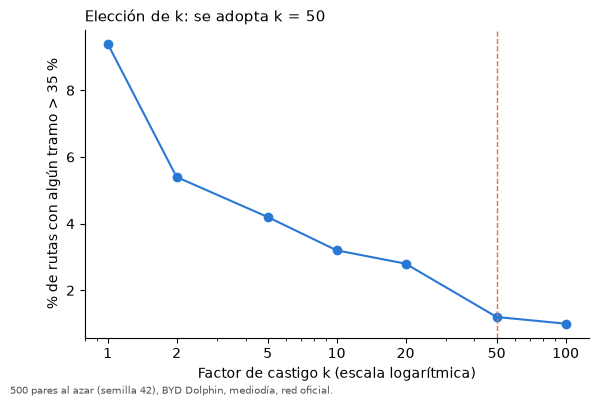


Corridas: 38  (pendiente extremos; capa 2 si; k = 50; sensibilidades: acumulada, capa 2 no, k = 0)
  [escrito] D4_pesos_energia.csv  sha eb17662c13b4...
  [escrito] D4_comparacion_rutas.csv  sha 48c22874d099...
  [escrito] D4_huellas_energia.json  sha ae596e581866...
   1/38  base                     byd_dolphin_449              12 h  extremos  con paradas  k=50   187 s
  [escrito] D4_pesos_energia.csv  sha 42cb576fd5d8...
  [escrito] D4_comparacion_rutas.csv  sha d05b4474fa7a...
  [escrito] D4_huellas_energia.json  sha d7fcc9443ef1...
   2/38  base                     byd_seagull_dolphin_mini     12 h  extremos  con paradas  k=50   183 s
  [escrito] D4_pesos_energia.csv  sha ea65455e08a4...
  [escrito] D4_comparacion_rutas.csv  sha 863e8fd8921b...
  [escrito] D4_huellas_energia.json  sha f837e4f1675b...
   3/38  base                     byd_tang_gs                  12 h  extremos  con paradas  k=50   185 s
  [escrito] D4_pesos_energia.csv  sha c09e41895e08...
  [escrito] D4_comparaci

In [21]:
# =============================================================================
# CELDA 12: CORRIDAS DE ENERGIA (12 vehiculos, 5 franjas, 5 escenarios de red)
# Misma metodologia y pruebas que la celda 11. Cada corrida en su carpeta.
# =============================================================================
_cache_corta = {}
def rutas_cortas(scen):
    if scen not in _cache_corta:
        rd = pd.read_csv(K.RUTA_ENTREGABLES / "D4" / f"esc_{scen}" / f"D4_rutas_distancia_{scen}.csv",
                         dtype={"origen": "string", "destino": "string", "tramos": "string"})
        assert (rd["origen"].to_numpy() == OD["origen"].to_numpy()).all()
        assert (rd["destino"].to_numpy() == OD["destino"].to_numpy()).all()
        _cache_corta[scen] = ([s.split(";") for s in rd["tramos"]], rd["distancia_m"].to_numpy())
    return _cache_corta[scen]

_seg_flota = VF.segmentos_flota()

# --- Capa 2 (arrancar y frenar), leida de las tablas del modelo para el segundo camino
_TAB_PKE = pd.read_csv(_car2 / "capa_paradas_tabla_pke.csv")
_K_FLOTA = (pd.read_csv(_car2 / "capa_paradas_coef_flota.csv")
            .set_index("vehiculo")["k_wh_km_por_Jkgkm"])

def consumo_sin_regen_vectorizado(Lc, pend, v_kmh, p, rho):
    """Segundo camino del costo SIN recuperar: la misma fisica de consumo_vectorizado
    pero con la regeneracion apagada (en bajada la bateria solo paga auxiliares)."""
    v = v_kmh / 3.6
    th = np.arctan(pend / 100.0)
    m = p.m_ensayo
    f = (p.crr(v) * m * PAR.G * np.cos(th) + 0.5 * rho * p.cd * p.area_frontal * v ** 2
         + m * PAR.G * np.sin(th))
    pb = np.where(f * v >= 0, f * v / p.eta_traccion, 0.0)
    return (pb + p.p_aux) * np.where(v > 0, Lc / v, 0.0) / 3.6e6

def extra_paradas(Lc, v, vehiculo_id):
    """Capa 2 por tramo (kWh): con la funcion del modelo (extra_arco_kwh) y, aparte,
    con la formula de su guia: k_vehiculo * PKE(v) * L_inclinada_km / 1000."""
    ex = np.array([CP.extra_arco_kwh(vehiculo_id, a, b) for a, b in zip(Lc, v)])
    ex_ind = (float(_K_FLOTA[vehiculo_id])
              * np.interp(v, _TAB_PKE["vprom"].to_numpy(), _TAB_PKE["pke_mediana"].to_numpy())
              * (np.asarray(Lc, float) / 1000.0) / 1000.0)
    return ex, ex_ind

def pesos_red(T, dz, v, vehiculo_id, modo, paradas=None):
    """Pesos de energia por tramo. paradas=None usa constantes_d1.CAPA_PARADAS_D4.
    Con paradas=True se suma la capa 2 (extra por arrancar y frenar)
    sobre la longitud inclinada del tramo; el dict trae ademas 'extra'."""
    if paradas is None:
        paradas = K.CAPA_PARADAS_D4
    r = _pesos_capa1(T, dz, v, vehiculo_id, modo)
    if paradas:
        ex, ex_ind = extra_paradas(r["Lc"], v, vehiculo_id)
        r["w"], r["w_indep"] = r["w"] + ex, r["w_indep"] + ex_ind
        r["w_sin_regen"] = r["w_sin_regen"] + ex
        r["w_sin_regen_indep"] = r["w_sin_regen_indep"] + ex_ind
        r["extra"] = ex
    else:
        r["extra"] = np.zeros(len(r["w"]))
    return r

def _pesos_capa1(T, dz, v, vehiculo_id, modo):
    """Pesos de energia de cada tramo segun la forma de pendiente.
    modo = "extremos": un solo trozo con el desnivel entre esquinas (celda 11).
    modo = "acumulada": el tramo se parte en un trozo que SUBE G metros y otro
      que BAJA P metros (ganancia y perdida del archivo de pendientes), los dos con la pendiente
      acumulada 100 * (G + P) / L. G y P se corrigen para que G - P = desnivel
      entre esquinas: asi las alturas por esquina siguen sirviendo para Johnson.
      En los tramos sin dato del MDT (G = P = 0) queda igual que "extremos".
    Devuelve un dict: w (kWh, funcion del modelo), w_indep (misma fisica calculada
    aparte), pend (pendiente NETA, %), Lc (longitud usada, m), bajada (m que
    baja en total), avisos (tramos largos y empinados)."""
    p = VF.vehiculo(vehiculo_id)
    L = T["longitud_m"].to_numpy(float)
    dz = np.asarray(dz, float)
    if modo == "extremos":
        w, pend, Lc, n_warn = pesos_consumo(T, dz, v, vehiculo_id, K.LONGITUD_CONSUMO_D4)
        # Sin recuperar: cuando la bajada recargaria, la bateria solo paga los
        # auxiliares durante el tramo -> max(consumo, auxiliares * tiempo)
        aux = p.p_aux * (Lc / (np.asarray(v, float) / 3.6)) / 3.6e6
        return {"w": w, "w_indep": consumo_vectorizado(Lc, pend, v, p, _rho),
                "w_sin_regen": np.maximum(w, aux),
                "w_sin_regen_indep": consumo_sin_regen_vectorizado(Lc, pend, v, p, _rho),
                "pend": pend, "Lc": Lc, "bajada": np.clip(-dz, 0, None), "avisos": n_warn}
    assert modo == "acumulada", f"Forma de pendiente desconocida: {modo}"
    G = T["ganancia_acumulada_m"].to_numpy(float)
    P = T["perdida_acumulada_m"].to_numpy(float)
    _aj = dz - (G - P)                          # 0 salvo junto a las 3 esquinas incoherentes
    G = G + np.clip(_aj, 0, None)
    P = P + np.clip(-_aj, 0, None)
    GP = G + P
    _hay = GP > 0
    s = np.where(_hay, 100.0 * GP / L, 0.0)                    # pendiente acumulada (%)
    L_sube = np.where(_hay, L * G / np.where(_hay, GP, 1.0), 0.0)
    L_baja = np.where(_hay, L * P / np.where(_hay, GP, 1.0), 0.0)
    L_plano = np.where(_hay, 0.0, L)
    w, w_ind, Lc, n_warn = np.zeros(len(L)), np.zeros(len(L)), np.zeros(len(L)), 0
    w_sr, w_sr_ind = np.zeros(len(L)), np.zeros(len(L))       # sin recuperar, trozo por trozo
    v = np.asarray(v, float)
    for Lt, st in ((L_sube, s), (L_baja, -s), (L_plano, np.zeros(len(L)))):
        m = Lt > 0
        Lct = Lt * np.sqrt(1.0 + (st / 100.0) ** 2) if K.LONGITUD_CONSUMO_D4 == "inclinada" else Lt
        wt = np.zeros(len(L))
        with warnings.catch_warnings(record=True) as W:
            warnings.simplefilter("always")
            for i in np.flatnonzero(m):
                wt[i] = IG.consumo_arco_kwh(vehiculo_id, Lct[i], st[i], v[i], K.CIUDAD_CONSUMO_D4)
        n_warn += sum("arco largo y empinado" in str(x.message) for x in W)
        w[m] += wt[m]
        aux = p.p_aux * (Lct[m] / (v[m] / 3.6)) / 3.6e6
        w_sr[m] += np.maximum(wt[m], aux)
        w_ind[m] += consumo_vectorizado(Lct[m], st[m], v[m], p, _rho)
        w_sr_ind[m] += consumo_sin_regen_vectorizado(Lct[m], st[m], v[m], p, _rho)
        Lc[m] += Lct[m]
    return {"w": w, "w_indep": w_ind, "w_sin_regen": w_sr, "w_sin_regen_indep": w_sr_ind,
            "pend": 100.0 * dz / L, "Lc": Lc, "bajada": P, "avisos": n_warn}

# --- Pendientes extremas: castigo k ---------------------
# Los tramos extremos NO se quitan: su peso de RUTEO es k * max(consumo, consumo en
# plano), nunca negativo. La energia que se REPORTA es siempre la real (sin castigo).
_EXT_ID = pd.Series(EXTREMA.to_numpy(bool), index=g["segmento_id"].to_numpy())

# Regla de puentes (igual que Medellin): extremas sobre puente/tunel que NO se castigan
_r_pu = K.ruta_cruda("recibidos") / K.ARCHIVO_REGLA_PUENTES
_sha_pu = sha256_archivo(_r_pu)
if K.SHA256_REGLA_PUENTES is None:
    raise RuntimeError(f'Registrar en constantes_d1: SHA256_REGLA_PUENTES = "{_sha_pu}" '
                       "(se detiene a proposito)")
assert _sha_pu == K.SHA256_REGLA_PUENTES, "regla_puentes_castigo.csv cambio"
_PU = pd.read_csv(_r_pu, dtype={"segmento_id": str}, encoding="utf-8-sig")
_PU["castigada_regla_medellin"] = _PU["castigada_regla_medellin"].astype(str).str.lower().eq("true")
EXENTAS_PUENTE = set(_PU.loc[~_PU["castigada_regla_medellin"], "segmento_id"]) if K.REGLA_PUENTES_D4 else set()
_pr_pu = [
    ("regla de puentes: toda exenta es extrema en el archivo de pendientes",
     all(_EXT_ID.get(s, False) for s in EXENTAS_PUENTE)),
    ("regla de puentes: toda exenta tiene |neta| <= 35 % en el archivo de pendientes",
     bool((_PU.loc[~_PU["castigada_regla_medellin"], "pendiente_neta_pct"].abs()
           <= K.UMBRAL_PENDIENTE_EXTREMA_PCT).all())),
]
print(f"Regla de puentes: {len(EXENTAS_PUENTE)} aristas extremas dejan de castigarse "
      f"{sorted(EXENTAS_PUENTE)}")
assert all(ok for _, ok in _pr_pu), [n for n, ok in _pr_pu if not ok]

def marca_extremas_partes(T, dz):
    """(extrema_revisada, extrema_estimada): la marca del archivo de pendientes, y la misma regla del
    umbral aplicada a los tramos SIN dato del MDT con la altura estimada (celda 8)."""
    revisada = (T["segmento_id"].map(_EXT_ID).fillna(False).to_numpy(bool)
             & ~T["segmento_id"].isin(EXENTAS_PUENTE).to_numpy())
    pe = 100.0 * np.asarray(dz, float) / T["longitud_m"].to_numpy(float)
    estimada = (T["pendiente_asumida_cero"].to_numpy(bool)
                & (np.abs(pe) > K.UMBRAL_PENDIENTE_EXTREMA_PCT))
    return revisada, estimada

def marca_extremas(T, dz):
    """Tramos que se castigan: los del archivo de pendientes y, si la constante lo pide, los estimados."""
    revisada, estimada = marca_extremas_partes(T, dz)
    return revisada | estimada if K.EXTREMAS_POR_ALTURA_ESTIMADA_D4 else revisada

def plano_extremas(Lc, v, vehiculo_id, paradas, ext):
    """Consumo del MISMO tramo (misma longitud recorrida) con pendiente 0, solo en los
    extremos: con la funcion del modelo y, aparte, con la fisica vectorizada."""
    Lc, v = np.asarray(Lc, float), np.asarray(v, float)
    pl, pl_ind = np.zeros(len(Lc)), np.zeros(len(Lc))
    i = np.flatnonzero(ext)
    if len(i):
        pl[i] = [IG.consumo_arco_kwh(vehiculo_id, a, 0.0, b, K.CIUDAD_CONSUMO_D4)
                 for a, b in zip(Lc[i], v[i])]
        pl_ind[i] = consumo_vectorizado(Lc[i], np.zeros(len(i)), v[i],
                                        VF.vehiculo(vehiculo_id), _rho)
        if paradas:
            ex, ex_ind = extra_paradas(Lc[i], v[i], vehiculo_id)
            pl[i] += ex
            pl_ind[i] += ex_ind
    return pl, pl_ind

def castigar(w, w_sin_regen, w_plano, ext, k):
    """Peso de RUTEO (regla del castigo). En los extremos:
    k * max(consumo SIN recuperar en la bajada, consumo del tramo en plano); en el
    resto, el consumo. Nunca negativo en los extremos. k = 0 significa SIN castigo
    (ojo: k = 1 ya no es "sin castigo": quita la recuperacion en las bajadas
    extremas y pone el piso del consumo en plano)."""
    if k == 0:                                     # k = 0: SIN castigo (peso = consumo)
        return np.array(w, dtype=float)
    return np.where(ext, k * np.maximum(w_sin_regen, w_plano), w)

def suma_en_arbol(padre, val, es_raiz):
    """S[x] = val[x] + S[padre[x]], con S = 0 en las raices (NaN si no se alcanza)."""
    S = np.full(len(padre), np.nan)
    S[es_raiz] = 0.0
    pend = np.flatnonzero(~es_raiz & (padre >= 0))
    while len(pend):
        p = padre[pend]
        listo = ~np.isnan(S[p])
        assert listo.any(), "El arbol de rutas tiene un ciclo o un padre invalido"
        S[pend[listo]] = val[pend[listo]] + S[p[listo]]
        pend = pend[~listo]
    return S

def peso_de_arista(iu, iv, w, a, b, n):
    """Peso de las aristas a -> b del grafo ya deduplicado (iu, iv, w)."""
    cod = iu.astype(np.int64) * n + iv
    o = np.argsort(cod)
    cs = cod[o]
    q = np.asarray(a, np.int64) * n + np.asarray(b, np.int64)
    j = np.minimum(np.searchsorted(cs, q), len(cs) - 1)
    assert (cs[j] == q).all(), "Una arista del arbol no existe en el grafo"
    return w[o[j]]

def real_hacia_estacion(P, iu, iv, w):
    """Suma de w por la ruta ELEGIDA desde cada esquina hasta su estacion. P es el
    arbol de la busqueda al reves desde el nodo imaginario n (P == n: estacion)."""
    n = len(P)
    raiz = P == n
    padre = np.where(raiz | (P < 0), -1, P).astype(np.int64)
    val = np.zeros(n)
    m = padre >= 0
    val[m] = peso_de_arista(iu, iv, w, np.flatnonzero(m), padre[m], n)
    return suma_en_arbol(padre, val, raiz)

def real_desde_origen(P, s, iu, iv, w):
    """Suma de w por la ruta ELEGIDA desde el origen s hasta cada esquina (arbol de
    una busqueda hacia adelante: P[j] es la esquina anterior)."""
    n = len(P)
    raiz = np.zeros(n, bool)
    raiz[s] = True
    padre = np.where(raiz | (P < 0), -1, P).astype(np.int64)
    val = np.zeros(n)
    m = padre >= 0
    val[m] = peso_de_arista(iu, iv, w, padre[m], np.flatnonzero(m), n)
    return suma_en_arbol(padre, val, raiz)

def correr_energia(scen, veh, hora, modo, paradas, k):
    T = ESC[scen]
    T = T[T["en_red"]].reset_index(drop=True)
    dz = (T["v"].map(_zB) - T["u"].map(_zB)).to_numpy(float)
    assert np.isfinite(dz).all(), f"{scen}: esquinas sin altura en la red"
    T = T.assign(dz_esquinas=dz)
    v, n_sinloc, con_resp = velocidades(T, hora)
    _pw = pesos_red(T, dz, v, veh, modo, paradas)
    w, pend, Lc, n_warn = _pw["w"], _pw["pend"], _pw["Lc"], _pw["avisos"]
    ext_rev, ext_estim = marca_extremas_partes(T, dz)
    es_ext = marca_extremas(T, dz)
    w_pl, w_pl_ind = plano_extremas(Lc, v, veh, paradas, es_ext)
    w_rt = castigar(w, _pw["w_sin_regen"], w_pl, es_ext, k)   # peso de RUTEO (w = energia REAL)
    p = VF.vehiculo(veh)
    pr = []
    pr.append(("castigo: consumo sin recuperar = calculo independiente",
               bool(np.allclose(_pw["w_sin_regen"], _pw["w_sin_regen_indep"], rtol=1e-12, atol=1e-15))))
    pr.append(("castigo: consumo en plano = calculo independiente",
               bool(np.allclose(w_pl, w_pl_ind, rtol=1e-12, atol=1e-15))))
    # Con k = 0 no hay castigo: el peso es el consumo real, que en una bajada extrema
    # puede ser negativo (recupera). La regla "nunca negativo" solo aplica con castigo.
    pr.append(("castigo: ruteo >= real en todo tramo y >= 0 en los extremos (si k > 0)",
               bool((w_rt >= w - 1e-15).all() and (k == 0 or (w_rt[es_ext] >= 0).all()))))
    if paradas:
        pr.append(("capa 2: extra > 0 en todo tramo", bool((_pw["extra"] > 0).all())))
        _i = np.random.default_rng(K.SEMILLA_OD_D4).choice(len(T), size=300, replace=False)
        pr.append(("capa 2: = consumo_arco_con_paradas_kwh del modelo (300 tramos)",
                   bool(modo != "extremos" or np.allclose(
                       [CP.consumo_arco_con_paradas_kwh(veh, Lc[i], pend[i], v[i], K.CIUDAD_CONSUMO_D4)
                        for i in _i], w[_i], rtol=1e-12, atol=1e-15))))
    pr.append(("pesos finitos", bool(np.isfinite(w).all())))
    pr.append(("modelo de consumo = calculo independiente",
               bool(np.allclose(w, _pw["w_indep"], rtol=1e-12, atol=1e-15))))
    tw = T.assign(w=w)
    _f = tw[tw["sentido_recorrido"] == "FT"].set_index(["id_eje", "parte"])["w"]
    _t = tw[tw["sentido_recorrido"] == "TF"].set_index(["id_eje", "parte"])["w"]
    pr.append(("ida y vuelta > 0", bool(((_f + _t).dropna() > 0).all())))
    tope = p.frac_regen * p.eta_regen * p.m_ensayo * PAR.G * _pw["bajada"] / 3.6e6
    pr.append(("nunca recupera mas del tope", bool((w >= -tope - 1e-12).all())))
    n_, iu_, iv_, w2, s_ = preparar_grafo(T, w_rt)
    _n0, _iu0, _, _, _ = preparar_grafo(T, w)
    pr.append(("castigo: mismas esquinas y tramos que sin castigo",
               len(_n0) == len(n_) and len(_iu0) == len(iu_)))
    h, met, _C = potenciales(n_, iu_, iv_, w2, _zB)
    pr.append(("sin ciclos (potencial por altura)", met == "por_altura"))
    o = n_.get_indexer(OD["origen"]); d = n_.get_indexer(OD["destino"])
    assert (o >= 0).all() and (d >= 0).all()
    e, r, s = rutear_johnson(len(n_), iu_, iv_, w2, s_, o, d, h)
    tr_c, L_c = rutas_cortas(scen)
    Ws = pd.Series(w, index=T["segmento_id"])           # energia REAL
    Wr = pd.Series(w_rt, index=T["segmento_id"])        # peso de RUTEO
    Ls = pd.Series(T["longitud_m"].to_numpy(), index=T["segmento_id"])
    pr.append(("distancia corta en disco = suma de tramos",
               bool(np.allclose([Ls.loc[t].sum() for t in tr_c], L_c, rtol=1e-9, atol=1e-6))))
    Ec = np.array([Ws.loc[t].sum() for t in tr_c])
    Ec_rt = np.array([Wr.loc[t].sum() for t in tr_c])
    Le = np.array([Ls.loc[x].sum() for x in r])
    e_real = np.array([Ws.loc[x].sum() for x in r])
    pr.append(("costo de ruteo = suma de pesos de ruteo", bool(np.allclose(e, s, rtol=1e-9, atol=1e-12))))
    pr.append(("eficiente <= corta en costo de ruteo", bool((e <= Ec_rt + 1e-12).all())))
    pr.append(("eficiente >= corta en distancia", bool((Le >= L_c - 1e-6).all())))
    if k == 0:
        pr.append(("sin castigo: costo de ruteo = energia real",
                   bool(np.allclose(e, e_real, rtol=1e-9, atol=1e-12))))
    fallan = [n for n, ok in pr if not ok]
    assert not fallan, f"{scen} / {veh} / {hora} h / k={k}: fallan {fallan}"
    e_ruteo, e = e, e_real              # desde aqui, e es la energia REAL de la ruta elegida

    # --- metricas ---
    misma = np.array([a == b for a, b in zip(r, tr_c)])
    # Ahorro sobre TODOS los viajes con energia corta > 0; donde la ruta es la
    # misma el ahorro es 0. (Antes los percentiles se tomaban solo entre los
    # viajes cuya ruta cambia; esa version queda como "_si_cambia".)
    pos = Ec > 0
    ahorro = np.full(len(Ec), np.nan)
    ahorro[pos] = 100 * (Ec[pos] - e[pos]) / Ec[pos]
    ahorro[pos & misma] = 0.0
    extra = 100 * (Le / L_c - 1)
    ext = set(T.loc[es_ext, "segmento_id"])
    cambia = ~misma & pos
    res = {
        "escenario": scen, "vehiculo": veh,
        "validado": veh in K.VEHICULOS_VALIDADOS_D4,
        "segmento": _seg_flota[veh][0], "bateria_kwh": p.bateria_util,
        "hora": hora, "franja": FH.franja_de(hora),
        "localidades_con_respaldo": len(con_resp), "tramos_sin_localidad": n_sinloc,
        "tramos_que_recargan_pct": round(100 * float((w < 0).mean()), 2),
        "avisos_largo_empinado": n_warn,
        "consumo_corta_kwh_100km": round(1e5 * Ec.sum() / L_c.sum(), 3),
        "consumo_eficiente_kwh_100km": round(1e5 * e.sum() / Le.sum(), 3),
        "pares_misma_ruta": int(misma.sum()),
        "pares_energia_corta_no_positiva": int((~pos).sum()),
        "pendiente": modo, "paradas": bool(paradas), "k": k,
        "tramos_extremos_en_red": int(es_ext.sum()),
        "tramos_extremos_estimados_en_red": int(ext_estim.sum()),
        "viajes_eficiente_gasta_mas_pct": round(100 * float((e > Ec + 1e-12).mean()), 2),
        "ahorro_mediana_pct": round(float(np.median(ahorro[pos])), 3),
        "ahorro_p90_pct": round(float(np.percentile(ahorro[pos], 90)), 3),
        "viajes_ahorro_mayor_5pct": round(100 * float((ahorro[pos] > 5).mean()), 2),
        "viajes_ahorro_mayor_10pct": round(100 * float((ahorro[pos] > 10).mean()), 2),
        "ahorro_mediana_si_cambia_pct": round(float(np.median(ahorro[cambia])), 3) if cambia.any() else 0.0,
        "ahorro_p90_si_cambia_pct": round(float(np.percentile(ahorro[cambia], 90)), 3) if cambia.any() else 0.0,
        "extra_distancia_mediana_pct": round(float(np.median(extra[~misma])), 3) if (~misma).any() else 0.0,
        "extra_distancia_p90_pct": round(float(np.percentile(extra[~misma], 90)), 3) if (~misma).any() else 0.0,
        "rutas_eficientes_con_tramo_extremo": int(sum(any(x in ext for x in rr) for rr in r)),
        "rutas_cortas_con_tramo_extremo": int(sum(any(x in ext for x in rr) for rr in tr_c)),
    }

    # --- salidas (mismo formato que la celda 11) ---
    tag = (f"esc_{scen}__{veh}__h{hora:g}__{modo}__long_{K.LONGITUD_CONSUMO_D4}"
           f"__{'con' if paradas else 'sin'}_paradas__k{k:g}")
    dirE = f"D4/energia/{tag}"
    sha_p = guardar_csv_sin_sobrescribir(pd.DataFrame({
        "segmento_id": T["segmento_id"].to_numpy(), "v_kmh": v, "pendiente_pct": pend,
        "longitud_consumo_m": Lc, "consumo_kwh": w, "extrema_revisada": ext_rev,
        "extrema_estimada": ext_estim, "castigada": es_ext,
        "peso_ruteo_kwh": w_rt}).sort_values("segmento_id"),
        K.ruta_entregable(dirE, "D4_pesos_energia.csv"))
    sha_c = guardar_csv_sin_sobrescribir(pd.DataFrame({
        "par": OD["par"], "distancia_corta_m": L_c, "energia_corta_kwh": Ec,
        "distancia_eficiente_m": Le, "energia_eficiente_kwh": e, "misma_ruta": misma,
        "costo_ruteo_corta_kwh": Ec_rt, "costo_ruteo_eficiente_kwh": e_ruteo,
        "tramos_eficiente": [";".join(x) for x in r]}),
        K.ruta_entregable(dirE, "D4_comparacion_rutas.csv"))
    ruta_h = K.ruta_entregable(dirE, "D4_huellas_energia.json")
    if ruta_h.exists():   # corrida ya hecha: comprobar que es identica
        prev = json.loads(ruta_h.read_text(encoding="utf-8"))["archivos"]
        assert prev == {"D4_pesos_energia.csv": sha_p, "D4_comparacion_rutas.csv": sha_c}, \
            f"{tag}: la corrida NO reproduce los archivos ya registrados"
        print(f"  [reproducida identica] {tag}")
    else:
        guardar_texto_sin_sobrescribir(json.dumps({
            "vehiculo": veh, "hora": hora,
            "franja": FH.franja_de(hora), "escenario": scen,
            "pendiente": modo, "longitud": K.LONGITUD_CONSUMO_D4, "capa_paradas": bool(paradas),
            "k_extremas": k,
            "archivos": {"D4_pesos_energia.csv": sha_p, "D4_comparacion_rutas.csv": sha_c},
            "insumos": {"modelo_consumo_sha256": _hs, "alturas_esquinas_sha256": _sha_alt,
                        "huella_gpkg_d3": HUELLA_D3},
            "pruebas": [{"prueba": n, "pasa": ok} for n, ok in pr]},
            indent=2, ensure_ascii=False, sort_keys=True, default=str), ruta_h)
    return res

# --- Lista de corridas ------------------------------------------------------------
# Vehiculos y franjas: en "base" (red base, se conserva como registro)
# y en el escenario OFICIAL (sens_sin_altura_A, ESCENARIO_OFICIAL_D4). Todo con
# la forma de pendiente principal (PENDIENTE_CONSUMO_D4); la otra forma se
# corre una vez (Dolphin, mediodia, escenario oficial) como sensibilidad.
MODO = K.PENDIENTE_CONSUMO_D4
OTRO_MODO = {"extremos": "acumulada", "acumulada": "extremos"}[MODO]
PARADAS = bool(K.CAPA_PARADAS_D4)          # capa 2 (arrancar y frenar)
_V0, _H0, _P0 = K.VEHICULO_BASE_D4, K.HORA_BASE_D4, K.ESCENARIO_OFICIAL_D4

# --- ELEGIR k CON DATOS --------------------------
# Escenario oficial, Dolphin, mediodia, forma de pendiente y capa 2 principales.
# 500 pares al azar (semilla 42) entre las esquinas de la red (componente fuerte).
# Regla: el menor k a partir del cual el % de rutas con algun tramo extremo deja de
# bajar (baja menos de 1 punto frente al k siguiente, y asi hasta el final).
import networkx as nx
_TK = ESC[_P0]
_TK = _TK[_TK["en_red"]].reset_index(drop=True)
_dzK = (_TK["v"].map(_zB) - _TK["u"].map(_zB)).to_numpy(float)
_vK, _, _ = velocidades(_TK, _H0)
_pwK = pesos_red(_TK, _dzK, _vK, _V0, MODO, PARADAS)
_extK = marca_extremas(_TK, _dzK)
_extK_d, _extK_e = marca_extremas_partes(_TK, _dzK)
_wsrK = _pwK["w_sin_regen"]
_wplK, _wplK_ind = plano_extremas(_pwK["Lc"], _vK, _V0, PARADAS, _extK)
print(f"Tramos extremos en la red: {int(_extK_d.sum()):,} del archivo de pendientes y {int(_extK_e.sum())} "
      f"estimados ({sorted(_TK.loc[_extK_e, 'segmento_id'])}); se castigan {int(_extK.sum()):,}")
_nodos_red = sorted(set(_TK["u"]) | set(_TK["v"]))
_rngK = np.random.default_rng(K.SEMILLA_ELEGIR_K_D4)
PARES_K = [tuple(_rngK.choice(_nodos_red, 2, replace=False)) for _ in range(K.N_PARES_ELEGIR_K_D4)]
_WsK = pd.Series(_pwK["w"], index=_TK["segmento_id"])
_LsK = pd.Series(_TK["longitud_m"].to_numpy(), index=_TK["segmento_id"])
_ext_ids = set(_TK.loc[_extK, "segmento_id"])
pr_k, filas_k, _r1 = [], [], None
pr_k.append({"prueba": "consumo en plano = calculo independiente",
             "pasa": bool(np.allclose(_wplK, _wplK_ind, rtol=1e-12, atol=1e-15))})
# Referencia SIN castigo (k = 0): cuantas rutas usan tramos extremos hoy
_n, _iu, _iv, _w2, _s = preparar_grafo(_TK, castigar(_pwK["w"], _wsrK, _wplK, _extK, 0))
_h, _, _ = potenciales(_n, _iu, _iv, _w2, _zB)
_o = _n.get_indexer([a for a, _ in PARES_K]); _d = _n.get_indexer([b for _, b in PARES_K])
_e, _rr, _ = rutear_johnson(len(_n), _iu, _iv, _w2, _s, _o, _d, _h)
pr_k.append({"prueba": "sin castigo: costo de ruteo = energia real",
             "pasa": bool(np.allclose(_e, [_WsK.loc[x].sum() for x in _rr], rtol=1e-9, atol=1e-12))})
PCT_SIN_CASTIGO = 100 * np.mean([any(t in _ext_ids for t in x) for x in _rr])
print(f"  sin castigo: {PCT_SIN_CASTIGO:5.1f} % de rutas con tramo extremo")
_t0 = time.time()
for kk in K.FACTORES_EXTREMAS_CANDIDATOS_D4:
    _wrt = castigar(_pwK["w"], _wsrK, _wplK, _extK, kk)
    _n, _iu, _iv, _w2, _s = preparar_grafo(_TK, _wrt)
    _h, _met, _ = potenciales(_n, _iu, _iv, _w2, _zB)
    _o = _n.get_indexer([a for a, _ in PARES_K]); _d = _n.get_indexer([b for _, b in PARES_K])
    assert (_o >= 0).all() and (_d >= 0).all()
    _e, _rr, _sm = rutear_johnson(len(_n), _iu, _iv, _w2, _s, _o, _d, _h)
    _er = np.array([_WsK.loc[x].sum() for x in _rr])
    _lr = np.array([_LsK.loc[x].sum() for x in _rr])
    _usa = np.array([any(t in _ext_ids for t in x) for x in _rr])
    pr_k.append({"prueba": f"k={kk:g}: alturas de energia validas y costo = suma de pesos",
                 "pasa": _met == "por_altura" and bool(np.allclose(_e, _sm, rtol=1e-9, atol=1e-12))})
    if _r1 is None:
        _r1, _er1, _lr1 = _rr, _er, _lr
    filas_k.append({"k": kk, "pct_rutas_con_tramo_extremo": 100 * _usa.mean(),
                    "rutas_con_tramo_extremo": int(_usa.sum()),
                    "energia_real_media_kwh": _er.mean(),
                    "pct_rutas_cambian_vs_k1": 100 * np.mean([a != b for a, b in zip(_rr, _r1)]),
                    "energia_real_extra_vs_k1_pct": 100 * (_er.sum() / _er1.sum() - 1),
                    "distancia_extra_vs_k1_pct": 100 * (_lr.sum() / _lr1.sum() - 1)})
    print(f"  k = {kk:>5g}: {100 * _usa.mean():5.1f} % de rutas con tramo extremo  "
          f"({time.time() - _t0:,.0f} s)")
TAB_K = pd.DataFrame(filas_k)
_pct = TAB_K["pct_rutas_con_tramo_extremo"].to_numpy()
_baja = _pct[:-1] - _pct[1:]
_i = next((i for i in range(len(_baja))
           if (_baja[i:] < K.UMBRAL_CAMBIO_K_PUNTOS_D4).all()), len(_pct) - 1)
K_ADOPTADO = float(TAB_K["k"].iat[_i])
if K.FACTOR_EXTREMAS_D4 is not None:
    assert float(K.FACTOR_EXTREMAS_D4) == K_ADOPTADO, (
        f"La regla da k = {K_ADOPTADO:g} y constantes_d1 dice {K.FACTOR_EXTREMAS_D4}")
K_CORRIDAS = K_ADOPTADO if K.CASTIGO_EXTREMAS_PRINCIPAL_D4 else 0.0   # 0 = sin castigo

# Segundo camino: con el k adoptado, Bellman-Ford puro (networkx) da el mismo costo
_wrt = castigar(_pwK["w"], _wsrK, _wplK, _extK, K_ADOPTADO)
_n, _iu, _iv, _w2, _s = preparar_grafo(_TK, _wrt)
_h, _, _ = potenciales(_n, _iu, _iv, _w2, _zB)
_GK = nx.DiGraph()
_GK.add_weighted_edges_from(zip(_iu.tolist(), _iv.tolist(), _w2.tolist()), weight="w")
_ok_bf = True
for a, b in PARES_K[:3]:
    _o, _d = _n.get_loc(a), _n.get_loc(b)
    _eJ, _, _ = rutear_johnson(len(_n), _iu, _iv, _w2, _s, np.array([_o]), np.array([_d]), _h)
    _ok_bf &= bool(np.isclose(nx.single_source_bellman_ford_path_length(_GK, _o, weight="w")[_d],
                              _eJ[0], rtol=1e-9, atol=1e-9))
pr_k.append({"prueba": f"k={K_ADOPTADO:g}: Johnson = Bellman-Ford puro de networkx (3 pares)",
             "pasa": _ok_bf})
# Sensibilidad "bloquear" sobre la MISMA red oficial: se quitan los tramos
# extremos, se recalcula la componente fuerte y se cuenta que queda sin ruta.
_TKb = _TK[~_extK]
_comp_b, _n_esq_b = componente_mayor(_TKb)
_nod_b = set(_TKb.loc[_comp_b, "u"]) | set(_TKb.loc[_comp_b, "v"])
BLOQUEAR = {"esquinas_red_oficial": len(_nodos_red), "esquinas_que_quedan": _n_esq_b,
            "esquinas_sin_ruta": len(_nodos_red) - _n_esq_b,
            "pares_sin_ruta": int(sum(a not in _nod_b or b not in _nod_b for a, b in PARES_K)),
            "n_pares": len(PARES_K)}
pr_k.append({"prueba": "bloquear: la red que queda es fuertemente conexa",
             "pasa": len(_nod_b) == _n_esq_b})
print(f"BLOQUEAR los extremos en la red oficial: quedan {_n_esq_b:,} de {len(_nodos_red):,} "
      f"esquinas ({BLOQUEAR['esquinas_sin_ruta']:,} sin ruta); de los {len(PARES_K)} pares, "
      f"{BLOQUEAR['pares_sin_ruta']} quedan sin ruta")
_df = pd.DataFrame(pr_k)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("\nELEGIR k — pruebas")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"
print(f"\nTABLA DE k ({K.N_PARES_ELEGIR_K_D4} pares, semilla {K.SEMILLA_ELEGIR_K_D4}; "
      f"{len(_ext_ids):,} tramos extremos en la red)")
print(TAB_K.round(3).to_string(index=False))
_fila = TAB_K.iloc[_i]
print(f"\nk ADOPTADO: {K_ADOPTADO:g}.  Con ese k, {int(_fila['rutas_con_tramo_extremo'])} de "
      f"{K.N_PARES_ELEGIR_K_D4} rutas ({_fila['pct_rutas_con_tramo_extremo']:.1f} %) siguen usando "
      "algun tramo extremo: no tienen otra alternativa razonable.")
print(f"k de las corridas de 12 carros, franjas y alcanzabilidad: {K_CORRIDAS:g} "
      "(restriccion de pendiente; la comparacion principal es k = 0, ruta de minimo consumo)")

_dirK = "D4/elegir_k"
_sha_k = guardar_csv_sin_sobrescribir(TAB_K, K.ruta_entregable(_dirK, "D4_tabla_k.csv"))
guardar_texto_sin_sobrescribir(json.dumps({
    "k_adoptado": K_ADOPTADO, "k_corridas": K_CORRIDAS, "k_0_significa": "sin castigo",
    "pct_rutas_con_extremo_sin_castigo": PCT_SIN_CASTIGO,
    "castigo_en_corridas": bool(K.CASTIGO_EXTREMAS_PRINCIPAL_D4),
    "extremas_por_altura_estimada": bool(K.EXTREMAS_POR_ALTURA_ESTIMADA_D4),
    "candidatos": list(K.FACTORES_EXTREMAS_CANDIDATOS_D4),
    "n_pares": K.N_PARES_ELEGIR_K_D4, "semilla": K.SEMILLA_ELEGIR_K_D4,
    "regla": "menor k desde el cual el % de rutas con tramo extremo baja menos de "
             f"{K.UMBRAL_CAMBIO_K_PUNTOS_D4:g} punto frente al k siguiente, hasta el final",
    "red": {"escenario": _P0, "vehiculo": _V0, "hora": _H0, "pendiente": MODO,
            "capa_paradas": PARADAS, "tramos_extremos": len(_ext_ids)},
    "rutas_que_siguen_con_extremo": int(_fila["rutas_con_tramo_extremo"]),
    "tramos_extremos": {"revisadas": int(_extK_d.sum()), "estimados": int(_extK_e.sum()),
                        "estimados_ids": sorted(_TK.loc[_extK_e, "segmento_id"])},
    "bloquear_en_red_oficial": BLOQUEAR,
    "archivos": {"D4_tabla_k.csv": _sha_k}, "pruebas": pr_k},
    indent=2, ensure_ascii=False, sort_keys=True, default=str),
    K.ruta_entregable(_dirK, "D4_k_adoptado.json"))
_figk = K.ruta_entregable(_dirK, "D4_fig7_elegir_k.png")
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(TAB_K["k"], TAB_K["pct_rutas_con_tramo_extremo"], marker="o", color="#2a78d6")
ax.axvline(K_ADOPTADO, color="#eb6834", linestyle="--", linewidth=1)
ax.set_xscale("log"); ax.set_xticks(TAB_K["k"]); ax.set_xticklabels([f"{x:g}" for x in TAB_K["k"]])
ax.set_xlabel("Factor de castigo k (escala logarítmica)")
ax.set_ylabel("% de rutas con algún tramo > 35 %")
ax.set_title(f"Elección de k: se adopta k = {K_ADOPTADO:g}", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, -0.03, f"{K.N_PARES_ELEGIR_K_D4} pares al azar (semilla {K.SEMILLA_ELEGIR_K_D4}), "
         "BYD Dolphin, mediodía, red oficial.", fontsize=7, color="#52514e")
if _figk.exists():
    print(f"  [figura ya existe, no se reescribe] {_figk.name}")
else:
    fig.savefig(_figk, dpi=200, bbox_inches="tight", facecolor="white")
    print(f"  [figura escrita] {_figk.name}")
plt.show()
BITACORA["elegir_k"] = {"k_adoptado": K_ADOPTADO, "k_corridas": K_CORRIDAS,
                        "tabla": TAB_K.to_dict(orient="records"), "pruebas": pr_k}

# --- Lista de corridas (todas con k) ----------------------------------------------------
_K_OTRO = 0.0 if K_CORRIDAS != 0 else K_ADOPTADO
CORRIDAS = []
for _esc in dict.fromkeys(["base", _P0]):
    CORRIDAS += [(_esc, vh, _H0, MODO, PARADAS, K_CORRIDAS) for vh in sorted(VF.FLOTA)]
    CORRIDAS += [(_esc, _V0, hh, MODO, PARADAS, K_CORRIDAS) for hh in K.HORAS_POR_FRANJA_D4.values()
                 if hh != _H0]
CORRIDAS += [(esc, _V0, _H0, MODO, PARADAS, K_CORRIDAS) for esc in K.ESCENARIOS_D4
             if (esc, _V0, _H0, MODO, PARADAS, K_CORRIDAS) not in CORRIDAS]
# Sensibilidades (Dolphin, mediodia, oficial): la otra forma de pendiente, la otra
# opcion de capa 2 y la otra opcion de castigo (k = 0 = sin castigo, o el k adoptado)
CORRIDAS += [(_P0, _V0, _H0, OTRO_MODO, PARADAS, K_CORRIDAS),
             (_P0, _V0, _H0, MODO, not PARADAS, K_CORRIDAS)]
if _K_OTRO != K_CORRIDAS:
    CORRIDAS += [(_P0, _V0, _H0, MODO, PARADAS, _K_OTRO)]
assert len(CORRIDAS) == len(set(CORRIDAS))
print(f"\nCorridas: {len(CORRIDAS)}  (pendiente {MODO}; capa 2 {'si' if PARADAS else 'no'}; "
      f"k = {K_CORRIDAS:g}; sensibilidades: {OTRO_MODO}, capa 2 {'no' if PARADAS else 'si'}, k = {_K_OTRO:g})")

RES_ENERGIA = []
_t0 = time.time()
for i, (esc, vh, hh, md, pa, kk) in enumerate(CORRIDAS, 1):
    t1 = time.time()
    RES_ENERGIA.append(correr_energia(esc, vh, hh, md, pa, kk))
    print(f"  {i:>2}/{len(CORRIDAS)}  {esc:<24} {vh:<26} {hh:>4g} h  {md:<9} "
          f"{'con' if pa else 'sin'} paradas  k={kk:<4g} {time.time() - t1:,.0f} s")
print(f"Total: {(time.time() - _t0) / 60:,.1f} min")

RES_ENERGIA = pd.DataFrame(RES_ENERGIA)
guardar_csv_sin_sobrescribir(RES_ENERGIA, K.ruta_entregable("D4/energia", "D4_resumen_energia_v2.csv"))

_cols = ["consumo_corta_kwh_100km", "consumo_eficiente_kwh_100km", "pares_misma_ruta",
         "ahorro_mediana_pct", "ahorro_p90_pct", "viajes_ahorro_mayor_5pct",
         "viajes_ahorro_mayor_10pct", "viajes_eficiente_gasta_mas_pct", "extra_distancia_p90_pct",
         "rutas_eficientes_con_tramo_extremo", "rutas_cortas_con_tramo_extremo"]
_R = RES_ENERGIA[(RES_ENERGIA["pendiente"] == MODO) & (RES_ENERGIA["paradas"] == PARADAS)
                 & (RES_ENERGIA["k"] == K_CORRIDAS)]
print(f"\n1) LOS 12 VEHICULOS ({K.ESCENARIO_OFICIAL_D4}, mediodia, pendiente {MODO})")
print(_R[(_R["escenario"] == K.ESCENARIO_OFICIAL_D4) & (_R["hora"] == K.HORA_BASE_D4)]
      .set_index("vehiculo")[["validado", "segmento"] + _cols].to_string())
print(f"\n2) DOLPHIN POR FRANJA ({K.ESCENARIO_OFICIAL_D4})")
print(_R[(_R["escenario"] == K.ESCENARIO_OFICIAL_D4) & (_R["vehiculo"] == K.VEHICULO_BASE_D4)]
      .set_index("franja")[["localidades_con_respaldo"] + _cols].to_string())
print("\n3) DOLPHIN POR ESCENARIO DE RED (mediodia)")
print(_R[(_R["vehiculo"] == K.VEHICULO_BASE_D4) & (_R["hora"] == K.HORA_BASE_D4)]
      .set_index("escenario")[_cols].to_string())
print(f"\n4) PENDIENTE, CAPA 2 Y CASTIGO k (Dolphin, mediodia, {K.ESCENARIO_OFICIAL_D4})")
print(RES_ENERGIA[(RES_ENERGIA["escenario"] == K.ESCENARIO_OFICIAL_D4)
                  & (RES_ENERGIA["vehiculo"] == K.VEHICULO_BASE_D4)
                  & (RES_ENERGIA["hora"] == K.HORA_BASE_D4)]
      .set_index(["pendiente", "paradas", "k"])[_cols].to_string())
BITACORA["corridas_energia"] = RES_ENERGIA.to_dict(orient="records")

In [22]:
# =============================================================================
# CELDA 13: REVISION VISUAL DE LOS TRAMOS > 35 % (registro y verificacion)
# Lee el archivo intacto de datos_crudos/recibidos, lo cruza con el CSV de D3
# y con el escenario que BLOQUEA las extremas (sens_bloquear_extremas).
# Decision: las extremas se MANTIENEN en la red;
# bloquearlas es la sensibilidad. No modifica el archivo de la revision.
# =============================================================================
ESC_BLOQUEA = "sens_bloquear_extremas"
assert K.ESCENARIOS_D4[ESC_BLOQUEA]["bloquear_extremas"], \
    f"{ESC_BLOQUEA} deberia bloquear las extremas"

_rv = K.RUTA_DATOS_CRUDOS / "recibidos" / K.ARCHIVO_REVISION_EXTREMAS
assert _rv.exists(), f"Falta {_rv}: guardarlo tal cual en datos_crudos/recibidos"
_sha_rv = sha256_archivo(_rv)
if K.SHA256_REVISION_EXTREMAS is None:
    print(f'REGISTRAR en constantes_d1.SHA256_REVISION_EXTREMAS:\n    "{_sha_rv}"')
    raise RuntimeError("Copie el hash en constantes_d1.py, reinicie el kernel y "
                       "vuelva a correr. (Se detiene a proposito.)")
assert _sha_rv == K.SHA256_REVISION_EXTREMAS, "El archivo de la revision cambio desde su registro"

# Formato del archivo tal como llego: separado por ',', UTF-8 con BOM y
# espacios de mas en 'se_ve'.
REV = pd.read_csv(_rv, sep=",", encoding="utf-8-sig", dtype=str)
REV = REV.loc[:, ~REV.columns.str.startswith("Unnamed")]
for _c in ["segmento_id", "se_ve", "localidad"]:
    REV[_c] = REV[_c].str.strip()
for _c in ["longitud_m", "pendiente_neta_pct"]:
    REV[_c] = pd.to_numeric(REV[_c])

# La bandera se lee como texto: con vacios, pandas se enreda si adivina el tipo.
_d3r = (pd.read_csv(RUTA_CSV_D3, dtype={"segmento_id": "string",
                                        "pendiente_extrema": "string"},
                    usecols=["segmento_id", "longitud_m", "pendiente_neta_pct",
                             "pendiente_extrema"],
                    low_memory=False).set_index("segmento_id"))
_d3r["pendiente_extrema"] = _a_bool(_d3r["pendiente_extrema"])

pr_13 = []
pr_13.append({"prueba": "52 tramos, sin repetir",
              "pasa": len(REV) == 52 and REV["segmento_id"].is_unique})
_calle = REV["segmento_id"].str.rsplit("_", n=1).str[0]
pr_13.append({"prueba": "uno por calle fisica", "pasa": _calle.is_unique})
_en_d3 = REV["segmento_id"].isin(_d3r.index)
pr_13.append({"prueba": "todos existen en D3", "pasa": bool(_en_d3.all())})
_x = _d3r.loc[REV["segmento_id"]]
pr_13.append({"prueba": "todos marcados pendiente_extrema en D3",
              "pasa": bool(_x["pendiente_extrema"].eq(True).all())})
pr_13.append({"prueba": "pendiente y longitud = D3 (redondeo a 0,1)",
              "pasa": bool(np.allclose(REV["pendiente_neta_pct"], _x["pendiente_neta_pct"], atol=0.051)
                           and np.allclose(REV["longitud_m"], _x["longitud_m"], atol=0.051))})
_cats = REV["se_ve"].value_counts()
pr_13.append({"prueba": "solo categorias declaradas",
              "pasa": set(_cats.index) <= {"Calle_normal", "Calle_abierta", "No_se_ve"}})
pr_13.append({"prueba": "recuento = lo reportado (9 normal, 7 abierta, 36 no se ve)",
              "pasa": _cats.to_dict() == {"No_se_ve": 36, "Calle_normal": 9, "Calle_abierta": 7}})
_tb = ESC[ESC_BLOQUEA].set_index("segmento_id")
pr_13.append({"prueba": f"los 52 quedan excluidos en el escenario que bloquea ({ESC_BLOQUEA})",
              "pasa": bool(_tb.loc[REV["segmento_id"], "excluida"].all())})

_df = pd.DataFrame(pr_13)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("REVISION VISUAL (tramos > 35 %)")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

print("\nQue se ve en Street View:")
print(_cats.to_string())
print("\nPor localidad:")
print(pd.crosstab(REV["localidad"], REV["se_ve"]).to_string())
_en_prop = int(ESC[K.ESCENARIO_OFICIAL_D4].set_index("segmento_id")
               .loc[REV["segmento_id"], "en_red"].sum())
print(f"\nDe los 52, dentro de la red del escenario oficial "
      f"({K.ESCENARIO_OFICIAL_D4}, no bloquea): {_en_prop}")

HASH_DIAG["D4_diag_revision_extremas_resumen.csv"] = guardar_csv_sin_sobrescribir(
    pd.crosstab(REV["localidad"], REV["se_ve"]).reset_index(),
    K.ruta_entregable(DIAG, "D4_diag_revision_extremas_resumen.csv"))
BITACORA["revision_extremas"] = {"sha256": _sha_rv, "pruebas": pr_13,
                                       "conteo": _cats.to_dict(),
                                       "escenario_que_bloquea": ESC_BLOQUEA,
                                       "escenario_oficial": K.ESCENARIO_OFICIAL_D4}

REVISION VISUAL (tramos > 35 %)
                                                                      prueba resultado
                                                      52 tramos, sin repetir      PASA
                                                        uno por calle fisica      PASA
                                                         todos existen en D3      PASA
                                      todos marcados pendiente_extrema en D3      PASA
                                  pendiente y longitud = D3 (redondeo a 0,1)      PASA
                                                  solo categorias declaradas      PASA
                  recuento = lo reportado (9 normal, 7 abierta, 36 no se ve)      PASA
los 52 quedan excluidos en el escenario que bloquea (sens_bloquear_extremas)      PASA

Que se ve en Street View:
se_ve
No_se_ve         36
Calle_normal      9
Calle_abierta     7

Por localidad:
se_ve               Calle_abierta  Calle_normal  No_se_ve
localidad         

## Tramos de más de 35 %: se quedan en la red y se castigan al elegir la ruta

**Qué se decidió.** Los tramos de más de 35 % se mantienen en la red
y además se **castigan al elegir la ruta**: su peso
de ruteo es k × el mayor entre (a) lo que gasta el tramo sin contar lo que
recupera al bajar y (b) lo que gastaría en plano. Así nunca son negativos y el
algoritmo los evita si hay otra opción. **La energía que se reporta siempre es
la real**, sin castigo.

Con eso hay tres versiones de la ruta eficiente:

| Versión | k | Papel |
|---|---|---|
| Ruta de mínimo consumo | 0 | **Comparación principal** |
| Ruta de mínimo consumo con restricción de pendiente | 50 | Escenario con restricción |
| Bloquear los tramos > 35 % | — | Sensibilidad |

**Cuántos son.** El archivo de pendientes marca **2.641** tramos de más de
35 %. En la red oficial quedan **2.448**: los otros 193 están en pedazos de
calle que no se conectan en los dos sentidos con el resto de la ciudad (calles
sin salida de un sentido, ramales rurales sueltos), sobre todo en San
Cristóbal, Ciudad Bolívar, Rafael Uribe y Usme.

**Regla de puentes (la misma de Medellín).** Sobre un puente o
túnel el MDT mide el terreno de abajo, no la vía; ahí un tramo solo se castiga
si su pendiente **neta** (de extremo a extremo) también pasa de 35 %. En
Bogotá esto saca **2** aristas, `12427_0_FT/TF` (puente; neta 32,3 %,
acumulada 36,5 %). Archivo: `datos_crudos/recibidos/regla_puentes_castigo.csv`
(hash en `constantes_d1.SHA256_REGLA_PUENTES`).

Quedan **2.446** marcados en el archivo de pendientes, más **2** tramos sin
dato del MDT cuya pendiente estimada pasa de 35 % (`68395_0_FT/TF`, columna
aparte extrema_estimada): se castigan **2.448**. Frente a la corrida
sin la regla, ninguna cifra principal cambia.

**El 35 % es una cota de plausibilidad**, no un detector de errores: la calle
más empinada registrada, Baldwin Street en Dunedin (Nueva Zelanda), tiene
34,8 % según Guinness World Records (medida en 10 m por el eje de la vía); por
encima la pendiente es poco
plausible pero no necesariamente falsa (calles reales, vías no visibles,
escaleras o errores del MDT).

**Cómo se eligió k = 50 (celda 12).** 500 pares al azar (semilla 42), Dolphin,
mediodía, red oficial. Regla: el menor k a partir del cual el % de rutas que
pasan por un tramo extremo baja menos de 1 punto frente al k siguiente.

| k | Sin castigo | 1 | 2 | 5 | 10 | 20 | **50** | 100 |
|---|---|---|---|---|---|---|---|---|
| % de rutas con un tramo > 35 % | 13,0 | 9,4 | 5,4 | 4,2 | 3,2 | 2,8 | **1,2** | 1,0 |

Las 6 rutas de 500 que siguen usando un extremo con k = 50 no tienen otra
alternativa razonable. Evitarlos cuesta poco: +0,8 % de energía y +0,6 % de
distancia frente a k = 1. El mismo k = 50 se usa en Medellín para que el
contraste entre ciudades no mezcle un cambio de parámetro.

**Qué son esos tramos (revisión visual en Street View).** Se revisaron los 52
tramos más empinados, uno por calle, y una muestra al azar de 50 tramos de la
franja de 35 a 50 %:

| Qué se ve | 52 más empinados |
|---|---|
| No se ve una calle (vegetación, monte o casas) | 36 |
| Calle normal | 9 |
| Calle abierta, sin pavimentar | 7 |
| Escalera | 0 |

En la muestra al azar de la franja de 35 a 50 %, el 62 % son calles reales
(intervalo de 48 a 74 %) y 4 de los 50 son escaleras. Es una revisión visual,
no una medición.

**Cuánto pesa el castigo en el resultado** (muestra estratificada, ponderado a
la ciudad, Dolphin, mediodía; celda 20b):

| | k = 0 (principal) | k = 50 (restricción) | Bloquear (sensibilidad) |
|---|---|---|---|
| Baja del consumo por km | 3,51 % | 3,50 % | 3,17 % |
| Viajes que ahorran más de 5 % | 13,2 % | 12,8 % | 10,9 % |
| Viajes que gastan más que la ruta corta | 0 % | 2,6 % | 0 % |

Bloquear deja además 594 de 87.752 esquinas sin ruta y 4 de los 500 pares de
la prueba de k sin ruta posible.

**Limitaciones que se declaran:**
- La revisión de los más empinados no es al azar. La de la franja de 35 a 50 %
  sí lo es, pero con 50 tramos su intervalo es amplio (48 a 74 % de calles
  reales).
- 36 de los 52 más empinados no se ven como calle en Street View; la revisión no
  permite saber si la vía no existe o si no se alcanza a ver.
- k sale de una regla con datos, pero la regla misma (umbral de 1 punto) es
  una elección.

*Archivos: `elegir_k/` (`D4_tabla_k.csv`, `D4_k_adoptado.json`,
`D4_fig7_elegir_k.png`) y el archivo de la revisión visual en
`datos_crudos/recibidos/` (hash en `constantes_d1.SHA256_REVISION_EXTREMAS`).*

## Resultados de energía (celdas 11, 12 y 20b)

**El modelo de consumo está integrado y verificado.** Capa 1 (física del carro,
`consumo_arco_kwh`) más capa 2 (arrancar y frenar), sin modificar su código
(huellas registradas). Se comprobó por varios caminos:

- su función da lo mismo que un cálculo independiente de la misma física, y su
  capa 2 coincide con la fórmula de su guía;
- las sumas de las rutas coinciden con su `consumo_ruta_kwh`;
- ir y volver por la misma calle siempre cuesta energía;
- no existe ningún recorrido cerrado que genere energía;
- en una comprobación hecha aparte, con la función `preparar()` del propio modelo, el consumo de las 214.837 calles
  coincide calle por calle (5 casos de carro y hora).

Se usa la **longitud inclinada** (largo horizontal × √(1 + pendiente²)), la
pendiente de esquina a esquina con las alturas de la celda 8 y la capa 2.
Corrida oficial: **38 corridas** sobre la muestra estratificada
de 5.250 viajes; todas pasan sus pruebas.

**La red oficial no cambia ninguna ruta de la muestra frente a la red base.**
Las calles que agrega son rurales y sin salida, y ningún viaje de la muestra
pasa por ellas. Lo que cambia es la cobertura (91,7 % de los km en lugar de
87,4 %).

### Resultado central (BYD Dolphin, mediodía, red oficial, ponderado a la ciudad)

| Medida | Mínimo consumo (k = 0, principal) | Con restricción de pendiente (k = 50) |
|---|---|---|
| Consumo de las rutas más cortas | 12,707 kWh/100 km | 12,707 kWh/100 km |
| Consumo de las rutas de mínima energía | 12,261 (**−3,51 %**) | 12,262 (−3,50 %) |
| Viajes en que la ruta cambia | 74,5 % | 74,7 % |
| Viajes que ahorran más de 5 % | 13,2 % | 12,8 % |
| Viajes que ahorran más de 10 % | 6,6 % | 6,3 % |
| Viajes que gastan más que la ruta corta | 0 % | 2,6 % |

### Por terreno (k = 0, ponderado dentro de cada terreno)

| Terreno | Viajes que ahorran más de 5 % | Baja del consumo por km |
|---|---|---|
| Plano | 3,3 % | 1,06 % |
| Cruzado | 26,8 % | 5,79 % |
| Ladera | 46,4 % | 10,59 % |

Con k = 50: plano 3,3 %, cruzado 25,9 % y ladera 43,9 % de los viajes ahorran
más de 5 %.

El ahorro es **condicional**: se calcula sobre los 5.073 viajes en que la ruta
corta consume energía. Se excluyen 177 de los 5.250 sorteados, todos netos en
bajada (celda 15f).

### Robustez

- **Vehículo (k = 50, ponderado):** los 12 muestran el mismo patrón. Ahorran
  más de 5 % entre el 11,3 % (Renault Kwid) y el 14,5 % (Tesla Model Y) de los
  viajes; los pesados ahorran más.
- **Hora (muestra sin ponderar):** el ahorro del 10 % superior va de 11,5 % a
  mediodía a 12,9 % en la madrugada. Es un factor secundario.
- **Escenarios de red (k = 50, ponderado):** viajes que ahorran más de 5 %:
  12,8 % en la red oficial, 10,9 % bloqueando > 35 %, 9,9 % sin SD/N y 7,9 %
  con las dos cosas. Es lo que más mueve el resultado, pero no cambia la
  conclusión.
- **Capa 2:** sin ella el consumo baja a 7,5 kWh/100 km y el ahorro relativo
  casi se duplica (21,2 % de viajes ahorran más de 5 %). Con ella el resultado
  es más conservador.
- **Forma de la pendiente:** acumulada en vez de esquina a esquina cambia el
  consumo de la ruta corta de 12,707 a 12,800 kWh/100 km (+0,7 %).

Las cifras "sin ponderar" salen de los 5.250 viajes, con más ladera a propósito;
sirven para comparar versiones entre sí, no como cifras de ciudad.

### Cómo se presenta

1. **Como ahorro relativo entre rutas.** El modelo usa velocidad promedio por
   localidad y franja, no medida por calle; ambas rutas comparten esa
   simplificación, así que la comparación es más sólida que el valor absoluto.
2. **k = 0 como resultado, k = 50 como restricción**, porque los tramos de más
   de 35 % son valores de baja confianza: una parte son calles reales y otra no
   se ve como calle.

*Archivos: `estratos/D4_resumen_energia_ponderado_v2.csv`,
`estratos/D4_tabla_estratos_k0_y_kadoptado.csv`,
`energia/D4_resumen_energia_v2.csv` y una carpeta por corrida con pesos,
comparación de rutas y huellas.*

In [23]:
# =============================================================================
# CELDA 14: ESTACIONES DE CARGA ENGANCHADAS A LA RED (todos los escenarios)
# Reglas (constantes_d1): veredicto por fila cuando hay dos coordenadas en
# esquinas distintas; un punto por estacion (sin C5); esquina mas cercana de
# la red del escenario; > UMBRAL_ENGANCHE_LEJANO_M solo se marca.
# =============================================================================
assert not K.USAR_PUNTOS_SECUNDARIOS_C5
EST = E[~E["es_secundario_C5"]].copy().reset_index(drop=True)
assert len(EST) == _aud["conteos"]["estaciones_fisicas_por_ciudad"]["Bogota"], \
    "El numero de estaciones no coincide con la auditoria de B2.1"
VER = K.VEREDICTOS_COORDENADA_D4

# --- 1. Que coordenada usa cada estacion -------------------------------------
fuente, motivo, usados = [], [], set()
for _, r in EST.iterrows():
    hay_ocm, hay_osm = pd.notna(r["x_ocm"]), pd.notna(r["x_osm"])
    assert hay_ocm or hay_osm, f"fila {r['fila_inv']} sin coordenada"
    if hay_ocm and not hay_osm:
        fuente.append("ocm"); motivo.append("unica fuente (solo OCM)")
    elif hay_osm and not hay_ocm:
        fuente.append("osm"); motivo.append("unica fuente (solo OSM)")
    elif r["ocm_id"] in VER:
        fila, osm, f, m = VER[r["ocm_id"]]
        assert fila == r["fila_inv"] and osm == r["osm_uid"], \
            f"El veredicto de {r['ocm_id']} no corresponde a la fila {r['fila_inv']}"
        assert f in ("ocm", "osm")
        fuente.append(f); motivo.append(m); usados.add(r["ocm_id"])
    else:
        assert bool(r["misma_esquina_ocm_osm_base"]), \
            f"fila {r['fila_inv']}: dos coordenadas en esquinas distintas y sin veredicto"
        fuente.append("ocm" if r["enganche_ocm_base_m"] <= r["enganche_osm_base_m"] else "osm")
        motivo.append("ambas caen en la misma esquina; se usa la mas cercana a la red")
assert usados == set(VER), f"Veredictos sin usar: {set(VER) - usados}"
EST["fuente_coordenada"] = fuente
EST["motivo_coordenada"] = motivo

pr_14 = []
# Los desempates declarados son de verdad los mas cercanos (segundo camino)
_ok_des = True
for oc, (fila, osm, f, m) in VER.items():
    if m.startswith("desempate"):
        r = EST[EST["ocm_id"] == oc].iloc[0]
        _ok_des &= f == ("ocm" if r["enganche_ocm_base_m"] <= r["enganche_osm_base_m"] else "osm")
pr_14.append({"prueba": "desempates = punto mas cercano a la red base", "pasa": bool(_ok_des)})

_o = EST["fuente_coordenada"] == "ocm"
for c in ("lat", "lon", "x", "y"):
    EST[c] = np.where(_o, EST[f"{c}_ocm"], EST[f"{c}_osm"])
# Segundo camino: la coordenada elegida = la que declara su fuente (A2/A3)
_lat_src = np.where(_o, EST["ocm_id"].map(OCM_T.set_index("ocm_id")["latitud"]),
                    EST["osm_uid"].map(OSM_T.set_index("osm_uid")["latitud"]))
_lon_src = np.where(_o, EST["ocm_id"].map(OCM_T.set_index("ocm_id")["longitud"]),
                    EST["osm_uid"].map(OSM_T.set_index("osm_uid")["longitud"]))
pr_14.append({"prueba": "coordenada elegida = la de su fuente",
              "pasa": bool(np.allclose(EST["lat"], _lat_src) and np.allclose(EST["lon"], _lon_src))})
pr_14.append({"prueba": "ninguna estacion repetida (ocm_id y osm_uid unicos)",
              "pasa": EST["ocm_id"].dropna().is_unique and EST["osm_uid"].dropna().is_unique})

# --- 2. Enganche en la red de cada escenario ---------------------------------
_pts = gpd.GeoDataFrame(EST[[]], geometry=gpd.points_from_xy(EST["x"], EST["y"]), crs=K.CRS_METRICO)
_sin_ver = EST["x_ocm"].notna() & EST["x_osm"].notna() & ~EST["ocm_id"].isin(list(VER))
_ok_sj, _ok_misma = True, True
for esc, t in ESC.items():
    nod = set(t.loc[t["en_red"], "u"]) | set(t.loc[t["en_red"], "v"])
    tab = NODOS[NODOS["nodo"].isin(nod)].reset_index(drop=True)
    ids, d = enganchar(EST["x"], EST["y"], tab)
    EST[f"nodo_{esc}"] = ids
    EST[f"enganche_{esc}_m"] = d
    EST[f"lejos_{esc}"] = EST[f"enganche_{esc}_m"] > K.UMBRAL_ENGANCHE_LEJANO_M
    _g = gpd.GeoDataFrame(tab, geometry=gpd.points_from_xy(tab["x"], tab["y"]), crs=K.CRS_METRICO)
    _sj = gpd.sjoin_nearest(_pts, _g[["geometry"]], distance_col="d")
    _sj = _sj[~_sj.index.duplicated()]
    _ok_sj &= bool(np.allclose(_sj["d"].sort_index(), EST[f"enganche_{esc}_m"]))
    if _sin_ver.any():
        i1, _ = enganchar(EST.loc[_sin_ver, "x_ocm"], EST.loc[_sin_ver, "y_ocm"], tab)
        i2, _ = enganchar(EST.loc[_sin_ver, "x_osm"], EST.loc[_sin_ver, "y_osm"], tab)
        _ok_misma &= (i1 == i2)
pr_14.append({"prueba": "enganche por fuerza bruta = sjoin_nearest (5 escenarios)", "pasa": _ok_sj})
pr_14.append({"prueba": "estaciones sin veredicto caen en la misma esquina con ambas fuentes (5 escenarios)",
              "pasa": bool(_ok_misma)})

_df = pd.DataFrame(pr_14)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("ESTACIONES ENGANCHADAS")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

print(f"\nEstaciones: {len(EST)}   coordenada: "
      f"{EST['fuente_coordenada'].value_counts().to_dict()}")
print("\nEnganche por escenario (m):")
for esc in ESC:
    s = EST[f"enganche_{esc}_m"]
    print(f"  {esc:<26} mediana {s.median():5.1f}  max {s.max():6.1f}  "
          f"> {K.UMBRAL_ENGANCHE_LEJANO_M:.0f} m: {int(EST[f'lejos_{esc}'].sum())}")
_p = K.ESCENARIO_OFICIAL_D4
print(f"\nEnganches lejanos en el escenario oficial ({_p}):")
print(EST.loc[EST[f"lejos_{_p}"], ["fila_inv", "nombre_ocm", "nombre_osm",
                                   "fuente_coordenada", f"enganche_{_p}_m"]]
      .round(1).to_string(index=False))

# --- 3. Salidas (sin sobrescribir) --------------------------------------------
_cols = (["fila_inv", "categoria", "origen", "ocm_id", "osm_uid", "nombre_ocm", "nombre_osm",
          "fuente_coordenada", "motivo_coordenada", "lat", "lon", "x", "y"]
         + [f"{k}_{esc}" for esc in ESC for k in ("nodo", "enganche", "lejos")])
_cols = [c if not c.startswith("enganche_") else c + "_m" for c in _cols]
_sha_est = guardar_csv_sin_sobrescribir(
    EST[_cols].sort_values("fila_inv").reset_index(drop=True),
    K.ruta_entregable("D4/estaciones", "D4_estaciones_enganche.csv"))
guardar_texto_sin_sobrescribir(json.dumps({
    "archivos": {"D4_estaciones_enganche.csv": _sha_est},
    "reglas": {"veredictos_coordenada": VER,
               "usar_puntos_secundarios_c5": K.USAR_PUNTOS_SECUNDARIOS_C5,
               "umbral_enganche_lejano_m": K.UMBRAL_ENGANCHE_LEJANO_M,
               "escenario_oficial": K.ESCENARIO_OFICIAL_D4},
    "insumos": {"estaciones_sha256": K.INSUMOS_ESTACIONES_D4,
                "huella_gpkg_d3": HUELLA_D3},
    "pruebas": pr_14}, indent=2, ensure_ascii=False, sort_keys=True, default=str),
    K.ruta_entregable("D4/estaciones", "D4_huellas_estaciones.json"))
BITACORA["estaciones_enganche"] = {"sha256": _sha_est, "pruebas": pr_14}

ESTACIONES ENGANCHADAS
                                                                            prueba resultado
                                      desempates = punto mas cercano a la red base      PASA
                                              coordenada elegida = la de su fuente      PASA
                               ninguna estacion repetida (ocm_id y osm_uid unicos)      PASA
                          enganche por fuerza bruta = sjoin_nearest (5 escenarios)      PASA
estaciones sin veredicto caen en la misma esquina con ambas fuentes (5 escenarios)      PASA

Estaciones: 52   coordenada: {'osm': 30, 'ocm': 22}

Enganche por escenario (m):
  base                       mediana  41.9  max  165.8  > 100 m: 3
  sens_bloquear_extremas     mediana  41.9  max  165.8  > 100 m: 3
  sens_sin_altura_A          mediana  41.9  max  165.8  > 100 m: 3
  sens_sin_SDN               mediana  45.1  max  165.8  > 100 m: 5
  sens_bloquear_y_sin_SDN    mediana  45.1  max  165.8  > 100 m: 5

E

## Decisión: cómo se ubican y enganchan las estaciones de carga

Se usan las 52 estaciones físicas de Bogotá del inventario de B2.1
(verificado contra el manifiesto de B3). Cada estación es un punto y se
engancha a la esquina más cercana de la red de cada escenario.

**1. Qué coordenada se usa.** Solo había que decidir en las estaciones que
están en OCM y en OSM y cuyas dos coordenadas caen en esquinas distintas: 7
casos, todos revisados en imagen satelital. En las otras 6 que
están en ambas fuentes, los dos puntos caen en la misma esquina (comprobado
en los cinco escenarios), así que la elección no cambia nada.

| Fila | Estación | Coordenada | Por qué |
|---|---|---|---|
| 3 | Éxito Modelia | OSM | Al borde del parqueadero; OCM contra la pared |
| 4 | Fundación Santa Fe | OCM | Desempate: no se distingue en satélite |
| 8 | Autogermana | OCM | Desempate; OCM en el frente del concesionario |
| 9 | Compensar Av. 68 | OCM | OCM en el parqueadero; OSM sobre el techo |
| 10 | Terpel Av. Boyacá | OSM | Desempate: no se ve la gasolinera |
| 11 | San Andresito | OCM | OSM cae en la mitad de una cancha sintética |
| 12 | Nicolás de Federmán | OCM | OCM junto a un parqueadero; OSM dentro de un parque |

Desempate: cuando la imagen no permite decidir, se usa el punto más cercano
a la red. Es una regla objetiva y reproducible (verificada en la celda 14).

La revisión cambió la regla inicial ("usar siempre OSM, que queda más cerca
de la calle"): OCM resultó mejor ubicado en 3 de los 4 casos que sí se
pudieron decidir. Los dos pares que B3 no sostuvo (filas 10 y 11) se ven en
satélite como lugares distintos, lo que respalda a B3 sin reabrir el bloque B.

**2. Puntos secundarios (C5).** Se usa un solo punto por estación, el
principal. Observación visual: en San Andresito (52) el punto secundario
queda al otro lado de una avenida; en Unicentro (53) está en el mismo centro
comercial; en Compensar (54) es el centro del edificio de la bolera, porque
OSM lo registró como un área.

**3. Enganche.** Esquina más cercana de la red de cada escenario. Los de más
de 100 m (escala de manzana medida en B2) se marcan, no se cambian. Son
largos porque el enganche es a la esquina y no a la calle: una estación a
mitad de una cuadra larga queda lejos de ambas esquinas. En Multiplaza (18)
y Cafam Floresta (23) la entrada real es casi seguro por otra calle.

**Limitaciones que se declaran:**
- El error del enganche es de una cuadra como máximo, frente a viajes de
  13 km en la mediana (menos del 1 %). Engancharse a la calle obligaría a
  partir tramos y cambiaría el grafo.
- Las 39 estaciones que están en una sola fuente se usan con la coordenada
  de esa fuente, sin verificación visual.

*Archivos: `entregables/D4/estaciones/D4_estaciones_enganche.csv` y
`D4_huellas_estaciones.json`.*

In [24]:
# =============================================================================
# CELDA 15: ALCANZABILIDAD — energia minima desde cada esquina hasta ALGUNA
# estacion de carga (toda la red, sin muestra)
# Una sola busqueda de Dijkstra al reves desde las estaciones, con los pesos
# enderezados por las alturas de energia (mismo metodo verificado en 9 y 11).
# Verificada contra busquedas hacia adelante desde esquinas al azar.
# =============================================================================
def energia_a_estacion(nodos, iu, iv, w, h, nodos_est, semilla, devolver_padres=False):
    """Costo minimo (kWh) desde cada esquina hasta la estacion mas barata, con los
    pesos w. Devuelve (E, raiz, verificado) y, si se pide, el arbol de rutas P."""
    n = len(nodos)
    wr = np.maximum(w + h[iu] - h[iv], 0.0)
    ie = np.unique(nodos.get_indexer(nodos_est))
    assert (ie >= 0).all(), "Hay estaciones enganchadas fuera de la red del escenario"
    # Nodo imaginario T -> cada estacion, con peso h(s) - hmin + 1 (>= 1, sin ceros).
    # Grafo AL REVES: el tramo u->v se recorre como v->u.
    hmin = h[ie].min()
    M = csr_matrix((np.concatenate([wr, h[ie] - hmin + 1.0]),
                    (np.concatenate([iv, np.full(len(ie), n)]),
                     np.concatenate([iu, ie]))), shape=(n + 1, n + 1))
    D, P = dijkstra(M, directed=True, indices=n, return_predecessors=True)
    D, P = D[:n], P[:n]
    E = D - h + hmin - 1.0                    # se deshace el enderezado
    # Estacion elegida por cada esquina (se sube por el arbol hasta T)
    raiz = np.full(n, -1, dtype=np.int64)
    for i in range(n):
        if raiz[i] >= 0 or not np.isfinite(D[i]):
            continue
        camino, x = [], i
        while raiz[x] < 0 and P[x] != n:
            camino.append(x); x = int(P[x])
        r = raiz[x] if raiz[x] >= 0 else x
        raiz[x] = r
        for y in camino:
            raiz[y] = r
    # Segundo camino: hacia adelante desde esquinas al azar, a TODAS las estaciones
    rng = np.random.default_rng(semilla)
    mu = rng.choice(n, size=K.N_ESQUINAS_VERIFICACION_D4, replace=False)
    Df = dijkstra(csr_matrix((wr, (iu, iv)), shape=(n, n)), directed=True, indices=mu)
    Ef = Df[:, ie] - h[mu][:, None] + h[ie][None, :]
    ok_min = bool(np.allclose(Ef.min(axis=1), E[mu], rtol=1e-9, atol=1e-9))
    ok_raiz = bool(np.allclose(Df[np.arange(len(mu)), raiz[mu]] - h[mu] + h[raiz[mu]],
                               E[mu], rtol=1e-9, atol=1e-9))
    if devolver_padres:
        return E, raiz, ok_min and ok_raiz, P
    return E, raiz, ok_min and ok_raiz

def alcance(T, w_real, w_rt, nodos_est, zmap=None):
    """Llegar a cargar eligiendo la ruta con el peso de RUTEO (castigo k) y midiendo
    la energia REAL de esa ruta. Segundo camino: sumar el peso de ruteo por el arbol
    de rutas tiene que dar el costo minimo."""
    zmap = _zB if zmap is None else zmap
    nodos, iu, iv, w2, seg = preparar_grafo(T, w_rt)
    h, met, _ = potenciales(nodos, iu, iv, w2, zmap)
    assert met == "por_altura", "potenciales por altura no validos"
    E_rt, raiz, verif, P = energia_a_estacion(nodos, iu, iv, w2, h, nodos_est,
                                              K.SEMILLA_OD_D4, devolver_padres=True)
    wr = pd.Series(w_real, index=T["segmento_id"].to_numpy()).loc[seg].to_numpy()
    E = real_hacia_estacion(P, iu, iv, wr)
    ok_arbol = bool(np.allclose(real_hacia_estacion(P, iu, iv, w2), E_rt, rtol=1e-9, atol=1e-9))
    return E, E_rt, raiz, bool(verif and ok_arbol), {
        "nodos": nodos, "iu": iu, "iv": iv, "w_ruteo": w2, "w_real": wr, "h": h, "seg": seg}

def correr_alcanzabilidad(esc, veh, hora, guardar_esquinas):
    T = ESC[esc]
    T = T[T["en_red"]].reset_index(drop=True)
    dz = (T["v"].map(_zB) - T["u"].map(_zB)).to_numpy(float)
    assert np.isfinite(dz).all()
    v, _, _ = velocidades(T, hora)
    _pw = pesos_red(T, dz, v, veh, K.PENDIENTE_CONSUMO_D4)
    w = _pw["w"]
    es_ext = marca_extremas(T, dz)
    w_pl, _ = plano_extremas(_pw["Lc"], v, veh, K.CAPA_PARADAS_D4, es_ext)
    E, E_rt, raiz, verif, info = alcance(T, w, castigar(w, _pw["w_sin_regen"], w_pl, es_ext, K_CORRIDAS),
                                         EST[f"nodo_{esc}"])
    nodos = info["nodos"]
    # Version PESIMISTA: el consumo de cada tramo que GASTA se multiplica por el
    # factor; lo que recuperan las bajadas no cambia; y se vuelve a buscar la
    # estacion mas barata (con el mismo castigo k).
    wp = np.where(w > 0, w * K.FACTOR_SUBESTIMACION_D4, w)
    Ep, Ep_rt, _, verif_p, info_p = alcance(
        T, wp, castigar(wp, _pw["w_sin_regen"] * K.FACTOR_SUBESTIMACION_D4,
                        w_pl * K.FACTOR_SUBESTIMACION_D4, es_ext, K_CORRIDAS),
        EST[f"nodo_{esc}"])
    assert info_p["nodos"].equals(nodos), "La version pesimista cambio las esquinas"
    p = VF.vehiculo(veh)
    cap = p.bateria_util
    _ie = np.unique(nodos.get_indexer(EST[f"nodo_{esc}"]))
    pr = [("todas las esquinas llegan a alguna estacion", bool(np.isfinite(E).all())),
          ("costo minimo = busqueda hacia adelante; arbol de rutas = costo", verif),
          ("toda esquina elige una estacion real", bool(np.isin(raiz, _ie).all())),
          ("sin castigo: energia real = costo de ruteo",
           bool(K_CORRIDAS != 0 or np.allclose(E, E_rt, rtol=1e-9, atol=1e-9))),
          ("pesimista: verificada (y sin castigo, nunca mas barata)",
           bool(verif_p and np.isfinite(Ep).all()
                and (K_CORRIDAS != 0 or (Ep >= E - 1e-9).all())))]
    fallan = [n_ for n_, ok in pr if not ok]
    assert not fallan, f"{esc}/{veh}: fallan {fallan}"
    res = {"escenario": esc, "vehiculo": veh, "validado": veh in K.VEHICULOS_VALIDADOS_D4,
           "bateria_kwh": cap, "hora": hora,
           "esquinas_en_red": len(nodos), "esquinas_no_evaluables": N_NODOS_D4 - len(nodos),
           "energia_p50_kwh": round(float(np.median(E)), 4),
           "energia_p90_kwh": round(float(np.percentile(E, 90)), 4),
           "energia_p99_kwh": round(float(np.percentile(E, 99)), 4),
           "energia_max_kwh": round(float(E.max()), 4),
           "pct_bateria_max": round(100 * float(E.max()) / cap, 2)}
    for b in K.NIVELES_BATERIA_D4:
        disp = (b - K.RESERVA_BATERIA_D4) * cap
        res[f"alcanzable_{int(b*100)}pct"] = round(100 * float((E <= disp).mean()), 3)
        res[f"alcanzable_{int(b*100)}pct_pesimista"] = round(100 * float((Ep <= disp).mean()), 3)
    curva = pd.DataFrame({"pct_bateria_disponible": K.CURVA_BATERIA_PCT_D4})
    curva["pct_esquinas"] = [round(100 * float((E <= q / 100 * cap).mean()), 3)
                             for q in K.CURVA_BATERIA_PCT_D4]
    curva["pct_esquinas_pesimista"] = [round(100 * float((Ep <= q / 100 * cap).mean()), 3)
                                       for q in K.CURVA_BATERIA_PCT_D4]

    tag = (f"esc_{esc}__{veh}__h{hora:g}__{K.PENDIENTE_CONSUMO_D4}"
           f"__{'con' if K.CAPA_PARADAS_D4 else 'sin'}_paradas__k{K_CORRIDAS:g}")
    carpeta = f"D4/alcanzabilidad/{tag}"
    sha = {"D4_curva_alcanzabilidad.csv": guardar_csv_sin_sobrescribir(
        curva, K.ruta_entregable(carpeta, "D4_curva_alcanzabilidad.csv"))}
    if guardar_esquinas:
        _filas = EST.groupby(f"nodo_{esc}")["fila_inv"].apply(
            lambda s: ";".join(map(str, sorted(s))))
        tab = pd.DataFrame({"nodo": nodos, "energia_kwh": E,
                            "pct_bateria": 100 * E / cap,
                            "energia_pesimista_kwh": Ep, "costo_ruteo_kwh": E_rt,
                            "nodo_estacion": nodos[raiz]})
        tab["filas_estacion"] = tab["nodo_estacion"].map(_filas)
        sha["D4_alcanzabilidad_esquinas.csv"] = guardar_csv_sin_sobrescribir(
            tab.sort_values("nodo").reset_index(drop=True),
            K.ruta_entregable(carpeta, "D4_alcanzabilidad_esquinas.csv"))
    guardar_texto_sin_sobrescribir(json.dumps({
        "escenario": esc, "vehiculo": veh, "hora": hora,
        "niveles_bateria": K.NIVELES_BATERIA_D4, "reserva": K.RESERVA_BATERIA_D4,
        "factor_subestimacion": K.FACTOR_SUBESTIMACION_D4,
        "factor_aplicado": "por tramo, solo a los tramos que gastan",
        "pendiente": K.PENDIENTE_CONSUMO_D4, "capa_paradas": bool(K.CAPA_PARADAS_D4),
        "k_extremas": K_CORRIDAS,
        "archivos": sha, "resumen": res,
        "insumos": {"estaciones_sha256": _sha_est, "alturas_esquinas_sha256": _sha_alt,
                    "modelo_consumo_sha256": _hs, "huella_gpkg_d3": HUELLA_D3},
        "pruebas": [{"prueba": n_, "pasa": ok} for n_, ok in pr]},
        indent=2, ensure_ascii=False, sort_keys=True, default=str),
        K.ruta_entregable(carpeta, "D4_huellas_alcanzabilidad.json"))
    return res, pd.Series(E, index=nodos), pd.Series(E_rt, index=nodos)

# --- Corridas ---------------------------------------------------------------------
VEH0, HORA0, PROP = K.VEHICULO_BASE_D4, K.HORA_BASE_D4, K.ESCENARIO_OFICIAL_D4
CORR_A = [(esc, VEH0, HORA0, True) for esc in K.ESCENARIOS_D4]
CORR_A += [(PROP, vh, HORA0, False) for vh in sorted(VF.FLOTA) if vh != VEH0]
RES_ALC, E_DOLPHIN, E_DOLPHIN_RT = [], {}, {}
_t0 = time.time()
for i, (esc, vh, hh, guardar) in enumerate(CORR_A, 1):
    t1 = time.time()
    r, Es, Es_rt = correr_alcanzabilidad(esc, vh, hh, guardar)
    RES_ALC.append(r)
    if vh == VEH0:
        E_DOLPHIN[esc], E_DOLPHIN_RT[esc] = Es, Es_rt
    print(f"  {i:>2}/{len(CORR_A)}  {esc:<24} {vh:<26} {time.time() - t1:,.0f} s")
print(f"Total: {(time.time() - _t0) / 60:,.1f} min")

# --- Prueba entre escenarios: quitar calles nunca abarata llegar a cargar --------
# Solo es comparable si las estaciones quedaron en las MISMAS esquinas en ambos.
# (Con castigo, la prueba vale para el COSTO de ruteo: la energia real de la ruta
# elegida puede bajar al quitar calles, porque cambia la ruta.)
print("\nQUITAR CALLES NUNCA ABARATA LLEGAR A CARGAR (Dolphin, costo de ruteo, esquinas comunes):")
for a, b in [("sens_sin_altura_A", "base"), ("base", "sens_bloquear_extremas"),
             ("base", "sens_sin_SDN"), ("sens_bloquear_extremas", "sens_bloquear_y_sin_SDN"),
             ("sens_sin_SDN", "sens_bloquear_y_sin_SDN")]:
    if not (EST[f"nodo_{a}"] == EST[f"nodo_{b}"]).all():
        print(f"  {a} vs {b}: no comparable (alguna estacion cambio de esquina)")
        continue
    com = E_DOLPHIN_RT[a].index.intersection(E_DOLPHIN_RT[b].index)
    mal = int((E_DOLPHIN_RT[a].loc[com] > E_DOLPHIN_RT[b].loc[com] + 1e-9).sum())
    print(f"  {a:<24} <= {b:<26}: violaciones {mal} de {len(com):,}")
    assert mal == 0, f"{a} deberia costar <= {b} en todas las esquinas comunes"

RES_ALC = pd.DataFrame(RES_ALC)
guardar_csv_sin_sobrescribir(RES_ALC, K.ruta_entregable("D4/alcanzabilidad",
                                                        "D4_resumen_alcanzabilidad.csv"))
_c = ["esquinas_en_red", "esquinas_no_evaluables", "energia_p50_kwh", "energia_p99_kwh",
      "pct_bateria_max"] + [c for c in RES_ALC.columns if c.startswith("alcanzable_")]
print("\n1) DOLPHIN POR ESCENARIO (mediodia)")
print(RES_ALC[RES_ALC["vehiculo"] == VEH0].set_index("escenario")[_c].T.to_string())
print(f"\n2) 12 VEHICULOS EN EL ESCENARIO OFICIAL ({PROP})")
print(RES_ALC[RES_ALC["escenario"] == PROP].set_index("vehiculo")
      [["validado", "bateria_kwh", "energia_p99_kwh", "pct_bateria_max"]
       + [c for c in RES_ALC.columns if c.startswith("alcanzable_20")]].to_string())
print("\n(Escenario oficial: capa 2 y sin el factor x 1,40; columnas _pesimista = sensibilidad)")
BITACORA["alcanzabilidad"] = RES_ALC.to_dict(orient="records")

  [escrito] D4_curva_alcanzabilidad.csv  sha 2558742585cc...
  [escrito] D4_alcanzabilidad_esquinas.csv  sha 42b21bbecb2d...
  [escrito] D4_huellas_alcanzabilidad.json  sha a7604bd4c123...
   1/16  base                     byd_dolphin_449            33 s
  [escrito] D4_curva_alcanzabilidad.csv  sha a93a4639bac1...
  [escrito] D4_alcanzabilidad_esquinas.csv  sha af6a00397324...
  [escrito] D4_huellas_alcanzabilidad.json  sha a4b5447efb2a...
   2/16  sens_bloquear_extremas   byd_dolphin_449            32 s
  [escrito] D4_curva_alcanzabilidad.csv  sha 5c2d35e811d0...
  [escrito] D4_alcanzabilidad_esquinas.csv  sha 71f9a0d834e0...
  [escrito] D4_huellas_alcanzabilidad.json  sha 288aadb3e69b...
   3/16  sens_sin_altura_A        byd_dolphin_449            33 s
  [escrito] D4_curva_alcanzabilidad.csv  sha 8437d8068deb...
  [escrito] D4_alcanzabilidad_esquinas.csv  sha 59db5e7f2484...
  [escrito] D4_huellas_alcanzabilidad.json  sha daff5612aed5...
   4/16  sens_sin_SDN             byd_dolphin_

In [25]:
# =============================================================================
# CELDA 15b: ALCANZABILIDAD — dos miradas mas (Dolphin, mediodia, escenario oficial)
#  a) SALIR de una estacion: energia minima desde la estacion mas conveniente
#     hasta cada esquina (el viaje despues de cargar). Por la pendiente no es
#     igual a LLEGAR: en ladera, bajar a cargar es barato y volver cuesta mas.
#  b) ESTACION CRITICA: se quita una estacion a la vez (las que comparten
#     esquina se quitan juntas) y se mide cuanto empeora llegar a cargar.
# =============================================================================
PROP, VEH0, HORA0 = K.ESCENARIO_OFICIAL_D4, K.VEHICULO_BASE_D4, K.HORA_BASE_D4
_T = ESC[PROP]
_T = _T[_T["en_red"]].reset_index(drop=True)
_dz = (_T["v"].map(_zB) - _T["u"].map(_zB)).to_numpy(float)
_v, _, _ = velocidades(_T, HORA0)
_pwA = pesos_red(_T, _dz, _v, VEH0, K.PENDIENTE_CONSUMO_D4)
_w = _pwA["w"]
_extA = marca_extremas(_T, _dz)
_wplA, _ = plano_extremas(_pwA["Lc"], _v, VEH0, K.CAPA_PARADAS_D4, _extA)
nA, iuA, ivA, wA, segA = preparar_grafo(_T, castigar(_w, _pwA["w_sin_regen"], _wplA, _extA, K_CORRIDAS))  # wA: RUTEO
wRA = pd.Series(_w, index=_T["segmento_id"].to_numpy()).loc[segA].to_numpy()          # wRA: REAL
hA, _met, _ = potenciales(nA, iuA, ivA, wA, _zB)
assert _met == "por_altura"
CAP = VF.vehiculo(VEH0).bateria_util
N_A = len(nA)
wrA = np.maximum(wA + hA[iuA] - hA[ivA], 0.0)
ST = (EST[["fila_inv", "nombre_ocm", "nombre_osm", f"nodo_{PROP}"]]
      .rename(columns={f"nodo_{PROP}": "nodo"}))
ieA = np.unique(nA.get_indexer(ST["nodo"]))
assert (ieA >= 0).all()
pr_15b = []

# --- Llegar (con todas las estaciones); segundo camino: = celda 15 -------------
E_in_rt, raiz_in, _ok, P_in = energia_a_estacion(nA, iuA, ivA, wA, hA, ST["nodo"],
                                                 K.SEMILLA_OD_D4, devolver_padres=True)
E_in = real_hacia_estacion(P_in, iuA, ivA, wRA)          # energia REAL de la ruta elegida
pr_15b.append({"prueba": "llegar: igual a la celda 15 y verificado hacia adelante",
               "pasa": _ok and bool(np.allclose(E_in, E_DOLPHIN[PROP].reindex(nA).to_numpy(),
                                                rtol=1e-12, atol=1e-12))})

# --- a) Salir: busqueda hacia adelante desde un nodo imaginario unido a las
#        estaciones con peso hmax - h(s) + 1 (>= 1); luego se deshace el enderezado
hmax = hA[ieA].max()
M_out = csr_matrix((np.concatenate([wrA, hmax - hA[ieA] + 1.0]),
                    (np.concatenate([iuA, np.full(len(ieA), N_A)]),
                     np.concatenate([ivA, ieA]))), shape=(N_A + 1, N_A + 1))
E_out_rt = dijkstra(M_out, directed=True, indices=N_A)[:N_A] - hmax - 1.0 + hA
# Segundo camino: desde CADA estacion por separado, y el minimo
_Df, _Pf = dijkstra(csr_matrix((wrA, (iuA, ivA)), shape=(N_A, N_A)), directed=True,
                    indices=ieA, return_predecessors=True)
_Cf = _Df - hA[ieA][:, None] + hA[None, :]               # costo de ruteo desde cada estacion
_E_dir = _Cf.min(axis=0)
pr_15b.append({"prueba": "salir: nodo imaginario = minimo sobre cada estacion (todas las esquinas)",
               "pasa": bool(np.isfinite(E_out_rt).all() and np.allclose(E_out_rt, _E_dir, rtol=1e-9, atol=1e-9))})
# Energia REAL de la ruta elegida desde cada estacion (arbol de cada busqueda)
_Rf = np.vstack([real_desde_origen(_Pf[j], ieA[j], iuA, ivA, wRA) for j in range(len(ieA))])
_ok_arb = all(np.allclose(real_desde_origen(_Pf[j], ieA[j], iuA, ivA, wA), _Cf[j],
                          rtol=1e-9, atol=1e-9) for j in range(min(3, len(ieA))))
pr_15b.append({"prueba": "arbol desde cada estacion: suma del peso de ruteo = costo (3 estaciones)",
               "pasa": bool(_ok_arb)})
E_out = _Rf[_Cf.argmin(axis=0), np.arange(N_A)]          # real, saliendo de la mas conveniente
# VOLVER a la MISMA estacion a la que se llego (raiz_in): la ida y vuelta real.
# _Df tiene una fila por esquina-estacion (ieA, en orden); se toma la fila de
# la estacion elegida por cada esquina. (Antes "salir" podia ser desde otra
# estacion: correccion de la revision de codigo. "Salir de la mas conveniente"
# se conserva como columna aparte.)
_fila_est = np.searchsorted(ieA, raiz_in)
pr_15b.append({"prueba": "toda esquina elige una estacion real",
               "pasa": bool(np.isin(raiz_in, ieA).all()
                            and (ieA[np.minimum(_fila_est, len(ieA) - 1)] == raiz_in).all())})
E_back_rt = _Cf[_fila_est, np.arange(N_A)]
E_back = _Rf[_fila_est, np.arange(N_A)]                  # energia REAL de volver
pr_15b.append({"prueba": "volver a la misma estacion >= salir de la mas conveniente (costo)",
               "pasa": bool(np.isfinite(E_back).all() and (E_back_rt >= E_out_rt - 1e-9).all())})
pr_15b.append({"prueba": "ir y volver a la misma estacion nunca genera energia",
               "pasa": bool((E_in + E_back >= -1e-9).all())})

_loc_nodo = (g.sort_values("segmento_id").dropna(subset=["localidad"])
             .drop_duplicates("u").set_index("u")["localidad"])
LL = pd.DataFrame({"nodo": nA, "localidad": pd.Index(nA).map(_loc_nodo),
                   "nodo_estacion": nA[raiz_in],
                   "energia_llegar_kwh": E_in, "energia_volver_kwh": E_back,
                   "energia_salir_mas_conveniente_kwh": E_out})
LL["diferencia_kwh"] = LL["energia_volver_kwh"] - LL["energia_llegar_kwh"]
POR_LOC = (LL.groupby("localidad", dropna=False)
           .agg(esquinas=("nodo", "size"),
                llegar_mediana_kwh=("energia_llegar_kwh", "median"),
                volver_mediana_kwh=("energia_volver_kwh", "median"),
                diferencia_mediana_kwh=("diferencia_kwh", "median"),
                volver_max_kwh=("energia_volver_kwh", "max"))
           .reset_index())
POR_LOC["volver_max_pct_bateria"] = 100 * POR_LOC["volver_max_kwh"] / CAP
POR_LOC = POR_LOC.sort_values("diferencia_mediana_kwh", ascending=False).round(4)

# --- b) Estacion critica -----------------------------------------------------------
crit, ok_verif, ok_nunca, ok_igual = [], True, True, True
for nodo_k, grupo in ST.groupby("nodo", sort=True):
    E_k_rt, _, ok_k, P_k = energia_a_estacion(nA, iuA, ivA, wA, hA,
                                              ST.loc[ST["nodo"] != nodo_k, "nodo"],
                                              K.SEMILLA_OD_D4, devolver_padres=True)
    E_k = real_hacia_estacion(P_k, iuA, ivA, wRA)
    ok_verif &= ok_k
    delta = E_k - E_in
    ok_nunca &= bool((E_k_rt - E_in_rt >= -1e-9).all())
    servidas = raiz_in == nA.get_loc(nodo_k)
    ok_igual &= bool(np.allclose(E_k_rt[~servidas], E_in_rt[~servidas], rtol=1e-12, atol=1e-9))
    crit.append({
        "nodo": nodo_k, "filas": ";".join(map(str, sorted(grupo["fila_inv"]))),
        "nombres": " | ".join(grupo["nombre_ocm"].fillna(grupo["nombre_osm"])
                              .fillna("(sin nombre)").astype(str)),
        "esquinas_servidas": int(servidas.sum()),
        "esquinas_que_empeoran": int((delta > 1e-9).sum()),
        "aumento_max_kwh": round(float(delta.max()), 4),
        "aumento_mediano_en_servidas_kwh": round(float(np.median(delta[servidas])), 4) if servidas.any() else 0.0,
        "peor_esquina_pct_bateria_sin_ella": round(100 * float(E_k.max()) / CAP, 2),
        "alcanzable_20pct_sin_ella": round(100 * float((E_k <= (0.20 - K.RESERVA_BATERIA_D4) * CAP).mean()), 3)})
CRIT = pd.DataFrame(crit).sort_values(["aumento_max_kwh", "nodo"], ascending=[False, True]).reset_index(drop=True)
pr_15b.append({"prueba": "quitar una estacion nunca abarata llegar a cargar (costo)", "pasa": ok_nunca})
pr_15b.append({"prueba": "solo empeoran las esquinas que esa estacion servia", "pasa": ok_igual})
_vc = pd.Series(nA[raiz_in]).value_counts()
pr_15b.append({"prueba": "esquinas servidas = las que eligen esa estacion (conteo aparte)",
               "pasa": all(int(_vc.get(r["nodo"], 0)) == int(r["esquinas_servidas"])
                           for _, r in CRIT.iterrows())})
pr_15b.append({"prueba": "sin estacion: verificado hacia adelante en cada corrida", "pasa": bool(ok_verif)})

_df = pd.DataFrame(pr_15b)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("ALCANZABILIDAD: SALIR DE UNA ESTACION Y ESTACION CRITICA")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

print(f"\na) LLEGAR vs SALIR ({VEH0}, {HORA0:g} h, {PROP}; bateria {CAP} kWh)")
print(f"  llegar: mediana {np.median(E_in):.3f} kWh, max {E_in.max():.3f} kWh "
      f"({100 * E_in.max() / CAP:.2f} % de bateria)")
print(f"  volver a la misma estacion: mediana {np.median(E_back):.3f} kWh, max {E_back.max():.3f} kWh "
      f"({100 * E_back.max() / CAP:.2f} % de bateria)")
print(f"  salir de la mas conveniente: mediana {np.median(E_out):.3f} kWh, max {E_out.max():.3f} kWh "
      f"({100 * E_out.max() / CAP:.2f} % de bateria)")
print(f"  esquinas donde volver cuesta mas que llegar: {100 * (LL['diferencia_kwh'] > 0).mean():.1f} %")
print("\n  Por localidad (ordenado por cuanto mas cuesta volver que llegar):")
print(POR_LOC.to_string(index=False))

print(f"\nb) ESTACION CRITICA ({len(CRIT)} esquinas-estacion)")
print(CRIT.head(10)[["filas", "nombres", "esquinas_servidas", "aumento_max_kwh",
                     "peor_esquina_pct_bateria_sin_ella", "alcanzable_20pct_sin_ella"]]
      .to_string(index=False))
print(f"\n  Peor caso quitando cualquier estacion: {CRIT['peor_esquina_pct_bateria_sin_ella'].max():.2f} % "
      f"de bateria; alcanzable con 20 %: minimo {CRIT['alcanzable_20pct_sin_ella'].min():.3f} %")

# --- Salidas (sin sobrescribir) -------------------------------------------------
_dir = "D4/alcanzabilidad/extra"
_sha15b = {
    "D4_llegar_vs_salir_esquinas.csv": guardar_csv_sin_sobrescribir(
        LL.sort_values("nodo").reset_index(drop=True),
        K.ruta_entregable(_dir, "D4_llegar_vs_salir_esquinas.csv")),
    "D4_llegar_vs_salir_por_localidad.csv": guardar_csv_sin_sobrescribir(
        POR_LOC, K.ruta_entregable(_dir, "D4_llegar_vs_salir_por_localidad.csv")),
    "D4_estacion_critica.csv": guardar_csv_sin_sobrescribir(
        CRIT, K.ruta_entregable(_dir, "D4_estacion_critica.csv")),
}
guardar_texto_sin_sobrescribir(json.dumps({
    "escenario": PROP, "vehiculo": VEH0, "hora": HORA0,
    "archivos": _sha15b, "pruebas": pr_15b,
    "insumos": {"estaciones_sha256": _sha_est, "alturas_esquinas_sha256": _sha_alt,
                "modelo_consumo_sha256": _hs, "huella_gpkg_d3": HUELLA_D3}},
    indent=2, ensure_ascii=False, sort_keys=True, default=str),
    K.ruta_entregable(_dir, "D4_huellas_alcanzabilidad_extra.json"))
BITACORA["alcanzabilidad_extra"] = {"pruebas": pr_15b, "archivos": _sha15b}

ALCANZABILIDAD: SALIR DE UNA ESTACION Y ESTACION CRITICA
                                                                  prueba resultado
                 llegar: igual a la celda 15 y verificado hacia adelante      PASA
salir: nodo imaginario = minimo sobre cada estacion (todas las esquinas)      PASA
arbol desde cada estacion: suma del peso de ruteo = costo (3 estaciones)      PASA
                                    toda esquina elige una estacion real      PASA
       volver a la misma estacion >= salir de la mas conveniente (costo)      PASA
                    ir y volver a la misma estacion nunca genera energia      PASA
               quitar una estacion nunca abarata llegar a cargar (costo)      PASA
                      solo empeoran las esquinas que esa estacion servia      PASA
         esquinas servidas = las que eligen esa estacion (conteo aparte)      PASA
                 sin estacion: verificado hacia adelante en cada corrida      PASA

a) LLEGAR vs SALIR (byd_dolph

In [26]:
# =============================================================================
# CELDA 15c: DIAGNOSTICO de la esquina mas cara para llegar a cargar (NO decide)
# Dolphin, mediodia, escenario oficial. Pregunta: el 8,1 % de bateria (Usme rural) es
# real (subir mucho / estar lejos) o sale de una altura mal estimada?
#  1) las 15 esquinas mas caras: altura medida o estimada, red nueva o no,
#     subida hasta su estacion, distancia
#  2) cuanto de esa energia es SOLO subir (fisica minima)
#  3) segundo camino: se recalcula con el otro metodo de alturas (KNN 8)
#     para las esquinas estimadas. Si casi no cambia, no depende del metodo.
# Usa nA, iuA, ivA, wA, hA, ST, E_in, raiz_in, _T, _v de la celda 15b.
# =============================================================================
from scipy.spatial import cKDTree

PROP, VEH0 = K.ESCENARIO_OFICIAL_D4, K.VEHICULO_BASE_D4
_p = VF.vehiculo(VEH0)
CAP = _p.bateria_util
_alt = ALTURAS.set_index("nodo")
_xy = NODOS.set_index("nodo")[["x", "y"]]
# Nombre de la estacion: OCM, si no OSM, si no "(sin nombre)". Se convierte
# cada valor a texto uno por uno: los vacios llegan como NaN (numero).
_nombre_fila = [o if isinstance(o, str) and o.strip() else
                (s if isinstance(s, str) and s.strip() else "(sin nombre)")
                for o, s in zip(EST["nombre_ocm"], EST["nombre_osm"])]
_nom = (pd.Series(_nombre_fila, index=EST.index)
        .groupby(EST[f"nodo_{PROP}"]).apply(lambda s: "; ".join(sorted(set(s)))))
_en_base = set(E_DOLPHIN["base"].index)

# --- 1. Las 15 esquinas mas caras -------------------------------------------------
_ix = np.argsort(-E_in, kind="stable")[:15]
PEORES = pd.DataFrame({"nodo": nA[_ix], "energia_kwh": E_in[_ix],
                       "pct_bateria": 100 * E_in[_ix] / CAP,
                       "nodo_estacion": nA[raiz_in[_ix]]})
PEORES["estacion"] = PEORES["nodo_estacion"].map(_nom)
PEORES["localidad"] = PEORES["nodo"].map(_loc_nodo)
PEORES["altura"] = PEORES["nodo"].map(_alt["origen"])
PEORES["tipo_grupo_sin_altura"] = PEORES["nodo"].map(_alt["tipo_grupo"])
PEORES["esta_en_red_base"] = PEORES["nodo"].isin(_en_base)
PEORES["z_esquina_m"] = PEORES["nodo"].map(_alt["z_m"])
PEORES["z_estacion_m"] = PEORES["nodo_estacion"].map(_alt["z_m"])
PEORES["subida_neta_m"] = PEORES["z_estacion_m"] - PEORES["z_esquina_m"]
_a = _xy.loc[PEORES["nodo"]].to_numpy(); _b = _xy.loc[PEORES["nodo_estacion"]].to_numpy()
PEORES["distancia_recta_km"] = np.hypot(*(_a - _b).T) / 1000

# --- 2. Cuanto es solo subir: m * g * subida / eficiencia (minimo fisico) -----------
PEORES["energia_solo_subir_kwh"] = (_p.m_ensayo * PAR.G * PEORES["subida_neta_m"].clip(lower=0)
                                    / _p.eta_traccion / 3.6e6)
PEORES["pct_que_es_subir"] = 100 * PEORES["energia_solo_subir_kwh"] / PEORES["energia_kwh"]

print(f"LAS 15 ESQUINAS MAS CARAS PARA LLEGAR A CARGAR ({VEH0}, {PROP}, bateria {CAP} kWh)")
print(PEORES[["nodo", "pct_bateria", "energia_kwh", "localidad", "altura",
              "esta_en_red_base", "subida_neta_m", "distancia_recta_km",
              "pct_que_es_subir", "estacion"]].round(2).to_string(index=False))

# --- Las esquinas estimadas, entre las caras y en toda la red -----------------------
_orig = pd.Series(nA).map(_alt["origen"])
_top1 = E_in >= np.percentile(E_in, 99)
print(f"\nEsquinas con altura ESTIMADA: {100 * (_orig == 'estimada').mean():.1f} % de la red, "
      f"{100 * (_orig[_top1] == 'estimada').mean():.1f} % del 1 % mas caro")
_nuevas = ~pd.Series(nA).isin(_en_base).to_numpy()
print(f"Esquinas que la red oficial agrega a la base: {int(_nuevas.sum()):,}; "
      f"peor de ellas {100 * E_in[_nuevas].max() / CAP:.2f} %, "
      f"peor del resto {100 * E_in[~_nuevas].max() / CAP:.2f} % de bateria")

# --- 3. Segundo camino: alturas estimadas con el otro metodo (KNN 8) ----------------
_conoc = np.array(sorted(Z_MED))
_arb = cKDTree(_xy.loc[_conoc].to_numpy())
_zc = np.array([Z_MED[n_] for n_ in _conoc])
_d, _i = _arb.query(_xy.loc[INCOG].to_numpy(), k=8)
_wq = 1.0 / np.maximum(_d, 1e-6) ** K.POTENCIA_IDW
_zK = dict(_zB)
_zK.update(dict(zip(INCOG, (_wq * _zc[_i]).sum(1) / _wq.sum(1))))

_dzK = (_T["v"].map(_zK) - _T["u"].map(_zK)).to_numpy(float)
assert np.isfinite(_dzK).all()
_pwKq = pesos_red(_T, _dzK, _v, VEH0, K.PENDIENTE_CONSUMO_D4)
_wKq = _pwKq["w"]
_extKq = marca_extremas(_T, _dzK)
_wplKq, _ = plano_extremas(_pwKq["Lc"], _v, VEH0, K.CAPA_PARADAS_D4, _extKq)
_t0 = time.time()
E_knn, _, _rq, _okq, _infoq = alcance(_T, _wKq, castigar(_wKq, _pwKq["w_sin_regen"], _wplKq, _extKq, K_CORRIDAS),
                                      ST["nodo"], _zK)
_nq, _metq = _infoq["nodos"], "por_altura"
assert (_nq == nA).all(), "El grafo cambio: no es comparable"
assert _okq, "La busqueda con alturas KNN no se verifico hacia adelante"
print(f"\nSEGUNDO CAMINO: alturas estimadas con KNN 8 ({_metq}, {time.time() - _t0:.0f} s)")
_cmp = pd.DataFrame({
    "metodo actual (grafo)": [100 * E_in.max() / CAP, 100 * np.percentile(E_in, 99) / CAP,
                              100 * np.median(E_in) / CAP],
    "KNN 8": [100 * E_knn.max() / CAP, 100 * np.percentile(E_knn, 99) / CAP,
              100 * np.median(E_knn) / CAP]},
    index=["peor esquina (% bateria)", "percentil 99 (% bateria)", "mediana (% bateria)"])
print(_cmp.round(3).to_string())
PEORES["pct_bateria_knn8"] = 100 * E_knn[_ix] / CAP
print("\nLas 15 peores, con cada metodo (% de bateria):")
print(PEORES[["nodo", "altura", "pct_bateria", "pct_bateria_knn8"]].round(2).to_string(index=False))
_dif = np.abs(E_knn - E_in)
print(f"\nDiferencia por esquina entre metodos: mediana {1000 * np.median(_dif):.1f} Wh, "
      f"p99 {1000 * np.percentile(_dif, 99):.1f} Wh, max {1000 * _dif.max():.1f} Wh")
# La esquina que MAS cambia (la revision de codigo pidio identificarla)
_j = int(np.argmax(_dif))
_nj = nA[_j]
print(f"  Esquinas que cambian mas de 10 Wh: {int((_dif > 0.010).sum()):,} de {len(_dif):,}")
print(f"  La que mas cambia: {_nj} ({_loc_nodo.get(_nj, 'sin localidad')}, altura "
      f"{_alt.at[_nj, 'origen']}, estacion {_nom.get(nA[raiz_in[_j]], '?')}): "
      f"{100 * E_in[_j] / CAP:.2f} % con el grafo y {100 * E_knn[_j] / CAP:.2f} % con KNN 8")
BITACORA["diag_peores_esquinas_mayor_cambio"] = {
    "nodo": str(_nj), "pct_grafo": float(100 * E_in[_j] / CAP),
    "pct_knn8": float(100 * E_knn[_j] / CAP), "esquinas_cambian_mas_10Wh": int((_dif > 0.010).sum())}

HASH_DIAG["D4_diag_peores_esquinas_alcanzabilidad.csv"] = guardar_csv_sin_sobrescribir(
    PEORES, K.ruta_entregable("D4/alcanzabilidad/extra",
                              "D4_diag_peores_esquinas_alcanzabilidad.csv"))
BITACORA["diag_peores_esquinas"] = {
    "peor_pct_grafo": float(100 * E_in.max() / CAP),
    "peor_pct_knn8": float(100 * E_knn.max() / CAP)}

LAS 15 ESQUINAS MAS CARAS PARA LLEGAR A CARGAR (byd_dolphin_449, sens_sin_altura_A, bateria 44.9 kWh)
           nodo  pct_bateria  energia_kwh localidad   altura  esta_en_red_base  subida_neta_m  distancia_recta_km  pct_que_es_subir         estacion
2438697_1026448         8.10         3.63      USME   medida             False        -296.50               12.57               0.0 Terpel Las vegas
2433749_1015525         7.68         3.45       NaN estimada             False        -468.61               33.51               0.0 Terpel Las vegas
2438750_1026289         7.56         3.39      USME   medida             False        -338.86               12.90               0.0 Terpel Las vegas
2438355_1026203         7.51         3.37      USME   medida             False        -335.73               12.74               0.0 Terpel Las vegas
2433440_1015795         7.46         3.35      USME estimada             False        -468.61               33.06               0.0 Terpel Las vegas
2439

## Alcanzabilidad: llegar a cargar (celdas 15 y 15c)

**Pregunta:** desde cada esquina, ¿cuánta batería hace falta para llegar a
la estación más conveniente?

Se calculó para todas las esquinas de la red (no una muestra), con una sola
búsqueda al revés desde las 52 estaciones, verificada contra búsquedas hacia
adelante desde esquinas al azar. La ruta se elige con restricción de pendiente
(k = 50) y la energía que se reporta es la real de esa ruta.

**Escenario oficial: capa 2 y sin el factor × 1,40.** El factor se puso porque
el consumo a velocidad constante subestimaba el consumo urbano. La capa 2
corrige justo eso (el error baja del 45 % al 0,4 %); con las dos, el mismo
efecto se contaría dos veces. La versión × 1,40 queda como sensibilidad
pesimista (columnas `_pesimista`).

**Tabla oficial: la curva de batería (`D4_curva_alcanzabilidad.csv`).** Dice
qué porcentaje de esquinas llega a una estación con cada porcentaje de batería
disponible por encima de la reserva: con 1 % llega el 58 %, con 3 % el 99 % y
con 9 % el 100 % (Dolphin, mediodía). La tabla de «alcanzable con 20 / 50 /
80 %» (`D4_resumen_alcanzabilidad.csv`) da 100 % en casi todas las casillas
porque la peor esquina pide 8,1 % y, sumada la reserva de 10 %, queda por
debajo de 20 %. No es un error, pero no distingue nada; por eso la cifra
oficial es la curva.

**Resultado (Dolphin, mediodía, red oficial):**

- **Todas las esquinas llegan a una estación** con 20 % de batería y una
  reserva de 10 % (99,987 % en la sensibilidad pesimista).
- Lo típico es 0,36 kWh, el 0,8 % de la batería.
- **En la ciudad, la peor esquina necesita el 4,15 % de la batería.**
- **En la Usme rural, la peor necesita el 8,1 %.**

**La Usme rural (celda 15c).** Las 15 esquinas más caras son de las 648 que la
red oficial agrega frente a la red base, en la Usme rural. Todas dependen de
una sola estación (Terpel Las Vegas), a 12 a 34 km en línea recta, y están 300
a 470 m más arriba que ella: el costo viene de la distancia, no de subir.

Su camino pasa por la zona sin MDT, donde las alturas son estimadas. Las
esquinas con altura estimada son el 0,6 % de la red pero el 26 % del 1 % de
esquinas más caras. Recalculando con el otro método de estimación (8 vecinas
en el mapa), la peor esquina pasa de **8,1 % a 9,9 %**. En el resto de la
ciudad no cambia nada (diferencia típica por esquina: 0 Wh). Se reportan el
8,1 % y el 9,9 % como sensibilidad, porque en el borde ninguno de los dos
métodos es claramente mejor (celda 8c).

**Por carro:** la peor esquina va de 6,0 % (Kia EV9, batería de 96 kWh) a
10,3 % (Renault Kwid, 26,8 kWh). Con 20 % de batería, el Kwid llega desde el
99,998 % de las esquinas (99,831 % en la sensibilidad pesimista); los demás,
desde el 100 %.

**Limitaciones:** se suponen todas las estaciones disponibles, públicas y
compatibles; el acceso es por la esquina más cercana; velocidad promedio por
localidad y franja, no por calle.

*Archivos: `alcanzabilidad/` (`D4_resumen_alcanzabilidad.csv` y una carpeta
por corrida con `D4_curva_alcanzabilidad.csv`) y
`alcanzabilidad/extra/D4_diag_peores_esquinas_alcanzabilidad.csv`.*

## Alcanzabilidad: llegar contra volver, y estación crítica (celda 15b) 

Dolphin, mediodía, red oficial, con restricción de pendiente (k = 50). Las 10 pruebas pasan
(verificación hacia adelante desde cada estación, coincidencia con la celda
15, y que quitar una estación nunca abarata llegar a cargar).

### a) Volver a casa desde la estación cuesta más que llegar, sobre todo en ladera

| | Llegar a cargar | Volver de la misma estación |
|---|---|---|
| Mediana de la ciudad | 0,36 kWh | 0,59 kWh |
| Peor esquina | 8,1 % de la batería | 16,0 % de la batería |

En el 73 % de las esquinas volver cuesta más que llegar.

| Localidad | Llegar (mediana) | Volver (mediana) |
|---|---|---|
| Usme | 0,98 kWh | 2,35 kWh |
| San Cristóbal | 0,24 kWh | 1,64 kWh |
| Ciudad Bolívar | 0,20 kWh | 0,87 kWh |
| Santa Fe | 0,08 kWh | 0,51 kWh (peor esquina 16,0 %) |
| Rafael Uribe Uribe | 0,56 kWh | 0,87 kWh |
| Kennedy / Bosa / Fontibón | 0,58 / 0,90 / 0,39 kWh | 0,57 / 0,97 / 0,42 kWh |

Las estaciones están en la zona plana. Desde los barrios de ladera, bajar a
cargar cuesta poco, pero regresar subiendo cuesta varias veces más. En las
localidades planas ir y volver cuestan lo mismo. **La pendiente no impide
llegar a cargar, pero hace el acceso desigual entre localidades**: en
Usme, San Cristóbal, Ciudad Bolívar y Santa Fe volver cuesta entre 0,4 y
1,4 kWh más que llegar (de 2 a 7 veces más), y en el occidente plano casi
lo mismo.

### b) Ninguna estación es indispensable

Quitando una estación a la vez (las que comparten esquina, juntas), el peor
caso pasa de 8,1 % a 8,4 % de la batería, y el 100 % de las esquinas sigue
llegando a una estación con 20 % de carga. Aun así, la carga está
concentrada: Terpel Las Vegas sola atiende 16.556 esquinas (19 % de la red),
incluida toda la Usme rural.

**Limitaciones:** las de la celda 15.

*Archivos: `alcanzabilidad/extra/` (`D4_llegar_vs_salir_esquinas.csv`,
`D4_llegar_vs_salir_por_localidad.csv`, `D4_estacion_critica.csv`,
`D4_huellas_alcanzabilidad_extra.json`).*

In [27]:
# =============================================================================
# CELDA 15d: SENSIBILIDAD — el gasto de frenar y arrancar concentrado en
# SEMAFOROS y GIROS (version "E3" del modelo de consumo), en lugar de repartido parejo por km.
# NO cambia ningun resultado anterior: lee lo que ya existe y escribe SOLO en
# entregables/D4/sensibilidad_eventos/.
#
# Como funciona (supuestos marcados como SUPUESTO; ninguno tiene fuente de Bogota):
#  - Frenada completa: E_parada(carro, v) = energia de frenar de v a 0 y volver a v,
#    menos la de hacer la misma distancia a v constante (paradas.py del modelo,
#    con consumo_traza de su modelo).
#  - Semaforo: el tramo que LLEGA a una esquina con semaforo frena con
#    probabilidad p = recorte(1 - v_franja / v_madrugada, P_MIN, 1) (SUPUESTO).
#  - Giro: en una esquina SIN semaforo (3 o mas calles), si la ruta gira
#    ANGULO o mas, cuesta Q * E_parada (frenada parcial, SUPUESTO).
#  - El resto del gasto de frenar sigue parejo: la capa 2 se reduce en la
#    fraccion theta que ya explican los eventos (asi el total no se cuenta dos veces;
#    theta se mide sobre las rutas de la corrida principal).
#  - El giro depende de la calle de la que se viene: se rutea sobre el grafo
#    "de tramo a tramo". Las alturas de energia (Johnson) siguen sirviendo porque
#    los costos de giro nunca son negativos. Castigo k y energia real: igual que la 12.
# =============================================================================
import importlib.util
import shapely
from pyproj import Transformer
from scipy.spatial import cKDTree

SEV = K.SENS_EVENTOS_D4
pr_sev = []

# --- 0. Archivos del modelo de consumo que usa SOLO esta celda (huellas registradas) ---
_carV2 = Path(K.CARPETA_MODELO_CONSUMO_V2)
_hsev = {n: sha256_archivo(_carV2 / n) for n in K.ARCHIVOS_EVENTOS_CONSUMO}
if any(h is None for h in K.ARCHIVOS_EVENTOS_CONSUMO.values()):
    print("REGISTRAR en constantes_d1 los hashes de los archivos de eventos (reemplazar los None):")
    for n, h in _hsev.items():
        print(f'    "{n}": "{h}",')
    raise RuntimeError("Copie las lineas de arriba en constantes_d1.py, reinicie el kernel "
                       "y vuelva a correr. (Se detiene a proposito.)")
_mal = [n for n, h in K.ARCHIVOS_EVENTOS_CONSUMO.items() if _hsev[n] != h]
assert not _mal, f"Archivos del modelo de consumo distintos a los registrados: {_mal}"
_spec = importlib.util.spec_from_file_location("paradas_modelo", _carV2 / "capa2_paradas" / "paradas.py")
PARADAS_MOD = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(PARADAS_MOD)
pr_sev.append({"prueba": "paradas.py usa el MISMO modelo de consumo que D4 (consumo_traza)",
               "pasa": PARADAS_MOD.consumo_traza is MOD.consumo_traza})

# --- 1. Costo de una frenada completa, por carro y velocidad ------------------------------
_RHO = PAR.densidad_ciudad(K.CIUDAD_CONSUMO_D4)
def e_parada_kwh(veh, v_kmh, dec=1.5, acc=1.0, dt=0.1):
    """Frenar v->0 y volver a v, menos la misma distancia a v constante (kWh).
    Misma definicion que paradas.e_parada_wh del modelo de consumo."""
    p = VF.vehiculo(veh); v = v_kmh / 3.6
    vd = np.linspace(v, 0, int(round(v / dec / dt)) + 1)[:-1]
    va = np.linspace(0, v, int(round(v / acc / dt)) + 1)[1:]
    ve = np.concatenate([vd, [0.0], va])
    dist = ve.sum() * dt
    e_ev = MOD.consumo_traza(ve * 3.6, p, dt=dt, pendiente_rad=None, rho=_RHO).totales["E_bateria_kWh"]
    vc = np.full(int(round(dist / v / dt)), float(v_kmh))
    e_c = MOD.consumo_traza(vc, p, dt=dt, pendiente_rad=None, rho=_RHO).totales["E_bateria_kWh"]
    return e_ev - e_c

_VGRID = np.arange(5.0, 81.0, 1.0)
TAB_EPARADA = {veh: np.array([e_parada_kwh(veh, x) for x in _VGRID]) for veh in sorted(VF.FLOTA)}
_d_em = max(abs(TAB_EPARADA[veh][int(x - 5)] * 1000 - PARADAS_MOD.e_parada_wh(veh, x))
            for veh in TAB_EPARADA for x in (10, 20, 35, 60))
pr_sev.append({"prueba": "E_parada propia = paradas.e_parada_wh del modelo (12 carros, 4 velocidades)",
               "dif_max_wh": _d_em, "pasa": _d_em < 1e-9})
# Segundo camino, formula de energia cinetica (bitacora del modelo, 27.9: coincide en ~10 %)
_p0 = VF.vehiculo(K.VEHICULO_BASE_D4); _v0 = 20 / 3.6
_ke = 0.5 * _p0.m_ensayo * (1 + _p0.eps_rot) * _v0 ** 2
_aprox = (_ke / _p0.eta_traccion - _ke * _p0.frac_regen * _p0.eta_regen) / 3.6e6
_e20 = TAB_EPARADA[K.VEHICULO_BASE_D4][15]
pr_sev.append({"prueba": "E_parada del Dolphin a 20 km/h ~ formula de energia cinetica (+-25 %)",
               "e_parada_wh": 1000 * _e20, "formula_wh": 1000 * _aprox,
               "pasa": abs(_e20 / _aprox - 1) < 0.25})
def e_parada_arcos(veh, v):
    assert (v >= _VGRID[0]).all() and (v <= _VGRID[-1]).all(), "velocidad fuera de la tabla"
    return np.interp(v, _VGRID, TAB_EPARADA[veh])

# --- 2. Red oficial, tramo a tramo -------------------------------------------------------
TS = ESC[_P0]
TS = TS[TS["en_red"]].reset_index(drop=True)
MS = len(TS)
NODS = pd.Index(sorted(set(TS["u"]) | set(TS["v"])))
NS = len(NODS)
IUS, IVS = NODS.get_indexer(TS["u"]), NODS.get_indexer(TS["v"])
DZS = (TS["v"].map(_zB) - TS["u"].map(_zB)).to_numpy(float)
assert np.isfinite(DZS).all()
_POS = pd.Series(np.arange(MS), index=TS["segmento_id"].to_numpy())
assert _POS.index.is_unique

# Transiciones a -> b (b sale de la esquina a la que llega a), incluida la vuelta en U
_ord = np.argsort(IUS, kind="stable")
_nout = np.bincount(IUS, minlength=NS)
_ini = np.r_[0, np.cumsum(_nout)][:-1]
_cnt = _nout[IVS]
TR_A = np.repeat(np.arange(MS), _cnt)
TR_B = _ord[np.repeat(_ini[IVS], _cnt) + np.arange(_cnt.sum()) - np.repeat(np.cumsum(_cnt) - _cnt, _cnt)]
pr_sev.append({"prueba": "toda transicion une tramos consecutivos (llega a = sale b)",
               "pasa": bool((IVS[TR_A] == IUS[TR_B]).all())})
_KEY = TR_A.astype(np.int64) * MS + TR_B
_KORD = np.argsort(_KEY); _KSORT = _KEY[_KORD]
def _idx_trans(a, b):
    k = np.asarray(a, np.int64) * MS + np.asarray(b, np.int64)
    j = np.searchsorted(_KSORT, k)
    assert (_KSORT[np.minimum(j, len(_KSORT) - 1)] == k).all(), "transicion inexistente"
    return _KORD[j]

# Rumbo al salir y al llegar de cada tramo, con la GEOMETRIA de la calle (ultimos 10 m)
_xyN = NODOS.set_index("nodo")[["x", "y"]]
_geo = g.set_index("segmento_id").geometry
assert g.crs.to_epsg() == int(K.CRS_METRICO.split(":")[1]), "la geometria no esta en el CRS metrico"
assert _geo.index.is_unique
GEO = np.asarray(_geo.loc[TS["segmento_id"]].values)
_L = shapely.length(GEO)
_pt = lambda d: shapely.get_coordinates(shapely.line_interpolate_point(GEO, d))
P0, P1 = _pt(np.zeros(MS)), _pt(np.minimum(10.0, _L))
Q1, Q0 = _pt(np.maximum(_L - 10.0, 0.0)), _pt(_L)
_xu = _xyN.loc[TS["u"]].to_numpy(); _xv = _xyN.loc[TS["v"]].to_numpy()
_al_reves = np.hypot(*(P0 - _xu).T) > np.hypot(*(Q0 - _xu).T)
pr_sev.append({"prueba": "la geometria de cada tramo va de su esquina u a su esquina v (< 5 m)",
               "pasa": bool(np.maximum(np.hypot(*(np.where(_al_reves[:, None], Q0, P0) - _xu).T),
                                       np.hypot(*(np.where(_al_reves[:, None], P0, Q0) - _xv).T)).max() < 5.0)})
_sal = np.where(_al_reves[:, None], Q1 - Q0, P1 - P0)          # direccion al salir de u
_lle = np.where(_al_reves[:, None], P0 - P1, Q0 - Q1)          # direccion al llegar a v
RUMBO_SAL = np.degrees(np.arctan2(_sal[:, 0], _sal[:, 1]))
RUMBO_LLE = np.degrees(np.arctan2(_lle[:, 0], _lle[:, 1]))
ANG_TR = np.abs((RUMBO_SAL[TR_B] - RUMBO_LLE[TR_A] + 180.0) % 360.0 - 180.0)
_u_vuelta = (TS["id_eje"].to_numpy()[TR_A] == TS["id_eje"].to_numpy()[TR_B]) & \
            (TS["parte"].to_numpy()[TR_A] == TS["parte"].to_numpy()[TR_B]) & (IUS[TR_A] == IVS[TR_B])
pr_sev.append({"prueba": "la vuelta en U por la misma calle mide mas de 150 grados (>= 99 %)",
               "pct": float(100 * (ANG_TR[_u_vuelta] > 150).mean()),
               "pasa": bool((ANG_TR[_u_vuelta] > 150).mean() >= 0.99)})

# Esquinas: 3 o mas calles distintas; semaforos: esquina de la red a <= 40 m
_par = np.unique(np.c_[np.minimum(IUS, IVS), np.maximum(IUS, IVS)][IUS != IVS], axis=0)
ESQUINA = np.bincount(_par.ravel(), minlength=NS) >= SEV["vecinas_esquina"]   # calles distintas
_sem = json.loads((_carV2 / "capa2_paradas" / "datos" / "red_semaforica_vehicular.geojson")
                  .read_text(encoding="utf-8"))["features"]
_ll = np.array([f["geometry"]["coordinates"][:2] for f in _sem], float)
_tf = Transformer.from_crs("EPSG:4326", K.CRS_METRICO, always_xy=True)
_sx, _sy = _tf.transform(_ll[:, 0], _ll[:, 1])
_xyR = _xyN.loc[NODS].to_numpy()
_dsem, _isem = cKDTree(_xyR).query(np.c_[_sx, _sy])
SEMAFORO = np.zeros(NS, bool)
SEMAFORO[_isem[_dsem <= SEV["umbral_semaforo_m"]]] = True
_resumen_red = {"tramos": MS, "esquinas": NS, "transiciones": len(TR_A),
                "semaforos_archivo": len(_sem), "semaforos_enganchados": int((_dsem <= SEV["umbral_semaforo_m"]).sum()),
                "distancia_enganche_mediana_m": float(np.median(_dsem)),
                "esquinas_con_semaforo": int(SEMAFORO.sum()),
                "esquinas_3_o_mas_calles": int(ESQUINA.sum()),
                "transiciones_con_giro_45": float((ANG_TR >= 45).mean())}
pr_sev.append({"prueba": "semaforos: la mayoria engancha a una esquina a <= 40 m (> 95 %)",
               "pasa": _resumen_red["semaforos_enganchados"] / len(_sem) > 0.95})
print("RED TRAMO A TRAMO:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in _resumen_red.items()})

# --- 3. Ruteo sobre el grafo de tramos (Johnson con las mismas alturas de energia) ---------
# Nodos: tramos 0..M-1, "salir de la esquina x" (M + x) y "llegar a la esquina x" (M + N + x).
def ruteo_tramos(w_rt, t_rt, orig, dest, lote=40, con_bellman_ford=False):
    """Costo de RUTEO minimo y tramos de cada par, con costo de giro t_rt por transicion.
    con_bellman_ford=True usa las alturas de energia de Bellman-Ford en vez de C * z."""
    nod, iu, iv, w2, _ = preparar_grafo(TS, w_rt)
    if con_bellman_ford:
        h_nod, met = potenciales_johnson(len(nod), iu, iv, w2), "bellman_ford"
    else:
        h_nod, met, _ = potenciales(nod, iu, iv, w2, _zB)
    h = pd.Series(h_nod, index=nod).reindex(NODS).to_numpy()
    assert np.isfinite(h).all()
    wrr = w_rt + h[IUS] - h[IVS]
    assert wrr.min() > -1e-7 and (t_rt >= 0).all(), f"peso enderezado negativo {wrr.min()}"
    wrr = np.maximum(wrr, 0.0)
    G = csr_matrix((np.r_[wrr[TR_B] + t_rt, wrr, np.ones(MS)],
                    (np.r_[TR_A, MS + IUS, np.arange(MS)], np.r_[TR_B, np.arange(MS), MS + NS + IVS])),
                   shape=(MS + 2 * NS, MS + 2 * NS))
    o_idx, d_idx = NODS.get_indexer(orig), NODS.get_indexer(dest)
    assert (o_idx >= 0).all() and (d_idx >= 0).all()
    costo = np.full(len(o_idx), np.inf); rutas = [None] * len(o_idx)
    uo = np.unique(o_idx)
    por_o = pd.Series(np.arange(len(o_idx))).groupby(o_idx).apply(list).to_dict()
    for i in range(0, len(uo), lote):
        src = uo[i:i + lote]
        D, P = dijkstra(G, directed=True, indices=MS + src, return_predecessors=True)
        for r, o in enumerate(src):
            for k in por_o[o]:
                j = MS + NS + d_idx[k]
                if not np.isfinite(D[r, j]):
                    continue
                costo[k] = D[r, j] - 1.0 - h[o] + h[d_idx[k]]
                camino, x = [], P[r, j]
                while x < MS:
                    camino.append(x); x = P[r, x]
                assert x == MS + o
                rutas[k] = np.array(camino[::-1], np.int64)
    return costo, rutas, met, h

def costo_rutas(rutas, w_arco, t_tr):
    """Suma por ruta de w_arco (por tramo) + t_tr (por transicion), vectorizado."""
    largo = np.array([len(r) for r in rutas])
    todos = np.concatenate(rutas)
    s_arco = np.add.reduceat(w_arco[todos], np.r_[0, np.cumsum(largo)[:-1]])
    a_, b_ = [], []
    for r in rutas:
        a_.append(r[:-1]); b_.append(r[1:])
    a_, b_ = np.concatenate(a_), np.concatenate(b_)
    quien = np.repeat(np.arange(len(rutas)), largo - 1)
    s_tr = np.bincount(quien, weights=t_tr[_idx_trans(a_, b_)], minlength=len(rutas))
    return s_arco + s_tr

# --- 4. Una corrida: pesos con eventos, theta, rutas y metricas ---------------------------
_TR_CORTA, _L_CORTA = rutas_cortas(_P0)
R_CORTA = [_POS.loc[t].to_numpy() for t in _TR_CORTA]
_LS = TS["longitud_m"].to_numpy(float)
_EXT_IDS = None

def carpeta_principal(veh, hora):
    return (K.RUTA_ENTREGABLES / "D4" / "energia" /
            (f"esc_{_P0}__{veh}__h{hora:g}__{MODO}__long_{K.LONGITUD_CONSUMO_D4}"
             f"__{'con' if PARADAS else 'sin'}_paradas__k{K_CORRIDAS:g}"))

def correr_eventos(veh, hora, variante, sup):
    """variante: 'SEM' (solo semaforos), 'E3' (semaforos y giros), 'E3_suma' (sin
    descontar de la capa 2: cota alta), 'S0' (sin eventos: debe dar la celda 12)."""
    v, _, _ = velocidades(TS, hora)
    v_mad, _, _ = velocidades(TS, K.HORAS_POR_FRANJA_D4["madrugada"])
    pw = pesos_red(TS, DZS, v, veh, MODO, PARADAS)
    w, ex, wsr = pw["w"], pw["extra"], pw["w_sin_regen"]
    ext = marca_extremas(TS, DZS)
    wpl, _ = plano_extremas(pw["Lc"], v, veh, PARADAS, ext)
    ep = e_parada_arcos(veh, v)
    p_sem = np.clip(1.0 - v / v_mad, sup["p_min"], 1.0)
    e_arco = np.zeros(MS) if variante == "S0" else SEMAFORO[IVS] * p_sem * ep
    gira = (ANG_TR >= sup["angulo_giro"]) & ESQUINA[IVS[TR_A]] & ~SEMAFORO[IVS[TR_A]]
    t_tr = (gira * sup["q_giro"] * ep[TR_A]) if variante in ("E3", "E3_suma") else np.zeros(len(TR_A))
    # Rutas de referencia: las de la corrida principal (celda 12), leidas de disco
    cp_ = pd.read_csv(carpeta_principal(veh, hora) / "D4_comparacion_rutas.csv",
                      dtype={"tramos_eficiente": "string"})
    assert (cp_["par"].to_numpy() == OD["par"].to_numpy()).all()
    R_REF = [_POS.loc[s.split(";")].to_numpy() for s in cp_["tramos_eficiente"]]
    ev_ref = costo_rutas(R_REF, e_arco, t_tr).sum()
    ex_ref = sum(ex[r].sum() for r in R_REF)
    theta = 0.0 if variante in ("S0", "E3_suma") else min(1.0, ev_ref / ex_ref)
    w_X = w - theta * ex + e_arco                         # energia REAL por tramo
    w_rt = castigar(w_X, wsr - theta * ex + e_arco, wpl - theta * ex + e_arco, ext, K_CORRIDAS)
    costo, rutas, met, h = ruteo_tramos(w_rt, t_tr, OD["origen"], OD["destino"])
    assert np.isfinite(costo).all(), "pares sin ruta"
    pr = [("alturas de energia por altura validas", met == "por_altura"),
          ("costo de ruteo = suma de pesos de ruteo y giros de la ruta",
           bool(np.allclose(costo, costo_rutas(rutas, w_rt, t_tr), rtol=1e-9, atol=1e-9))),
          ("eventos y giros nunca negativos", bool((e_arco >= 0).all() and (t_tr >= 0).all())),
          ("theta entre 0 y 1", 0.0 <= theta <= 1.0)]
    if variante in ("SEM", "E3"):
        ev_c = costo_rutas(R_REF, w_X, t_tr).sum() - costo_rutas(R_REF, w, np.zeros(len(TR_A))).sum()
        pr.append(("el total se conserva en las rutas de referencia (no cuenta doble)",
                   bool(np.isclose(ev_c, 0.0, atol=1e-9 * max(1.0, ex_ref))) or theta == 1.0))
    if variante == "S0":
        pr.append(("SIN eventos, el grafo de tramos da el MISMO costo que la celda 12",
                   bool(np.allclose(costo, cp_["costo_ruteo_eficiente_kwh"], rtol=0, atol=2e-6))))
    E_X = costo_rutas(rutas, w_X, t_tr)                  # energia real de la ruta elegida
    E_ref = costo_rutas(R_REF, w_X, t_tr)                # energia (con eventos) de la ruta principal
    E_corta = costo_rutas(R_CORTA, w_X, t_tr)
    Le = np.array([_LS[r].sum() for r in rutas])
    misma = np.array([np.array_equal(a, b) for a, b in zip(rutas, R_REF)])
    pos = E_corta > 0
    ahorro = np.full(len(E_corta), np.nan)
    ahorro[pos] = 100 * (E_corta[pos] - E_X[pos]) / E_corta[pos]
    _ext_set = set(np.flatnonzero(ext))
    fallan = [n for n, ok in pr if not ok]
    assert not fallan, f"{variante} / {veh} / {hora} h: fallan {fallan}"
    regret = E_ref - E_X
    mp = E_X > 0.05                                   # % solo con energia > 50 Wh (como el modelo)
    res = {"variante": variante, "vehiculo": veh, "hora": hora, "franja": FH.franja_de(hora),
           **{f"sup_{k_}": v_ for k_, v_ in sup.items()},
           "theta": theta, "e_parada_mediana_wh": 1000 * float(np.median(ep)),
           "eventos_kwh_100km_ref": 1e5 * ev_ref / sum(_LS[r].sum() for r in R_REF),
           "capa2_kwh_100km_ref": 1e5 * ex_ref / sum(_LS[r].sum() for r in R_REF),
           "pct_rutas_distintas_a_la_principal": 100 * float((~misma).mean()),
           "perdida_por_usar_ruta_principal_kwh_media": float(regret.mean()),
           "perdida_por_usar_ruta_principal_pct_mediana": float(np.median(100 * regret[mp] / E_X[mp])),
           "perdida_por_usar_ruta_principal_pct_p95": float(np.percentile(100 * regret[mp] / E_X[mp], 95)),
           "consumo_corta_kwh_100km": 1e5 * E_corta.sum() / _L_CORTA.sum(),
           "consumo_eficiente_kwh_100km": 1e5 * E_X.sum() / Le.sum(),
           "ahorro_mediana_pct": float(np.nanmedian(ahorro)),
           "ahorro_p90_pct": float(np.nanpercentile(ahorro, 90)),
           "viajes_ahorro_mayor_5pct": 100 * float((ahorro[pos] > 5).mean()),
           "viajes_ahorro_mayor_10pct": 100 * float((ahorro[pos] > 10).mean()),
           "rutas_con_tramo_extremo": int(sum(bool(_ext_set.intersection(r)) for r in rutas)),
           "pruebas": "; ".join(n for n, _ in pr)}
    pares = pd.DataFrame({"par": OD["par"], "misma_ruta_que_principal": misma,
                          "energia_ruta_eventos_kwh": E_X, "energia_ruta_principal_con_eventos_kwh": E_ref,
                          "energia_corta_con_eventos_kwh": E_corta, "distancia_ruta_m": Le})
    return res, pares, {"w_X": w_X, "w_rt": w_rt, "t_tr": t_tr, "h": h, "ext": ext, "v": v, "veh": veh}

# --- 5. Llegar a cargar con eventos (busqueda al reves sobre el grafo de tramos) -----------
def alcance_tramos(w_rt, w_real, t_rt, t_real, h, nodos_est):
    ie = np.unique(NODS.get_indexer(nodos_est)); assert (ie >= 0).all()
    wrr = np.maximum(w_rt + h[IUS] - h[IVS], 0.0)
    hmin = h[ie].min()
    llega = np.isin(IVS, ie)
    Tn = MS
    # Al reves: T -> a (si a llega a una estacion) y b -> a (si a -> b es transicion)
    G = csr_matrix((np.r_[wrr[llega] + h[IVS[llega]] - hmin + 1.0, wrr[TR_A] + t_rt],
                    (np.r_[np.full(llega.sum(), Tn), TR_B], np.r_[np.flatnonzero(llega), TR_A])),
                   shape=(MS + 1, MS + 1))
    D, P = dijkstra(G, directed=True, indices=Tn, return_predecessors=True)
    D, P = D[:MS], P[:MS]
    # energia REAL por el arbol elegido (suma_en_arbol de la celda 12; la raiz es T)
    alc = np.isfinite(D)
    padre = np.r_[np.where(alc, P, -1), -1].astype(np.int64)
    padre[np.flatnonzero(alc & (P == Tn))] = Tn
    con_t = np.flatnonzero(alc & (P != Tn))
    raiz = np.zeros(MS + 1, bool); raiz[Tn] = True
    def _sumar(w_arc, t_arc):
        val = np.r_[w_arc, 0.0].astype(float)
        val[con_t] += t_arc[_idx_trans(con_t, P[con_t])]
        return suma_en_arbol(padre, val, raiz)[:MS]
    val, val_rt = _sumar(w_real, t_real), _sumar(w_rt, t_rt)
    # cada esquina sale por su mejor tramo
    df = pd.DataFrame({"x": IUS, "D": D, "real": val, "rt": val_rt}).sort_values("D")
    mejor = df.groupby("x").first()
    E = pd.Series(np.nan, index=np.arange(NS)); E_rt = E.copy(); Dm = E.copy()
    E.loc[mejor.index] = mejor["real"].to_numpy(); E_rt.loc[mejor.index] = mejor["rt"].to_numpy()
    Dm.loc[mejor.index] = mejor["D"].to_numpy()
    E[ie] = 0.0; E_rt[ie] = 0.0
    ok = bool(np.allclose((Dm - h + hmin - 1.0).drop(ie, errors="ignore").dropna(),
                          E_rt.drop(ie, errors="ignore").dropna(), rtol=1e-9, atol=1e-9))
    return E.to_numpy(), E_rt.to_numpy(), ok

# --- 6. Lista de corridas --------------------------------------------------------------------
_SUP0 = {k_: SEV[k_] for k_ in ("p_min", "q_giro", "angulo_giro")}
CORRIDAS_EV = [("S0", _V0, _H0, _SUP0)]
CORRIDAS_EV += [(var, _V0, hh, _SUP0) for var in ("SEM", "E3") for hh in K.HORAS_POR_FRANJA_D4.values()]
CORRIDAS_EV += [("E3", vh, _H0, _SUP0) for vh in sorted(VF.FLOTA) if vh != _V0]
CORRIDAS_EV += [("E3", _V0, K.HORA_VARIANTES_EVENTOS_D4, {**_SUP0, k_: x})
                for k_, x in K.VARIANTES_EVENTOS_D4]
CORRIDAS_EV += [("E3_suma", _V0, _H0, _SUP0)]
print(f"Corridas de sensibilidad: {len(CORRIDAS_EV)}")

DIR_SEV = "D4/sensibilidad_eventos"
RES_EV, _t0, _guard = [], time.time(), {}
for i, (var, vh, hh, sup) in enumerate(CORRIDAS_EV, 1):
    t1 = time.time()
    res, pares, extra = correr_eventos(vh, hh, var, sup)
    tag = (f"{var}__{vh}__h{hh:g}__p{sup['p_min']:g}_q{sup['q_giro']:g}_a{sup['angulo_giro']:g}")
    res["archivo_pares_sha256"] = guardar_csv_sin_sobrescribir(
        pares, K.ruta_entregable(f"{DIR_SEV}/pares", f"D4_eventos_{tag}.csv"))
    RES_EV.append(res)
    if (var, vh, hh) in (("E3", _V0, _H0), ("S0", _V0, _H0)) or (var == "E3" and vh == "renault_kwid_etech"):
        _guard[(var, vh)] = extra
    print(f"  {i:>2}/{len(CORRIDAS_EV)} {var:<8} {vh:<26} {hh:>4g} h  theta {res['theta']:.3f}  "
          f"rutas distintas {res['pct_rutas_distintas_a_la_principal']:5.1f} %  "
          f"perdida mediana {res['perdida_por_usar_ruta_principal_pct_mediana']:.3f} %  ({time.time() - t1:,.0f} s)")
print(f"Total: {(time.time() - _t0) / 60:,.1f} min")
RES_EV = pd.DataFrame(RES_EV)

# --- 7. Segundo camino: las alturas de energia de Bellman-Ford (no C * z) dan el mismo costo -----
# (E3, Dolphin, 200 pares). Si las alturas por altura estuvieran mal, el costo cambiaria.
_x = _guard[("E3", _V0)]
_n2 = min(200, len(OD))
_c_alt, _, _, _ = ruteo_tramos(_x["w_rt"], _x["t_tr"], OD["origen"][:_n2], OD["destino"][:_n2])
_c_bf, _, _met_bf, _ = ruteo_tramos(_x["w_rt"], _x["t_tr"], OD["origen"][:_n2], OD["destino"][:_n2],
                                    con_bellman_ford=True)
pr_sev.append({"prueba": "E3: mismo costo con alturas de Bellman-Ford que con alturas C*z (200 pares)",
               "dif_max_kwh": float(np.max(np.abs(_c_alt - _c_bf))),
               "pasa": _met_bf == "bellman_ford" and bool(np.allclose(_c_alt, _c_bf, rtol=1e-9, atol=1e-9))})

# --- 8. Llegar a cargar: Dolphin (sin eventos y E3) y Kwid (E3) -----------------------------
ALC_EV = []
for (var, vh), x in sorted(_guard.items()):
    t_real = x["t_tr"]
    E, E_rt, ok = alcance_tramos(x["w_rt"], x["w_X"], x["t_tr"], t_real, x["h"], EST[f"nodo_{_P0}"])
    pr_sev.append({"prueba": f"alcance {var} {vh}: arbol = costo minimo", "pasa": ok})
    bat = VF.vehiculo(vh).bateria_util
    disp = (min(K.NIVELES_BATERIA_D4) - K.RESERVA_BATERIA_D4) * bat
    ALC_EV.append({"variante": var, "vehiculo": vh, "energia_p50_kwh": float(np.nanmedian(E)),
                   "peor_pct_bateria": float(100 * np.nanmax(E) / bat),
                   "alcanzable_20pct": float(100 * np.mean(E <= disp)), "esquinas": int(np.isfinite(E).sum())})
    if var == "S0":
        # Segundo camino: sin eventos tiene que dar lo mismo que la celda 15 (grafo de esquinas):
        # el costo de ruteo exacto en todas las esquinas; la energia real puede diferir solo
        # donde dos rutas empatan en costo de ruteo.
        _E15, _E15rt, _, _, _inf = alcance(TS, x["w_X"], x["w_rt"], EST[f"nodo_{_P0}"])
        _E15 = pd.Series(_E15, index=_inf["nodos"]).reindex(NODS).to_numpy()
        _E15rt = pd.Series(_E15rt, index=_inf["nodos"]).reindex(NODS).to_numpy()
        pr_sev.append({"prueba": "llegar a cargar SIN eventos = celda 15 (costo, todas las esquinas)",
                       "dif_max_kwh": float(np.nanmax(np.abs(_E15rt - E_rt))),
                       "pasa": bool(np.allclose(_E15rt, E_rt, rtol=1e-9, atol=1e-9, equal_nan=True))})
        _ig = np.isclose(_E15, E, rtol=1e-9, atol=1e-9, equal_nan=True)
        pr_sev.append({"prueba": "llegar a cargar SIN eventos = celda 15 (energia real, >= 99,9 % de esquinas)",
                       "pct_iguales": float(100 * _ig.mean()), "pasa": bool(_ig.mean() >= 0.999)})
ALC_EV = pd.DataFrame(ALC_EV)

# --- 9. Pruebas, resumen y archivos --------------------------------------------------------------
_df = pd.DataFrame(pr_sev)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("\nSENSIBILIDAD SEMAFOROS Y GIROS — pruebas generales")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"
_cols = ["variante", "vehiculo", "hora", "theta", "pct_rutas_distintas_a_la_principal",
         "perdida_por_usar_ruta_principal_pct_mediana", "perdida_por_usar_ruta_principal_pct_p95",
         "consumo_corta_kwh_100km", "consumo_eficiente_kwh_100km", "ahorro_p90_pct",
         "viajes_ahorro_mayor_5pct", "rutas_con_tramo_extremo"]
pd.set_option("display.width", 250)
print("\n1) DOLPHIN POR FRANJA (sin eventos = celda 12; SEM = solo semaforos; E3 = semaforos y giros)")
print(RES_EV[(RES_EV["vehiculo"] == _V0) & (RES_EV["sup_p_min"] == SEV["p_min"])
             & (RES_EV["sup_q_giro"] == SEV["q_giro"]) & (RES_EV["sup_angulo_giro"] == SEV["angulo_giro"])]
      [_cols].round(3).to_string(index=False))
print("\n2) E3 CON LOS 12 CARROS (mediodia)")
print(RES_EV[(RES_EV["variante"] == "E3") & (RES_EV["hora"] == _H0)
             & (RES_EV["sup_p_min"] == SEV["p_min"]) & (RES_EV["sup_q_giro"] == SEV["q_giro"])
             & (RES_EV["sup_angulo_giro"] == SEV["angulo_giro"])][_cols].round(3).to_string(index=False))
print(f"\n3) SUPUESTOS DE E3 (Dolphin, {K.HORA_VARIANTES_EVENTOS_D4:g} h)")
print(RES_EV[(RES_EV["variante"] == "E3") & (RES_EV["vehiculo"] == _V0)
             & (RES_EV["hora"] == K.HORA_VARIANTES_EVENTOS_D4)]
      [["sup_p_min", "sup_q_giro", "sup_angulo_giro"] + _cols[3:]].round(3).to_string(index=False))
print("\n4) LLEGAR A CARGAR CON EVENTOS")
print(ALC_EV.round(4).to_string(index=False))

_sha_r = guardar_csv_sin_sobrescribir(RES_EV, K.ruta_entregable(DIR_SEV, "D4_eventos_resumen_rutas.csv"))
_sha_a = guardar_csv_sin_sobrescribir(ALC_EV, K.ruta_entregable(DIR_SEV, "D4_eventos_alcanzabilidad.csv"))
_sha_t = guardar_csv_sin_sobrescribir(
    pd.DataFrame({"v_kmh": _VGRID, **{veh: 1000 * TAB_EPARADA[veh] for veh in TAB_EPARADA}}),
    K.ruta_entregable(DIR_SEV, "D4_eventos_e_parada_wh.csv"))
guardar_texto_sin_sobrescribir(json.dumps({
    "estado": "SENSIBILIDAD (no cambia resultados principales)",
    "supuestos": SEV, "variantes": [list(x) for x in K.VARIANTES_EVENTOS_D4],
    "red": _resumen_red, "k_castigo": K_CORRIDAS,
    "archivos": {"D4_eventos_resumen_rutas.csv": _sha_r, "D4_eventos_alcanzabilidad.csv": _sha_a,
                 "D4_eventos_e_parada_wh.csv": _sha_t},
    "insumos": {"modelo_consumo_sha256": _hs, "archivos_eventos_sha256": _hsev,
                "alturas_esquinas_sha256": _sha_alt, "huella_gpkg_d3": HUELLA_D3},
    "pruebas": pr_sev}, indent=2, ensure_ascii=False, sort_keys=True, default=str),
    K.ruta_entregable(DIR_SEV, "D4_huellas_eventos.json"))
BITACORA["sensibilidad_eventos"] = {"pruebas": pr_sev, "resumen": RES_EV.drop(columns="pruebas").to_dict(orient="records"),
                                    "alcance": ALC_EV.to_dict(orient="records")}

RED TRAMO A TRAMO: {'tramos': 214837, 'esquinas': 87752, 'transiciones': 605072, 'semaforos_archivo': 1559, 'semaforos_enganchados': 1523, 'distancia_enganche_mediana_m': 4.392, 'esquinas_con_semaforo': 1521, 'esquinas_3_o_mas_calles': 59281, 'transiciones_con_giro_45': 0.734}
Corridas de sensibilidad: 29
  [escrito] D4_eventos_S0__byd_dolphin_449__h12__p0.25_q0.5_a45.csv  sha 6c04a457c1e2...
   1/29 S0       byd_dolphin_449              12 h  theta 0.000  rutas distintas   0.0 %  perdida mediana 0.000 %  (456 s)
  [escrito] D4_eventos_SEM__byd_dolphin_449__h7__p0.25_q0.5_a45.csv  sha de0bf9687e20...
   2/29 SEM      byd_dolphin_449               7 h  theta 0.023  rutas distintas  46.4 %  perdida mediana 0.000 %  (373 s)
  [escrito] D4_eventos_SEM__byd_dolphin_449__h12__p0.25_q0.5_a45.csv  sha b0d86b8b6991...
   3/29 SEM      byd_dolphin_449              12 h  theta 0.022  rutas distintas  45.8 %  perdida mediana 0.000 %  (340 s)
  [escrito] D4_eventos_SEM__byd_dolphin_449__h17.5__p0.2

## Sensibilidad: el gasto de frenar en semáforos y giros (celda 15d)

**Pregunta.** La capa 2 del modelo de consumo reparte el gasto de frenar y arrancar parejo por km.
¿Cambia el resultado si ese gasto se concentra en los semáforos y en los giros?

**Cómo se hizo** (versión E3 del modelo de consumo, bitácora 27.16):
- Una frenada completa cuesta lo que da el modelo de consumo para frenar y volver a la
  velocidad de la calle (unos 4 Wh en el Dolphin a 20 km/h).
- En un semáforo se frena con una probabilidad que sube cuando hay tráfico
  (1 − velocidad de la franja / velocidad de madrugada, mínimo 25 %).
- En una esquina sin semáforo, girar 45° o más cuesta media frenada.
- Lo demás del gasto de frenar sigue parejo, descontando lo que ya explican los
  eventos (θ), para no contarlo dos veces.
- Como el giro depende de la calle de la que se viene, se rutea "de tramo a tramo".
  Restricción de pendiente (k = 50) y energía real, igual que la celda 12.

Se probó solo semáforos, semáforos y giros (los 12 carros y las 5 franjas), cada
supuesto movido uno a la vez y una cota alta sin descontar nada.

**Resultado** (1.559 semáforos de la Secretaría de Movilidad,
1.523 asignados a una esquina, a 4 m en la mediana; 29 corridas sobre los 5.250 pares de la
muestra estratificada; todas las pruebas pasan). Las cifras de esta celda son **sin
ponderar**: la muestra tiene más viajes de ladera a propósito, así que se leen como
comparación entre versiones, no como cifra de toda la ciudad.

| | Solo semáforos | Semáforos y giros |
|---|---|---|
| Parte del gasto de frenar que explican (θ) | 2 – 4 % | 10 % de día; 18 % a las 9:30 p. m.; 26 % a las 2 a. m. |
| Rutas que cambian frente a la de la celda 12 | 43 – 52 % | 83 – 90 % |
| Energía de más por usar la ruta de la celda 12 (mediana) | 0 – 0,07 % | 0,56 – 0,58 % de día; 1,5 % a las 9:30 p. m.; 2,6 % a las 2 a. m. |

- **Los semáforos solos no alcanzan:** son pocos (1,5 % de las esquinas) y no cambian la energía.
- **Con giros, el resultado principal se sostiene y se refuerza.** La ruta de menor energía
  ahorra más frente a la corta: a mediodía, el 10 % de viajes que más ahorra pasa de 11,5 %
  a 14,1 %, y los viajes que ahorran más de 5 % pasan de 23 % a 28 %. La ruta eficiente
  también evita giros.
- **De noche pesa más**, porque a mayor velocidad cada frenada cuesta más (igual que en la
  prueba del modelo de consumo).
- **Los 12 carros dan lo mismo:** energía de más por usar la ruta de la celda 12 entre 0,53 %
  (Kwid) y 0,69 % (Model Y).
- **El supuesto que más pesa es el costo del giro:** si un giro cuesta un cuarto de frenada,
  0,2 %; si cuesta una frenada completa, 1,5 %. La probabilidad de frenar en semáforo y el
  ángulo del giro casi no cambian nada (0,52 a 0,72 %). Sumar los eventos sin descontarlos de
  la capa 2 (cota alta) da 0,54 %.
- **Llegar a cargar no cambia:** la peor esquina del Dolphin pasa de 8,1 % a 7,9 % de la
  batería; el Kwid queda en 10,0 % y llega desde el 99,999 % de las esquinas con 20 % de carga.

**Conclusión:** repartir el gasto de frenar parejo por km cuesta menos de 1 % de energía de
día y no cambia ninguna conclusión de D4.

*Archivos: `sensibilidad_eventos/` (resumen de rutas, alcanzabilidad, costo de una
frenada por carro, un archivo por corrida en `pares/` y huellas).*

## Decisiones y supuestos de la corrida oficial

Cada uno se aplica con una constante de `constantes_d1.py`; la alternativa queda
como sensibilidad.

**Decididas**

1. **Red oficial:** sens_sin_altura_A, sin quitar calles.
   → `ESCENARIO_OFICIAL_D4`
2. **Comparación principal: k = 0** (ruta de mínimo consumo). k = 50 es el
   escenario con restricción de pendiente y se usa igual en las dos ciudades;
   bloquear los tramos > 35 % es sensibilidad. Se corren los dos k.
   → `CASTIGO_EXTREMAS_PRINCIPAL_D4` = 50: el k de las corridas de 12 carros,
   franjas y alcanzabilidad.
3. **Factor pesimista × 1,40:** sale del escenario principal porque la capa 2
   ya corrige la misma subestimación; queda como sensibilidad pesimista. → `FACTOR_SUBESTIMACION_D4`
4. **Altura de las esquinas sin dato:** promedio de vecinas por calle
   (opción 1), con la limitación del borde (celda 8c).
5. **Muestra:** 350 viajes sorteados por casilla, entre 284 y 350 válidos; el
   ahorro es condicional a los viajes en que la ruta corta consume energía
   (celda 15f).

**Supuestos aplicados (con su sensibilidad)**

6. **Forma de la pendiente:** de esquina a esquina; la acumulada cambia el
   consumo menos de 1 %. → `PENDIENTE_CONSUMO_D4`
7. **Batería y carro base:** salir con 20 / 50 / 80 %, reserva de 10 %,
   mediodía y BYD Dolphin. → `NIVELES_BATERIA_D4`, `RESERVA_BATERIA_D4`,
   `HORA_BASE_D4`, `VEHICULO_BASE_D4`
8. **Estaciones:** veredicto por fila con desempate, un punto por estación,
   esquina más cercana (celda 14).

## Cierre de la corrida (celdas 16 a 23)

- **16** escribe la bitácora: un archivo por corrida, con la hora en el nombre, con
  todas las pruebas y huellas de las celdas anteriores.
- **17** dibuja las figuras para el documento leyendo de disco; cada figura
  comprueba sus números contra las tablas antes de guardarse.
- **18** registra la versión de Python y de cada librería.
- **19** valida el ruteo por energía por otro camino (networkx con Bellman-Ford
  puro) y revisa la física de ida y vuelta.
- **20** y **20b** calculan el ahorro: por casilla de la muestra y, con los
    pesos, para toda la ciudad.
- **20e** cruza el ahorro con la segunda clasificación (ascenso en línea recta).
- **21** deja 10 rutas para revisar a ojo en un mapa.
- **22** exporta los tramos con coordenadas para el módulo de consumo.
- **23** comprueba que la corrida citada usa la rama, el escenario y el k
  oficiales, y lo deja escrito con sus huellas.

Las celdas 15e y 15f van al final porque solo leen resultados ya escritos (la
15f usa la tabla de la 20b); se pueden correr solas.

In [28]:
# =============================================================================
# CELDA 16: BITACORA DE EJECUCION DE D4
# Un archivo por corrida (el nombre lleva la hora): nunca se reescribe.
# =============================================================================
BITACORA["escenario_oficial_al_ejecutar"] = K.ESCENARIO_OFICIAL_D4
BITACORA["escenarios_declarados"] = K.ESCENARIOS_D4
BITACORA["criterio_rural_sin_altura"] = list(K.CRITERIO_RURAL_SIN_ALTURA)
BITACORA["pendiente_consumo"] = K.PENDIENTE_CONSUMO_D4
BITACORA["factor_subestimacion"] = K.FACTOR_SUBESTIMACION_D4
BITACORA["capa_paradas"] = bool(K.CAPA_PARADAS_D4)
BITACORA["k_extremas_corridas"] = K_CORRIDAS
BITACORA["ejecucion_terminada"] = datetime.now(ZONA_BOGOTA).isoformat(timespec="seconds")

# El nombre lleva la hora de inicio (SELLO) y la de cierre, asi un cierre
# posterior de la misma sesion (p. ej. tras agregar una celda) no choca con
# la bitacora anterior, que se conserva.
_cierre = datetime.now(ZONA_BOGOTA).strftime("%H%M%S")
_bit = K.ruta_entregable("D4", f"bitacora_ejecucion_D4_{SELLO}_cierre_{_cierre}.json")
assert not _bit.exists(), f"Ya existe {_bit.name}: no se reescribe"
_bit.write_text(json.dumps(BITACORA, indent=2, ensure_ascii=False, default=str),
                encoding="utf-8")
print(f"Bitacora: {_bit.name}")
print(f"Escenario oficial al ejecutar: {K.ESCENARIO_OFICIAL_D4}")

Bitacora: bitacora_ejecucion_D4_20261119_130812_cierre_192643.json
Escenario oficial al ejecutar: sens_sin_altura_A


Esquinas: 87,752   calles fisicas: 130,424   bateria: 44.9 kWh
                                                    prueba resultado
                  peor esquina = resumen de alcanzabilidad      PASA
llegar (15b) = energia de la celda 15, esquina por esquina      PASA
                            toda esquina tiene coordenadas      PASA
               toda estacion esta en una esquina de la red      PASA
                 toda localidad tiene su nombre con tildes      PASA
                                todo carro tiene su nombre      PASA
  [figura escrita] D4_fig1_mapa_llegar_a_cargar_v3.png


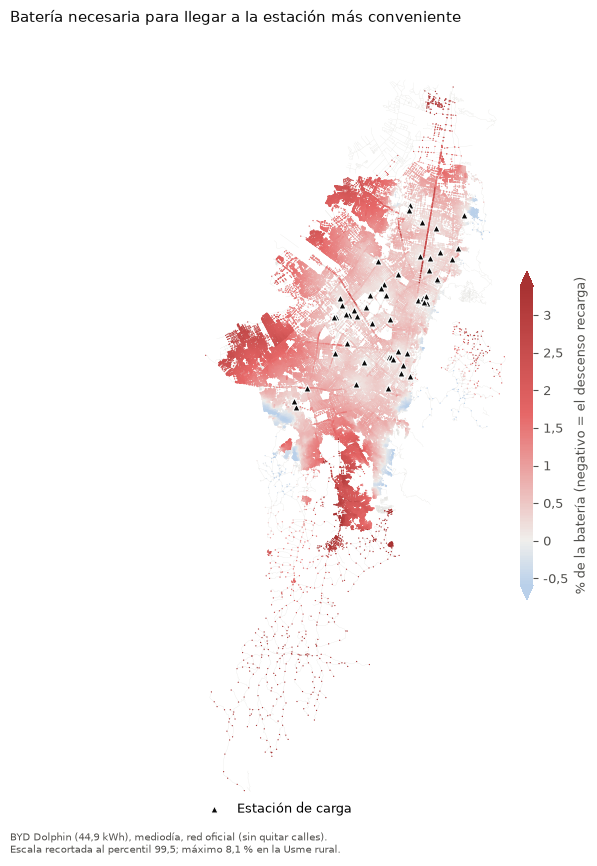

  [figura escrita] D4_fig2_mapa_volver_menos_llegar_v3.png


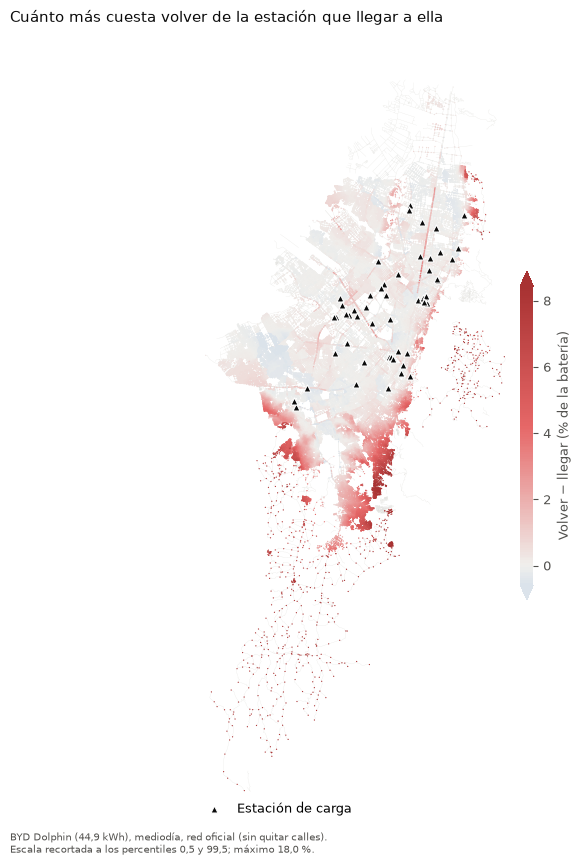

  [figura escrita] D4_fig3_llegar_vs_volver_por_localidad_v2.png


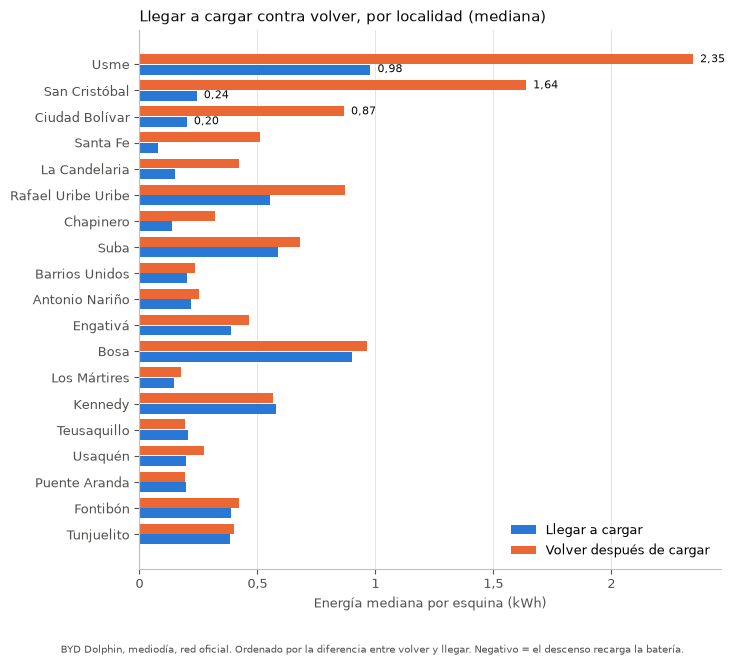

  [figura escrita] D4_fig4_peor_esquina_por_carro_v2.png


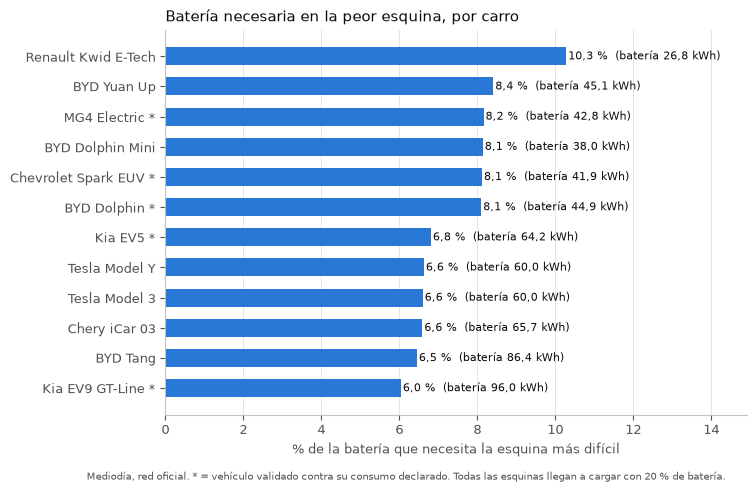

  [figura escrita] D4_fig5_ahorro_ruta_eficiente_v2.png


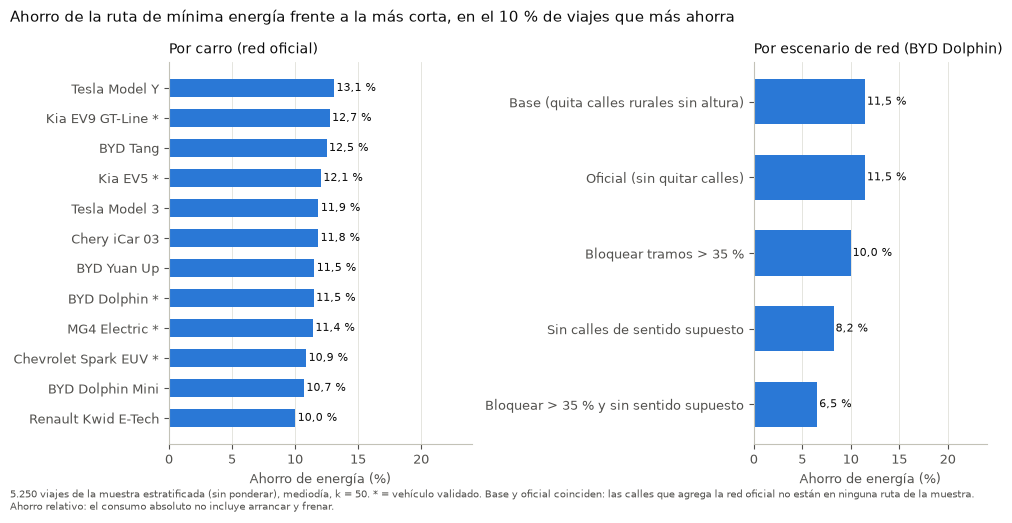

In [29]:
# =============================================================================
# CELDA 17: FIGURAS PARA LA TESIS (lee todo de disco; no recalcula nada)
# Dolphin, mediodia, escenario oficial. Cada figura comprueba sus numeros
# contra las tablas resumen antes de guardarse. Escribe en D4/figuras/ y no
# sobrescribe. v2: escalas ajustadas a los datos, tildes, nombres de carros,
# coma decimal, menos espacio en blanco.
# =============================================================================
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.ticker import FuncFormatter
import constantes_d1 as K

PROP, VEH0, HORA0 = K.ESCENARIO_OFICIAL_D4, K.VEHICULO_BASE_D4, K.HORA_BASE_D4
E = K.RUTA_ENTREGABLES / "D4"
FIG, VERSION = "D4/figuras", "v2"

# Paleta (validada): azul y naranja para 2 series; divergente azul-gris-rojo
AZUL, NARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA2, EJE, REJILLA = "#0b0b0b", "#52514e", "#c3c2b7", "#e1e0d9"
DIVERGENTE = LinearSegmentedColormap.from_list(
    "azul_gris_rojo", ["#104281", "#5598e7", "#f0efec", "#e66767", "#a83232"])
plt.rcParams.update({"font.family": "sans-serif", "font.size": 9,
                     "axes.edgecolor": EJE, "axes.labelcolor": TINTA2,
                     "xtick.color": TINTA2, "ytick.color": TINTA2,
                     "axes.spines.top": False, "axes.spines.right": False})

def coma(x, decimales=1):
    """Numero con coma decimal (espanol)."""
    return f"{x:.{decimales}f}".replace(".", ",")

FMT_COMA = FuncFormatter(lambda x, _: f"{x:g}".replace(".", ","))

LOCALIDADES = {"USAQUEN": "Usaquén", "CHAPINERO": "Chapinero", "SANTA FE": "Santa Fe",
               "SAN CRISTOBAL": "San Cristóbal", "USME": "Usme", "TUNJUELITO": "Tunjuelito",
               "BOSA": "Bosa", "KENNEDY": "Kennedy", "FONTIBON": "Fontibón",
               "ENGATIVA": "Engativá", "SUBA": "Suba", "BARRIOS UNIDOS": "Barrios Unidos",
               "TEUSAQUILLO": "Teusaquillo", "LOS MARTIRES": "Los Mártires",
               "ANTONIO NARIÑO": "Antonio Nariño", "PUENTE ARANDA": "Puente Aranda",
               "CANDELARIA": "La Candelaria", "RAFAEL URIBE URIBE": "Rafael Uribe Uribe",
               "CIUDAD BOLIVAR": "Ciudad Bolívar"}

CARROS = {"byd_dolphin_449": "BYD Dolphin", "byd_seagull_dolphin_mini": "BYD Dolphin Mini",
          "byd_tang_gs": "BYD Tang", "byd_yuan_up": "BYD Yuan Up",
          "chery_icar_03": "Chery iCar 03", "chevrolet_spark_euv": "Chevrolet Spark EUV",
          "kia_ev5_light": "Kia EV5", "kia_ev9_gtline": "Kia EV9 GT-Line",
          "mg4_electric_urban": "MG4 Electric", "renault_kwid_etech": "Renault Kwid E-Tech",
          "tesla_model_3_rwd": "Tesla Model 3", "tesla_model_y_rwd": "Tesla Model Y"}

def etiqueta_carro(v, validado):
    return CARROS.get(v, v) + (" *" if validado else "")

def guardar_figura(fig, nombre, version=VERSION):
    nombre = nombre.replace(".png", f"_{version}.png")
    ruta = K.ruta_entregable(FIG, nombre)
    if ruta.exists():
        print(f"  [figura ya existe, no se reescribe] {nombre}")
    else:
        fig.savefig(ruta, dpi=200, bbox_inches="tight", facecolor="white")
        print(f"  [figura escrita] {nombre}")
    plt.show()

# --- Lectura de disco -------------------------------------------------------------
import json
_KP = json.loads((E / "elegir_k" / "D4_k_adoptado.json").read_text(encoding="utf-8"))["k_corridas"]
_carp = (E / "alcanzabilidad" / f"esc_{PROP}__{VEH0}__h{HORA0:g}__{K.PENDIENTE_CONSUMO_D4}"
         f"__{'con' if K.CAPA_PARADAS_D4 else 'sin'}_paradas__k{_KP:g}")
ALC = pd.read_csv(_carp / "D4_alcanzabilidad_esquinas.csv", dtype={"nodo": "string"})
LLS = pd.read_csv(E / "alcanzabilidad" / "extra" / "D4_llegar_vs_salir_esquinas.csv",
                  dtype={"nodo": "string"})
PLOC = pd.read_csv(E / "alcanzabilidad" / "extra" / "D4_llegar_vs_salir_por_localidad.csv")
RALC = pd.read_csv(E / "alcanzabilidad" / "D4_resumen_alcanzabilidad.csv")
RENE = pd.read_csv(E / "energia" / "D4_resumen_energia_v2.csv")
XY = (pd.read_csv(E / "alturas_esquinas" / "D4_alturas_esquinas.csv",
                  dtype={"nodo": "string"}, usecols=["nodo", "x", "y"]).set_index("nodo"))
ESTF = pd.read_csv(E / "estaciones" / "D4_estaciones_enganche.csv",
                   dtype={f"nodo_{PROP}": "string"})
_gp = K.RUTA_ENTREGABLES / "D3" / f"rama_{K.RAMA_OFICIAL}" / f"D3_grafo_con_pendiente_{K.RAMA_OFICIAL}.gpkg"
CALLES = (gpd.read_file(_gp, layer="grafo", columns=["id_eje", "parte"])
          .drop_duplicates(["id_eje", "parte"]))
CAP = float(RALC.loc[(RALC["escenario"] == PROP) & (RALC["vehiculo"] == VEH0), "bateria_kwh"].iat[0])
print(f"Esquinas: {len(ALC):,}   calles fisicas: {len(CALLES):,}   bateria: {CAP} kWh")

# --- Pruebas: los archivos dicen lo mismo entre si (segundo camino) ---------------
pr_17 = []
_r = RALC[(RALC["escenario"] == PROP) & (RALC["vehiculo"] == VEH0)].iloc[0]
pr_17.append(("peor esquina = resumen de alcanzabilidad",
              np.isclose(round(ALC["pct_bateria"].max(), 2), _r["pct_bateria_max"], atol=0.006)))
_m = ALC.merge(LLS, on="nodo", validate="one_to_one")
pr_17.append(("llegar (15b) = energia de la celda 15, esquina por esquina",
              bool(len(_m) == len(ALC) and np.allclose(_m["energia_kwh"], _m["energia_llegar_kwh"],
                                                       rtol=1e-6, atol=1e-6))))
pr_17.append(("toda esquina tiene coordenadas", bool(ALC["nodo"].isin(XY.index).all())))
pr_17.append(("toda estacion esta en una esquina de la red",
              bool(ESTF[f"nodo_{PROP}"].isin(set(ALC["nodo"])).all())))
_loc_falta = sorted(set(PLOC["localidad"].dropna()) - set(LOCALIDADES))
pr_17.append(("toda localidad tiene su nombre con tildes", not _loc_falta))
_car_falta = sorted(set(RALC["vehiculo"]) - set(CARROS))
pr_17.append(("todo carro tiene su nombre", not _car_falta))
_df = pd.DataFrame(pr_17, columns=["prueba", "pasa"])
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), (f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()} "
                           f"localidades: {_loc_falta} carros: {_car_falta}")

_xy = XY.loc[ALC["nodo"]]
_est_xy = XY.loc[ESTF[f"nodo_{PROP}"].unique()]

def mapa(valores, titulo, etiqueta, nota, nombre):
    """Mapa de esquinas. La escala se ajusta a los datos (percentiles 0,5 y 99,5):
    si casi no hay negativos, el lado azul se achica en vez de quedar vacio."""
    v = np.asarray(valores, float)
    alto = np.percentile(v, 99.5)
    bajo = min(np.percentile(v, 0.5), 0.0)
    # Escala HONESTA: un punto porcentual cambia el color lo mismo hacia los dos
    # lados (como una escala simetrica de -M a +M), pero la paleta se recorta al
    # rango que existe en los datos. Asi lo casi nulo se ve gris, no azul fuerte.
    M = max(alto, -bajo)
    f0 = (bajo + M) / (2 * M)                         # donde empieza 'bajo' en la paleta simetrica
    f1 = (alto + M) / (2 * M)                         # donde termina 'alto' (1 si alto >= -bajo)
    cmap = LinearSegmentedColormap.from_list("recortada", DIVERGENTE(np.linspace(f0, f1, 256)))
    norm = Normalize(vmin=bajo, vmax=alto)
    orden = np.argsort(np.abs(v))                    # los extremos se dibujan encima
    fig, ax = plt.subplots(figsize=(6.2, 8.6))
    CALLES.plot(ax=ax, color="#d9d8d2", linewidth=0.12, zorder=1)
    sc = ax.scatter(_xy["x"].to_numpy()[orden], _xy["y"].to_numpy()[orden], c=v[orden],
                    s=0.8, cmap=cmap, norm=norm, linewidths=0, zorder=2)
    ax.scatter(_est_xy["x"], _est_xy["y"], s=26, marker="^", facecolor=TINTA,
               edgecolor="white", linewidth=0.8, zorder=3, label="Estación de carga")
    cb = fig.colorbar(sc, ax=ax, shrink=0.42, pad=0.0, aspect=25,
                      extend="both" if bajo < 0 else "max")
    cb.set_label(etiqueta, color=TINTA2); cb.outline.set_visible(False)
    cb.ax.yaxis.set_major_formatter(FMT_COMA)
    ax.legend(loc="lower left", frameon=False, borderaxespad=0.5)
    ax.set_axis_off(); ax.set_aspect("equal")
    fig.suptitle(titulo, x=0.02, y=0.99, ha="left", fontsize=11, color=TINTA)
    fig.text(0.02, 0.01, nota, fontsize=7, color=TINTA2, wrap=True)
    fig.subplots_adjust(left=0.01, right=0.99, top=0.95, bottom=0.04)
    guardar_figura(fig, nombre, version="v3")

_base_nota = f"BYD Dolphin ({coma(CAP)} kWh), mediodía, red oficial (sin quitar calles)."

# --- Figura 1: bateria para llegar a cargar ---------------------------------------
_pmax = ALC["pct_bateria"].max()
mapa(ALC["pct_bateria"],
     "Batería necesaria para llegar a la estación más conveniente",
     "% de la batería (negativo = el descenso recarga)",
     _base_nota + f"\nEscala recortada al percentil 99,5; máximo {coma(_pmax)} % en la Usme rural.",
     "D4_fig1_mapa_llegar_a_cargar.png")

# --- Figura 2: cuanto mas cuesta volver que ir --------------------------------------
_dif = 100 * _m["diferencia_kwh"].to_numpy() / CAP
mapa(_dif,
     "Cuánto más cuesta volver de la estación que llegar a ella",
     "Volver − llegar (% de la batería)",
     _base_nota + f"\nEscala recortada a los percentiles 0,5 y 99,5; máximo {coma(_dif.max())} %.",
     "D4_fig2_mapa_volver_menos_llegar.png")

# --- Figura 3: llegar vs volver por localidad --------------------------------------
P = PLOC.dropna(subset=["localidad"]).sort_values("diferencia_mediana_kwh").reset_index(drop=True)
assert len(P) == 19, f"Se esperaban 19 localidades, hay {len(P)}"
fig, ax = plt.subplots(figsize=(7.5, 7))
yy = np.arange(len(P)); h = 0.38
ax.barh(yy - h / 2 - 0.01, P["llegar_mediana_kwh"], height=h, color=AZUL, label="Llegar a cargar")
ax.barh(yy + h / 2 + 0.01, P["volver_mediana_kwh"], height=h, color=NARANJA, label="Volver después de cargar")
ax.set_yticks(yy, [LOCALIDADES[s] for s in P["localidad"]])
ax.axvline(0, color=EJE, linewidth=0.8)
ax.xaxis.grid(True, color=REJILLA, linewidth=0.6); ax.set_axisbelow(True)
ax.xaxis.set_major_formatter(FMT_COMA)
ax.set_xlabel("Energía mediana por esquina (kWh)")
for i in P.index[-3:]:                              # rotulos solo en las 3 mas desiguales
    ax.text(P.at[i, "volver_mediana_kwh"] + 0.03, i + h / 2, coma(P.at[i, "volver_mediana_kwh"], 2),
            va="center", fontsize=8, color=TINTA)
    ax.text(max(P.at[i, "llegar_mediana_kwh"], 0) + 0.03, i - h / 2,
            coma(P.at[i, "llegar_mediana_kwh"], 2), va="center", fontsize=8, color=TINTA)
ax.legend(loc="lower right", frameon=False)
ax.set_title("Llegar a cargar contra volver, por localidad (mediana)", loc="left",
             fontsize=11, color=TINTA)
fig.text(0.02, -0.01, "BYD Dolphin, mediodía, red oficial. Ordenado por la diferencia "
         "entre volver y llegar. Negativo = el descenso recarga la batería.",
         fontsize=7, color=TINTA2)
guardar_figura(fig, "D4_fig3_llegar_vs_volver_por_localidad.png")

# --- Figura 4: peor esquina por carro -----------------------------------------------
V = RALC[RALC["escenario"] == PROP].sort_values("pct_bateria_max").reset_index(drop=True)
assert len(V) == 12, f"Se esperaban 12 carros, hay {len(V)}"
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(V.index, V["pct_bateria_max"], height=0.6, color=AZUL)
ax.set_yticks(V.index, [etiqueta_carro(v, ok) for v, ok in zip(V["vehiculo"], V["validado"])])
for i, (p, b) in enumerate(zip(V["pct_bateria_max"], V["bateria_kwh"])):
    ax.text(p + 0.05, i, f"{coma(p)} %  (batería {coma(b)} kWh)", va="center", fontsize=8, color=TINTA)
ax.xaxis.grid(True, color=REJILLA, linewidth=0.6); ax.set_axisbelow(True)
ax.xaxis.set_major_formatter(FMT_COMA)
ax.set_xlim(0, V["pct_bateria_max"].max() * 1.45)
ax.set_xlabel("% de la batería que necesita la esquina más difícil")
ax.set_title("Batería necesaria en la peor esquina, por carro", loc="left", fontsize=11, color=TINTA)
fig.text(0.02, -0.02, "Mediodía, red oficial. * = vehículo validado contra su consumo declarado. "
         "Todas las esquinas llegan a cargar con 20 % de batería.", fontsize=7, color=TINTA2)
guardar_figura(fig, "D4_fig4_peor_esquina_por_carro.png")

# --- Figura 5: ahorro de la ruta eficiente ------------------------------------------
RENE = RENE[(RENE["pendiente"] == K.PENDIENTE_CONSUMO_D4)
            & (RENE["paradas"].astype(str) == str(bool(K.CAPA_PARADAS_D4)))
            & np.isclose(RENE["k"], _KP)]
A = (RENE[(RENE["escenario"] == PROP) & (RENE["hora"] == HORA0)]
     .sort_values("ahorro_p90_pct").reset_index(drop=True))
S = (RENE[(RENE["vehiculo"] == VEH0) & (RENE["hora"] == HORA0)]
     .drop_duplicates("escenario").sort_values("ahorro_p90_pct").reset_index(drop=True))
assert len(A) == 12 and len(S) == 5, f"Carros {len(A)}, escenarios {len(S)}"
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw={"width_ratios": [1.3, 1]})
a1.barh(A.index, A["ahorro_p90_pct"], height=0.6, color=AZUL)
a1.set_yticks(A.index, [etiqueta_carro(v, ok) for v, ok in zip(A["vehiculo"], A["validado"])])
for i, p in enumerate(A["ahorro_p90_pct"]):
    a1.text(p + 0.2, i, f"{coma(p)} %", va="center", fontsize=8, color=TINTA)
a1.set_title("Por carro (red oficial)", loc="left", fontsize=10, color=TINTA)
_nom_esc = {"base": "Base (quita calles rurales sin altura)",
            "sens_sin_altura_A": "Oficial (sin quitar calles)",
            "sens_bloquear_extremas": "Bloquear tramos > 35 %",
            "sens_sin_SDN": "Sin calles de sentido supuesto",
            "sens_bloquear_y_sin_SDN": "Bloquear > 35 % y sin sentido supuesto"}
a2.barh(S.index, S["ahorro_p90_pct"], height=0.6, color=AZUL)
a2.set_yticks(S.index, [_nom_esc.get(e, e) for e in S["escenario"]])
for i, p in enumerate(S["ahorro_p90_pct"]):
    a2.text(p + 0.2, i, f"{coma(p)} %", va="center", fontsize=8, color=TINTA)
a2.set_title("Por escenario de red (BYD Dolphin)", loc="left", fontsize=10, color=TINTA)
for a in (a1, a2):
    a.xaxis.grid(True, color=REJILLA, linewidth=0.6); a.set_axisbelow(True)
    a.xaxis.set_major_formatter(FMT_COMA)
    a.set_xlim(0, 24); a.set_xlabel("Ahorro de energía (%)")
fig.suptitle("Ahorro de la ruta de mínima energía frente a la más corta, "
             "en el 10 % de viajes que más ahorra", x=0.01, ha="left", fontsize=11, color=TINTA)
fig.text(0.01, -0.02, "5.250 viajes de la muestra estratificada (sin ponderar), mediodía, k = 50. * = vehículo validado. Base y oficial "
         "coinciden: las calles que agrega la red oficial no están en ninguna ruta de la muestra.\n"
         "Ahorro relativo: el consumo absoluto no incluye arrancar y frenar.",
         fontsize=7, color=TINTA2)
fig.tight_layout()
guardar_figura(fig, "D4_fig5_ahorro_ruta_eficiente.png")

In [30]:
# =============================================================================
# CELDA 18: ENTORNO DE EJECUCION (reproducibilidad)
# Registra Python y las versiones exactas de las librerias que usa D4.
# Escribe en entregables/D4/ sin sobrescribir. No depende de otras celdas.
# =============================================================================
import sys, platform, subprocess, hashlib, json, importlib
from importlib.metadata import version, PackageNotFoundError
import constantes_d1 as K

# Librerias que D4 importa directamente (nombre en pip -> nombre del modulo)
DIRECTAS = {"numpy": "numpy", "pandas": "pandas", "geopandas": "geopandas",
            "shapely": "shapely", "pyproj": "pyproj", "pyogrio": "pyogrio",
            "scipy": "scipy", "networkx": "networkx", "matplotlib": "matplotlib",
            "folium": "folium"}

def _sin_sobrescribir(texto, ruta):
    contenido = texto.encode("utf-8")
    nuevo = hashlib.sha256(contenido).hexdigest()
    if ruta.exists():
        viejo = hashlib.sha256(ruta.read_bytes()).hexdigest()
        if viejo == nuevo:
            print(f"  [ya existe, identico] {ruta.name}")
            return nuevo
        raise FileExistsError(f"{ruta.name} ya existe con OTRO contenido: el entorno "
                              "cambio desde la ultima vez. No se reescribe.")
    ruta.write_bytes(contenido)
    print(f"  [escrito] {ruta.name}  sha {nuevo[:12]}...")
    return nuevo

# --- 1. Versiones de las librerias directas ----------------------------------------
filas, faltan = [], []
for pip_nombre, modulo in DIRECTAS.items():
    try:
        v_pip = version(pip_nombre)
    except PackageNotFoundError:
        faltan.append(pip_nombre)
        continue
    # Segundo camino: la version que reporta el propio modulo cargado
    try:
        v_mod = getattr(importlib.import_module(modulo), "__version__", None)
    except ImportError:
        v_mod = None
    filas.append((pip_nombre, v_pip, v_mod))

print(f"Python {platform.python_version()} ({platform.system()} {platform.release()})\n")
print(f"{'libreria':<12} {'instalada':<12} {'modulo cargado':<14} coincide")
for n, vp, vm in filas:
    ok = "si" if vm is None or vm == vp else "NO"
    print(f"{n:<12} {vp:<12} {str(vm):<14} {ok}")
if faltan:
    print(f"\nNo instaladas (D4 no las necesita o usa otra): {faltan}")
_mal = [n for n, vp, vm in filas if vm is not None and vm != vp]
assert not _mal, f"Version instalada distinta de la cargada en: {_mal}. Reinicie el kernel."

texto_req = (
    f"# D4 — Grafo listo para ruteo. Librerias usadas directamente.\n"
    f"# Python {platform.python_version()} — {platform.system()} {platform.release()}\n"
    f"# Instalar con: pip install -r requirements_D4.txt\n"
    + "".join(f"{n}=={vp}\n" for n, vp, _ in filas))

# --- 2. Entorno completo (respaldo) --------------------------------------------------
_freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"],
                         capture_output=True, text=True, check=True).stdout
texto_freeze = (f"# Entorno completo al ejecutar D4. Python {platform.python_version()}\n"
                f"# {sys.executable}\n" + _freeze)

# Segundo camino: cada libreria directa aparece en el entorno completo con la misma version
_fz = {l.split("==")[0].lower(): l.split("==")[1] for l in _freeze.splitlines() if "==" in l}
_no_cuadra = [n for n, vp, _ in filas if _fz.get(n.lower()) not in (None, vp)]
assert not _no_cuadra, f"pip freeze y la version instalada no cuadran en: {_no_cuadra}"
_sin_freeze = [n for n, _, _ in filas if n.lower() not in _fz]
if _sin_freeze:
    print(f"\nAviso: {_sin_freeze} no salen en 'pip freeze' (instaladas con conda); "
          "su version queda registrada igual en requirements_D4.txt")

# --- 3. Salidas (sin sobrescribir) ---------------------------------------------------
_sha_req = _sin_sobrescribir(texto_req, K.ruta_entregable("D4", "requirements_D4.txt"))
_sha_fz = _sin_sobrescribir(texto_freeze, K.ruta_entregable("D4", "entorno_completo_D4.txt"))
print("\n" + texto_req)

Python 3.12.14 (Windows 11)

libreria     instalada    modulo cargado coincide
numpy        2.5.2        2.5.2          si
pandas       3.0.5        3.0.5          si
geopandas    1.1.4        1.1.4          si
shapely      2.1.2        2.1.2          si
pyproj       3.7.2        3.7.2          si
pyogrio      0.13.0       0.13.0         si
scipy        1.18.1       1.18.1         si
networkx     3.6.1        3.6.1          si
matplotlib   3.11.0       3.11.0         si
folium       0.20.0       0.20.0         si

Aviso: ['numpy'] no salen en 'pip freeze' (instaladas con conda); su version queda registrada igual en requirements_D4.txt
  [escrito] requirements_D4.txt  sha 8e1f6f8b890c...
  [escrito] entorno_completo_D4.txt  sha 3c0affca0ffe...

# D4 — Grafo listo para ruteo. Librerias usadas directamente.
# Python 3.12.14 — Windows 11
# Instalar con: pip install -r requirements_D4.txt
numpy==2.5.2
pandas==3.0.5
geopandas==1.1.4
shapely==2.1.2
pyproj==3.7.2
pyogrio==0.13.0
scipy==1.18.1


Red: 214,837 tramos, 87,752 esquinas
  origen  1/10: 12 s
  origen  2/10: 28 s
  origen  3/10: 42 s
  origen  4/10: 54 s
  origen  5/10: 73 s
  origen  6/10: 83 s
  origen  7/10: 98 s
  origen  8/10: 111 s
  origen  9/10: 122 s
  origen 10/10: 133 s

PRUEBA 1 — misma energia con un algoritmo y una libreria distintos
 par  energia_D4_kwh  energia_networkx_kwh  dif_Wh
5100         4.80555               4.80554  -0.008
4578         2.06173               2.06172  -0.007
3198         2.51016               2.51017   0.010
2670         0.73552               0.73552   0.002
4158         2.00800               2.00800   0.001
 405         0.86179               0.86179   0.001
4330         1.32860               1.32860  -0.003
4405         0.96409               0.96410   0.005
5046         2.77899               2.77900   0.006
4390         2.16689               2.16688  -0.002

PRUEBA 2 — fisica de ida y vuelta (877,510 parejas)
  asimetria = 7.765 Wh por metro de desnivel  (R² = 0.971)
  rango f

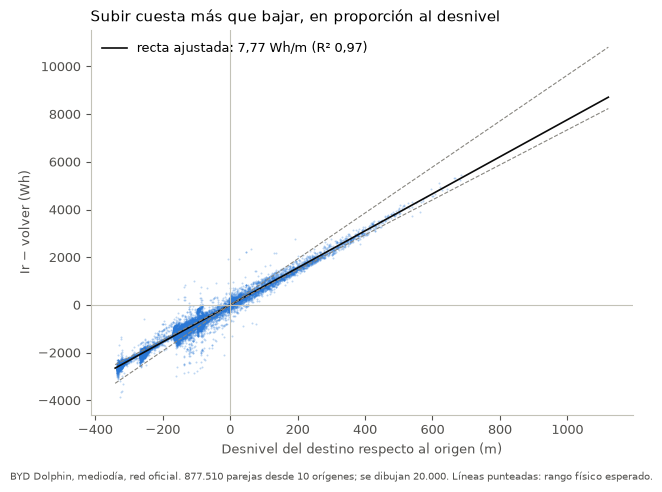

  [escrito] D4_validacion_bellman_ford_networkx.csv
  [escrito] D4_validacion_ruteo_pruebas.csv


In [31]:
# =============================================================================
# CELDA 19: VALIDACION INDEPENDIENTE DEL RUTEO POR ENERGIA (solo lee de disco)
# Prueba 1: networkx + Bellman-Ford puro (sin alturas de energia, sin Johnson)
#           debe dar las mismas energias minimas que guardo D4.
# Prueba 2: fisica de ida y vuelta: A->B->A nunca genera energia; subir cuesta
#           mas que bajar; la asimetria crece con el desnivel.
# Dolphin, mediodia, escenario oficial. Escribe solo en D4/validacion_ruteo/.
# =============================================================================
import time, hashlib, json
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import constantes_d1 as K
from d1_procedencia import sha256_archivo

PROP, VEH0, HORA0 = K.ESCENARIO_OFICIAL_D4, K.VEHICULO_BASE_D4, K.HORA_BASE_D4
E = K.RUTA_ENTREGABLES / "D4"
N_ORIGENES = 10                      # origenes con Bellman-Ford completo (cada uno: toda la red)
rng19 = np.random.default_rng(K.SEMILLA_OD_D4)

# --- Lectura de disco ----------------------------------------------------------------
_KP = json.loads((E / "elegir_k" / "D4_k_adoptado.json").read_text(encoding="utf-8"))["k_corridas"]
_tag = (f"esc_{PROP}__{VEH0}__h{HORA0:g}__{K.PENDIENTE_CONSUMO_D4}__long_{K.LONGITUD_CONSUMO_D4}"
        f"__{'con' if K.CAPA_PARADAS_D4 else 'sin'}_paradas__k{_KP:g}")
_dE = E / "energia" / _tag
PES = pd.read_csv(_dE / "D4_pesos_energia.csv", dtype={"segmento_id": "string"})
CMP = pd.read_csv(_dE / "D4_comparacion_rutas.csv", dtype={"tramos_eficiente": "string"})
ARI = pd.read_csv(E / f"esc_{PROP}" / f"D4_aristas_{PROP}.csv",
                  dtype={"segmento_id": "string", "u": "string", "v": "string"},
                  usecols=["segmento_id", "u", "v", "en_red"], low_memory=False)
ARI = ARI[ARI["en_red"].astype(str) == "True"]
RD = pd.read_csv(E / f"esc_{PROP}" / f"D4_rutas_distancia_{PROP}.csv",
                 dtype={"origen": "string", "destino": "string"}, usecols=["origen", "destino"])
Z = (pd.read_csv(E / "alturas_esquinas" / "D4_alturas_esquinas.csv",
                 dtype={"nodo": "string"}, usecols=["nodo", "z_m"]).set_index("nodo")["z_m"])
assert len(RD) == len(CMP), "Muestra de pares y comparacion no tienen el mismo largo"
T = ARI.merge(PES[["segmento_id", "consumo_kwh", "peso_ruteo_kwh"]], on="segmento_id",
              validate="one_to_one")
assert len(T) == len(ARI), "Hay tramos de la red sin peso de energia"
print(f"Red: {len(T):,} tramos, {T[['u','v']].stack().nunique():,} esquinas")

# Grafo independiente: entre dos esquinas con varias calles, la mas barata
_m = T.groupby(["u", "v"], as_index=False)["consumo_kwh"].min()
G = nx.DiGraph()
G.add_weighted_edges_from(zip(_m["u"], _m["v"], _m["consumo_kwh"]), weight="w")
GR = G.reverse(copy=False)
# La prueba 1 compara la RUTA ELEGIDA: con el peso de ruteo (castigo k). La prueba 2
# (fisica de ida y vuelta) sigue con la energia real.
_mr = T.groupby(["u", "v"], as_index=False)["peso_ruteo_kwh"].min()
G_RT = nx.DiGraph()
G_RT.add_weighted_edges_from(zip(_mr["u"], _mr["v"], _mr["peso_ruteo_kwh"]), weight="w")
pr_19 = []

# --- Segundo camino previo: energia de cada ruta guardada = suma de sus tramos -------
_W = PES.set_index("segmento_id")["consumo_kwh"]
_suma = np.array([_W.loc[t.split(";")].sum() for t in CMP["tramos_eficiente"]])
_d0 = float(np.max(np.abs(_suma - CMP["energia_eficiente_kwh"])))
pr_19.append({"prueba": "energia guardada = suma de los pesos de sus tramos (5.000 rutas)",
              "dif_max_kWh": _d0, "pasa": _d0 < 5e-4})

# --- PRUEBA 1: Bellman-Ford puro (networkx) vs lo que guardo D4 -----------------------
_idx = rng19.choice(len(RD), size=N_ORIGENES, replace=False)
filas1, IDA, VUELTA, t0 = [], {}, {}, time.time()
for k in _idx:
    o, d = RD.at[k, "origen"], RD.at[k, "destino"]
    ida = nx.single_source_bellman_ford_path_length(G, o, weight="w")      # o -> todas
    vuelta = nx.single_source_bellman_ford_path_length(GR, o, weight="w")  # todas -> o
    IDA[o], VUELTA[o] = ida, vuelta
    ida_rt = ida if _KP == 0 else nx.single_source_bellman_ford_path_length(G_RT, o, weight="w")
    filas1.append({"par": int(CMP.at[k, "par"]), "origen": o, "destino": d,
                   "energia_D4_kwh": float(CMP.at[k, "costo_ruteo_eficiente_kwh"]),
                   "energia_networkx_kwh": float(ida_rt[d])})
    print(f"  origen {len(filas1):>2}/{N_ORIGENES}: {time.time() - t0:,.0f} s")
P1 = pd.DataFrame(filas1)
P1["dif_Wh"] = 1000 * (P1["energia_networkx_kwh"] - P1["energia_D4_kwh"])
_d1 = float(P1["dif_Wh"].abs().max())
pr_19.append({"prueba": f"Bellman-Ford puro (networkx) = energia de D4 ({N_ORIGENES} pares)",
              "dif_max_Wh": _d1, "pasa": _d1 < 0.5})
print("\nPRUEBA 1 — misma energia con un algoritmo y una libreria distintos")
print(P1[["par", "energia_D4_kwh", "energia_networkx_kwh", "dif_Wh"]].round(5).to_string(index=False))

# --- PRUEBA 2: fisica de ida y vuelta (todas las esquinas, desde cada origen) --------
f = []
for o in IDA:
    comunes = [v for v in IDA[o] if v in VUELTA[o] and v != o]
    a = np.array([IDA[o][v] for v in comunes]); b = np.array([VUELTA[o][v] for v in comunes])
    dz = Z.reindex(comunes).to_numpy() - Z.get(o, np.nan)
    f.append(pd.DataFrame({"origen": o, "destino": comunes, "ida_kwh": a, "vuelta_kwh": b, "dz_m": dz}))
P2 = pd.concat(f, ignore_index=True).dropna(subset=["dz_m"])
P2["vuelta_completa_kwh"] = P2["ida_kwh"] + P2["vuelta_kwh"]
P2["asimetria_kwh"] = P2["ida_kwh"] - P2["vuelta_kwh"]          # ir (o->v) menos volver (v->o)

# a) Teorema: dar la vuelta A -> B -> A nunca genera energia
_neg = int((P2["vuelta_completa_kwh"] <= 0).sum())
pr_19.append({"prueba": "ir y volver nunca genera energia (todas las parejas)",
              "parejas": len(P2), "negativas": _neg, "pasa": _neg == 0})
# b) Subir cuesta mas que bajar: con mas de 20 m de desnivel, la asimetria tiene el signo del desnivel
_g = P2[P2["dz_m"].abs() > 20]
_sig = float(100 * (np.sign(_g["asimetria_kwh"]) == np.sign(_g["dz_m"])).mean())
pr_19.append({"prueba": "con > 20 m de desnivel, subir cuesta mas que bajar",
              "parejas": len(_g), "pct_cumple": round(_sig, 3), "pasa": _sig > 99.0})
# c) La asimetria crece con el desnivel: recta y comparacion con la fisica
pend, inter = np.polyfit(P2["dz_m"], P2["asimetria_kwh"], 1)
r2 = float(np.corrcoef(P2["dz_m"], P2["asimetria_kwh"])[0, 1] ** 2)
import sys
if str(K.CARPETA_MODELO_CONSUMO) not in sys.path:      # los modulos del modelo de consumo viven en su carpeta
    sys.path.insert(0, str(K.CARPETA_MODELO_CONSUMO))
import vehiculos_flota as VF, parametros as PAR
_p = VF.vehiculo(VEH0)
_mg = _p.m_ensayo * PAR.G / 3.6e6                                 # kWh por metro de subida (sin perdidas)
lim_bajo = _mg * (1 / _p.eta_traccion + _p.frac_regen * _p.eta_regen)
lim_alto = _mg * 2 / _p.eta_traccion
print(f"\nPRUEBA 2 — fisica de ida y vuelta ({len(P2):,} parejas)")
print(f"  asimetria = {1000 * pend:.3f} Wh por metro de desnivel  (R² = {r2:.3f})")
print(f"  rango fisico esperado: {1000 * lim_bajo:.3f} a {1000 * lim_alto:.3f} Wh/m "
      "(bajadas con regeneracion ... bajadas suaves sin regenerar)")
pr_19.append({"prueba": "la asimetria crece con el desnivel (R² > 0,9)",
              "R2": round(r2, 4), "pasa": r2 > 0.9})
pr_19.append({"prueba": "pendiente de la recta dentro del rango fisico",
              "Wh_por_m": round(1000 * pend, 4), "pasa": bool(lim_bajo * 0.95 <= pend <= lim_alto * 1.05)})

_df = pd.DataFrame(pr_19)
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("\nVALIDACION INDEPENDIENTE DEL RUTEO")
print(_df[["prueba", "resultado"]].to_string(index=False))

# --- Figura de la prueba 2 -----------------------------------------------------------
_s = P2.sample(min(20000, len(P2)), random_state=1)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(_s["dz_m"], 1000 * _s["asimetria_kwh"], s=2, alpha=0.3, color="#2a78d6", linewidths=0)
_x = np.array([P2["dz_m"].min(), P2["dz_m"].max()])
ax.plot(_x, 1000 * (pend * _x + inter), color="#0b0b0b", linewidth=1.2,
        label=f"recta ajustada: {1000 * pend:.2f} Wh/m (R² {r2:.2f})".replace(".", ","))
for lim, txt in ((lim_bajo, "límite físico inferior"), (lim_alto, "límite físico superior")):
    ax.plot(_x, 1000 * lim * _x, color="#898781", linewidth=0.8, linestyle="--")
ax.axhline(0, color="#c3c2b7", linewidth=0.8); ax.axvline(0, color="#c3c2b7", linewidth=0.8)
ax.set_xlabel("Desnivel del destino respecto al origen (m)")
ax.set_ylabel("Ir − volver (Wh)")
ax.set_title("Subir cuesta más que bajar, en proporción al desnivel", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
_n_txt = f"{len(P2):,}".replace(",", ".")          # 877.510 con punto de miles
fig.text(0.01, -0.02, f"BYD Dolphin, mediodía, red oficial. {_n_txt} parejas desde "
         f"{N_ORIGENES} orígenes; se dibujan 20.000. Líneas punteadas: rango físico esperado.",
         fontsize=7, color="#52514e")
_fig = K.ruta_entregable("D4/validacion_ruteo", "D4_fig6_fisica_ida_y_vuelta_v2.png")
if _fig.exists():
    print(f"  [figura ya existe, no se reescribe] {_fig.name}")
else:
    fig.savefig(_fig, dpi=200, bbox_inches="tight", facecolor="white")
    print(f"  [figura escrita] {_fig.name}")
plt.show()

# --- Salidas (sin sobrescribir) -------------------------------------------------------
def _guardar(df, nombre):
    ruta = K.ruta_entregable("D4/validacion_ruteo", nombre)
    b = df.to_csv(index=False, float_format="%.6f", lineterminator="\n").encode("utf-8")
    h = hashlib.sha256(b).hexdigest()
    if ruta.exists():
        assert sha256_archivo(ruta) == h, f"{nombre} ya existe con otro contenido. No se reescribe."
        print(f"  [ya existe, identico] {nombre}")
    else:
        ruta.write_bytes(b); print(f"  [escrito] {nombre}")
_guardar(P1, "D4_validacion_bellman_ford_networkx.csv")
_guardar(_df.drop(columns="resultado"), "D4_validacion_ruteo_pruebas.csv")
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

In [32]:
# =============================================================================
# CELDA 20: AHORRO DE LA RUTA EFICIENTE — dos definiciones (solo lee de disco)
# (a) entre los viajes cuya ruta cambia (columna _si_cambia de la celda 12)
# (b) entre TODOS los viajes (ahorro 0 donde la ruta es la misma)
# =============================================================================
import numpy as np, pandas as pd, constantes_d1 as K
E = K.RUTA_ENTREGABLES / "D4" / "energia"
def ahorros(carpeta):
    c = pd.read_csv(E / carpeta / "D4_comparacion_rutas.csv", usecols=[
        "energia_corta_kwh", "energia_eficiente_kwh", "misma_ruta"])
    pos = c["energia_corta_kwh"] > 0
    a = 100 * (c["energia_corta_kwh"] - c["energia_eficiente_kwh"]) / c["energia_corta_kwh"]
    cambia = (c["misma_ruta"].astype(str) != "True") & pos
    return {"pct_viajes_que_cambian": round(100 * cambia.mean(), 1),
            "p90_solo_los_que_cambian": round(float(np.percentile(a[cambia], 90)), 2),
            "p90_todos_los_viajes": round(float(np.percentile(a[pos].where(cambia[pos], 0), 90)), 2),
            "pct_viajes_ahorro_mayor_5": round(float(100 * (a[pos].where(cambia[pos], 0) > 5).mean()), 1),
            "pct_viajes_ahorro_mayor_10": round(float(100 * (a[pos].where(cambia[pos], 0) > 10).mean()), 1)}
# La celda 12 ya reporta las dos definiciones; aqui se recalculan desde los
# archivos de cada corrida (segundo camino).
R = pd.read_csv(E / "D4_resumen_energia_v2.csv")
filas = []
for _, r in R.iterrows():
    _pa = str(r["paradas"]) == "True"
    tag = (f"esc_{r['escenario']}__{r['vehiculo']}__h{r['hora']:g}__"
           f"{r['pendiente']}__long_{K.LONGITUD_CONSUMO_D4}__{'con' if _pa else 'sin'}_paradas"
           f"__k{r['k']:g}")
    d = ahorros(tag)
    assert np.isclose(d["p90_solo_los_que_cambian"], r["ahorro_p90_si_cambia_pct"], atol=0.01), tag
    assert np.isclose(d["p90_todos_los_viajes"], r["ahorro_p90_pct"], atol=0.01), tag
    assert np.isclose(d["pct_viajes_ahorro_mayor_5"], r["viajes_ahorro_mayor_5pct"], atol=0.06), tag
    assert np.isclose(d["pct_viajes_ahorro_mayor_10"], r["viajes_ahorro_mayor_10pct"], atol=0.06), tag
    filas.append({"escenario": r["escenario"], "vehiculo": r["vehiculo"], "hora": r["hora"],
                  "pendiente": r["pendiente"], "paradas": _pa, "k": r["k"], **d})
print(f"Las cifras de ahorro coinciden con la celda 12 en las {len(filas)} corridas.\n")
import json
_KP = json.loads((K.RUTA_ENTREGABLES / "D4" / "elegir_k" / "D4_k_adoptado.json")
                 .read_text(encoding="utf-8"))["k_corridas"]
A = pd.DataFrame(filas).drop_duplicates(["escenario", "vehiculo", "hora", "pendiente", "paradas", "k"])
A = A[(A["pendiente"] == K.PENDIENTE_CONSUMO_D4) & (A["paradas"] == bool(K.CAPA_PARADAS_D4))
      & np.isclose(A["k"], _KP)].drop(columns=["pendiente", "paradas", "k"])
P = K.ESCENARIO_OFICIAL_D4
print("12 CARROS (escenario oficial, mediodia)")
print(A[(A.escenario == P) & (A.hora == K.HORA_BASE_D4)].set_index("vehiculo").drop(columns=["escenario", "hora"]).to_string())
print("\nDOLPHIN POR ESCENARIO (mediodia)")
print(A[(A.vehiculo == K.VEHICULO_BASE_D4) & (A.hora == K.HORA_BASE_D4)].set_index("escenario").drop(columns=["vehiculo", "hora"]).to_string())

Las cifras de ahorro coinciden con la celda 12 en las 38 corridas.

12 CARROS (escenario oficial, mediodia)
                          pct_viajes_que_cambian  p90_solo_los_que_cambian  p90_todos_los_viajes  pct_viajes_ahorro_mayor_5  pct_viajes_ahorro_mayor_10
vehiculo                                                                                                                                               
byd_dolphin_449                             77.8                     13.34                 11.48                       22.8                        12.0
byd_seagull_dolphin_mini                    77.6                     12.33                 10.71                       21.6                        10.9
byd_tang_gs                                 77.7                     14.55                 12.50                       24.0                        13.3
byd_yuan_up                                 77.8                     13.35                 11.53                       22.8         

In [33]:
# =============================================================================
# CELDA 20b: RESULTADOS POR ESTRATO Y CIFRAS DE TODA LA CIUDAD
# Solo lee de disco. Muestra estratificada: 3 terrenos x 5 bandas, mismo numero
# de pares por casilla. Por eso:
#   - las cifras POR CASILLA salen directas (cada casilla pesa igual dentro de si);
#   - las cifras de TODA LA CIUDAD se ponderan con la columna "peso" de la muestra
#     (fraccion de la ciudad que representa la casilla / pares de la casilla).
# Denominador unico en todo el informe: TODOS los viajes
# validos de la casilla o de la ciudad; si la ruta no cambia, el ahorro es 0.
# Se excluyen (y se cuentan) los viajes cuya ruta corta tiene energia <= 0
# (bajada neta): el porcentaje de ahorro no tiene sentido ahi (detalle en la celda 15f).
# OJO con el castigo k: la ruta de minimo consumo minimiza energia + castigo a
# las calles > 35 %. Si la ruta corta usa una de esas calles, la otra puede
# gastar un poco MAS de energia real para evitarla: ahorro negativo. Es correcto
# y se reporta (columna pct_ahorro_negativo); lo que nunca pasa es que su
# COSTO DE RUTEO supere al de la ruta corta.
# Escribe en entregables/D4/estratos/ sin sobrescribir.
# =============================================================================
import json, hashlib
import numpy as np, pandas as pd
import constantes_d1 as K
import importlib; K = importlib.reload(K)

E = K.RUTA_ENTREGABLES / "D4"
_TER = ["plano", "cruzado", "ladera"]
_BAN = list(K.NOMBRES_BANDA_OD)

def _sha(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""):
            h.update(b)
    return h.hexdigest()

def guardar_sin_sobrescribir(df, ruta):
    ruta.parent.mkdir(parents=True, exist_ok=True)
    txt = df.to_csv(index=False, lineterminator="\n")
    if ruta.exists():
        assert ruta.read_text(encoding="utf-8") == txt, f"{ruta.name} ya existe y es DISTINTO"
        print(f"  {ruta.name}: ya existe, identico")
    else:
        ruta.write_text(txt, encoding="utf-8"); print(f"  [escrito] {ruta.name}")
    return _sha(ruta)

def cuantil_pond(v, w, q):
    """Cuantil con pesos: el menor valor donde el peso acumulado llega a q."""
    o = np.argsort(v, kind="stable"); v, w = np.asarray(v)[o], np.asarray(w)[o]
    c = np.cumsum(w) / w.sum()
    return float(v[np.searchsorted(c, q)])

def indicadores(d, w):
    """d: viajes validos con columnas de la comparacion; w: pesos (1 = sin ponderar)."""
    w = np.asarray(w, float); W = w.sum()
    pct = lambda m: 100 * float(w[np.asarray(m)].sum() / W)
    a, dx = d["ahorro_pct"].to_numpy(), d["dist_extra_pct"].to_numpy()
    i_c = 1e5 * float((w * d["energia_corta_kwh"]).sum() / (w * d["distancia_corta_m"]).sum())
    i_e = 1e5 * float((w * d["energia_eficiente_kwh"]).sum() / (w * d["distancia_eficiente_m"]).sum())
    return {"viajes": len(d),
            "pct_ruta_cambia": round(pct(~d["misma"].to_numpy()), 1),
            "ahorro_mediana_pct": round(cuantil_pond(a, w, .5), 2),
            "ahorro_p90_pct": round(cuantil_pond(a, w, .9), 2),
            "pct_ahorro_mayor_5": round(pct(a > 5), 1),
            "pct_ahorro_mayor_10": round(pct(a > 10), 1),
            "pct_ahorro_negativo": round(pct(a < 0), 1),
            "dist_extra_mediana_pct": round(cuantil_pond(dx, w, .5), 2),
            "dist_extra_p90_pct": round(cuantil_pond(dx, w, .9), 2),
            "intensidad_corta_kwh_100km": round(i_c, 3),
            "intensidad_eficiente_kwh_100km": round(i_e, 3),
            "baja_intensidad_pct": round(100 * (1 - i_e / i_c), 2)}

# --- Muestra de pares (con terreno, banda y peso) --------------------------------
_rm = E / "rutas_distancia" / "D4_muestra_pares_od.csv"
_rc = E / "rutas_distancia" / "D4_muestra_casillas.csv"
OD_ = pd.read_csv(_rm, dtype={"origen": "string", "destino": "string"})
CAS_ = pd.read_csv(_rc)
assert {"terreno", "banda", "peso"} <= set(OD_.columns), "La muestra no es la estratificada"
# El CSV guarda "peso" redondeado (suma ~0,99995). Se recalcula EXACTO desde los
# conteos enteros del sorteo y se comprueba que el del CSV corresponde a su casilla.
_frac = (CAS_.set_index(["terreno", "banda"])["sorteos_en_casilla"]
         / CAS_["sorteos_en_casilla"].sum())
_n = OD_.groupby(["terreno", "banda"]).size()
assert len(_n) == len(CAS_) and (_n == K.N_PARES_POR_CASILLA_D4).all(), "casillas incompletas"
_peso = (_frac / _n).reindex(pd.MultiIndex.from_frame(OD_[["terreno", "banda"]])).to_numpy()
print(f"Peso: suma en el CSV {OD_['peso'].sum():.6f} -> recalculado {_peso.sum():.6f}; "
      f"diferencia maxima por par {np.abs(OD_['peso'].to_numpy() - _peso).max():.1e}")
assert np.isclose(_peso.sum(), 1.0)
assert np.allclose(OD_["peso"], _peso, rtol=0.02, atol=1e-6), "el peso del CSV no corresponde a su casilla"
OD_["peso"] = _peso

def leer_corrida(tag):
    c = pd.read_csv(E / "energia" / tag / "D4_comparacion_rutas.csv",
                    usecols=["par", "distancia_corta_m", "energia_corta_kwh",
                             "distancia_eficiente_m", "energia_eficiente_kwh", "misma_ruta",
                             "costo_ruteo_corta_kwh", "costo_ruteo_eficiente_kwh"])
    assert c["par"].tolist() == OD_["par"].tolist(), f"{tag}: otros pares"
    c = c.merge(OD_[["par", "terreno", "banda", "peso"]], on="par", validate="1:1")
    c["misma"] = c["misma_ruta"].astype(str) == "True"
    valido = c["energia_corta_kwh"] > 0
    c["ahorro_pct"] = np.where(c["misma"], 0.0, 100 * (c["energia_corta_kwh"]
                               - c["energia_eficiente_kwh"]) / c["energia_corta_kwh"])
    c["dist_extra_pct"] = 100 * (c["distancia_eficiente_m"] / c["distancia_corta_m"] - 1)
    return c[valido].reset_index(drop=True), int((~valido).sum())

def tag_de(r):
    pa = str(r["paradas"]) == "True"
    return (f"esc_{r['escenario']}__{r['vehiculo']}__h{r['hora']:g}__{r['pendiente']}"
            f"__long_{K.LONGITUD_CONSUMO_D4}__{'con' if pa else 'sin'}_paradas__k{r['k']:g}")

# --- 1. Cifras de toda la ciudad (ponderadas) para TODAS las corridas -----------
R = pd.read_csv(E / "energia" / "D4_resumen_energia_v2.csv")
filas, pr_t = [], []
for _, r in R.iterrows():
    c, n_excl = leer_corrida(tag_de(r))
    pond, simple = indicadores(c, c["peso"]), indicadores(c, np.ones(len(c)))
    filas.append({**{k: r[k] for k in ["escenario", "vehiculo", "hora", "pendiente", "paradas", "k"]},
                  "viajes_excluidos_energia_corta_no_positiva": n_excl,
                  **{f"{k}": v for k, v in pond.items()},
                  "pct_ahorro_mayor_5_sin_ponderar": simple["pct_ahorro_mayor_5"],
                  "baja_intensidad_pct_sin_ponderar": simple["baja_intensidad_pct"]})
CIUDAD = pd.DataFrame(filas).drop_duplicates(["escenario", "vehiculo", "hora", "pendiente", "paradas", "k"])

# --- 2. Tabla por casilla de la corrida OFICIAL ----------------------------------
_KP = json.loads((E / "elegir_k" / "D4_k_adoptado.json").read_text(encoding="utf-8"))["k_corridas"]
OFI = {"escenario": K.ESCENARIO_OFICIAL_D4, "vehiculo": K.VEHICULO_BASE_D4,
       "hora": K.HORA_BASE_D4, "pendiente": K.PENDIENTE_CONSUMO_D4,
       "paradas": bool(K.CAPA_PARADAS_D4), "k": _KP}
# k = 0  -> "ruta de minimo consumo" (minimiza la energia real): COMPARACION PRINCIPAL
# k = _KP -> "ruta de minimo consumo con restriccion de pendiente" (evita calles > 35 %)
# K_EXTRA: otros k ya corridos que se quieren en la tabla (Medellin: el de Bogota)
K_EXTRA = ()
KS = sorted({0.0, float(_KP)} | {float(x) for x in K_EXTRA})
C_OF, EXCL_OF = leer_corrida(tag_de(OFI))
C_K0, EXCL_K0 = leer_corrida(tag_de({**OFI, "k": 0.0}))
cas = []
for kk in KS:
    Ck, Ek = leer_corrida(tag_de({**OFI, "k": kk}))
    for t in _TER:
        for b in _BAN:
            s = Ck[(Ck["terreno"] == t) & (Ck["banda"] == b)]
            cas.append({"k": kk, "terreno": t, "banda": b, **indicadores(s, np.ones(len(s)))})
        s = Ck[Ck["terreno"] == t]                       # fila "todas las bandas" del terreno
        cas.append({"k": kk, "terreno": t, "banda": "todas (ponderado)", **indicadores(s, s["peso"])})
    cas.append({"k": kk, "terreno": "Bogota", "banda": "todas (ponderado)", **indicadores(Ck, Ck["peso"])})
TABLA = pd.DataFrame(cas)

# --- 3. Los 12 carros por terreno (escenario oficial, mediodia) -----------------
veh = []
_R12 = R[(R["escenario"] == OFI["escenario"]) & np.isclose(R["hora"], OFI["hora"])
         & (R["pendiente"] == OFI["pendiente"]) & (R["paradas"].astype(str) == str(OFI["paradas"]))
         & np.isclose(R["k"], _KP)]
for _, r in _R12.iterrows():
    c, _ = leer_corrida(tag_de(r))
    for t in _TER + ["Bogota"]:
        s = c if t == "Bogota" else c[c["terreno"] == t]
        veh.append({"vehiculo": r["vehiculo"], "terreno": t, **indicadores(s, s["peso"])})
VEH = pd.DataFrame(veh)

# --- Pruebas (pueden fallar) -------------------------------------------------------
_base = CIUDAD[(CIUDAD["escenario"] == OFI["escenario"]) & (CIUDAD["vehiculo"] == OFI["vehiculo"])
               & np.isclose(CIUDAD["hora"], OFI["hora"]) & (CIUDAD["pendiente"] == OFI["pendiente"])
               & (CIUDAD["paradas"].astype(str) == str(OFI["paradas"])) & np.isclose(CIUDAD["k"], _KP)]
_bog = TABLA[(TABLA["terreno"] == "Bogota") & np.isclose(TABLA["k"], _KP)].iloc[0]
pr_t.append(("la corrida oficial esta en el resumen y aparece una sola vez", len(_base) == 1))
pr_t.append(("fila Bogota de la tabla = cifra de ciudad de la corrida oficial",
             len(_base) == 1 and np.isclose(_bog["baja_intensidad_pct"], _base["baja_intensidad_pct"].iloc[0])))
pr_t.append(("cada casilla tiene los viajes de su cupo menos los excluidos",
             int(TABLA.loc[~TABLA["banda"].str.startswith("todas") & np.isclose(TABLA["k"], _KP), "viajes"].sum())
             + EXCL_OF == len(OD_)))
pr_t.append(("k = 0: la ruta de minimo consumo nunca gasta mas energia real que la corta",
             bool((C_K0["ahorro_pct"] >= -1e-6).all())))
pr_t.append(("costo de ruteo: la ruta de minimo consumo nunca supera a la corta",
             bool((C_OF["costo_ruteo_eficiente_kwh"] <= C_OF["costo_ruteo_corta_kwh"] + 1e-9).all())))
_neg = C_OF["ahorro_pct"] < -1e-9
_cast = (C_OF["costo_ruteo_corta_kwh"] - C_OF["energia_corta_kwh"]) > 1e-9
pr_t.append(("ahorro negativo SOLO donde la ruta corta tiene castigo (calle > 35 %)",
             bool((~_neg | _cast).all())))
print(f"Viajes con ahorro negativo por el castigo: {int(_neg.sum())} de {len(C_OF):,} "
      f"(mediana {C_OF.loc[_neg, 'ahorro_pct'].median():.2f} %)")
_ic = 1e5 * C_OF["energia_corta_kwh"].sum() / C_OF["distancia_corta_m"].sum()
pr_t.append(("intensidad sin ponderar recalculada por otro camino",
             np.isclose(_ic, indicadores(C_OF, np.ones(len(C_OF)))["intensidad_corta_kwh_100km"], atol=5e-4)))
for p, ok in pr_t:
    print(f"  [{'PASA' if ok else 'FALLA'}] {p}")
assert all(ok for _, ok in pr_t), "Fallan las pruebas de la tabla por estrato"

print(f"\nCORRIDA OFICIAL ({OFI['vehiculo']}, {OFI['escenario']}, h{OFI['hora']:g}, k={_KP:g}); "
      f"excluidos por energia corta <= 0: {EXCL_OF} de {len(OD_):,}")
_cols = ["viajes", "pct_ruta_cambia", "ahorro_mediana_pct", "ahorro_p90_pct",
         "pct_ahorro_mayor_5", "pct_ahorro_mayor_10", "pct_ahorro_negativo", "baja_intensidad_pct"]
for kk in KS:
    print(f"\n--- k = {kk:g} " + ("(COMPARACION PRINCIPAL: ruta de minimo consumo)" if kk == 0
          else "(ruta de minimo consumo con restriccion de pendiente)"))
    print(TABLA[np.isclose(TABLA["k"], kk)].set_index(["terreno", "banda"])[_cols].to_string())
print("\n12 CARROS POR TERRENO (% de viajes que ahorran > 5 %, ponderado)")
print(VEH.pivot(index="vehiculo", columns="terreno", values="pct_ahorro_mayor_5")[_TER + ["Bogota"]].to_string())

_dir = E / "estratos"
HASH_EST = {
    "D4_tabla_estratos_k0_y_kadoptado.csv": guardar_sin_sobrescribir(TABLA, _dir / "D4_tabla_estratos_k0_y_kadoptado.csv"),
    "D4_resumen_energia_ponderado_v2.csv": guardar_sin_sobrescribir(CIUDAD, _dir / "D4_resumen_energia_ponderado_v2.csv"),
    "D4_vehiculos_por_terreno_v2.csv": guardar_sin_sobrescribir(VEH, _dir / "D4_vehiculos_por_terreno_v2.csv"),
}
_hue = json.dumps({"muestra_sha256": _sha(_rm), "archivos": HASH_EST,
                   "corrida_oficial": OFI, "excluidos_energia_no_positiva": EXCL_OF,
                   "denominador": "todos los viajes validos; ahorro 0 si la ruta no cambia",
                   "pruebas": {p: bool(ok) for p, ok in pr_t}},
                  indent=2, ensure_ascii=False, sort_keys=True, default=str)
_rh = _dir / "D4_huellas_estratos_v2.json"
if _rh.exists():
    assert _rh.read_text(encoding="utf-8") == _hue, "D4_huellas_estratos_v2.json ya existe y es DISTINTO"
else:
    _rh.write_text(_hue, encoding="utf-8")

Peso: suma en el CSV 0.999950 -> recalculado 1.000000; diferencia maxima por par 4.8e-07
Viajes con ahorro negativo por el castigo: 226 de 5,073 (mediana -0.92 %)
  [PASA] la corrida oficial esta en el resumen y aparece una sola vez
  [PASA] fila Bogota de la tabla = cifra de ciudad de la corrida oficial
  [PASA] cada casilla tiene los viajes de su cupo menos los excluidos
  [PASA] k = 0: la ruta de minimo consumo nunca gasta mas energia real que la corta
  [PASA] costo de ruteo: la ruta de minimo consumo nunca supera a la corta
  [PASA] ahorro negativo SOLO donde la ruta corta tiene castigo (calle > 35 %)
  [PASA] intensidad sin ponderar recalculada por otro camino

CORRIDA OFICIAL (byd_dolphin_449, sens_sin_altura_A, h12, k=50); excluidos por energia corta <= 0: 177 de 5,250

--- k = 0 (COMPARACION PRINCIPAL: ruta de minimo consumo)
                           viajes  pct_ruta_cambia  ahorro_mediana_pct  ahorro_p90_pct  pct_ahorro_mayor_5  pct_ahorro_mayor_10  pct_ahorro_negativo  baj

In [34]:
# =============================================================================
# CELDA 20e: AHORRO POR GRUPO DE ASCENSO EN LINEA RECTA (segunda clasificacion)
# Va justo despues de la 20b y usa sus funciones (leer_corrida, indicadores,
# tag_de, OFI, KS). Solo lee de disco; no vuelve a rutear.
# Insumo: ascenso acumulado por km en linea recta de origen a destino (paso 50 m),
# datos_crudos/recibidos/ascenso_linea_recta_bogota.csv (huella en constantes).
# Regla (fijada antes de mirar el ahorro, comun a las dos ciudades):
#   - sale el viaje con mas de 10 % de sus puntos sin dato;
#   - cortes = terciles de la distribucion ponderada de las dos ciudades juntas:
#     bajo < 7,5857 m/km <= medio < 30,3037 m/km <= alto (valores exactos abajo).
# El grupo bajo junta terreno plano y subida que no se distingue del ruido
# (piso de ruido a 50 m: 4,71 m/km; ningun viaje tiene su piso sobre el corte 1).
# Escribe en entregables/D4/estratos/ascenso/ sin sobrescribir.
# =============================================================================
_faltan = [n for n in ("K", "pd", "np", "E", "OD_", "_sha", "leer_corrida", "indicadores",
                       "tag_de", "OFI", "KS", "guardar_sin_sobrescribir") if n not in globals()]
assert not _faltan, f"Corre primero la CELDA 20b en esta sesion (faltan: {', '.join(_faltan)})"
CORTE_1_ASC, CORTE_2_ASC = K.CORTES_ASCENSO_M_KM      # m/km (7,6 y 30,3 en el texto)
MAX_SIN_DATO_ASC = K.MAX_FRACCION_SIN_DATO_ASCENSO
GRUPOS_ASC = list(K.NOMBRES_GRUPO_ASCENSO)

_ra = K.RUTA_DATOS_CRUDOS / "recibidos" / "ascenso_linea_recta_bogota.csv"
assert _sha(_ra) == K.SHA256_ASCENSO_BOG, "El archivo de ascenso cambio desde su registro"
ASC = pd.read_csv(_ra, encoding="utf-8-sig")
ASC["frac_sin_dato"] = ASC["puntos_sin_dato"] / ASC["n_puntos"]
ASC["sale_incompleto"] = ASC["frac_sin_dato"] > MAX_SIN_DATO_ASC
ASC["grupo_ascenso"] = pd.cut(ASC["ascenso_por_km"], [-np.inf, CORTE_1_ASC, CORTE_2_ASC, np.inf],
                              right=False, labels=GRUPOS_ASC).astype(str)

pr_asc = [
    ("el ascenso trae exactamente los pares de la muestra", set(ASC["par"]) == set(OD_["par"]) and ASC["par"].is_unique),
    ("salen 70 viajes incompletos", int(ASC["sale_incompleto"].sum()) == 70),
    ("ningun viaje con piso de ruido sobre el corte 1", bool((ASC["piso_ruido_m_por_km"] < CORTE_1_ASC).all())),
    ("reparto 1.760 / 1.626 / 1.794 entre los que quedan",
     ASC.loc[~ASC["sale_incompleto"], "grupo_ascenso"].value_counts().reindex(GRUPOS_ASC).tolist()
     == [K.REPARTO_ASCENSO_BOG[g] for g in GRUPOS_ASC]),
]

filas_asc = []
for kk in KS:
    Ck, _ = leer_corrida(tag_de({**OFI, "k": kk}))            # ya sin los excluidos por energia
    Ck = Ck.merge(ASC[["par", "grupo_ascenso", "sale_incompleto", "ascenso_por_km"]],
                  on="par", how="left", validate="1:1")
    Ck = Ck[~Ck["sale_incompleto"]]
    for g in GRUPOS_ASC:
        s = Ck[Ck["grupo_ascenso"] == g]
        filas_asc.append({"k": kk, "grupo_ascenso": g,
                          "pct_ciudad_ponderado": round(100 * float(s["peso"].sum() / Ck["peso"].sum()), 1),
                          "ascenso_mediano_m_km": round(float(s["ascenso_por_km"].median()), 1),
                          **indicadores(s, s["peso"])})
    filas_asc.append({"k": kk, "grupo_ascenso": "Bogota (todos los de la clasificacion)",
                      "pct_ciudad_ponderado": 100.0,
                      "ascenso_mediano_m_km": round(float(Ck["ascenso_por_km"].median()), 1),
                      **indicadores(Ck, Ck["peso"])})
TABLA_ASC = pd.DataFrame(filas_asc)

# Segundo camino: el grupo alto debe ahorrar mas que el bajo, y los viajes de
# la clasificacion deben ser los validos por energia menos los incompletos.
_t0 = TABLA_ASC[TABLA_ASC["k"] == 0].set_index("grupo_ascenso")
pr_asc += [
    ("k = 0: el grupo alto ahorra mas que el bajo",
     bool(_t0.loc["alto", "pct_ahorro_mayor_5"] > _t0.loc["bajo", "pct_ahorro_mayor_5"])),
    ("los viajes por grupo suman el total de la clasificacion",
     int(_t0.loc[GRUPOS_ASC, "viajes"].sum()) == int(_t0.loc["Bogota (todos los de la clasificacion)", "viajes"])),
]
for n, ok in pr_asc:
    print(f"  [{'PASA' if ok else 'FALLA'}] {n}")
assert all(ok for _, ok in pr_asc), "Alguna prueba falla: no se escribe nada"

_sal = E / "estratos" / "ascenso"
guardar_sin_sobrescribir(TABLA_ASC, _sal / "D4_ahorro_por_grupo_ascenso.csv")
guardar_sin_sobrescribir(ASC[["par", "ascenso_por_km", "frac_sin_dato", "sale_incompleto", "grupo_ascenso"]],
                         _sal / "D4_grupo_ascenso_por_viaje.csv")

_cols = ["grupo_ascenso", "pct_ciudad_ponderado", "viajes", "ascenso_mediano_m_km", "pct_ruta_cambia",
         "pct_ahorro_mayor_5", "pct_ahorro_mayor_10", "pct_ahorro_negativo", "baja_intensidad_pct"]
for kk in KS:
    print(f"\n--- k = {kk:g}" + (" (comparacion principal)" if kk == 0 else " (restriccion de pendiente)"))
    print(TABLA_ASC[TABLA_ASC["k"] == kk][_cols].to_string(index=False))

  [PASA] el ascenso trae exactamente los pares de la muestra
  [PASA] salen 70 viajes incompletos
  [PASA] ningun viaje con piso de ruido sobre el corte 1
  [PASA] reparto 1.760 / 1.626 / 1.794 entre los que quedan
  [PASA] k = 0: el grupo alto ahorra mas que el bajo
  [PASA] los viajes por grupo suman el total de la clasificacion
  [escrito] D4_ahorro_por_grupo_ascenso.csv
  [escrito] D4_grupo_ascenso_por_viaje.csv

--- k = 0 (comparacion principal)
                         grupo_ascenso  pct_ciudad_ponderado  viajes  ascenso_mediano_m_km  pct_ruta_cambia  pct_ahorro_mayor_5  pct_ahorro_mayor_10  pct_ahorro_negativo  baja_intensidad_pct
                                  bajo                  55.2    1655                   4.7             64.0                 2.3                  0.9                  0.0                 0.78
                                 medio                  31.3    1568                  15.6             86.2                20.2                  8.4               

## Ahorro por grupo de ascenso en línea recta (celda 20e)

Segunda forma de clasificar el terreno: cuánto sube, por km, la línea recta
entre origen y destino (paso de 50 m). La regla se fijó antes de mirar el
ahorro y es la misma en las dos ciudades. Los cortes son los terciles ponderados
de las dos ciudades juntas: bajo < 7,6 m/km ≤ medio < 30,3 m/km ≤ alto. Salen
70 viajes con más de 10 % de sus puntos sin dato del MDT. Los 5.003 viajes de la
tabla son los 5.180 que quedan menos los 177 excluidos por energía de la ruta
corta ≤ 0. El grupo bajo junta
terreno plano y subida que no se distingue del ruido (piso 4,71 m/km).

| Grupo (k = 0) | % de la ciudad | Viajes | Ahorran más de 5 % | Baja del consumo por km |
|---|---|---|---|---|
| Bajo | 55,2 % | 1.655 | 2,3 % | 0,78 % |
| Medio | 31,3 % | 1.568 | 20,2 % | 4,01 % |
| Alto | 13,5 % | 1.780 | 44,0 % | 10,93 % |

El ahorro crece con la subida del trayecto, igual que con el terreno por altura:
donde la línea recta sube mucho, casi la mitad de los viajes ahorra más de 5 %.

*Archivos: `estratos/ascenso/D4_ahorro_por_grupo_ascenso.csv` y
`D4_grupo_ascenso_por_viaje.csv`.*

In [35]:
# =============================================================================
# CELDA 21: PRUEBA 3 — REVISAR RUTAS A OJO (solo lee de disco)
# 10 viajes: los 5 con mas ahorro y 5 al azar entre los que cambian de ruta.
# Mapa HTML (diagnostico, se puede reescribir) + tabla con enlaces a Google Maps.
# =============================================================================
import hashlib
import numpy as np, pandas as pd, geopandas as gpd, folium
from pyproj import Transformer
import constantes_d1 as K
from d1_procedencia import sha256_archivo

PROP, VEH0, HORA0 = K.ESCENARIO_OFICIAL_D4, K.VEHICULO_BASE_D4, K.HORA_BASE_D4
E = K.RUTA_ENTREGABLES / "D4"
import json
_KP = json.loads((E / "elegir_k" / "D4_k_adoptado.json").read_text(encoding="utf-8"))["k_corridas"]
_tag = (f"esc_{PROP}__{VEH0}__h{HORA0:g}__{K.PENDIENTE_CONSUMO_D4}__long_{K.LONGITUD_CONSUMO_D4}"
        f"__{'con' if K.CAPA_PARADAS_D4 else 'sin'}_paradas__k{_KP:g}")
CMP = pd.read_csv(E / "energia" / _tag / "D4_comparacion_rutas.csv", dtype={"tramos_eficiente": "string"})
RDF = pd.read_csv(E / f"esc_{PROP}" / f"D4_rutas_distancia_{PROP}.csv",
                  dtype={"origen": "string", "destino": "string", "tramos": "string"})
assert len(CMP) == len(RDF)
CMP["origen"], CMP["destino"], CMP["tramos_corta"] = RDF["origen"], RDF["destino"], RDF["tramos"]
ALT = pd.read_csv(E / "alturas_esquinas" / "D4_alturas_esquinas.csv",
                  dtype={"nodo": "string"}, usecols=["nodo", "x", "y", "z_m"]).set_index("nodo")
ARI = pd.read_csv(E / f"esc_{PROP}" / f"D4_aristas_{PROP}.csv", usecols=["segmento_id", "u", "v"],
                  dtype={"segmento_id": "string", "u": "string", "v": "string"}).set_index("segmento_id")

# --- Seleccion: los 5 de mas ahorro + 5 al azar (semilla fija) ---------------------
c = CMP[(CMP["misma_ruta"].astype(str) != "True") & (CMP["energia_corta_kwh"] > 0)].copy()
c["ahorro_pct"] = 100 * (c["energia_corta_kwh"] - c["energia_eficiente_kwh"]) / c["energia_corta_kwh"]
c["extra_dist_pct"] = 100 * (c["distancia_eficiente_m"] / c["distancia_corta_m"] - 1)
c["ahorro_kwh"] = c["energia_corta_kwh"] - c["energia_eficiente_kwh"]
top = c.nlargest(5, "ahorro_kwh")          # por energia ahorrada, no por %: el % explota con bases minimas
azar = c.drop(top.index).sample(5, random_state=K.SEMILLA_OD_D4)
SEL = pd.concat([top.assign(grupo="mas ahorro"), azar.assign(grupo="al azar")]).reset_index(drop=True)
SEL["ahorro_kwh"] = SEL["energia_corta_kwh"] - SEL["energia_eficiente_kwh"]

# --- Subida acumulada de cada ruta (segundo dato para juzgarla a ojo) --------------
def subida(tramos):
    t = ARI.loc[tramos.split(";")]
    dz = ALT.loc[t["v"], "z_m"].to_numpy() - ALT.loc[t["u"], "z_m"].to_numpy()
    return float(np.clip(dz, 0, None).sum())
SEL["subida_corta_m"] = SEL["tramos_corta"].map(subida)
SEL["subida_eficiente_m"] = SEL["tramos_eficiente"].map(subida)

# --- Coordenadas y enlaces ------------------------------------------------------------
tf = Transformer.from_crs(K.CRS_METRICO, "EPSG:4326", always_xy=True)
def latlon(n):
    lon, lat = tf.transform(ALT.at[n, "x"], ALT.at[n, "y"]); return lat, lon
SEL["enlace_google_maps"] = [
    "https://www.google.com/maps/dir/?api=1&origin={:.6f},{:.6f}&destination={:.6f},{:.6f}&travelmode=driving"
    .format(*latlon(o), *latlon(d)) for o, d in zip(SEL["origen"], SEL["destino"])]

# --- Geometria de los tramos usados ---------------------------------------------------
_seg = set(";".join(SEL["tramos_corta"].tolist() + SEL["tramos_eficiente"].tolist()).split(";"))
_gp = K.RUTA_ENTREGABLES / "D3" / f"rama_{K.RAMA_OFICIAL}" / f"D3_grafo_con_pendiente_{K.RAMA_OFICIAL}.gpkg"
GEO = gpd.read_file(_gp, layer="grafo", columns=["segmento_id"])
GEO = GEO[GEO["segmento_id"].isin(_seg)].to_crs("EPSG:4326").set_index("segmento_id")
assert _seg <= set(GEO.index), "Faltan tramos en el GeoPackage"
def lineas(tramos):
    return [[(y, x) for x, y, *_ in GEO.at[s, "geometry"].coords] for s in tramos.split(";")]

# --- Mapa: una capa por viaje -----------------------------------------------------------
lat0, lon0 = latlon(SEL.at[0, "origen"])
m = folium.Map(location=[lat0, lon0], zoom_start=13, tiles="CartoDB positron")
for i, r in SEL.iterrows():
    nombre = (f"{i + 1}. par {r['par']} ({r['grupo']}): ahorro {r['ahorro_pct']:.1f} %, "
              f"+{r['extra_dist_pct']:.1f} % distancia").replace(".", ",")
    fg = folium.FeatureGroup(name=nombre, show=(i == 0))
    for ln in lineas(r["tramos_corta"]):
        folium.PolyLine(ln, color="#eb6834", weight=6, opacity=0.8,
                        tooltip=f"CORTA: {r['distancia_corta_m']/1000:.2f} km, subida {r['subida_corta_m']:.0f} m").add_to(fg)
    for ln in lineas(r["tramos_eficiente"]):
        folium.PolyLine(ln, color="#2a78d6", weight=3, opacity=0.95,
                        tooltip=f"EFICIENTE: {r['distancia_eficiente_m']/1000:.2f} km, subida {r['subida_eficiente_m']:.0f} m").add_to(fg)
    folium.Marker(latlon(r["origen"]), tooltip="Origen", icon=folium.Icon(color="green")).add_to(fg)
    folium.Marker(latlon(r["destino"]), tooltip="Destino", icon=folium.Icon(color="red")).add_to(fg)
    fg.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
_html = K.ruta_entregable("D4/validacion_ruteo", "D4_prueba3_rutas_a_ojo.html")
m.save(str(_html)); print(f"  [mapa escrito] {_html}")

# --- Tabla (sin sobrescribir) -------------------------------------------------------------
TAB = SEL[["grupo", "par", "ahorro_kwh", "ahorro_pct", "extra_dist_pct", "distancia_corta_m", "distancia_eficiente_m",
           "subida_corta_m", "subida_eficiente_m", "enlace_google_maps"]].round(2)
_r = K.ruta_entregable("D4/validacion_ruteo", "D4_prueba3_rutas_a_ojo_v2.csv")
_b = TAB.to_csv(index=False, lineterminator="\n").encode("utf-8")
if _r.exists():
    assert sha256_archivo(_r) == hashlib.sha256(_b).hexdigest(), "La tabla ya existe con otro contenido"
    print(f"  [ya existe, identico] {_r.name}")
else:
    _r.write_bytes(_b); print(f"  [escrito] {_r.name}")
print(TAB.drop(columns="enlace_google_maps").to_string(index=False))

c:\Users\junio\miniconda3\envs\Tesis\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


  [mapa escrito] F:\Tesis\Grafo Bogotá\entregables\D4\validacion_ruteo\D4_prueba3_rutas_a_ojo.html
  [escrito] D4_prueba3_rutas_a_ojo_v2.csv
     grupo  par  ahorro_kwh  ahorro_pct  extra_dist_pct  distancia_corta_m  distancia_eficiente_m  subida_corta_m  subida_eficiente_m
mas ahorro 3461        1.25       20.73            3.12           35481.16               36589.86          862.87              238.81
mas ahorro 4710        1.21       29.88            7.71           19775.98               21301.11          827.34              209.50
mas ahorro 4893        1.19       29.99            7.32           19238.56               20647.67          818.60              215.72
mas ahorro 5238        1.13       22.33            2.22           34275.17               35036.25          848.99              302.01
mas ahorro 5075        1.13       22.78            1.92           28281.90               28824.53          826.76              290.31
   al azar 3904        0.09        3.84            2.61

In [36]:
# =============================================================================
# CELDA 22: EXPORTACION PARA EL MODULO DE CONSUMO — arcos del grafo con coordenadas
# Un CSV: cada tramo dirigido (u -> v) con lon/lat de sus dos esquinas, largo,
# pendiente que usa el ruteo y si esta en la red oficial. Solo lee de disco.
# =============================================================================
import hashlib
import numpy as np, pandas as pd
from pyproj import Transformer
import constantes_d1 as K
from d1_procedencia import sha256_archivo

PROP = K.ESCENARIO_OFICIAL_D4
E = K.RUTA_ENTREGABLES / "D4"
ARI = pd.read_csv(E / f"esc_{PROP}" / f"D4_aristas_{PROP}.csv",
                  dtype={"segmento_id": "string", "u": "string", "v": "string"},
                  usecols=["segmento_id", "u", "v", "longitud_m", "en_red"], low_memory=False)
ALT = pd.read_csv(E / "alturas_esquinas" / "D4_alturas_esquinas.csv",
                  dtype={"nodo": "string"}, usecols=["nodo", "x", "y", "z_m", "origen"]).set_index("nodo")
_d3 = K.RUTA_ENTREGABLES / "D3" / f"rama_{K.RAMA_OFICIAL}" / f"D3_grafo_con_pendiente_{K.RAMA_OFICIAL}.csv"
D3 = pd.read_csv(_d3, dtype={"segmento_id": "string", "localidad": "string", "highway": "string",
                             "sentido_recorrido": "string"},
                 usecols=["segmento_id", "localidad", "highway", "sentido_recorrido",
                          "pendiente_extrema"], low_memory=False)

tf = Transformer.from_crs(K.CRS_METRICO, "EPSG:4326", always_xy=True)
_lon, _lat = tf.transform(ALT["x"].to_numpy(), ALT["y"].to_numpy())
ALT["lon"], ALT["lat"] = _lon, _lat

A = ARI.merge(D3, on="segmento_id", validate="one_to_one")
assert len(A) == len(ARI) == 225704, f"Se esperaban 225.704 tramos, hay {len(A)}"
for p in ("u", "v"):
    A[f"lon_{p}"] = A[p].map(ALT["lon"]); A[f"lat_{p}"] = A[p].map(ALT["lat"])
    A[f"z_{p}_m"] = A[p].map(ALT["z_m"])
A["pendiente_ruteo_pct"] = 100 * (A["z_v_m"] - A["z_u_m"]) / A["longitud_m"]
A["altura_estimada"] = A["u"].map(ALT["origen"]).ne("medida") | A["v"].map(ALT["origen"]).ne("medida")
A["en_red_oficial"] = A["en_red"].astype(str) == "True"
# Marca del archivo de pendientes: max(|neta|, |acumulada|) > 35 %. Vacio si el tramo no tiene dato del MDT.
A["pendiente_extrema_revisada"] = A["pendiente_extrema"].map(
    {True: True, False: False, "True": True, "False": False})   # llega como bool o como texto
# Misma regla del umbral sobre la pendiente que usa el ruteo, en los tramos SIN dato
# del MDT (altura estimada en la celda 8). Columna aparte.
A["extrema_estimada"] = (A["pendiente_extrema_revisada"].isna()
                         & (A["pendiente_ruteo_pct"].abs() > K.UMBRAL_PENDIENTE_EXTREMA_PCT))
print(f"  tramos extremos estimados (sin dato del MDT): {int(A['extrema_estimada'].sum())}  "
      f"{sorted(A.loc[A['extrema_estimada'], 'segmento_id'])}")
_n_ext = int(A["pendiente_extrema_revisada"].eq(True).sum())
print(f"  tramos marcados como extremos en el archivo de pendientes: {_n_ext:,} (esperado 2.641)")
assert _n_ext == 2641, "La marca de pendiente extrema no se copio bien"

# Pruebas (segundo camino)
pr = []
pr.append(("toda esquina tiene coordenadas", bool(A[["lon_u", "lat_u", "lon_v", "lat_v"]].notna().all().all())))
pr.append(("coordenadas dentro de Bogota (lon -74,5..-73,9; lat 3,7..4,9)",
           bool(A["lon_u"].between(-74.5, -73.9).all() and A["lat_u"].between(3.7, 4.9).all())))
_en = A[A["en_red_oficial"]]
pr.append(("en la red oficial toda pendiente es un numero", bool(np.isfinite(_en["pendiente_ruteo_pct"]).all())))
_dist = np.hypot(*(ALT.loc[A["u"], ["x", "y"]].to_numpy() - ALT.loc[A["v"], ["x", "y"]].to_numpy()).T)
# Cada esquina agrupa puntos a menos de TOLERANCIA_NODO_M (2 m): su coordenada puede
# separarse del extremo real de la calle hasta tol*raiz(2) en cada punta.
_margen = 2 * K.TOLERANCIA_NODO_M * np.sqrt(2)                 # ~5,7 m entre las dos puntas
_exceso = _dist - A["longitud_m"].to_numpy()
print(f"  linea recta > largo del tramo: {int((_exceso > 0).sum()):,} tramos; "
      f"exceso maximo {_exceso.max():.2f} m (margen admitido {_margen:.2f} m)")
pr.append((f"linea recta entre esquinas <= largo del tramo (+{_margen:.1f} m, redondeo de esquinas)",
           bool((_exceso <= _margen).all())))
for n, ok in pr:
    print(f"  {'PASA ' if ok else 'FALLA'}  {n}")
assert all(ok for _, ok in pr)

COLS = ["segmento_id", "u", "v", "sentido_recorrido", "lon_u", "lat_u", "lon_v", "lat_v",
        "longitud_m", "z_u_m", "z_v_m", "pendiente_ruteo_pct", "altura_estimada",
        "localidad", "highway", "pendiente_extrema_revisada", "extrema_estimada", "en_red_oficial"]
OUT = A[COLS].sort_values("segmento_id").reset_index(drop=True)
_r = K.ruta_entregable("D4/para_modulo_consumo", "D4_arcos_grafo_coordenadas.csv")
_b = OUT.to_csv(index=False, float_format="%.6f", lineterminator="\n").encode("utf-8")
_h = hashlib.sha256(_b).hexdigest()
if _r.exists():
    assert sha256_archivo(_r) == _h, "Ya existe con otro contenido. No se reescribe."
    print(f"  [ya existe, identico] {_r.name}")
else:
    _r.write_bytes(_b); print(f"  [escrito] {_r.name}  ({len(_b)/1e6:.1f} MB)  sha {_h[:12]}...")
print(f"\nTramos: {len(OUT):,}   en la red oficial: {int(OUT['en_red_oficial'].sum()):,}")
print(OUT.head(3).to_string(index=False))

  tramos extremos estimados (sin dato del MDT): 2  ['68395_0_FT', '68395_0_TF']
  tramos marcados como extremos en el archivo de pendientes: 2,641 (esperado 2.641)
  linea recta > largo del tramo: 62,512 tramos; exceso maximo 1.78 m (margen admitido 5.66 m)
  PASA   toda esquina tiene coordenadas
  PASA   coordenadas dentro de Bogota (lon -74,5..-73,9; lat 3,7..4,9)
  PASA   en la red oficial toda pendiente es un numero
  PASA   linea recta entre esquinas <= largo del tramo (+5.7 m, redondeo de esquinas)
  [escrito] D4_arcos_grafo_coordenadas.csv  (38.5 MB)  sha 57c46d36046c...

Tramos: 225,704   en la red oficial: 214,837
segmento_id               u               v sentido_recorrido      lon_u    lat_u      lon_v    lat_v  longitud_m       z_u_m       z_v_m  pendiente_ruteo_pct  altura_estimada localidad highway pendiente_extrema_revisada  extrema_estimada  en_red_oficial
100000_0_FT 2439702_1041849 2439706_1041869                FT -74.087858 4.756637 -74.087782 4.757001   41.082864 

In [37]:
# =============================================================================
# CELDA 23: VERSION OFICIAL DE D4 BOGOTA
# No calcula nada nuevo y no vuelve a correr D4: comprueba que la corrida que
# cita el informe usa la rama, el escenario y el k oficiales, y lo deja escrito
# con sus huellas en entregables/D4/D4_version_oficial.json (sin sobrescribir).
# Solo lee de disco: corre en segundos y puede ejecutarse sola.
# =============================================================================
import json, hashlib
import constantes_d1 as K
import importlib; K = importlib.reload(K)

def _sha(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""):
            h.update(b)
    return h.hexdigest()

E = K.RUTA_ENTREGABLES / "D4"
OF = K.ESCENARIO_OFICIAL_D4
pruebas = {}

# 1. La bitacora es la de la ULTIMA corrida en entregables/D4: se busca sola. El nombre
#    lleva la hora de inicio y de cierre, asi que la ultima en orden es la mas reciente.
#    Su huella se calcula aqui y queda escrita en D4_version_oficial.json.
_bits = sorted(E.glob("bitacora_ejecucion_D4_*.json"))
assert _bits, "No hay bitacora en entregables/D4: corre primero la celda 16"
_bit = _bits[-1]
SHA_BIT = _sha(_bit)
BIT = json.loads(_bit.read_text(encoding="utf-8"))
print(f"Bitacora usada: {_bit.name}  sha {SHA_BIT[:12]}...  ({len(_bits)} en la carpeta)")
if "SELLO" in globals():   # corrida en esta misma sesion: la bitacora tiene que ser la suya
    pruebas["bitacora_es_de_esta_corrida"] = BIT["sello_ejecucion"] == SELLO

# 2. Rama de pendiente: la de la corrida = la oficial de constantes
RAMA = K.RAMA_OFICIAL
pruebas["rama_bitacora_es_oficial"] = BIT["rama_oficial"] == RAMA
pruebas["sigma_bitacora_es_adoptado"] = abs(BIT["sigma_z_m"] - K.SIGMA_Z_ADOPTADO_M) < 1e-9

# 3. El CSV de D3 en disco es el mismo que uso la corrida
_d3 = K.RUTA_ENTREGABLES / "D3" / f"rama_{RAMA}" / f"D3_grafo_con_pendiente_{RAMA}.csv"
_sha_d3 = _sha(_d3)
pruebas["csv_d3_es_el_de_la_corrida"] = _sha_d3 == BIT["insumos"]["sha256_csv_d3"]

# 4. Escenario: el oficial existe y es el mismo con el que se calculo todo
#    (todas las celdas calculan con ESCENARIO_OFICIAL_D4)
pruebas["escenario_oficial_declarado"] = OF in K.ESCENARIOS_D4


# 5. Castigo k: el de la bitacora = el adoptado por la regla (celda 12)
_k = json.loads((E / "elegir_k" / "D4_k_adoptado.json").read_text(encoding="utf-8"))
pruebas["k_bitacora_es_el_adoptado"] = float(BIT["k_extremas_corridas"]) == float(_k["k_corridas"])

# 6. Consumo: la corrida uso la configuracion vigente
pruebas["capa2_igual"] = bool(BIT["capa_paradas"]) == bool(K.CAPA_PARADAS_D4)
pruebas["forma_pendiente_igual"] = BIT["pendiente_consumo"] == K.PENDIENTE_CONSUMO_D4
pruebas["muestra_estratificada_en_bitacora"] = bool(BIT.get("muestra_od")) and BIT["muestra_od"]["semilla"] == K.SEMILLA_OD_ESTRAT_D4

for n, ok in pruebas.items():
    print(f"  [{'OK' if ok else 'FALLA'}] {n}")
assert all(pruebas.values()), "La version oficial NO coincide con la corrida citada"

VERSION = {
    "corrida_citada": {"bitacora": _bit.name,
                       "sha256": SHA_BIT,
                       "sello": BIT["sello_ejecucion"]},
    "pendiente": {"rama_oficial": RAMA,
                  "sigma_z_m": K.SIGMA_Z_ADOPTADO_M,
                  "ancho_correlacion_m": K.RAMAS_PENDIENTE[RAMA]["ancho_correlacion_m"],
                  "archivo_pendientes": K.RAMAS_PENDIENTE[RAMA]["archivo"],
                  "sha256_archivo_pendientes": K.RAMAS_PENDIENTE[RAMA]["sha256"],
                  "sha256_csv_d3": _sha_d3,
                  "otras_ramas_como_registro": [r for r in K.RAMAS_PENDIENTE if r != RAMA]},
    "grafo": {"huella_segmentos_d2": BIT["insumos"]["huella_segmentos_d2"]},
    "escenario": {"oficial": OF,
                  "definicion": "no bloquea > 35 %; esquinas sin altura con altura estimada "
                                "(vecinas, opcion 1); SD/N en doble sentido",
                  "sensibilidad": [e for e in K.ESCENARIOS_D4 if e != OF]},
    "comparacion_principal": "k = 0: ruta de minimo consumo",
    "castigo_extremas": {"k_restriccion_pendiente": float(_k["k_corridas"]),
                         "regla": "celda 12: 500 pares, semilla 42, cambio < 1 punto",
                         "sensibilidad": ["bloquear > 35 %"]},
    "consumo": {"vehiculo_base": K.VEHICULO_BASE_D4, "hora_base": K.HORA_BASE_D4,
                "forma_pendiente": K.PENDIENTE_CONSUMO_D4,
                "longitud": K.LONGITUD_CONSUMO_D4, "capa_paradas": bool(K.CAPA_PARADAS_D4),
                "factor_pesimista_solo_sensibilidad": K.FACTOR_SUBESTIMACION_D4},
    "pares_od": {k: BIT["muestra_od"][k] for k in ("metodo", "semilla", "cupo_por_casilla",
                                                    "n_pares", "z_corte_ladera_m", "total_sorteos")},
    "pruebas": pruebas,
}
_txt = json.dumps(VERSION, indent=2, ensure_ascii=False, sort_keys=True)
_out = E / "D4_version_oficial.json"
if _out.exists():
    assert _out.read_text(encoding="utf-8") == _txt, \
        "D4_version_oficial.json ya existe y es DISTINTO: no se reescribe"
    print(f"{_out.name}: ya existe, identico")
else:
    _out.write_text(_txt, encoding="utf-8")
    print(f"[escrito] {_out.name}")
print(f"\nVersion oficial: rama {RAMA} (sigma_z {K.SIGMA_Z_ADOPTADO_M} m), "
      f"escenario {OF}, k = {_k['k_corridas']:g}, corrida {BIT['sello_ejecucion']}")

Bitacora usada: bitacora_ejecucion_D4_20261119_130812_cierre_192643.json  sha 043c671e0d3f...  (1 en la carpeta)
  [OK] bitacora_es_de_esta_corrida
  [OK] rama_bitacora_es_oficial
  [OK] sigma_bitacora_es_adoptado
  [OK] csv_d3_es_el_de_la_corrida
  [OK] escenario_oficial_declarado
  [OK] k_bitacora_es_el_adoptado
  [OK] capa2_igual
  [OK] forma_pendiente_igual
  [OK] muestra_estratificada_en_bitacora
[escrito] D4_version_oficial.json

Version oficial: rama sigma0536_v1_1 (sigma_z 0.536 m), escenario sens_sin_altura_A, k = 50, corrida 20261119_130812


In [38]:
# =============================================================================
# CELDA 15e: TRAYECTO COMPLETO CON REGRESO (ida, destino y vuelta al origen)
# Solo lee de disco: corre sola en unos minutos, sin repetir D4.
# Para cada viaje de la muestra estratificada (Dolphin, mediodia, escenario
# oficial, k = 0 = ruta de minimo consumo):
#   ida      = energia minima origen -> destino (ya calculada en la celda 12)
#   regreso  = energia minima destino -> origen (se calcula aqui: con pendiente,
#              ida y regreso NO cuestan lo mismo)
#   bateria minima al salir = reserva declarada + (ida + regreso) / bateria
# y, como segunda mirada, ir al destino y llegar a cargar alli (ida + llegar a la
# estacion mas conveniente desde el destino, celda 15b).
# Se reporta por terreno y para la ciudad (ponderado con el peso de la muestra).
# CIUDAD: "bogota" en D4_grafo_ruteo.ipynb, "medellin" en D4_ruteo_medellin.ipynb.
# Escribe en <carpeta D4>/alcanzabilidad/trayecto_completo/ sin sobrescribir.
# =============================================================================
CIUDAD = "bogota"

import json, hashlib, time
import numpy as np, pandas as pd
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra, bellman_ford
import constantes_d1 as K
import importlib; K = importlib.reload(K)

CFG = {"bogota":   dict(dir="D4", pre="D4_", esc=K.ESCENARIO_OFICIAL_D4, bandas=K.NOMBRES_BANDA_OD,
                        resumen_alc="D4_resumen_alcanzabilidad.csv", etiqueta="Bogota"),
       "medellin": dict(dir="D4_medellin", pre="D4M_", esc=K.ESCENARIO_OFICIAL_D4M,
                        bandas=K.NOMBRES_BANDA_OD_MED,
                        resumen_alc="D4M_resumen_alcanzabilidad.csv", etiqueta="Medellin")}[CIUDAD]
E = K.RUTA_ENTREGABLES / CFG["dir"]; PRE = CFG["pre"]; ESC = CFG["esc"]
VEH, HORA = K.VEHICULO_BASE_D4, K.HORA_BASE_D4
RESERVA = 100 * K.RESERVA_BATERIA_D4
NIVELES = (12, 15, 20, 25, 30)                  # % de bateria al salir
_TER = ["plano", "cruzado", "ladera"]
SAL = E / "alcanzabilidad" / "trayecto_completo"

def _sha(r):
    h = hashlib.sha256()
    with open(r, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""):
            h.update(b)
    return h.hexdigest()

def guardar(df, nombre):
    SAL.mkdir(parents=True, exist_ok=True)
    ruta, txt = SAL / nombre, df.to_csv(index=False, lineterminator="\n")
    if ruta.exists():
        assert ruta.read_text(encoding="utf-8") == txt, f"{nombre} ya existe y es DISTINTO"
        print(f"  {nombre}: ya existe, identico")
    else:
        ruta.write_text(txt, encoding="utf-8"); print(f"  [escrito] {nombre}")
    return _sha(ruta)

# --- 1. Insumos (todo de disco) ---------------------------------------------------
TAG0 = (f"esc_{ESC}__{VEH}__h{HORA:g}__{K.PENDIENTE_CONSUMO_D4}__long_{K.LONGITUD_CONSUMO_D4}"
        f"__{'con' if K.CAPA_PARADAS_D4 else 'sin'}_paradas__k0")
R_PES = E / "energia" / TAG0 / f"{PRE}pesos_energia.csv"
R_CMP = E / "energia" / TAG0 / f"{PRE}comparacion_rutas.csv"
R_ARI = E / f"esc_{ESC}" / f"{PRE}aristas_{ESC}.csv"
R_ALT = E / "alturas_esquinas" / f"{PRE}alturas_esquinas.csv"
R_OD = E / "rutas_distancia" / f"{PRE}muestra_pares_od.csv"
R_CAS = E / "rutas_distancia" / f"{PRE}muestra_casillas.csv"
R_LLV = E / "alcanzabilidad" / "extra" / f"{PRE}llegar_vs_salir_esquinas.csv"
R_RES = E / "alcanzabilidad" / CFG["resumen_alc"]

PES = pd.read_csv(R_PES, dtype={"segmento_id": "string"}, usecols=["segmento_id", "consumo_kwh"])
CMP = pd.read_csv(R_CMP, usecols=["par", "energia_corta_kwh", "energia_eficiente_kwh"])
ARI = pd.read_csv(R_ARI, dtype={"segmento_id": "string", "u": "string", "v": "string"},
                  usecols=["segmento_id", "u", "v", "en_red"], low_memory=False)
ARI = ARI[ARI["en_red"].astype(str) == "True"]
Z = pd.read_csv(R_ALT, dtype={"nodo": "string"}, usecols=["nodo", "z_m"]).set_index("nodo")["z_m"]
OD = pd.read_csv(R_OD, dtype={"origen": "string", "destino": "string"})
CAS = pd.read_csv(R_CAS)
LLV = pd.read_csv(R_LLV, dtype={"nodo": "string"}).set_index("nodo")["energia_llegar_kwh"]
RES = pd.read_csv(R_RES)
CAP = float(RES.loc[(RES["escenario"] == ESC) & (RES["vehiculo"] == VEH), "bateria_kwh"].iloc[0])
assert CMP["par"].tolist() == OD["par"].tolist(), "comparacion y muestra no tienen los mismos pares"

# Peso exacto de cada par desde los conteos enteros del sorteo (como la celda 20b)
_frac = CAS.set_index(["terreno", "banda"])["sorteos_en_casilla"] / CAS["sorteos_en_casilla"].sum()
_n = OD.groupby(["terreno", "banda"]).size()
OD["peso"] = (_frac / _n).reindex(pd.MultiIndex.from_frame(OD[["terreno", "banda"]])).to_numpy()
assert np.isclose(OD["peso"].sum(), 1.0)

# --- 2. Grafo con energia real (k = 0) y alturas de energia ------------------------
T = ARI.merge(PES, on="segmento_id", validate="one_to_one")
assert len(T) == len(ARI), "Hay tramos de la red sin peso de energia"
T = T.sort_values(["u", "v", "consumo_kwh", "segmento_id"]).drop_duplicates(["u", "v"])
NOD = pd.Index(sorted(set(T["u"]) | set(T["v"])))
iu, iv = NOD.get_indexer(T["u"]), NOD.get_indexer(T["v"])
w = T["consumo_kwh"].to_numpy(float)
z = Z.reindex(NOD).to_numpy(float)
assert np.isfinite(z).all(), "Hay esquinas de la red sin altura"
baja = np.clip(z[iu] - z[iv], 0, None)
neg = (w < 0) & (baja > 0)
C = float(np.max(-w[neg] / baja[neg])) if neg.any() else 0.0
h = C * z
wr = w + h[iu] - h[iv]
METODO = "por_altura"
if wr.min() < -1e-9 * max(1.0, np.abs(w).max()):          # respaldo: Bellman-Ford
    n = len(NOD)
    Mb = csr_matrix((np.r_[w, np.ones(n)], (np.r_[iu, np.full(n, n)], np.r_[iv, np.arange(n)])),
                    shape=(n + 1, n + 1))
    h = bellman_ford(Mb, directed=True, indices=n)[:n]
    wr = w + h[iu] - h[iv]; METODO = "bellman_ford"
assert wr.min() > -1e-7, f"Peso enderezado negativo: {wr.min()}"
MR = csr_matrix((np.maximum(wr, 0.0), (iu, iv)), shape=(len(NOD), len(NOD)))

def energia_min(orig, dest, lote=200):
    """Energia minima real de cada par orig[k] -> dest[k] (Johnson con alturas)."""
    o, d = NOD.get_indexer(orig), NOD.get_indexer(dest)
    assert (o >= 0).all() and (d >= 0).all(), "Hay esquinas de la muestra fuera de la red"
    out = np.full(len(o), np.nan)
    for a in range(0, len(o), lote):
        D = dijkstra(MR, directed=True, indices=o[a:a + lote])
        j = d[a:a + lote]
        out[a:a + lote] = D[np.arange(len(j)), j] - h[o[a:a + lote]] + h[j]
    return out

t0 = time.time()
E_IDA_REC = energia_min(OD["origen"], OD["destino"])
E_REG = energia_min(OD["destino"], OD["origen"])
print(f"Red: {len(T):,} tramos, {len(NOD):,} esquinas; metodo {METODO} (C = {C:.4f}); "
      f"{2 * len(OD):,} rutas en {time.time() - t0:.0f} s")

# --- 3. Indicadores por viaje --------------------------------------------------------
V = OD[["par", "origen", "destino", "terreno", "banda", "recta_m", "peso"]].copy()
V["energia_ida_kwh"] = CMP["energia_eficiente_kwh"].to_numpy()
V["energia_regreso_kwh"] = E_REG
V["energia_ida_y_regreso_kwh"] = V["energia_ida_kwh"] + V["energia_regreso_kwh"]
V["energia_llegar_a_cargar_desde_destino_kwh"] = LLV.reindex(V["destino"]).to_numpy()
V["energia_ida_y_cargar_kwh"] = V["energia_ida_kwh"] + V["energia_llegar_a_cargar_desde_destino_kwh"]
bmin = lambda e: RESERVA + 100 * np.clip(np.asarray(e, float), 0, None) / CAP
V["bmin_ida_y_regreso_pct"] = bmin(V["energia_ida_y_regreso_kwh"])
V["bmin_ida_y_cargar_pct"] = bmin(V["energia_ida_y_cargar_kwh"])

# --- 4. Pruebas (pueden fallar) -------------------------------------------------------
pr = [("ida recalculada aqui = ida guardada por la celda 12 (todos los viajes)",
       bool(np.allclose(E_IDA_REC, V["energia_ida_kwh"], atol=5e-4))),
      ("todos los viajes tienen ida y regreso", bool(np.isfinite(V["energia_ida_y_regreso_kwh"]).all())),
      ("ir y volver nunca genera energia (fisica)", bool((V["energia_ida_y_regreso_kwh"] >= -1e-6).all())),
      ("todo destino tiene costo de llegar a cargar",
       bool(V["energia_llegar_a_cargar_desde_destino_kwh"].notna().all())),
      ("bateria minima siempre >= reserva", bool((V["bmin_ida_y_regreso_pct"] >= RESERVA - 1e-9).all())),
      ("pesos de la muestra suman 1", bool(np.isclose(V["peso"].sum(), 1.0)))]
for p, ok in pr:
    print(f"  [{'PASA' if ok else 'FALLA'}] {p}")
assert all(ok for _, ok in pr), "Fallan las pruebas del trayecto completo"

# --- 5. Resumen por terreno y ciudad (ponderado) ---------------------------------------
def cuantil_pond(v, wt, q):
    o = np.argsort(v, kind="stable"); v, wt = np.asarray(v)[o], np.asarray(wt)[o]
    return float(v[np.searchsorted(np.cumsum(wt) / wt.sum(), q)])

def resumen(d, nombre):
    wt = d["peso"].to_numpy(float)
    fila = {"grupo": nombre, "viajes": len(d)}
    for col, et in (("bmin_ida_y_regreso_pct", "ida_y_regreso"), ("bmin_ida_y_cargar_pct", "ida_y_cargar")):
        b = d[col].to_numpy(float)
        fila.update({f"{et}_bmin_mediana_pct": round(cuantil_pond(b, wt, .5), 2),
                     f"{et}_bmin_p90_pct": round(cuantil_pond(b, wt, .9), 2),
                     f"{et}_bmin_max_pct": round(float(b.max()), 2),
                     **{f"{et}_logra_con_{n}": round(100 * float(wt[b <= n].sum() / wt.sum()), 1)
                        for n in NIVELES}})
    asim = d["energia_regreso_kwh"] - d["energia_ida_kwh"]
    fila["regreso_cuesta_mas_que_ida_pct"] = round(100 * float(wt[asim > 1e-6].sum() / wt.sum()), 1)
    return fila

RESU = pd.DataFrame([resumen(V[V["terreno"] == t], t) for t in _TER] + [resumen(V, CFG["etiqueta"])])
print(f"\nTRAYECTO COMPLETO ({VEH}, {ESC}, h{HORA:g}, k = 0; bateria {CAP} kWh; reserva {RESERVA:g} %)")
_c = ["grupo", "viajes", "ida_y_regreso_bmin_mediana_pct", "ida_y_regreso_bmin_p90_pct",
      "ida_y_regreso_bmin_max_pct"] + [f"ida_y_regreso_logra_con_{n}" for n in NIVELES] \
     + ["regreso_cuesta_mas_que_ida_pct"]
print(RESU[_c].to_string(index=False))
print("\nIr al destino y cargar alli:")
print(RESU[["grupo", "ida_y_cargar_bmin_mediana_pct", "ida_y_cargar_bmin_p90_pct"]
           + [f"ida_y_cargar_logra_con_{n}" for n in NIVELES]].to_string(index=False))

HASH = {f"{PRE}trayecto_completo_viajes.csv": guardar(V, f"{PRE}trayecto_completo_viajes.csv"),
        f"{PRE}trayecto_completo_resumen.csv": guardar(RESU, f"{PRE}trayecto_completo_resumen.csv")}
_hue = json.dumps({"corrida": TAG0, "bateria_kwh": CAP, "reserva_pct": RESERVA, "metodo": METODO,
                   "insumos": {r.name: _sha(r) for r in (R_PES, R_CMP, R_ARI, R_ALT, R_OD, R_CAS, R_LLV, R_RES)},
                   "archivos": HASH, "pruebas": {p: bool(ok) for p, ok in pr}},
                  indent=2, ensure_ascii=False, sort_keys=True)
_rh = SAL / f"{PRE}huellas_trayecto_completo.json"
if _rh.exists():
    assert _rh.read_text(encoding="utf-8") == _hue, f"{_rh.name} ya existe y es DISTINTO"
else:
    _rh.write_text(_hue, encoding="utf-8")

Red: 214,684 tramos, 87,752 esquinas; metodo por_altura (C = 0.0024); 10,500 rutas en 131 s
  [PASA] ida recalculada aqui = ida guardada por la celda 12 (todos los viajes)
  [PASA] todos los viajes tienen ida y regreso
  [PASA] ir y volver nunca genera energia (fisica)
  [PASA] todo destino tiene costo de llegar a cargar
  [PASA] bateria minima siempre >= reserva
  [PASA] pesos de la muestra suman 1

TRAYECTO COMPLETO (byd_dolphin_449, sens_sin_altura_A, h12, k = 0; bateria 44.9 kWh; reserva 10 %)
  grupo  viajes  ida_y_regreso_bmin_mediana_pct  ida_y_regreso_bmin_p90_pct  ida_y_regreso_bmin_max_pct  ida_y_regreso_logra_con_12  ida_y_regreso_logra_con_15  ida_y_regreso_logra_con_20  ida_y_regreso_logra_con_25  ida_y_regreso_logra_con_30  regreso_cuesta_mas_que_ida_pct
  plano    1750                           16.43                       20.97                       29.15                         5.6                        33.1                        83.6                        99.3      

## Trayecto completo con regreso (celda 15e)

**Pregunta:** ¿con cuánta batería hay que salir para ir al destino y volver al
origen, dejando la reserva de 10 %?

Dolphin, mediodía, red oficial, ruta de mínimo consumo (k = 0), sobre los 5.250
viajes de la muestra. Con pendiente, ir y volver no cuestan lo mismo, así que el
regreso se calcula aparte.

| Terreno | Batería mínima al salir (mediana) | Viajes posibles saliendo con 20 % |
|---|---|---|
| Plano | 16,4 % | 83,6 % |
| Cruzado | 19,7 % | 52,3 % |
| Ladera | 17,0 % | 80,1 % |
| **Bogotá** | **17,4 %** | **72,8 %** |

Con 25 % de batería es posible el 95,1 % de los viajes, y con 30 % el 99,8 %.
Si en lugar de volver se va a cargar cerca del destino, la mediana baja a
14,5 % y con 20 % es posible el 96,1 %.

*Archivos: `alcanzabilidad/trayecto_completo/` (`D4_trayecto_completo_resumen.csv`
y `D4_trayecto_completo_viajes.csv`).*

In [39]:
# =============================================================================
# CELDA 15f: VIAJES EXCLUIDOS POR ENERGIA NO POSITIVA EN LA RUTA CORTA
# Solo lee de disco; no recalcula rutas.
# Dolphin, mediodia, escenario oficial, k = 0 (ruta de minimo consumo).
# Un viaje se excluye si la ruta corta tiene energia <= 0 (bajada neta): ahi el
# ahorro en % no tiene sentido. La exclusion depende del resultado, asi que el
# ahorro que se reporta es CONDICIONAL a los viajes donde la ruta corta consume.
# Escribe en <carpeta D4>/estratos/excluidos/ sin sobrescribir.
# =============================================================================
import json, hashlib
import pandas as pd
import constantes_d1 as K
import importlib; K = importlib.reload(K)

E = K.RUTA_ENTREGABLES / "D4"
SAL = E / "estratos" / "excluidos"; SAL.mkdir(parents=True, exist_ok=True)

def _corrida(k):
    pat = f"esc_{K.ESCENARIO_OFICIAL_D4}__byd_dolphin_449__h12__extremos__long_inclinada__con_paradas__k{k}"
    c = list((E / "energia").glob(pat))
    assert len(c) == 1, f"No encuentro una sola carpeta {pat}: {c}"
    return c[0] / "D4_comparacion_rutas.csv"

muestra = pd.read_csv(E / "rutas_distancia" / "D4_muestra_pares_od.csv")
r0  = pd.read_csv(_corrida(0),  usecols=["par", "energia_corta_kwh"])
r50 = pd.read_csv(_corrida(50), usecols=["par", "energia_corta_kwh"])
pond = pd.read_csv(E / "estratos" / "D4_resumen_energia_ponderado_v2.csv")

d = muestra.merge(r0, on="par", how="left", validate="1:1")
d["excluido"] = d["energia_corta_kwh"] <= 0
d["desnivel_m"] = d["z_destino_m"] - d["z_origen_m"]

tabla = (d.groupby(["terreno", "banda"], sort=False)
           .agg(sorteados=("par", "size"), excluidos=("excluido", "sum"),
                peso_casilla=("peso", "sum")).reset_index())
tabla["validos"] = tabla["sorteados"] - tabla["excluidos"]
tot_t = tabla.groupby("terreno", sort=False)[["sorteados", "excluidos", "validos"]].sum().reset_index()
tot_t["banda"] = "todas"
tot = pd.DataFrame([{"terreno": "Bogota", "banda": "todas", "sorteados": len(d),
                     "excluidos": int(d["excluido"].sum()), "validos": int((~d["excluido"]).sum())}])
tabla_out = pd.concat([tabla.drop(columns="peso_casilla"), tot_t, tot], ignore_index=True)
tabla_out["pct_excluidos"] = (100 * tabla_out["excluidos"] / tabla_out["sorteados"]).round(1)

resumen = {
    "criterio": "energia de la ruta corta <= 0 (Dolphin, mediodia, escenario oficial)",
    "sorteados_por_casilla": 350,
    "validos_por_casilla_min": int(tabla["validos"].min()),
    "validos_por_casilla_max": int(tabla["validos"].max()),
    "excluidos_total": int(d["excluido"].sum()),
    "pct_excluidos_muestra": round(100 * d["excluido"].mean(), 2),
    "pct_excluidos_ciudad_ponderado": round(100 * d.loc[d["excluido"], "peso"].sum() / d["peso"].sum(), 2),
    "desnivel_mediano_excluidos_m": round(float(d.loc[d["excluido"], "desnivel_m"].median()), 1),
    "desnivel_mediano_validos_m": round(float(d.loc[~d["excluido"], "desnivel_m"].median()), 1),
    "nota": ("El ahorro reportado es condicional: se calcula sobre los viajes en que la ruta "
             "corta consume energia. Los excluidos son viajes netos en bajada, no datos sucios."),
}

# ---- pruebas (segundo camino en cada una) ----
fila0 = pond[(pond.escenario == K.ESCENARIO_OFICIAL_D4) & (pond.vehiculo == "byd_dolphin_449")
             & (pond.hora == 12) & (pond.pendiente == "extremos") & (pond.paradas) & (pond.k == 0)]
pr = [
    ("cada casilla tiene 350 sorteados", bool((tabla["sorteados"] == 350).all())),
    ("ningun par sin energia en la corrida", bool(d["energia_corta_kwh"].notna().all())),
    ("total excluidos = columna del resumen ponderado (k = 0)",
     len(fila0) == 1 and int(fila0["viajes_excluidos_energia_corta_no_positiva"].iloc[0]) == resumen["excluidos_total"]),
    ("validos = viajes del resumen ponderado",
     len(fila0) == 1 and int(fila0["viajes"].iloc[0]) == int((~d["excluido"]).sum())),
    ("la ruta corta no depende de k: mismos excluidos con k = 50",
     set(r50.loc[r50.energia_corta_kwh <= 0, "par"]) == set(d.loc[d["excluido"], "par"])),
    ("ningun viaje plano excluido", int(tot_t.loc[tot_t.terreno == "plano", "excluidos"].iloc[0]) == 0),
    ("los excluidos bajan en la mediana", resumen["desnivel_mediano_excluidos_m"] < 0),
]
for n, ok in pr: print(f"  [{'PASA' if ok else 'FALLA'}] {n}")
assert all(ok for _, ok in pr), "Alguna prueba falla: no se escribe nada"

def _escribir(ruta, texto):
    if ruta.exists():
        print(f"  {ruta.name}: ya existe, {'identico' if ruta.read_text(encoding='utf-8') == texto else 'DISTINTO (no se sobrescribe)'}")
    else:
        ruta.write_text(texto, encoding="utf-8"); print(f"  {ruta.name}: escrito")

_escribir(SAL / "D4_viajes_excluidos_por_casilla.csv", tabla_out.to_csv(index=False, lineterminator="\n"))
_escribir(SAL / "D4_viajes_excluidos_resumen.json", json.dumps(resumen, ensure_ascii=False, indent=2))
print(tabla_out.to_string(index=False))
print(json.dumps(resumen, ensure_ascii=False, indent=2))

  [PASA] cada casilla tiene 350 sorteados
  [PASA] ningun par sin energia en la corrida
  [PASA] total excluidos = columna del resumen ponderado (k = 0)
  [PASA] validos = viajes del resumen ponderado
  [PASA] la ruta corta no depende de k: mismos excluidos con k = 50
  [PASA] ningun viaje plano excluido
  [PASA] los excluidos bajan en la mediana
  D4_viajes_excluidos_por_casilla.csv: escrito
  D4_viajes_excluidos_resumen.json: escrito
terreno    banda  sorteados  excluidos  validos  pct_excluidos
  plano    <2 km        350          0      350            0.0
  plano   2-5 km        350          0      350            0.0
  plano  5-10 km        350          0      350            0.0
  plano 10-20 km        350          0      350            0.0
  plano   >20 km        350          0      350            0.0
cruzado    <2 km        350         62      288           17.7
cruzado   2-5 km        350         20      330            5.7
cruzado  5-10 km        350          1      349         

## Viajes excluidos por energía no positiva (celda 15f)

Un viaje se excluye cuando su ruta corta gasta cero o menos energía, porque es
de bajada neta y ahí el ahorro en porcentaje no tiene sentido. Como esa
exclusión depende del resultado, el ahorro que se reporta es **condicional** a
los viajes en que la ruta corta consume energía.

| Terreno | Sorteados | Excluidos | Válidos |
|---|---|---|---|
| Plano | 1.750 | 0 | 1.750 |
| Cruzado | 1.750 | 83 | 1.667 |
| Ladera | 1.750 | 94 | 1.656 |
| **Bogotá** | **5.250** | **177** | **5.073** |

- Por casilla: 350 sorteados y entre 284 y 350 válidos. Todos los excluidos son
  viajes de menos de 10 km.
- Son el 3,4 % de la muestra, pero solo el 0,43 % de los viajes de la ciudad,
  porque están en casillas de ladera que pesan poco en el total.
- La mediana de su desnivel es −142,9 m; la de los válidos, 0,2 m.
- Los excluidos son los mismos con k = 0 y con k = 50, porque la ruta corta no
  depende de k.

*Archivos: `estratos/excluidos/` (`D4_viajes_excluidos_por_casilla.csv` y
`D4_viajes_excluidos_resumen.json`).*

## Fecha de corte del inventario (celda 24)

Comprueba que el inventario de estaciones respeta la fecha de corte
(29 de agosto de 2026): que los archivos crudos de OSM y OpenChargeMap existen y
su huella cuadra, que ningún registro tiene fecha posterior y que las estaciones
que usa D4 son exactamente las registradas. Solo lee; no escribe nada.

In [40]:
# =============================================================================
# CELDA 24: CONFIRMAR LA FECHA DE CORTE DEL INVENTARIO. Solo lee, no escribe.
# 1) Crudos congelados de OSM (A2) y OpenChargeMap (A3): existen y su huella cuadra.
# 2) Ningun registro dentro de esos crudos tiene fecha posterior al corte.
# 3) Los insumos de estaciones que uso D4 son exactamente los registrados.
# =============================================================================
import hashlib, json
from pathlib import Path
import pandas as pd
import constantes_d1 as K
import importlib; K = importlib.reload(K)

CORTE = pd.Timestamp("2026-08-30T04:59:59Z")       # 29-ago-2026 23:59:59 hora Bogota
sha = lambda r: hashlib.sha256(Path(r).read_bytes()).hexdigest()
BLOQUE_A = K.RUTA_TESIS / "Bloque A"
res = []

def fechas_max(datos):
    """Fecha mas reciente de cada campo de fecha, recorriendo todo el JSON."""
    campos = {"timestamp", "DateCreated", "DateLastStatusUpdate", "DateLastVerified", "DateLastConfirmed"}
    mx = {}
    def rec(o):
        if isinstance(o, dict):
            for k, v in o.items():
                if k in campos and isinstance(v, str):
                    t = pd.to_datetime(v, utc=True, errors="coerce")
                    if pd.notna(t) and (k not in mx or t > mx[k]):
                        mx[k] = t
                else:
                    rec(v)
        elif isinstance(o, list):
            for x in o:
                rec(x)
    rec(datos)
    return mx

# --- 1 y 2: crudos congelados ------------------------------------------------------
crudos = sorted(p for p in BLOQUE_A.rglob("*2026-08-29*")
                if p.is_file() and p.suffix.lower() in {".json", ".osm", ".geojson"} and ".meta" not in p.name)
print(f"Crudos con '2026-08-29' en el nombre: {len(crudos)}")
for r in crudos:
    h = sha(r)
    s256 = r.with_name(r.name + ".sha256")
    huella_ok = (s256.read_text().split()[0] == h) if s256.exists() else None
    mx = fechas_max(json.loads(r.read_text(encoding="utf-8")))
    despues = {k: str(v) for k, v in mx.items() if v > CORTE}
    print(f"\n  {r.relative_to(K.RUTA_TESIS)}")
    if r.name.startswith("A3_ocm_crudo"):          # huella registrada al congelarlo (2026-09)
        print(f"    huella registrada de A3: {'coincide' if h.startswith('c281a19abe3fdc10') else 'NO coincide'}")
        huella_ok = h.startswith("c281a19abe3fdc10") if huella_ok is None else huella_ok
    print(f"    sha256 {h[:16]}...  archivo .sha256: {'coincide' if huella_ok else ('NO coincide' if huella_ok is False else 'no hay')}")
    for k, v in sorted(mx.items()):
        print(f"    {k:22s} max = {v}   {'POSTERIOR AL CORTE' if v > CORTE else 'ok'}")
    res.append((r.name, huella_ok is not False and not despues))

# --- 3: lo que uso D4 ------------------------------------------------------------------
print("\nInsumos de estaciones de D4 (huella registrada en constantes_d1):")
for nombre, h in {**K.INSUMOS_ESTACIONES_D4, **K.INSUMOS_ESTACIONES_D4M}.items():
    hall = [p for b in K.CARPETAS_BLOQUES_AB for p in Path(b).rglob(nombre) if sha(p) == h]
    print(f"  {'OK   ' if hall else 'FALTA'} {nombre}")
    res.append((nombre, bool(hall)))

print("\nCONCLUSION:", "el inventario de D4 es el congelado al 29-ago-2026"
      if crudos and all(ok for _, ok in res) else "REVISAR lo marcado arriba")

Crudos con '2026-08-29' en el nombre: 3

  Bloque A\Entregable A2\A2_osm_crudo_Bogota_2026-08-29.json
    sha256 883195e669b34f10...  archivo .sha256: no hay
    timestamp              max = 2026-07-14 14:57:26+00:00   ok

  Bloque A\Entregable A2\A2_osm_crudo_Medellin_2026-08-29.json
    sha256 109443ae81cdfbc7...  archivo .sha256: no hay
    timestamp              max = 2026-01-23 04:31:48+00:00   ok

  Bloque A\Entregable A3\A3_ocm_crudo_Colombia_estado-al-2026-08-29_bajado-2026-09-02.json
    huella registrada de A3: coincide
    sha256 c281a19abe3fdc10...  archivo .sha256: coincide
    DateCreated            max = 2026-08-21 16:53:00+00:00   ok
    DateLastStatusUpdate   max = 2026-08-24 16:56:00+00:00   ok
    DateLastVerified       max = 2026-08-24 16:56:00+00:00   ok

Insumos de estaciones de D4 (huella registrada en constantes_d1):
  OK    B2_1_clasificacion_verificada.csv
  OK    A2_estaciones_OSM_Bogota.geojson
  OK    A3_OpenChargeMap_Bogota_estaciones.csv
  OK    B1_fusion